# NV01 — Phân tích bán hàng

### Hướng dẫn đọc và chạy bản bàn giao — 15/11/2026

**Nội dung hiện hành:** NV01.1–6: từ Revenue/COGS theo thời gian đến sản phẩm delivered; bảng và hình mới nằm ngay trong NV01.6, không chỉ ở báo cáo Markdown.

**Đọc nhanh để trình bày:** **Xu hướng năm/tháng/ngày** — ô 1, ID `nv011-000`; **Thời vụ và xu hướng dài hạn** — ô 67, ID `50b8c5ef`; **Tổng hợp Revenue/COGS** — ô 89, ID `111c69f8`; **Sản phẩm, quantity/Net, category/segment, 80% và top5** — ô 99, ID `nv01-step3-01`. Có thể dùng mục lục của Jupyter/VS Code để đến tiêu đề tương ứng; mọi bảng/hình/kết luận cần thiết đã nằm trong notebook. Chi tiết kiểm toán dài được giữ để truy vết, không cần trình chiếu toàn bộ. Đề xuất liên nghiệp vụ và KPI đánh giá xem [TH01.5](TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb#th01-step4-01).

**Chạy lại:** dùng Python ≥3.11, cài `python -m pip install -r requirements.txt` từ project root; trong VS Code/Jupyter chọn kernel của môi trường đó, rồi **Restart Kernel → Run All**. Chạy NV01→NV06→TH01, không cần biến tạo tay. Mở từ project root hoặc `notebook/04_phan_tich_kinh_doanh/`; các cell tự tìm root qua thư mục cha. Không lưu đè output lịch sử khi chỉ kiểm chứng; chạy trên bản sao ngoài repository nếu cần lưu lượt mới. Chưa chứng nhận cài đặt trên môi trường sạch hoặc mọi phiên bản trong khoảng requirements.

**Đầu vào:** CSV gốc, hai bảng tiền xử lý ở data/processed khi phần phân tích cần, và notebook hàm dùng chung.

**Cách đọc phạm vi:** Revenue/COGS của sales theo ngày đặt, mọi trạng thái trong đối soát nguồn; NV01.6 tách delivered. Revenue trước giảm giá, Net sau giảm dòng chưa trừ Refund; Revenue−COGS chưa là lợi nhuận ròng.

**Lịch sử và kiểm chứng hiện tại:** các phát biểu “chưa triển khai” trong phần nối trước mô tả thời điểm của phần đó; ưu tiên phạm vi hiện hành ở đây. Output/execution_count/metadata cũ được bảo toàn. Các mốc lịch sử cần đối chiếu được lưu trong notebook hàm dùng chung.

---

## NV01.1 — Doanh thu và giá vốn theo năm

**Mục tiêu NV01:** tìm hiểu biến động hoạt động bán hàng từ các chỉ tiêu đã kiểm chứng, làm cơ sở đặt câu hỏi nghiệp vụ và xác định nội dung cần đối soát thêm.
**Phạm vi hiện tại (đồng bộ 15/11/2026):** NV01.1–NV01.5 đã có trong notebook: năm, tháng, ngày và tổng hợp bán hàng. Nguồn doanh thu/giá vốn vẫn là `data/raw/sales.csv`; không thay bằng giá vốn tham chiếu của GD2.

**Mục tiêu NV01.1:** tổng hợp Revenue và COGS theo năm, đánh giá xu hướng, mức tăng/giảm cùng kỳ và mức chênh lệch giữa hai chỉ tiêu, có xét độ đầy đủ của từng năm.

**Câu hỏi nghiệp vụ:**

1. Revenue và COGS biến động ra sao qua những năm có dữ liệu đầy đủ?
2. Năm nào tăng trưởng mạnh nhất hoặc suy giảm mạnh nhất; hai chỉ tiêu có cùng hướng không?
3. Chênh lệch Revenue − COGS và tỷ lệ chênh lệch thay đổi thế nào?
4. Dấu hiệu nào cần khảo sát sâu hơn, và nguồn hiện tại chưa đủ để giải thích điều gì?

**Cách chạy:** mở workspace dự án trong VS Code, chọn kernel Python có Pandas, Matplotlib và IPython/ipykernel, rồi **Restart Kernel → Run All**.
Đường dẫn tự tìm gốc dự án từ thư mục làm việc và các thư mục cha; hoạt động ở gốc repo hoặc `notebook/04_phan_tich_kinh_doanh`.
Nếu kernel bắt đầu ngoài cây dự án, đặt biến môi trường `RETAIL_ANALYTICS_ROOT` trỏ đến thư mục gốc.
Notebook không cài thư viện, không ghi CSV/JSON/báo cáo phụ và không sửa nguồn.


### Đồng bộ với tiền xử lý chung GD2 — 15/11/2026

GD2 đã nghiệm thu tại commit `fdff37f`, hợp đồng `2.3.1.3-v1`; 139/139 là số kiểm thử của lần nghiệm thu GD2, không phải số chạy lại trong notebook này. Tham chiếu `docs/gd2/preprocessing_contract.md`, `docs/gd2/handoff.md` và báo cáo `docs/reviews/bai_toan_1_gd2_step2_20261115.md`.

`orders_common`: 646.945 dòng, khóa order_id, 30 cột; `order_items_common`: 714.669 dòng, khóa item_row_id, 19 cột. Đọc bằng `src.preprocessing.delivery.read_processed` và schema tương ứng; `\N` là NULL, ID là chuỗi và tiền là Decimal. Giữ 16 lần lặp thêm của cặp đơn–sản phẩm và cả hai slot mã. Tổng Payment/Refund ở cấp đơn; không cộng tiền cấp đơn sau JOIN nhiều dòng hàng.

Quy ước chung: Gross = quantity × unit_price; Discount là số tiền giảm dòng hàng; Net = Gross − Discount, chưa trừ Refund. Payment và Refund là giá trị ghi nhận, chưa là quyết toán/thực thu. Không có bản ghi Returns thì refund_amount_observed là NULL, không phải xác nhận hoàn bằng 0. COGS kiểm chứng từ danh mục phải tách khỏi sales.COGS; ĐVT tiền nguồn vẫn chưa xác minh. Các điều kiện/phát hiện nghiệp vụ thiếu chứng từ không được đóng chỉ vì GD2 hoàn tất.

Giữ các ledger raw để đối chứng độc lập, các kiểm tra khóa/JOIN và xử lý riêng theo nghiệp vụ. Chưa thay toàn bộ nguồn bằng view chung. Các kết quả đã lưu giúp xem lại phân tích ngay trong notebook. Các ghi chú “chưa triển khai” theo từng lần nối phần ở bên dưới mô tả lịch sử tại thời điểm đó, không thay thế trạng thái hiện tại ở đầu notebook.

NV01 cell 18 dùng exact_sum của GD2 cho tổng Revenue/COGS; tổng năm/tháng/ngày còn là phép đối chứng độc lập. Revenue trong sales là chuỗi nguồn theo ngày, không tự đồng nhất với tổng Net của một bộ lọc trạng thái. Không thay sales.COGS bằng cogs_check_amount.


### Nguồn và định nghĩa chỉ tiêu

| Thành phần | Định nghĩa và cách sử dụng |
|---|---|
| `sales.csv` | Nguồn trực tiếp, một dòng/ngày sau khi kiểm tra tính hợp lệ và duy nhất của Date |
| `Date` | Ngày ISO `YYYY-MM-DD`; dùng năm dương lịch, không suy diễn năm tài chính hoặc múi giờ |
| `Revenue` | Theo V02: giá trị gộp của dòng hàng `SUM(quantity × unit_price)` theo ngày đặt hàng, trước giảm giá |
| `COGS` | Theo V02: `SUM(quantity × products.cogs)` theo ngày đặt hàng; dùng giá vốn sản phẩm được cung cấp |
| Revenue − COGS | Chênh lệch số học giữa hai chỉ tiêu trong cùng phạm vi; **không tự coi là lợi nhuận thực tế** |
| Tỷ lệ chênh lệch | `(Revenue − COGS) / Revenue × 100%`; không xác định nếu Revenue bằng 0 |
| Tăng trưởng năm | `(giá trị năm t − giá trị năm t−1) / giá trị năm t−1 × 100%`; chỉ so hai năm liền nhau, đều đầy đủ và mẫu số khác 0 |
| CSV dùng trong V02 | Tính tổng Revenue, COGS và số ngày để đối chiếu với kết quả phân tích theo năm |

**Giới hạn kế thừa V02:** tất cả trạng thái đơn, kể cả cancelled/returned, nằm trong phạm vi tổng đã kiểm chứng; chưa xác nhận chính sách ghi nhận kế toán, quyết toán hay hoàn tiền.
Payments không có ngày giao dịch; V02 gán thanh toán về ngày đặt hàng, nên Revenue không được hiểu là dòng tiền thực thu.
Giá vốn chưa được tái lập lịch sử; chưa xác minh loại tiền, thời điểm ghi nhận và ảnh hưởng giảm giá/hoàn tiền/thuế/phí/chi phí vận hành lên kết quả kinh doanh.
Sự khớp công thức của bộ dữ liệu không xác nhận các định nghĩa kế toán đó.

Tiền được đọc dưới dạng chuỗi rồi chuyển sang `Decimal` để cộng chính xác; chỉ chuyển sang float để vẽ biểu đồ.
Số hiển thị được làm tròn sau khi tính; mọi kiểm chứng dùng giá trị chưa làm tròn. Kết luận mô tả áp dụng cho bộ dữ liệu quan sát, chưa suy rộng ra hoạt động thực tế.


### 1. Khởi tạo môi trường và bảo toàn nguồn

Dùng lại bộ đọc CSV và parser số hiện có; không gọi CLI hoặc hàm ghi báo cáo.
Kiểm tra SHA-256 của các nguồn V02 để xác nhận mốc đối chiếu còn phù hợp. Chụp SHA-256 các file hiện có trong raw, src, tests, reports, docs và notebook (trừ notebook này) để kiểm tra cuối phiên.


In [1]:
from pathlib import Path
from decimal import Decimal
from collections import defaultdict
import calendar
import csv
import hashlib

import os
import platform
import sys

sys.dont_write_bytecode = True

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))
from ham_dung_chung import kiem_chung_nguon, read_notebook, stable_digest, notebook_prefix

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from ham_dung_chung import table_reader
read_table = table_reader().read_table
from ham_dung_chung import source_profiles
NA_TOKENS = source_profiles().NA_TOKENS
from ham_dung_chung import v05
number = v05().number

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (11, 4.5),
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 15)
pd.set_option('display.max_columns', 12)

TARGET = ROOT / 'notebook/04_phan_tich_kinh_doanh/NV01_phan_tich_ban_hang.ipynb'
SALES_PATH = ROOT / 'data/raw/sales.csv'

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def protected_snapshot():
    files = {p for folder in ['data/raw', 'notebook']
             for p in (ROOT / folder).rglob('*')
             if p.is_file() and p != TARGET and '__pycache__' not in p.parts
             and '.ipynb_checkpoints' not in p.parts}
    return {p.relative_to(ROOT).as_posix(): sha256(p) for p in sorted(files)}

protected_before = protected_snapshot()
v02 = kiem_chung_nguon('V02')
assert v02['status'] == 'ok' and all(v02['checks'].values()), 'V02 chưa ở trạng thái kiểm chứng đạt.'
for name, meta in v02['sources'].items():
    assert sha256(ROOT / meta['path']) == meta['sha256'], f'Nguồn {name} khác nguồn đã kiểm chứng V02.'

print('Gốc dự án:', ROOT)
display(pd.DataFrame([{'Python': platform.python_version(), 'Pandas': pd.__version__,
                       'Matplotlib': matplotlib.__version__, 'Nguồn V02 còn khớp SHA-256': True}]))

Gốc dự án: E:\SGU\Ky1_4\DA\DA_Datathon2026


,Python,Pandas,Matplotlib,Nguồn V02 còn khớp SHA-256
0,3.11.7,2.2.3,3.10.1,True


### 2. Kiểm tra cấu trúc, ngày, kiểu số và độ đầy đủ

Bộ đọc hiện có kiểm tra header trùng/rỗng và độ rộng mọi dòng CSV. Yêu cầu đúng thứ tự `Date, Revenue, COGS`, bảng không rỗng,
ngày ISO hợp lệ/không NULL/không trùng, hai cột số không NULL/không phải số/không hữu hạn.
Không loại hoặc tự điền dòng để làm dữ liệu đạt yêu cầu. Nếu kiểm tra bắt buộc không đạt, notebook dừng trước tổng hợp.
Số âm và thứ tự ngày gốc được báo cáo riêng; không tự coi số âm là lỗi hay sửa thứ tự dữ liệu nguồn.

Độ đầy đủ được xét ở hai cấp: (1) không thiếu ngày trong khoảng min–max quan sát; (2) từng năm có đủ lịch từ 01/01 đến 31/12 hay không.
Một năm biên chưa đủ lịch không mặc nhiên là lỗi thiếu dữ liệu; không nội suy hoặc quy đổi thành cả năm.


In [2]:
inferred = read_table(SALES_PATH)
assert list(inferred.columns) == ['Date', 'Revenue', 'COGS'], 'Schema sales không đúng dự kiến.'
assert len(inferred) > 0, 'sales rỗng.'
raw = pd.read_csv(SALES_PATH, encoding='utf-8-sig', dtype='string',
                  keep_default_na=False, skip_blank_lines=False)
assert len(raw) == len(inferred)

syntax = raw.Date.str.fullmatch(r'[0-9]{4}-[0-9]{2}-[0-9]{2}', na=False)
parsed_dates = pd.to_datetime(raw.Date.where(syntax), format='%Y-%m-%d', errors='coerce')
date_nulls = raw.Date.isin(NA_TOKENS) | raw.Date.eq('')
date_quality = pd.DataFrame([{
    'Số dòng': len(raw), 'Date NULL/rỗng': int(date_nulls.sum()),
    'Date không hợp lệ (gồm NULL)': int(parsed_dates.isna().sum()),
    'Ngày trùng dư': int(parsed_dates.dropna().duplicated().sum()),
    'Dòng trùng toàn bộ dư': int(raw.duplicated().sum()),
    'Thứ tự ngày tăng dần': bool(parsed_dates.is_monotonic_increasing),
}])
display(date_quality)

numeric_values, numeric_quality = {}, []
for column in ['Revenue', 'COGS']:
    parsed = raw[column].map(number)
    states = parsed.map(lambda pair: pair[1])
    numeric_values[column] = parsed.map(lambda pair: pair[0])
    numeric_quality.append({
        'Cột': column, 'Kiểu suy luận CSV': str(inferred[column].dtype),
        'Kiểu dùng tính tiền': 'Decimal', 'Hữu hạn': int(states.eq('finite').sum()),
        'NULL/rỗng': int(states.eq('missing').sum()), 'Không phải số': int(states.eq('non_numeric').sum()),
        'Không hữu hạn': int(states.eq('non_finite').sum()),
        'Giá trị âm': sum(value < 0 for value, state in parsed if state == 'finite'),
        'Giá trị 0': sum(value == 0 for value, state in parsed if state == 'finite'),
    })
numeric_quality = pd.DataFrame(numeric_quality)
display(numeric_quality)
assert parsed_dates.notna().all(), 'Có Date không hợp lệ; không tổng hợp.'
assert not parsed_dates.duplicated().any(), 'Có ngày trùng; không tự gộp.'
assert all(row['Hữu hạn'] == len(raw) for row in numeric_quality.to_dict('records')), 'Có số tiền không hợp lệ.'

sales = pd.DataFrame({'Date': parsed_dates, **numeric_values})
sales['year'] = sales.Date.dt.year
print('Chỉ hiển thị thống kê; không in toàn bộ bản ghi ngày.')

,Số dòng,Date NULL/rỗng,Date không hợp lệ (gồm NULL),Ngày trùng dư,Dòng trùng toàn bộ dư,Thứ tự ngày tăng dần
0,3833,0,0,0,0,True


,Cột,Kiểu suy luận CSV,Kiểu dùng tính tiền,Hữu hạn,NULL/rỗng,Không phải số,Không hữu hạn,Giá trị âm,Giá trị 0
0,Revenue,float64,Decimal,3833,0,0,0,0,0
1,COGS,float64,Decimal,3833,0,0,0,0,0


Chỉ hiển thị thống kê; không in toàn bộ bản ghi ngày.


In [3]:
observed_dates = pd.DatetimeIndex(sales.Date)
observed_calendar = pd.date_range(observed_dates.min(), observed_dates.max(), freq='D')
missing_within_range = observed_calendar.difference(observed_dates)
assert len(missing_within_range) == 0, 'Có ngày thiếu trong khoảng quan sát; cần xem xét trước khi tổng hợp.'
assert len(sales) == len(observed_calendar), 'Số dòng khác số ngày lịch quan sát.'

coverage_rows = []
for year, group in sales.groupby('year', sort=True):
    full_calendar = pd.date_range(f'{year}-01-01', f'{year}-12-31', freq='D')
    absent = full_calendar.difference(pd.DatetimeIndex(group.Date))
    coverage_rows.append({
        'year': int(year), 'first_date': group.Date.min().date().isoformat(),
        'last_date': group.Date.max().date().isoformat(), 'days': int(group.Date.nunique()),
        'calendar_days': len(full_calendar), 'outside_observed_year_days': len(absent),
        'full_year': len(absent) == 0,
    })
coverage = pd.DataFrame(coverage_rows).set_index('year')
display(pd.DataFrame([{
    'Ngày đầu': sales.Date.min().date().isoformat(), 'Ngày cuối': sales.Date.max().date().isoformat(),
    'Ngày quan sát': len(sales), 'Ngày lịch trong khoảng': len(observed_calendar),
    'Ngày thiếu trong khoảng': len(missing_within_range),
}]))
display(coverage.rename(columns={
    'first_date': 'Ngày đầu năm quan sát', 'last_date': 'Ngày cuối năm quan sát',
    'days': 'Ngày có dữ liệu', 'calendar_days': 'Ngày lịch cả năm',
    'outside_observed_year_days': 'Ngày ngoài phần năm quan sát', 'full_year': 'Đủ cả năm',
}).rename_axis('Năm'))

,Ngày đầu,Ngày cuối,Ngày quan sát,Ngày lịch trong khoảng,Ngày thiếu trong khoảng
0,2012-07-04,2022-12-31,3833,3833,0


,Ngày đầu năm quan sát,Ngày cuối năm quan sát,Ngày có dữ liệu,Ngày lịch cả năm,Ngày ngoài phần năm quan sát,Đủ cả năm
Năm,,,,,,
2012,2012-07-04,2012-12-31,181,366,185,False
2013,2013-01-01,2013-12-31,365,365,0,True
2014,2014-01-01,2014-12-31,365,365,0,True
2015,2015-01-01,2015-12-31,365,365,0,True
2016,2016-01-01,2016-12-31,366,366,0,True
2017,2017-01-01,2017-12-31,365,365,0,True
2018,2018-01-01,2018-12-31,365,365,0,True
2019,2019-01-01,2019-12-31,365,365,0,True
2020,2020-01-01,2020-12-31,366,366,0,True


### 3. Công thức tổng hợp hằng năm

Với tập ngày quan sát $D_y$ của năm $y$:

$$N_y=|D_y|,\quad R_y=\sum_{d\in D_y}Revenue_d,\quad C_y=\sum_{d\in D_y}COGS_d,$$
$$S_y=R_y-C_y,\qquad s_y=\frac{S_y}{R_y}\times100\%.$$

$S_y$ là chênh lệch Revenue − COGS, $s_y$ là tỷ lệ chênh lệch trên Revenue, **không gọi là lợi nhuận hoặc biên lợi nhuận thực tế**.
Khi $R_y=0$, $s_y$ để trống.

$$g^R_y=\frac{R_y-R_{y-1}}{R_{y-1}}\times100\%,\qquad
  g^C_y=\frac{C_y-C_{y-1}}{C_{y-1}}\times100\%.$$

Chỉ tính tăng trưởng nếu có năm liền trước và **cả hai năm đủ lịch**; mẫu số bằng 0 trả về chưa xác định.
Năm 2012 chưa đủ lịch, nên tăng trưởng 2013 so với 2012 để trống; không coi đây là hai năm đầy đủ và không ngoại suy 2012.
Một năm nhuận có thêm ngày vẫn là năm đầy đủ; tăng trưởng ở đây theo tổng năm, chưa chuẩn hóa độ dài năm hoặc sức mua.


In [4]:
ZERO = Decimal(0)
HUNDRED = Decimal(100)

def safe_percent(numerator, denominator):
    if numerator is None or denominator is None or denominator == ZERO:
        return None
    return numerator / denominator * HUNDRED

annual = sales.groupby('year', sort=True).agg(
    days=('Date', 'nunique'), revenue=('Revenue', 'sum'), cogs=('COGS', 'sum'))
annual['difference'] = annual.revenue - annual.cogs
annual['difference_pct'] = pd.Series(
    [safe_percent(r.difference, r.revenue) for r in annual.itertuples()], index=annual.index, dtype=object)
annual['full_year'] = coverage.full_year

revenue_growth, cogs_growth, reasons = [], [], []
for year, row in annual.iterrows():
    if year - 1 not in annual.index:
        eligible, reason = False, 'Không có năm liền trước trong dữ liệu'
    elif not row.full_year or not annual.at[year - 1, 'full_year']:
        eligible, reason = False, 'Một trong hai năm chưa đủ lịch; không so sánh'
    else:
        eligible, reason = True, 'Hai năm liền nhau, đủ lịch'
    prev_r = annual.at[year - 1, 'revenue'] if eligible else None
    prev_c = annual.at[year - 1, 'cogs'] if eligible else None
    rg = safe_percent(row.revenue - prev_r, prev_r) if eligible else None
    cg = safe_percent(row.cogs - prev_c, prev_c) if eligible else None
    if eligible and (prev_r == ZERO or prev_c == ZERO):
        reason += '; chỉ tiêu có mẫu số 0 được để trống'
    revenue_growth.append(rg)
    cogs_growth.append(cg)
    reasons.append(reason)
annual['revenue_growth_pct'] = pd.Series(revenue_growth, index=annual.index, dtype=object)
annual['cogs_growth_pct'] = pd.Series(cogs_growth, index=annual.index, dtype=object)
annual['growth_reason'] = reasons

# Định dạng chỉ áp dụng cho hiển thị, giữ Decimal đầy đủ trong annual.
def fmt_vi(value, digits=2):
    if value is None or pd.isna(value):
        return '—'
    return f'{value:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def fmt_pct(value):
    return '—' if value is None or pd.isna(value) else fmt_vi(value) + '%'

annual_display = pd.DataFrame({
    'Năm': [str(y) + ('*' if not annual.at[y, 'full_year'] else '') for y in annual.index],
    'Số ngày': annual.days.to_list(),
    'Revenue': annual.revenue.map(fmt_vi).to_list(),
    'COGS': annual.cogs.map(fmt_vi).to_list(),
    'Revenue − COGS': annual.difference.map(fmt_vi).to_list(),
    'Chênh lệch / Revenue': annual.difference_pct.map(fmt_pct).to_list(),
    'Tăng trưởng Revenue': annual.revenue_growth_pct.map(fmt_pct).to_list(),
    'Tăng trưởng COGS': annual.cogs_growth_pct.map(fmt_pct).to_list(),
})
display(annual_display)
display(Markdown('Tiền theo **đơn vị nguồn chưa xác minh loại tiền**; dấu `.` tách nghìn, dấu `,` tách thập phân. '
                 '`*` = năm chưa đầy đủ; `—` = chưa tính/không so sánh được. Các phần trăm được làm tròn khi hiển thị.'))
display(annual.loc[annual.revenue_growth_pct.isna() | annual.cogs_growth_pct.isna(),
                   ['growth_reason']].rename(columns={'growth_reason': 'Lý do để trống tăng trưởng'}).rename_axis('Năm'))

,Năm,Số ngày,Revenue,COGS,Revenue − COGS,Chênh lệch / Revenue,Tăng trưởng Revenue,Tăng trưởng COGS
0,2012*,181,"741.497.748,02","587.461.923,81","154.035.824,21","20,77%",—,—
1,2013,365,"1.657.169.417,27","1.465.980.103,20","191.189.314,07","11,54%",—,—
2,2014,365,"1.871.845.882,80","1.574.607.456,89","297.238.425,91","15,88%","12,95%","7,41%"
3,2015,365,"1.889.933.826,92","1.665.441.817,42","224.492.009,50","11,88%","0,97%","5,77%"
4,2016,366,"2.104.640.677,54","1.780.559.392,69","324.081.284,85","15,40%","11,36%","6,91%"
5,2017,365,"1.911.164.325,28","1.694.385.793,54","216.778.531,74","11,34%","-9,19%","-4,84%"
6,2018,365,"1.850.122.456,08","1.542.175.766,14","307.946.689,94","16,64%","-3,19%","-8,98%"
7,2019,365,"1.136.801.441,51","1.005.202.883,72","131.598.557,79","11,58%","-38,56%","-34,82%"
8,2020,366,"1.054.512.158,79","886.085.097,63","168.427.061,16","15,97%","-7,24%","-11,85%"
9,2021,365,"1.043.039.819,63","941.130.120,16","101.909.699,47","9,77%","-1,09%","6,21%"


Tiền theo **đơn vị nguồn chưa xác minh loại tiền**; dấu `.` tách nghìn, dấu `,` tách thập phân. `*` = năm chưa đầy đủ; `—` = chưa tính/không so sánh được. Các phần trăm được làm tròn khi hiển thị.

,Lý do để trống tăng trưởng
Năm,
2012,Không có năm liền trước trong dữ liệu
2013,Một trong hai năm chưa đủ lịch; không so sánh


### 4. So sánh Revenue và COGS theo năm

Biểu đồ sử dụng **tổng năm**, hiển thị ở thang tỷ đơn vị tiền nguồn để dễ đọc; chưa xác nhận đây là loại tiền nào.
Hai cột gạch chéo của năm có dấu `*` chỉ phản ánh phần năm quan sát. Không dùng độ cao cột năm này để suy luận tăng trưởng sang năm đủ lịch.
Khoảng cách giữa hai cột là chênh lệch số học đã định nghĩa, chưa thể diễn giải thành lợi nhuận thực tế.


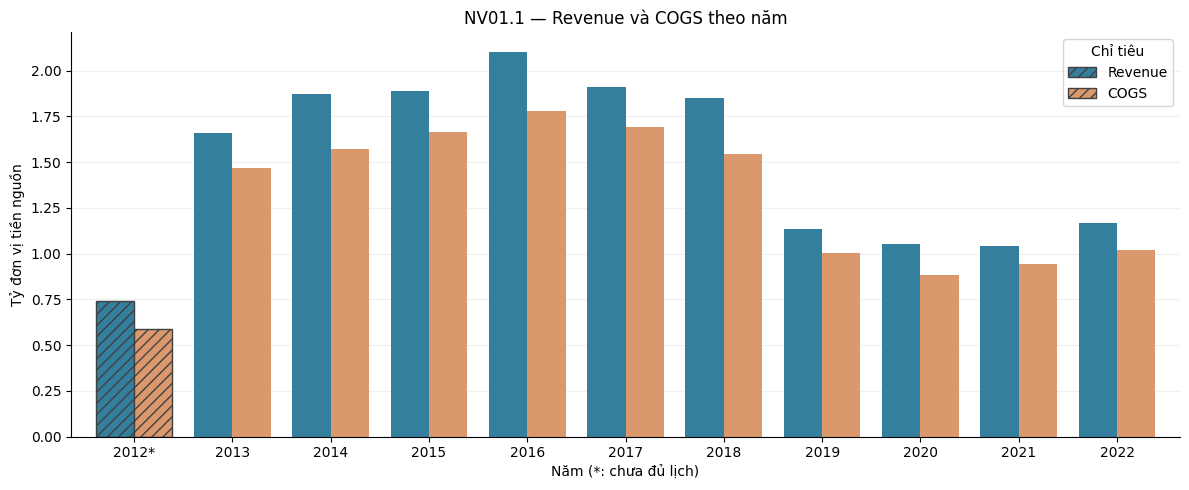

In [5]:
plot_money = annual[['revenue', 'cogs']].map(lambda value: float(value / Decimal('1000000000')))
plot_money.index = annual_display['Năm'].to_list()
fig, ax = plt.subplots(figsize=(12, 5))
plot_money.rename(columns={'revenue': 'Revenue', 'cogs': 'COGS'}).plot.bar(
    ax=ax, color=['#347f9e', '#db986d'], width=.78, rot=0)
for container in ax.containers:
    for bar, full_year in zip(container.patches, annual.full_year):
        if not full_year:
            bar.set_hatch('///')
            bar.set_edgecolor('#404040')
ax.set(title='NV01.1 — Revenue và COGS theo năm', xlabel='Năm (*: chưa đủ lịch)',
       ylabel='Tỷ đơn vị tiền nguồn')
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
ax.legend(title='Chỉ tiêu')
fig.tight_layout()
display(fig)
plt.close(fig)

In [6]:
full = annual.loc[annual.full_year].copy()
assert len(full) >= 2, 'Cần ít nhất hai năm đầy đủ để nhận xét xu hướng.'
first_year, last_year = int(full.index.min()), int(full.index.max())
peak_rev_year, low_rev_year = int(full.revenue.idxmax()), int(full.revenue.idxmin())
peak_cogs_year, low_cogs_year = int(full.cogs.idxmax()), int(full.cogs.idxmin())
full_period_change = safe_percent(full.at[last_year, 'revenue'] - full.at[first_year, 'revenue'],
                                  full.at[first_year, 'revenue'])
last_vs_peak = safe_percent(full.at[last_year, 'revenue'] - full.at[peak_rev_year, 'revenue'],
                            full.at[peak_rev_year, 'revenue'])
partial_years = coverage.loc[~coverage.full_year]
partial_details = '; '.join(f"{year}: {row.days} ngày, {row.first_date} đến {row.last_date}"
                            for year, row in partial_years.iterrows())

display(Markdown(f'''
**Số liệu quan sát từ bảng và biểu đồ:**

- Phần năm chưa đầy đủ: **{partial_details or 'không có'}**. Không quy đổi các tổng này thành cả năm.
- Trong các năm đầy đủ **{first_year}–{last_year}**, Revenue cao nhất ở **{peak_rev_year}**, đạt **{fmt_vi(full.at[peak_rev_year, 'revenue'])}**;
  thấp nhất ở **{low_rev_year}**, đạt **{fmt_vi(full.at[low_rev_year, 'revenue'])}** đơn vị nguồn.
- COGS cao nhất ở **{peak_cogs_year}**, đạt **{fmt_vi(full.at[peak_cogs_year, 'cogs'])}**;
  thấp nhất ở **{low_cogs_year}**, đạt **{fmt_vi(full.at[low_cogs_year, 'cogs'])}** đơn vị nguồn.
- Revenue năm cuối **{last_year}** chênh **{fmt_pct(full_period_change)}** so với năm đầy đủ đầu tiên **{first_year}**
  và chênh **{fmt_pct(last_vs_peak)}** so với đỉnh **{peak_rev_year}**. Đây là thay đổi hai mốc, **không phải CAGR**.

**Nhận xét có căn cứ:** tổng năm không tạo thành xu hướng tăng đều; năm đạt đỉnh và năm thấp nhất cho thấy cần đọc cả các giai đoạn tăng lẫn suy giảm.
Hai chỉ tiêu có thể cùng đạt đỉnh nhưng chạm mức thấp nhất ở những năm khác nhau, nên cần xem tiếp tốc độ biến động và tỷ lệ chênh lệch.
Nguồn hiện tại chưa cho phép quy các biến động này về sản lượng, giá, cơ cấu hàng hoặc chính sách giá vốn.
'''))


**Số liệu quan sát từ bảng và biểu đồ:**

- Phần năm chưa đầy đủ: **2012: 181 ngày, 2012-07-04 đến 2012-12-31**. Không quy đổi các tổng này thành cả năm.
- Trong các năm đầy đủ **2013–2022**, Revenue cao nhất ở **2016**, đạt **2.104.640.677,54**;
  thấp nhất ở **2021**, đạt **1.043.039.819,63** đơn vị nguồn.
- COGS cao nhất ở **2016**, đạt **1.780.559.392,69**;
  thấp nhất ở **2020**, đạt **886.085.097,63** đơn vị nguồn.
- Revenue năm cuối **2022** chênh **-29,41%** so với năm đầy đủ đầu tiên **2013**
  và chênh **-44,42%** so với đỉnh **2016**. Đây là thay đổi hai mốc, **không phải CAGR**.

**Nhận xét có căn cứ:** tổng năm không tạo thành xu hướng tăng đều; năm đạt đỉnh và năm thấp nhất cho thấy cần đọc cả các giai đoạn tăng lẫn suy giảm.
Hai chỉ tiêu có thể cùng đạt đỉnh nhưng chạm mức thấp nhất ở những năm khác nhau, nên cần xem tiếp tốc độ biến động và tỷ lệ chênh lệch.
Nguồn hiện tại chưa cho phép quy các biến động này về sản lượng, giá, cơ cấu hàng hoặc chính sách giá vốn.


### 5. Tăng trưởng qua năm và mối quan hệ hai chỉ tiêu

Chỉ vẽ các cặp năm có tăng trưởng được xác định cho cả hai chỉ tiêu. Không nối/xấp xỉ các năm không so sánh được và không biến giá trị trống thành 0%.
Cột dương là tăng, cột âm là giảm so với **năm liền trước**. Độ chênh giữa hai tỷ lệ tăng trưởng không phải tăng trưởng lợi nhuận.
Khi so hai tỷ lệ chênh lệch Revenue − COGS, lấy phép trừ trực tiếp để có **điểm phần trăm**, không gọi là phần trăm tăng trưởng.


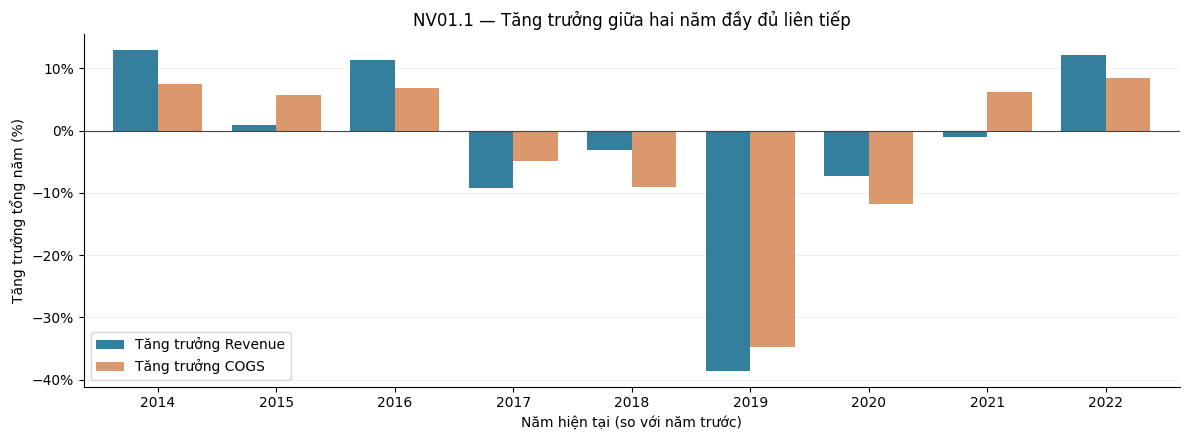

In [7]:
growth = annual.loc[annual.revenue_growth_pct.notna() & annual.cogs_growth_pct.notna()].copy()
assert not growth.empty, 'Không có cặp năm đủ điều kiện vẽ tăng trưởng.'
fig, ax = plt.subplots(figsize=(12, 4.5))
growth[['revenue_growth_pct', 'cogs_growth_pct']].map(float).rename(columns={
    'revenue_growth_pct': 'Tăng trưởng Revenue', 'cogs_growth_pct': 'Tăng trưởng COGS',
}).plot.bar(ax=ax, rot=0, color=['#347f9e', '#db986d'], width=.75)
from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.axhline(0, color='#454545', linewidth=.8)
ax.set(title='NV01.1 — Tăng trưởng giữa hai năm đầy đủ liên tiếp',
       xlabel='Năm hiện tại (so với năm trước)', ylabel='Tăng trưởng tổng năm (%)')
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

In [8]:
best_rev_year = int(growth.revenue_growth_pct.idxmax())
worst_rev_year = int(growth.revenue_growth_pct.idxmin())
best_cogs_year = int(growth.cogs_growth_pct.idxmax())
worst_cogs_year = int(growth.cogs_growth_pct.idxmin())
declining_revenue = growth.loc[growth.revenue_growth_pct.map(lambda value: value < ZERO)]
opposite = growth.loc[(growth.revenue_growth_pct * growth.cogs_growth_pct).map(lambda value: value < ZERO)]
same_direction = int((growth.revenue_growth_pct * growth.cogs_growth_pct).map(lambda value: value > ZERO).sum())
min_ratio_year = int(full.difference_pct.idxmin())
max_ratio_year = int(full.difference_pct.idxmax())
ratio_change_pp = {int(year): annual.at[year, 'difference_pct'] - annual.at[year - 1, 'difference_pct']
                   for year in growth.index
                   if annual.at[year, 'difference_pct'] is not None and annual.at[year - 1, 'difference_pct'] is not None}
max_contraction_year = min(ratio_change_pp, key=ratio_change_pp.get)
opposite_details = '\n'.join(
    f"- **{year}**: Revenue **{fmt_pct(row.revenue_growth_pct)}**, COGS **{fmt_pct(row.cogs_growth_pct)}**; "
    f"tỷ lệ chênh lệch là **{fmt_pct(row.difference_pct)}**."
    for year, row in opposite.iterrows()) or '- Không có cặp tăng trưởng trái dấu trong các năm đủ điều kiện.'

display(Markdown(f'''
**Số liệu quan sát và nhận xét có căn cứ:**

- Revenue tăng mạnh nhất trong các cặp đủ điều kiện ở **{best_rev_year}**: **{fmt_pct(growth.at[best_rev_year, 'revenue_growth_pct'])}**;
  giảm mạnh nhất ở **{worst_rev_year}**: **{fmt_pct(growth.at[worst_rev_year, 'revenue_growth_pct'])}**.
- COGS tăng mạnh nhất ở **{best_cogs_year}**: **{fmt_pct(growth.at[best_cogs_year, 'cogs_growth_pct'])}**;
  giảm mạnh nhất ở **{worst_cogs_year}**: **{fmt_pct(growth.at[worst_cogs_year, 'cogs_growth_pct'])}**.
- Các năm Revenue giảm so với năm trước: **{', '.join(map(str, declining_revenue.index)) or 'không có'}**.
  Năm cuối **{last_year}** có tăng trưởng Revenue **{fmt_pct(growth.at[last_year, 'revenue_growth_pct'])}** và COGS **{fmt_pct(growth.at[last_year, 'cogs_growth_pct'])}**.
- Hai chỉ tiêu tăng/giảm **cùng hướng ở {same_direction}/{len(growth)} cặp năm** đủ điều kiện; đây là mô tả dấu biến động, không chứng minh quan hệ nhân quả.
  Những năm biến động trái dấu:

{opposite_details}

- Trong các năm đầy đủ, tỷ lệ chênh lệch cao nhất ở **{max_ratio_year}** (**{fmt_pct(full.at[max_ratio_year, 'difference_pct'])}**)
  và thấp nhất ở **{min_ratio_year}** (**{fmt_pct(full.at[min_ratio_year, 'difference_pct'])}**).
  Mức thu hẹp mạnh nhất giữa hai năm đầy đủ là **{max_contraction_year}**:
  **{fmt_vi(ratio_change_pp[max_contraction_year])} điểm phần trăm**, từ **{fmt_pct(annual.at[max_contraction_year - 1, 'difference_pct'])}**
  xuống **{fmt_pct(annual.at[max_contraction_year, 'difference_pct'])}**.

**Ý nghĩa nghiệp vụ trong phạm vi dữ liệu:** cùng hướng không đồng nghĩa cùng tốc độ; COGS tăng khi Revenue giảm là một tín hiệu cần đối soát,
đặc biệt khi tỷ lệ chênh lệch thu hẹp. Tuy nhiên, chỉ tiêu chưa trừ đầy đủ giảm giá/hoàn tiền và các khoản chi phí khác nên không đánh giá được lợi nhuận thực tế.
'''))


**Số liệu quan sát và nhận xét có căn cứ:**

- Revenue tăng mạnh nhất trong các cặp đủ điều kiện ở **2014**: **12,95%**;
  giảm mạnh nhất ở **2019**: **-38,56%**.
- COGS tăng mạnh nhất ở **2022**: **8,42%**;
  giảm mạnh nhất ở **2019**: **-34,82%**.
- Các năm Revenue giảm so với năm trước: **2017, 2018, 2019, 2020, 2021**.
  Năm cuối **2022** có tăng trưởng Revenue **12,15%** và COGS **8,42%**.
- Hai chỉ tiêu tăng/giảm **cùng hướng ở 8/9 cặp năm** đủ điều kiện; đây là mô tả dấu biến động, không chứng minh quan hệ nhân quả.
  Những năm biến động trái dấu:

- **2021**: Revenue **-1,09%**, COGS **6,21%**; tỷ lệ chênh lệch là **9,77%**.

- Trong các năm đầy đủ, tỷ lệ chênh lệch cao nhất ở **2018** (**16,64%**)
  và thấp nhất ở **2021** (**9,77%**).
  Mức thu hẹp mạnh nhất giữa hai năm đầy đủ là **2021**:
  **-6,20 điểm phần trăm**, từ **15,97%**
  xuống **9,77%**.

**Ý nghĩa nghiệp vụ trong phạm vi dữ liệu:** cùng hướng không đồng nghĩa cùng tốc độ; COGS tăng khi Revenue giảm là một tín hiệu cần đối soát,
đặc biệt khi tỷ lệ chênh lệch thu hẹp. Tuy nhiên, chỉ tiêu chưa trừ đầy đủ giảm giá/hoàn tiền và các khoản chi phí khác nên không đánh giá được lợi nhuận thực tế.


### 6. Dấu hiệu cần khảo sát sâu và giả thuyết chưa kiểm chứng

Các câu hỏi dưới đây xuất phát từ những năm đã được code xác định ở trên; **chưa triển khai phân tích để trả lời trong NV01.1**:

- Mức giảm đồng thời của Revenue và COGS đến từ số lượng, mức giá, cơ cấu hàng hay thay đổi phạm vi ghi nhận?
- Khi hai chỉ tiêu biến động trái dấu, giá vốn cung cấp, cơ cấu sản phẩm hoặc cách ghi nhận có thay đổi không?
- Sự thu hẹp tỷ lệ chênh lệch còn tồn tại khi đối soát giảm giá, hoàn tiền và trạng thái đơn theo chính sách được xác nhận không?
- Thay đổi tổng năm có chịu ảnh hưởng bởi số ngày năm nhuận hoặc các biến động tập trung trong một phần năm không?

Đây là **hướng kiểm tra/giả thuyết**, chưa phải nguyên nhân đã được chứng minh. Không gán các biến động cho chiến dịch, nhu cầu, dịch bệnh,
hiệu quả vận hành hay sự kiện bên ngoài khi chưa có dữ liệu chứng minh. Các tổng là giá trị danh nghĩa, chưa điều chỉnh lạm phát hoặc giá.


### 7. Kiểm chứng kết quả NV01.1

Đối chiếu tổng Revenue với `V02.metrics.sales_revenue`, COGS với `V02.metrics.sales_cogs`, số ngày với `V02.metrics.sales_days`.
Dùng **tổng COGS của chính sales**, phân biệt với `V02.metrics.cogs` tính từ chi tiết theo giá vốn chưa làm tròn.
Mục này yêu cầu khớp **chính xác Decimal** với tổng sales tính từ CSV bằng hàm V02, không nới dung sai tiền 0,05 để bỏ qua sai lệch tổng hợp.

Đọc lại CSV bằng `csv.DictReader` và cộng bằng từ điển/Decimal để kiểm tra độc lập tổng năm, số ngày, chênh lệch, tỷ lệ và điều kiện tăng trưởng.
Kiểm tra mẫu số 0/NULL; đảm bảo năm chưa đủ lịch và năm kế tiếp không có tăng trưởng so sánh sai.
Kiểm tra SHA-256 cuối phiên bao gồm notebook, CSV gốc và file hàm.
Đây là tái lập phân tích năm và đối chiếu V02 hiện có, không chạy lại toàn bộ audit liên bảng V02.


In [9]:
from datetime import date

verification = []
def check(name, condition):
    condition = bool(condition)
    verification.append({'Kiểm tra': name, 'Đạt': condition})
    assert condition, name

from ham_dung_chung import foundation
gd2_exact_sum = foundation().exact_sum
total_revenue = gd2_exact_sum(sales.Revenue)
total_cogs = gd2_exact_sum(sales.COGS)
check('Tổng Revenue khớp V02.sales_revenue chính xác', total_revenue == v02['metrics']['sales_revenue'])
check('Tổng COGS khớp V02.sales_cogs chính xác', total_cogs == v02['metrics']['sales_cogs'])
check('Số ngày khớp V02.sales_days', len(sales) == v02['metrics']['sales_days'])
check('Tổng ngày theo năm bằng số dòng/ngày toàn kỳ', int(annual.days.sum()) == len(sales))
check('Lịch trong khoảng min–max đầy đủ', len(observed_calendar) == len(sales) and len(missing_within_range) == 0)
check('Cộng Revenue năm bằng toàn kỳ', sum(annual.revenue, ZERO) == total_revenue)
check('Cộng COGS năm bằng toàn kỳ', sum(annual.cogs, ZERO) == total_cogs)
check('Cộng chênh lệch năm bằng chênh lệch toàn kỳ',
      sum(annual.difference, ZERO) == total_revenue - total_cogs)

oracle = defaultdict(lambda: {'dates': set(), 'revenue': ZERO, 'cogs': ZERO})
with SALES_PATH.open(encoding='utf-8-sig', newline='') as stream:
    reader = csv.DictReader(stream, strict=True)
    for row in reader:
        day = date.fromisoformat(row['Date'])
        record = oracle[day.year]
        record['dates'].add(day)
        record['revenue'] += Decimal(row['Revenue'])
        record['cogs'] += Decimal(row['COGS'])
check('Tập năm khớp lượt đọc CSV độc lập', set(annual.index) == set(oracle))

annual_values_match = True
annual_formulas_match = True
growth_formulas_match = True
for year, observed in annual.iterrows():
    independent = oracle[int(year)]
    rev, cog = independent['revenue'], independent['cogs']
    whole_year = len(independent['dates']) == 365 + int(calendar.isleap(int(year)))
    annual_values_match &= (observed.days == len(independent['dates'])
                            and observed.revenue == rev and observed.cogs == cog
                            and bool(observed.full_year) == whole_year)
    expected_ratio = (rev - cog) / rev * HUNDRED if rev != ZERO else None
    annual_formulas_match &= observed.difference == rev - cog and observed.difference_pct == expected_ratio
    previous = oracle.get(int(year) - 1)
    previous_full = bool(previous is not None and
                         len(previous['dates']) == 365 + int(calendar.isleap(int(year) - 1)))
    for column, growth_column in [('revenue', 'revenue_growth_pct'), ('cogs', 'cogs_growth_pct')]:
        expected = None
        if whole_year and previous_full and previous[column] != ZERO:
            expected = (independent[column] - previous[column]) / previous[column] * HUNDRED
        growth_formulas_match &= observed[growth_column] == expected
check('Mọi tổng năm, số ngày và độ đầy đủ khớp CSV độc lập', annual_values_match)
check('Mọi công thức chênh lệch/tỷ lệ khớp CSV độc lập', annual_formulas_match)
check('Mọi công thức tăng trưởng/điều kiện so sánh khớp CSV độc lập', growth_formulas_match)
check('2012 chưa đủ năm; không tính tăng trưởng 2013 trên nền 2012',
      not annual.at[2012, 'full_year']
      and annual.at[2013, 'revenue_growth_pct'] is None
      and annual.at[2013, 'cogs_growth_pct'] is None)
check('Chia cho 0 hoặc đầu vào NULL trả về chưa xác định',
      safe_percent(Decimal(1), ZERO) is None and safe_percent(ZERO, ZERO) is None
      and safe_percent(None, Decimal(1)) is None and safe_percent(Decimal(1), None) is None)
check('Tử số 0 và phép chia hợp lệ được tính đúng',
      safe_percent(ZERO, Decimal(10)) == ZERO and safe_percent(Decimal(1), Decimal(4)) == Decimal(25))
protected_after = protected_snapshot()
check('SHA-256 mọi file bảo toàn trước/sau không đổi', protected_after == protected_before)

comparison = pd.DataFrame([
    {'Chỉ tiêu': 'Revenue toàn kỳ', 'Tính từ sales.csv': fmt_vi(total_revenue),
     'V02 chính thức': fmt_vi(v02['metrics']['sales_revenue']),
     'Sai lệch': fmt_vi(total_revenue - v02['metrics']['sales_revenue'])},
    {'Chỉ tiêu': 'COGS toàn kỳ', 'Tính từ sales.csv': fmt_vi(total_cogs),
     'V02 chính thức': fmt_vi(v02['metrics']['sales_cogs']),
     'Sai lệch': fmt_vi(total_cogs - v02['metrics']['sales_cogs'])},
    {'Chỉ tiêu': 'Số ngày toàn kỳ', 'Tính từ sales.csv': str(len(sales)),
     'V02 chính thức': str(v02['metrics']['sales_days']),
     'Sai lệch': str(len(sales) - v02['metrics']['sales_days'])},
])
display(comparison)
display(pd.DataFrame(verification))

,Chỉ tiêu,Tính từ sales.csv,V02 chính thức,Sai lệch
0,Revenue toàn kỳ,"16.430.476.585,53","16.430.476.585,53","0,00"
1,COGS toàn kỳ,"14.163.450.519,17","14.163.450.519,17","0,00"
2,Số ngày toàn kỳ,3833,3833,0


,Kiểm tra,Đạt
0,Tổng Revenue khớp V02.sales_revenue chính xác,True
1,Tổng COGS khớp V02.sales_cogs chính xác,True
2,Số ngày khớp V02.sales_days,True
3,Tổng ngày theo năm bằng số dòng/ngày toàn kỳ,True
4,Lịch trong khoảng min–max đầy đủ,True
...,...,...
11,Mọi công thức tăng trưởng/điều kiện so sánh kh...,True
12,2012 chưa đủ năm; không tính tăng trưởng 2013 ...,True
13,Chia cho 0 hoặc đầu vào NULL trả về chưa xác định,True
14,Tử số 0 và phép chia hợp lệ được tính đúng,True


In [10]:
assert all(item['Đạt'] for item in verification)
display(Markdown(f'''
**Kết quả thực thi NV01.1:** đã tổng hợp **{len(annual)} năm**, gồm **{int(annual.full_year.sum())} năm đầy đủ**;
**{len(sales):,} ngày**, tổng ngày theo năm **{int(annual.days.sum()):,}**.
Tổng Revenue **{fmt_vi(total_revenue)}**, tổng COGS **{fmt_vi(total_cogs)}** và chênh lệch toàn kỳ
**{fmt_vi(total_revenue - total_cogs)}** đơn vị nguồn. Revenue và COGS khớp V02 với sai lệch bằng 0.
**{len(verification)}/{len(verification)} nhóm kiểm tra đạt**; **{len(protected_after)} file hiện có** giữ nguyên SHA-256.
Các nhận xét ở trên được sinh từ `annual` sau khi tính từ CSV, không lấy các tổng năm từ báo cáo có sẵn.
'''))


**Kết quả thực thi NV01.1:** đã tổng hợp **11 năm**, gồm **10 năm đầy đủ**;
**3,833 ngày**, tổng ngày theo năm **3,833**.
Tổng Revenue **16.430.476.585,53**, tổng COGS **14.163.450.519,17** và chênh lệch toàn kỳ
**2.267.026.066,36** đơn vị nguồn. Revenue và COGS khớp V02 với sai lệch bằng 0.
**16/16 nhóm kiểm tra đạt**; **32 file hiện có** giữ nguyên SHA-256.
Các nhận xét ở trên được sinh từ `annual` sau khi tính từ CSV, không lấy các tổng năm từ báo cáo có sẵn.


### Giới hạn và trạng thái bàn giao

- Đã có bảng đủ các chỉ tiêu NV01.1, biểu đồ tổng năm, biểu đồ tăng trưởng và nhận xét phân biệt quan sát với giả thuyết.
- Năm biên chưa đủ lịch vẫn có tổng và tỷ lệ chênh lệch quan sát, nhưng tăng trưởng liên quan không được tính như hai năm đầy đủ.
- Tăng trưởng theo tổng năm chưa chuẩn hóa năm nhuận, mùa vụ hoặc sức mua; chưa phân rã sản lượng/giá/cơ cấu và chưa suy diễn nguyên nhân.
- Chênh lệch Revenue − COGS chưa xác nhận lợi nhuận thực tế. Chính sách kế toán, loại tiền, giá vốn lịch sử và cách xử lý trạng thái/giảm giá/hoàn tiền vẫn cần xác minh như V02.
- Chỉ hoàn thành **NV01.1**. Chưa triển khai NV01.2–NV01.5, chưa tạo mô hình hoặc báo cáo phụ.

Các kết quả nhúng là kết quả lần chạy đã lưu. Muốn tái lập, dùng kernel mới và **Run All**; notebook sẽ dừng nếu nguồn khác SHA-256 V02 hoặc kiểm tra tính hợp lệ không đạt.


## NV01.2 — Phân tích doanh thu và giá vốn theo tháng

**Phạm vi bổ sung:** chỉ NV01.2, dùng `data/raw/sales.csv`; kế thừa dữ liệu, Decimal và định nghĩa từ NV01.1. Phần trên giữ nguyên như bản bàn giao NV01.1; các dòng “chưa triển khai NV01.2” ở phần đó mô tả trạng thái trước lần bổ sung này. Chưa triển khai NV01.3–NV01.5.

**Câu hỏi:** Revenue và COGS thay đổi ra sao qua tháng? Tháng nào cao/thấp hoặc tăng/giảm mạnh? Suy giảm 2019 tập trung hay kéo dài? Có dấu hiệu khác biệt giữa các tháng trong năm? Chênh lệch Revenue − COGS thay đổi thế nào?

Chỉ hiển thị thống kê tháng. Tiền dùng **đơn vị nguồn chưa xác minh loại tiền**; bảng dùng **triệu đơn vị nguồn**, biểu đồ ghi đơn vị trên trục. `.` tách nghìn, `,` tách thập phân; `—` là chưa xác định, không phải 0. Chênh lệch chưa được xác nhận là lợi nhuận thực tế.

### 1. Công thức và điều kiện so sánh

Với tập ngày quan sát $D_m$ của tháng lịch $m$ (`YYYY-MM`):

$$N_m=|D_m|,\quad R_m=\sum_{d\in D_m}Revenue_d,\quad C_m=\sum_{d\in D_m}COGS_d,$$
$$S_m=R_m-C_m,\quad s_m=100\frac{S_m}{R_m},\quad \bar R_m=R_m/N_m,\quad \bar C_m=C_m/N_m.$$

**MoM** (month over month) so với tháng lịch liền trước; **YoY** (year over year) so với cùng tháng năm trước. Với $X$ là Revenue hoặc COGS:

$$MoM_m(X)=100\frac{X_m-X_{m-1}}{X_{m-1}},\qquad YoY_m(X)=100\frac{X_m-X_{m-12}}{X_{m-12}}.$$

- Chỉ tính khi **cả hai tháng đủ mọi ngày lịch**, có đúng kỳ đối chiếu và mẫu số khác 0; nếu không, để trống riêng cho từng chỉ tiêu. Không dùng tháng gần nhất thay tháng thiếu, không điền trống thành 0%.
- **07/2012 chỉ có 04–31/07 (28/31 ngày)**: báo tổng và bình quân trên 28 ngày quan sát, không ngoại suy. MoM 07/2012 và 08/2012, YoY 07/2013 để trống. Không dùng bình quân ngày để tự hợp thức hóa so sánh với tháng chưa đủ lịch.
- Hai tháng đủ lịch vẫn có thể dài 28/29/30/31 ngày. Tăng trưởng **tổng tháng** đo thay đổi tổng thực tế, chưa loại ảnh hưởng số ngày. Tính thêm MoM/YoY **bình quân ngày**, thay $X$ bằng $\bar X$. Tháng 02 năm nhuận đủ 29 ngày được so với tháng 02 đủ 28 ngày nhưng phải đọc cả tổng lẫn bình quân ngày.
- Tỷ lệ chênh lệch trống nếu Revenue = 0; bình quân ngày trống nếu không có ngày. Chênh giữa hai tỷ lệ dùng **điểm phần trăm**. Tỷ lệ cả năm tính từ tổng tiền, không lấy trung bình đơn giản tỷ lệ tháng.

In [11]:
# Bảng riêng; không thay đổi sales/annual/coverage của NV01.1.
monthly = sales.groupby(sales.Date.dt.to_period('M'), sort=True).agg(
    first_date=('Date', 'min'), last_date=('Date', 'max'), days=('Date', 'nunique'),
    revenue=('Revenue', 'sum'), cogs=('COGS', 'sum'))
monthly.index.name = 'month'
monthly['calendar_days'] = monthly.index.days_in_month
monthly['full_month'] = [
    int(r.days) == m.days_in_month and r.first_date == m.start_time
    and r.last_date == m.end_time.normalize() for m, r in monthly.iterrows()]
monthly['difference'] = monthly.revenue - monthly.cogs
monthly['difference_pct'] = pd.Series(
    [safe_percent(r.difference, r.revenue) for r in monthly.itertuples()], index=monthly.index, dtype=object)
for metric in ['revenue', 'cogs']:
    monthly[metric + '_daily'] = pd.Series(
        [r[metric] / Decimal(int(r.days)) if r.days else None for _, r in monthly.iterrows()],
        index=monthly.index, dtype=object)

def monthly_comparison(frame, month, lag, metric):
    previous = month - lag
    if previous not in frame.index:
        return None, 'Không có kỳ đối chiếu'
    if not bool(frame.at[month, 'full_month']) or not bool(frame.at[previous, 'full_month']):
        return None, 'Có tháng chưa đủ lịch'
    current, base = frame.at[month, metric], frame.at[previous, metric]
    if current is None or base is None or pd.isna(current) or pd.isna(base):
        return None, 'Chỉ tiêu chưa xác định'
    if base == ZERO:
        return None, 'Mẫu số bằng 0'
    return safe_percent(current - base, base), 'Hai tháng đủ lịch'

for label, lag in [('mom', 1), ('yoy', 12)]:
    for metric in ['revenue', 'cogs', 'revenue_daily', 'cogs_daily']:
        pairs = [monthly_comparison(monthly, m, lag, metric) for m in monthly.index]
        monthly[f'{metric}_{label}_pct'] = pd.Series([v for v, _ in pairs], index=monthly.index, dtype=object)
        monthly[f'{metric}_{label}_reason'] = [reason for _, reason in pairs]

MILLION = Decimal('1000000')
def fmt_million(value):
    return '—' if value is None or pd.isna(value) else fmt_vi(value / MILLION)

def month_table(frame, growth=True, daily_growth=False):
    out = pd.DataFrame(index=frame.index.astype(str))
    out.index.name = 'Tháng'
    out['Ngày QS/lịch'] = [f'{r.days}/{r.calendar_days}' for r in frame.itertuples()]
    for field, title in [('revenue', 'Revenue'), ('cogs', 'COGS'), ('difference', 'R − C'),
                         ('revenue_daily', 'R/ngày'), ('cogs_daily', 'C/ngày')]:
        out[title] = frame[field].map(fmt_million).to_list()
    out['(R − C)/R'] = frame.difference_pct.map(fmt_pct).to_list()
    if growth:
        for label in ['mom', 'yoy']:
            for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
                out[f'{title} {label.upper()}'] = frame[f'{metric}_{label}_pct'].map(fmt_pct).to_list()
    if daily_growth:
        for label in ['mom', 'yoy']:
            for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
                out[f'{title}/ngày {label.upper()}'] = frame[f'{metric}_daily_{label}_pct'].map(fmt_pct).to_list()
    return out

partial_months = monthly.loc[~monthly.full_month]
display(Markdown(f'**{len(monthly)} tháng**, **{monthly.index.min()}–{monthly.index.max()}**; '
                 f'**{int(monthly.full_month.sum())} tháng đủ lịch**, **{int(monthly.days.sum()):,} ngày**.'))
display(partial_months[['first_date', 'last_date', 'days', 'calendar_days']].rename(columns={
    'first_date': 'Ngày đầu', 'last_date': 'Ngày cuối', 'days': 'Ngày quan sát', 'calendar_days': 'Ngày lịch'}))

**126 tháng**, **2012-07–2022-12**; **125 tháng đủ lịch**, **3,833 ngày**.

,Ngày đầu,Ngày cuối,Ngày quan sát,Ngày lịch
month,,,,
2012-07,2012-07-04,2012-07-31,28,31


### 2. Bảng tổng hợp tháng

Hiển thị **tất cả các tháng**, chia theo năm để tránh rút gọn bảng dài. Tiền và tiền/ngày theo **triệu đơn vị nguồn**. Bảng đầu có tăng trưởng **tổng tháng**, bảng sau có tăng trưởng **bình quân ngày**. Mọi phép tính dùng Decimal chưa làm tròn.

In [12]:
for year in sorted(set(monthly.index.year)):
    display(Markdown(f'**Năm {year} — tổng tháng, triệu đơn vị nguồn**'))
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(month_table(monthly.loc[monthly.index.year == year]))

**Năm 2012 — tổng tháng, triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2012-07,28/31,"130,41","102,52","27,89","4,66","3,66","21,39%",—,—,—,—
2012-08,31/31,"159,09","125,59","33,50","5,13","4,05","21,06%",—,—,—,—
2012-09,30/30,"129,31","102,60","26,71","4,31","3,42","20,66%","-18,72%","-18,31%",—,—
2012-10,31/31,"110,19","88,05","22,13","3,55","2,84","20,09%","-14,79%","-14,17%",—,—
2012-11,30/30,"98,19","77,82","20,37","3,27","2,59","20,74%","-10,89%","-11,62%",—,—
2012-12,31/31,"114,32","90,89","23,43","3,69","2,93","20,50%","16,43%","16,79%",—,—


**Năm 2013 — tổng tháng, triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2013-01,31/31,"91,31","73,02","18,28","2,95","2,36","20,03%","-20,13%","-19,66%",—,—
2013-02,28/28,"109,78","90,29","19,50","3,92","3,22","17,76%","20,23%","23,64%",—,—
2013-03,31/31,"151,83","129,90","21,94","4,90","4,19","14,45%","38,30%","43,87%",—,—
2013-04,30/30,"198,93","165,58","33,34","6,63","5,52","16,76%","31,02%","27,47%",—,—
2013-05,31/31,"200,50","159,76","40,74","6,47","5,15","20,32%","0,79%","-3,52%",—,—
2013-06,30/30,"198,52","166,30","32,22","6,62","5,54","16,23%","-0,99%","4,10%",—,—
2013-07,31/31,"165,75","153,04","12,70","5,35","4,94","7,66%","-16,51%","-7,97%",—,—
2013-08,31/31,"116,27","151,95","-35,68","3,75","4,90","-30,68%","-29,85%","-0,72%","-26,91%","20,99%"
2013-09,30/30,"127,53","116,16","11,37","4,25","3,87","8,92%","9,69%","-23,55%","-1,37%","13,22%"


**Năm 2014 — tổng tháng, triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2014-01,31/31,"91,80","74,82","16,99","2,96","2,41","18,50%","0,57%","-17,03%","0,54%","2,46%"
2014-02,28/28,"108,44","86,26","22,18","3,87","3,08","20,45%","18,12%","15,30%","-1,22%","-4,46%"
2014-03,31/31,"183,51","157,17","26,34","5,92","5,07","14,35%","69,23%","82,20%","20,86%","21,00%"
2014-04,30/30,"232,57","196,88","35,68","7,75","6,56","15,34%","26,73%","25,27%","16,91%","18,90%"
2014-05,31/31,"244,31","195,19","49,12","7,88","6,30","20,10%","5,05%","-0,86%","21,85%","22,18%"
2014-06,30/30,"208,13","174,11","34,03","6,94","5,80","16,35%","-14,81%","-10,80%","4,84%","4,69%"
2014-07,31/31,"169,16","151,25","17,91","5,46","4,88","10,59%","-18,73%","-13,13%","2,06%","-1,17%"
2014-08,31/31,"195,27","154,96","40,31","6,30","5,00","20,64%","15,43%","2,45%","67,94%","1,98%"
2014-09,30/30,"120,62","105,17","15,45","4,02","3,51","12,81%","-38,23%","-32,13%","-5,42%","-9,46%"


... (12 outputs left out)

**Năm 2021 — tổng tháng, triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2021-01,31/31,"46,47","37,11","9,37","1,50","1,20","20,16%","6,41%","-14,18%","-2,63%","-2,33%"
2021-02,28/28,"66,08","53,56","12,52","2,36","1,91","18,95%","42,18%","44,34%","5,81%","7,50%"
2021-03,31/31,"113,27","97,23","16,05","3,65","3,14","14,17%","71,43%","81,54%","1,31%","1,93%"
2021-04,30/30,"134,84","115,52","19,32","4,49","3,85","14,33%","19,04%","18,81%","-3,66%","-1,93%"
2021-05,31/31,"143,07","116,34","26,73","4,62","3,75","18,68%","6,11%","0,71%","7,71%","10,20%"
2021-06,30/30,"128,45","108,27","20,18","4,28","3,61","15,71%","-10,22%","-6,94%","16,13%","17,02%"
2021-07,31/31,"101,00","94,46","6,54","3,26","3,05","6,48%","-21,37%","-12,75%","11,36%","16,17%"
2021-08,31/31,"68,28","95,65","-27,37","2,20","3,09","-40,09%","-32,40%","1,26%","-44,06%","-2,44%"
2021-09,30/30,"74,84","70,89","3,95","2,49","2,36","5,27%","9,61%","-25,88%","-5,05%","1,22%"


**Năm 2022 — tổng tháng, triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2022-01,31/31,"59,66","50,85","8,81","1,92","1,64","14,77%","18,37%","-1,16%","28,38%","37,04%"
2022-02,28/28,"79,10","65,29","13,82","2,83","2,33","17,47%","32,58%","28,38%","19,71%","21,90%"
2022-03,31/31,"137,54","121,67","15,87","4,44","3,92","11,54%","73,87%","86,36%","21,42%","25,14%"
2022-04,30/30,"141,31","124,36","16,94","4,71","4,15","11,99%","2,74%","2,21%","4,80%","7,66%"
2022-05,31/31,"139,03","113,95","25,08","4,48","3,68","18,04%","-1,61%","-8,37%","-2,83%","-2,05%"
2022-06,30/30,"135,81","117,71","18,10","4,53","3,92","13,33%","-2,31%","3,30%","5,73%","8,72%"
2022-07,31/31,"98,14","91,61","6,54","3,17","2,96","6,66%","-27,74%","-22,18%","-2,83%","-3,02%"
2022-08,31/31,"113,54","94,03","19,51","3,66","3,03","17,18%","15,69%","2,65%","66,29%","-1,69%"
2022-09,30/30,"85,76","78,40","7,37","2,86","2,61","8,59%","-24,47%","-16,63%","14,59%","10,58%"


In [13]:
for year in sorted(set(monthly.index.year)):
    frame = monthly.loc[monthly.index.year == year]
    out = month_table(frame, growth=False, daily_growth=True)
    out = out.drop(columns=['Revenue', 'COGS', 'R − C', '(R − C)/R'])
    display(Markdown(f'**Năm {year} — bình quân ngày (triệu đơn vị nguồn/ngày) và tăng trưởng**'))
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(out)
exceptions = monthly.loc[monthly.revenue_mom_pct.isna() | monthly.revenue_yoy_pct.isna()]
display(Markdown('**Kỳ chưa đủ điều kiện tăng trưởng Revenue** (COGS có cùng phạm vi trong nguồn này):'))
with pd.option_context('display.max_rows', None):
    display(exceptions[['revenue_mom_reason', 'revenue_yoy_reason']].rename(columns={
        'revenue_mom_reason': 'MoM', 'revenue_yoy_reason': 'YoY'}))

**Năm 2012 — bình quân ngày (triệu đơn vị nguồn/ngày) và tăng trưởng**

,Ngày QS/lịch,R/ngày,C/ngày,R/ngày MOM,C/ngày MOM,R/ngày YOY,C/ngày YOY
Tháng,,,,,,,
2012-07,28/31,"4,66","3,66",—,—,—,—
2012-08,31/31,"5,13","4,05",—,—,—,—
2012-09,30/30,"4,31","3,42","-16,01%","-15,58%",—,—
2012-10,31/31,"3,55","2,84","-17,54%","-16,94%",—,—
2012-11,30/30,"3,27","2,59","-7,92%","-8,68%",—,—
2012-12,31/31,"3,69","2,93","12,68%","13,03%",—,—


**Năm 2013 — bình quân ngày (triệu đơn vị nguồn/ngày) và tăng trưởng**

,Ngày QS/lịch,R/ngày,C/ngày,R/ngày MOM,C/ngày MOM,R/ngày YOY,C/ngày YOY
Tháng,,,,,,,
2013-01,31/31,"2,95","2,36","-20,13%","-19,66%",—,—
2013-02,28/28,"3,92","3,22","33,12%","36,89%",—,—
2013-03,31/31,"4,90","4,19","24,92%","29,95%",—,—
2013-04,30/30,"6,63","5,52","35,38%","31,72%",—,—
2013-05,31/31,"6,47","5,15","-2,46%","-6,63%",—,—
2013-06,30/30,"6,62","5,54","2,31%","7,57%",—,—
2013-07,31/31,"5,35","4,94","-19,20%","-10,94%",—,—
2013-08,31/31,"3,75","4,90","-29,85%","-0,72%","-26,91%","20,99%"
2013-09,30/30,"4,25","3,87","13,34%","-21,00%","-1,37%","13,22%"


**Năm 2014 — bình quân ngày (triệu đơn vị nguồn/ngày) và tăng trưởng**

,Ngày QS/lịch,R/ngày,C/ngày,R/ngày MOM,C/ngày MOM,R/ngày YOY,C/ngày YOY
Tháng,,,,,,,
2014-01,31/31,"2,96","2,41","0,57%","-17,03%","0,54%","2,46%"
2014-02,28/28,"3,87","3,08","30,78%","27,65%","-1,22%","-4,46%"
2014-03,31/31,"5,92","5,07","52,85%","64,57%","20,86%","21,00%"
2014-04,30/30,"7,75","6,56","30,95%","29,44%","16,91%","18,90%"
2014-05,31/31,"7,88","6,30","1,66%","-4,06%","21,85%","22,18%"
2014-06,30/30,"6,94","5,80","-11,97%","-7,83%","4,84%","4,69%"
2014-07,31/31,"5,46","4,88","-21,35%","-15,93%","2,06%","-1,17%"
2014-08,31/31,"6,30","5,00","15,43%","2,45%","67,94%","1,98%"
2014-09,30/30,"4,02","3,51","-36,17%","-29,87%","-5,42%","-9,46%"


... (14 outputs left out)

**Năm 2022 — bình quân ngày (triệu đơn vị nguồn/ngày) và tăng trưởng**

,Ngày QS/lịch,R/ngày,C/ngày,R/ngày MOM,C/ngày MOM,R/ngày YOY,C/ngày YOY
Tháng,,,,,,,
2022-01,31/31,"1,92","1,64","18,37%","-1,16%","28,38%","37,04%"
2022-02,28/28,"2,83","2,33","46,79%","42,14%","19,71%","21,90%"
2022-03,31/31,"4,44","3,92","57,05%","68,33%","21,42%","25,14%"
2022-04,30/30,"4,71","4,15","6,16%","5,62%","4,80%","7,66%"
2022-05,31/31,"4,48","3,68","-4,79%","-11,33%","-2,83%","-2,05%"
2022-06,30/30,"4,53","3,92","0,94%","6,74%","5,73%","8,72%"
2022-07,31/31,"3,17","2,96","-30,07%","-24,69%","-2,83%","-3,02%"
2022-08,31/31,"3,66","3,03","15,69%","2,65%","66,29%","-1,69%"
2022-09,30/30,"2,86","2,61","-21,95%","-13,85%","14,59%","10,58%"


**Kỳ chưa đủ điều kiện tăng trưởng Revenue** (COGS có cùng phạm vi trong nguồn này):

,MoM,YoY
month,,
2012-07,Không có kỳ đối chiếu,Không có kỳ đối chiếu
2012-08,Có tháng chưa đủ lịch,Không có kỳ đối chiếu
2012-09,Hai tháng đủ lịch,Không có kỳ đối chiếu
2012-10,Hai tháng đủ lịch,Không có kỳ đối chiếu
2012-11,Hai tháng đủ lịch,Không có kỳ đối chiếu
2012-12,Hai tháng đủ lịch,Không có kỳ đối chiếu
2013-01,Hai tháng đủ lịch,Không có kỳ đối chiếu
2013-02,Hai tháng đủ lịch,Không có kỳ đối chiếu
2013-03,Hai tháng đủ lịch,Không có kỳ đối chiếu


### 3. Revenue, COGS và tăng trưởng theo thời gian

Dấu rỗng ở 07/2012 chỉ tháng có 28/31 ngày. Đường tổng giữ số quan sát thực tế. Bình quân ngày giúp đọc ảnh hưởng số ngày, chưa điều chỉnh cơ cấu thứ trong tuần, xu hướng hay giá. Khoảng trống tăng trưởng được giữ là NaN khi vẽ.

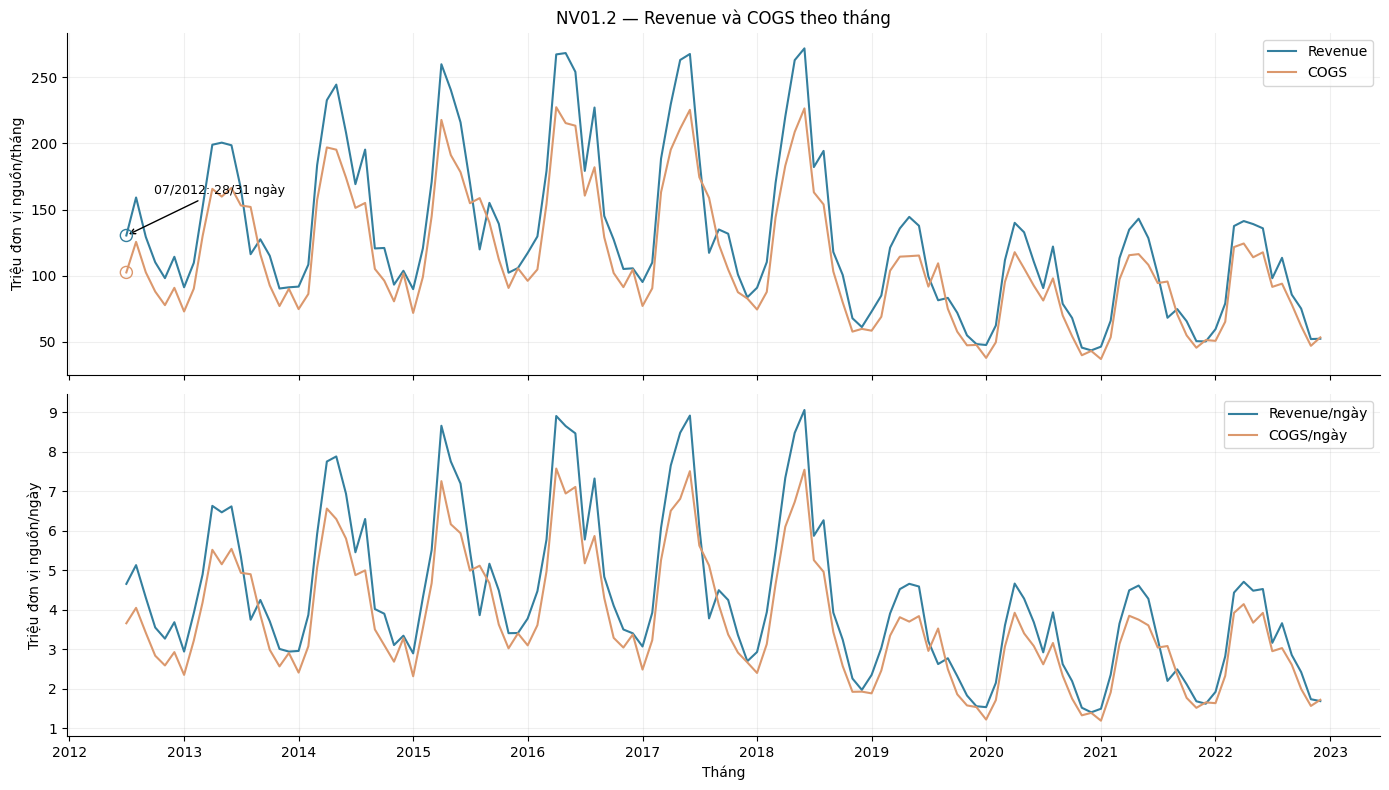

In [14]:
import matplotlib.dates as mdates
month_dates = monthly.index.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for metric, title, color in [('revenue', 'Revenue', '#347f9e'), ('cogs', 'COGS', '#db986d')]:
    axes[0].plot(month_dates, monthly[metric].map(lambda x: float(x / MILLION)), label=title, color=color)
    axes[1].plot(month_dates, monthly[metric + '_daily'].map(lambda x: float(x / MILLION)), label=title + '/ngày', color=color)
    axes[0].scatter(month_dates[~monthly.full_month],
                    monthly.loc[~monthly.full_month, metric].map(lambda x: float(x / MILLION)),
                    facecolors='none', edgecolors=color, s=75, zorder=4)
axes[0].annotate('07/2012: 28/31 ngày', xy=(month_dates[0], float(monthly.iloc[0].revenue / MILLION)),
                 xytext=(20, 30), textcoords='offset points', fontsize=9, arrowprops={'arrowstyle': '->'})
axes[0].set(title='NV01.2 — Revenue và COGS theo tháng', ylabel='Triệu đơn vị nguồn/tháng')
axes[1].set(ylabel='Triệu đơn vị nguồn/ngày', xlabel='Tháng')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
for ax in axes:
    ax.grid(alpha=.2); ax.legend(loc='upper right')
fig.tight_layout(); display(fig); plt.close(fig)

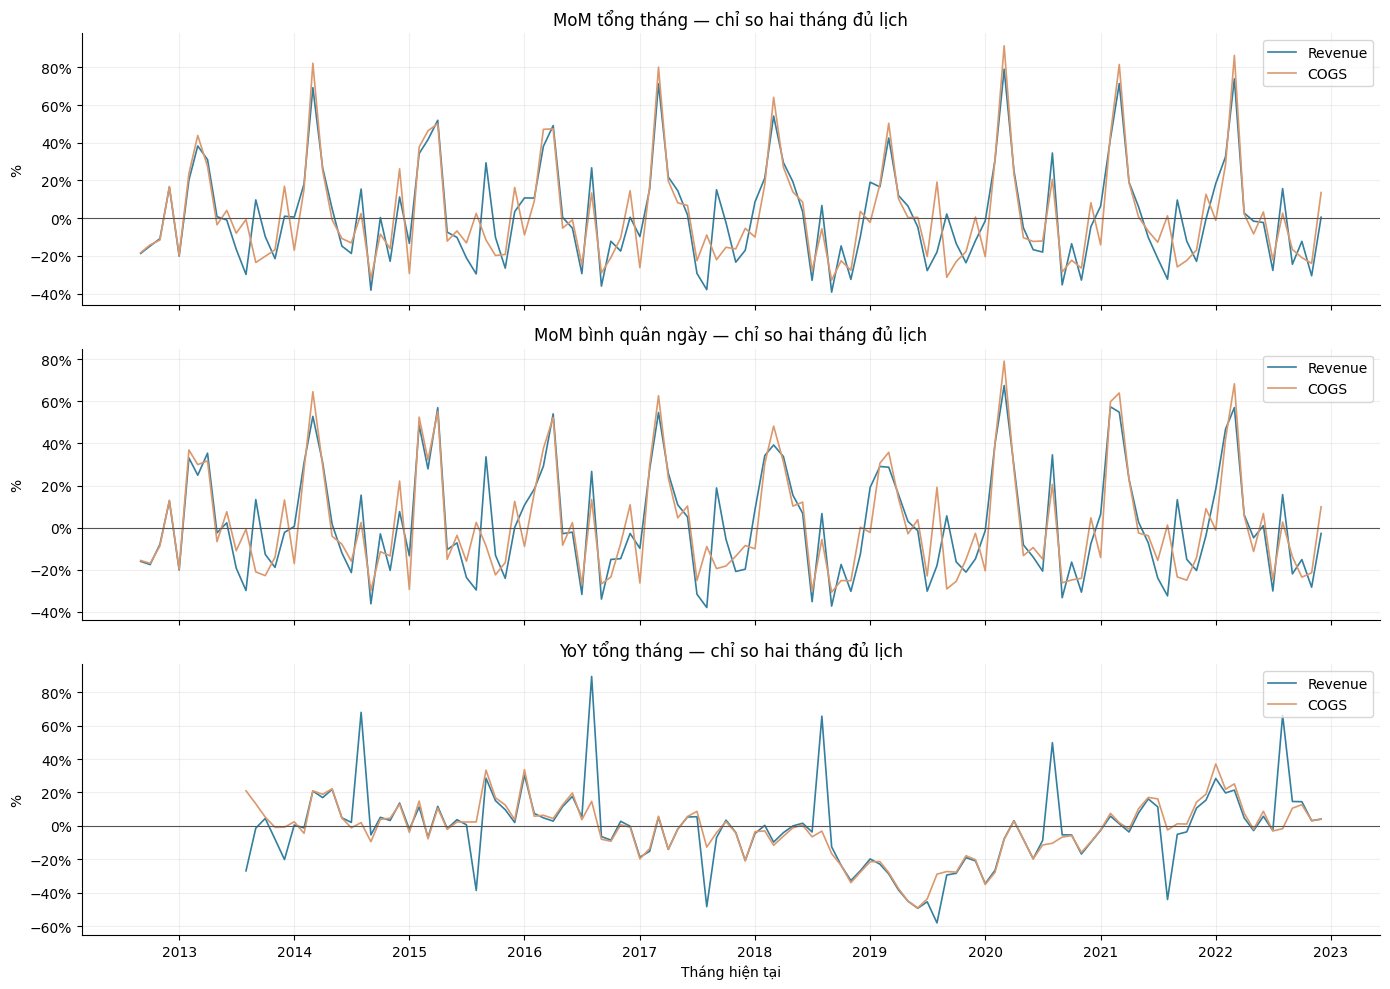

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for metric, title, color in [('revenue', 'Revenue', '#347f9e'), ('cogs', 'COGS', '#db986d')]:
    for ax, field in zip(axes, [metric + '_mom_pct', metric + '_daily_mom_pct', metric + '_yoy_pct']):
        ax.plot(month_dates, monthly[field].map(lambda x: float(x) if x is not None else float('nan')),
                label=title, color=color, linewidth=1.2)
for ax, title in zip(axes, ['MoM tổng tháng', 'MoM bình quân ngày', 'YoY tổng tháng']):
    ax.set(title=title + ' — chỉ so hai tháng đủ lịch', ylabel='%')
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.axhline(0, color='#555555', linewidth=.8); ax.grid(alpha=.2); ax.legend(loc='upper right')
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[2].set_xlabel('Tháng hiện tại')
fig.tight_layout(); display(fig); plt.close(fig)

### 4. Các tháng Revenue cao/thấp và biến động mạnh

Xếp hạng tổng Revenue **chỉ trong các tháng đủ lịch** (top/bottom 5); tháng chưa đủ lịch đã trình bày riêng. Đọc thêm Revenue/ngày vì tháng đủ lịch vẫn khác độ dài. Tách xếp hạng **tốc độ %**, **chênh tiền tuyệt đối** và **bình quân ngày**, ghi rõ kỳ so sánh.

In [16]:
complete_months = monthly.loc[monthly.full_month].copy()
for label, frame in [('5 tháng Revenue cao nhất', complete_months.sort_values('revenue', ascending=False, kind='stable').head(5)),
                     ('5 tháng Revenue thấp nhất', complete_months.sort_values('revenue', kind='stable').head(5))]:
    display(Markdown('**' + label + ' — triệu đơn vị nguồn**'))
    with pd.option_context('display.max_columns', None):
        display(month_table(frame, growth=False))

monthly['revenue_mom_delta'] = pd.Series([
    monthly.at[m, 'revenue'] - monthly.at[m - 1, 'revenue']
    if monthly.at[m, 'revenue_mom_pct'] is not None else None
    for m in monthly.index], index=monthly.index, dtype=object)

def movement_table(frame, lag):
    out = pd.DataFrame(index=frame.index.astype(str))
    out.index.name = 'Tháng hiện tại'
    out['So với'] = [str(m - lag) for m in frame.index]
    out['Ngày hiện tại/kỳ gốc'] = [f'{monthly.at[m, "days"]}/{monthly.at[m-lag, "days"]}' for m in frame.index]
    label = 'mom' if lag == 1 else 'yoy'
    for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
        out[f'Δ{title} (triệu)'] = [fmt_million(monthly.at[m, metric] - monthly.at[m-lag, metric]) for m in frame.index]
        out[f'{title} {label.upper()}'] = frame[f'{metric}_{label}_pct'].map(fmt_pct).to_list()
        out[f'{title}/ngày {label.upper()}'] = frame[f'{metric}_daily_{label}_pct'].map(fmt_pct).to_list()
    return out

for field, lag, title in [('revenue_mom_pct', 1, 'MoM Revenue theo tổng tháng (%)'),
                          ('revenue_daily_mom_pct', 1, 'MoM Revenue bình quân ngày (%)'),
                          ('revenue_mom_delta', 1, 'Thay đổi Revenue MoM theo tiền'),
                          ('revenue_yoy_pct', 12, 'YoY Revenue theo tổng tháng (%)')]:
    eligible = monthly.loc[monthly[field].notna()]
    for ascending, label in [(False, 'Tăng mạnh nhất'), (True, 'Giảm mạnh nhất')]:
        frame = eligible.sort_values(field, ascending=ascending, kind='stable').head(5)
        display(Markdown(f'**{label} — {title}**'))
        with pd.option_context('display.max_columns', None):
            display(movement_table(frame, lag))

**5 tháng Revenue cao nhất — triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R
Tháng,,,,,,,
2018-06,30/30,"271,67","226,35","45,33","9,06","7,54","16,68%"
2016-05,31/31,"268,13","215,25","52,88","8,65","6,94","19,72%"
2017-06,30/30,"267,43","225,27","42,17","8,91","7,51","15,77%"
2016-04,30/30,"267,11","227,25","39,86","8,90","7,58","14,92%"
2017-05,31/31,"262,91","211,07","51,84","8,48","6,81","19,72%"


**5 tháng Revenue thấp nhất — triệu đơn vị nguồn**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R
Tháng,,,,,,,
2020-12,31/31,"43,67","43,24","0,44","1,41","1,39","1,00%"
2020-11,30/30,"45,74","39,98","5,76","1,52","1,33","12,59%"
2021-01,31/31,"46,47","37,11","9,37","1,50","1,20","20,16%"
2020-01,31/31,"47,73","37,99","9,74","1,54","1,23","20,40%"
2019-12,31/31,"48,43","47,77","0,66","1,56","1,54","1,36%"


**Tăng mạnh nhất — MoM Revenue theo tổng tháng (%)**

,So với,Ngày hiện tại/kỳ gốc,ΔR (triệu),R MOM,R/ngày MOM,ΔC (triệu),C MOM,C/ngày MOM
Tháng hiện tại,,,,,,,,
2020-03,2020-02,31/29,"49,36","79,03%","67,48%","45,57","91,47%","79,12%"
2022-03,2022-02,31/28,"58,43","73,87%","57,05%","56,38","86,36%","68,33%"
2021-03,2021-02,31/28,"47,20","71,43%","54,84%","43,67","81,54%","63,97%"
2017-03,2017-02,31/28,"78,40","71,28%","54,71%","72,50","80,08%","62,65%"
2014-03,2014-02,31/28,"75,07","69,23%","52,85%","70,91","82,20%","64,57%"


... (10 outputs left out)

**Tăng mạnh nhất — YoY Revenue theo tổng tháng (%)**

,So với,Ngày hiện tại/kỳ gốc,ΔR (triệu),R YOY,R/ngày YOY,ΔC (triệu),C YOY,C/ngày YOY
Tháng hiện tại,,,,,,,,
2016-08,2015-08,31/31,"107,15","89,40%","89,40%","23,28","14,68%","14,68%"
2014-08,2013-08,31/31,"78,99","67,94%","67,94%","3,01","1,98%","1,98%"
2022-08,2021-08,31/31,"45,26","66,29%","66,29%","-1,62","-1,69%","-1,69%"
2018-08,2017-08,31/31,"76,98","65,63%","65,63%","-4,97","-3,13%","-3,13%"
2020-08,2019-08,31/31,"40,57","49,78%","49,78%","-11,35","-10,38%","-10,38%"


**Giảm mạnh nhất — YoY Revenue theo tổng tháng (%)**

,So với,Ngày hiện tại/kỳ gốc,ΔR (triệu),R YOY,R/ngày YOY,ΔC (triệu),C YOY,C/ngày YOY
Tháng hiện tại,,,,,,,,
2019-08,2018-08,31/31,"-112,78","-58,05%","-58,05%","-44,44","-28,89%","-28,89%"
2019-06,2018-06,30/30,"-133,94","-49,30%","-49,30%","-111,07","-49,07%","-49,07%"
2017-08,2016-08,31/31,"-109,71","-48,33%","-48,33%","-23,10","-12,70%","-12,70%"
2019-07,2018-07,31/31,"-82,69","-45,41%","-45,41%","-71,19","-43,67%","-43,67%"
2019-05,2018-05,31/31,"-118,34","-45,03%","-45,03%","-93,80","-44,97%","-44,97%"


In [17]:
rev_peak = complete_months.revenue.idxmax()
rev_low = complete_months.revenue.idxmin()
mom_best = monthly.revenue_mom_pct.dropna().idxmax()
mom_worst = monthly.revenue_mom_pct.dropna().idxmin()
daily_best = monthly.revenue_daily_mom_pct.dropna().idxmax()
daily_worst = monthly.revenue_daily_mom_pct.dropna().idxmin()
cogs_best = monthly.cogs_mom_pct.dropna().idxmax()
cogs_worst = monthly.cogs_mom_pct.dropna().idxmin()
display(Markdown(f'''
**Số liệu quan sát:** Revenue cao nhất **{rev_peak}: {fmt_vi(monthly.at[rev_peak, 'revenue'])}**, thấp nhất
**{rev_low}: {fmt_vi(monthly.at[rev_low, 'revenue'])}** đơn vị nguồn trong các tháng đủ lịch.
MoM tổng Revenue tăng mạnh nhất **{mom_best}: {fmt_pct(monthly.at[mom_best, 'revenue_mom_pct'])}**,
giảm mạnh nhất **{mom_worst}: {fmt_pct(monthly.at[mom_worst, 'revenue_mom_pct'])}**.
MoM COGS tăng mạnh nhất **{cogs_best}: {fmt_pct(monthly.at[cogs_best, 'cogs_mom_pct'])}**,
giảm mạnh nhất **{cogs_worst}: {fmt_pct(monthly.at[cogs_worst, 'cogs_mom_pct'])}**.

**Nhận xét có căn cứ:** sau khi chuẩn hóa số ngày, Revenue/ngày tăng mạnh nhất **{daily_best}**
(**{fmt_pct(monthly.at[daily_best, 'revenue_daily_mom_pct'])}**), giảm mạnh nhất **{daily_worst}**
(**{fmt_pct(monthly.at[daily_worst, 'revenue_daily_mom_pct'])}**). Thứ hạng giảm mạnh nhất thay đổi,
nên cần phân biệt biến động tổng với cường độ doanh thu mỗi ngày.
Riêng **{mom_best}**, MoM cao nhưng YoY tổng Revenue là **{fmt_pct(monthly.at[mom_best, 'revenue_yoy_pct'])}**;
phục hồi so với tháng trước chưa có nghĩa đã vượt mức cùng kỳ.
'''))


**Số liệu quan sát:** Revenue cao nhất **2018-06: 271.674.172,09**, thấp nhất
**2020-12: 43.671.563,77** đơn vị nguồn trong các tháng đủ lịch.
MoM tổng Revenue tăng mạnh nhất **2020-03: 79,03%**,
giảm mạnh nhất **2018-09: -39,28%**.
MoM COGS tăng mạnh nhất **2020-03: 91,47%**,
giảm mạnh nhất **2018-09: -32,87%**.

**Nhận xét có căn cứ:** sau khi chuẩn hóa số ngày, Revenue/ngày tăng mạnh nhất **2020-03**
(**67,48%**), giảm mạnh nhất **2017-08**
(**-37,94%**). Thứ hạng giảm mạnh nhất thay đổi,
nên cần phân biệt biến động tổng với cường độ doanh thu mỗi ngày.
Riêng **2020-03**, MoM cao nhưng YoY tổng Revenue là **-7,76%**;
phục hồi so với tháng trước chưa có nghĩa đã vượt mức cùng kỳ.


### 5. Giai đoạn 2018–2020: suy giảm kéo dài hay tập trung?

Đặt **cùng tháng của ba năm** cạnh nhau; đo chênh Revenue 2019 − 2018 và tỷ trọng đóng góp vào tổng mức giảm năm 2019. Mẫu số là mức giảm ròng năm (2018 − 2019); nếu có tháng tăng bù, tỷ trọng của các tháng giảm có thể cộng vượt 100%. Đây là phân rã số học theo tháng, chưa phải nguyên nhân.

02/2020 có 29 ngày so với 28 ngày của 02/2019; đọc cả YoY tổng và bình quân ngày. Không suy diễn nguyên nhân từ mốc năm.

In [18]:
focus = monthly.loc['2018-01':'2020-12'].copy()
focus_years = pd.DataFrame(index=[2018, 2019, 2020], columns=[
    'days', 'revenue', 'cogs', 'difference', 'difference_pct', 'revenue_yoy_pct', 'cogs_yoy_pct'], dtype=object)
focus_years.index.name = 'Năm'
for year in focus_years.index:
    frame = focus.loc[focus.index.year == year]
    focus_years.at[year, 'days'] = int(frame.days.sum())
    for metric in ['revenue', 'cogs', 'difference']:
        focus_years.at[year, metric] = sum(frame[metric], ZERO)
    focus_years.at[year, 'difference_pct'] = safe_percent(focus_years.at[year, 'difference'], focus_years.at[year, 'revenue'])
    for metric in ['revenue', 'cogs']:
        base = annual.at[year - 1, metric]
        focus_years.at[year, metric + '_yoy_pct'] = safe_percent(focus_years.at[year, metric] - base, base)
summary_focus = pd.DataFrame(index=focus_years.index)
summary_focus['Số ngày'] = focus_years.days.astype(int)
for field, title in [('revenue', 'Revenue (triệu)'), ('cogs', 'COGS (triệu)'), ('difference', 'R − C (triệu)')]:
    summary_focus[title] = focus_years[field].map(fmt_million)
for field, title in [('difference_pct', '(R − C)/R'), ('revenue_yoy_pct', 'Revenue YoY'), ('cogs_yoy_pct', 'COGS YoY')]:
    summary_focus[title] = focus_years[field].map(fmt_pct)
with pd.option_context('display.max_columns', None):
    display(summary_focus)

focus_pairs = pd.DataFrame(index=range(1, 13))
focus_pairs.index.name = 'Tháng trong năm'
decline_2019 = annual.at[2018, 'revenue'] - annual.at[2019, 'revenue']
for year in [2018, 2019, 2020]:
    focus_pairs[f'R {year} (triệu)'] = [fmt_million(monthly.at[pd.Period(year=year, month=k, freq='M'), 'revenue']) for k in range(1, 13)]
focus_2019 = focus.loc['2019-01':'2019-12'].copy()
focus_2019['revenue_yoy_delta'] = [r.revenue - monthly.at[m - 12, 'revenue'] for m, r in focus_2019.iterrows()]
focus_2019['decline_share_pct'] = [safe_percent(-delta, decline_2019) for delta in focus_2019.revenue_yoy_delta]
focus_pairs['ΔR 2019−2018 (triệu)'] = focus_2019.revenue_yoy_delta.map(fmt_million).to_list()
focus_pairs['R YoY 2019'] = focus_2019.revenue_yoy_pct.map(fmt_pct).to_list()
focus_pairs['Đóng góp mức giảm 2019'] = focus_2019.decline_share_pct.map(fmt_pct).to_list()
focus_pairs['R YoY 2020'] = focus.loc['2020-01':'2020-12', 'revenue_yoy_pct'].map(fmt_pct).to_list()
focus_pairs['R/ngày YoY 2020'] = focus.loc['2020-01':'2020-12', 'revenue_daily_yoy_pct'].map(fmt_pct).to_list()
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(focus_pairs)
display(Markdown('**Revenue, COGS, chênh lệch và tăng trưởng từng tháng 2018–2020 — triệu đơn vị nguồn:**'))
for year in [2018, 2019, 2020]:
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(month_table(focus.loc[focus.index.year == year]))

,Số ngày,Revenue (triệu),COGS (triệu),R − C (triệu),(R − C)/R,Revenue YoY,COGS YoY
Năm,,,,,,,
2018,365,"1.850,12","1.542,18","307,95","16,64%","-3,19%","-8,98%"
2019,365,"1.136,80","1.005,20","131,60","11,58%","-38,56%","-34,82%"
2020,366,"1.054,51","886,09","168,43","15,97%","-7,24%","-11,85%"


,R 2018 (triệu),R 2019 (triệu),R 2020 (triệu),ΔR 2019−2018 (triệu),R YoY 2019,Đóng góp mức giảm 2019,R YoY 2020,R/ngày YoY 2020
Tháng trong năm,,,,,,,,
1,"90,96","72,96","47,73","-18,00","-19,79%","2,52%","-34,58%","-34,58%"
2,"110,31","85,06","62,45","-25,25","-22,89%","3,54%","-26,58%","-29,11%"
3,"170,10","121,21","111,80","-48,89","-28,74%","6,85%","-7,76%","-7,76%"
4,"220,22","135,73","139,96","-84,49","-38,37%","11,84%","3,12%","3,12%"
5,"262,78","144,44","132,82","-118,34","-45,03%","16,59%","-8,04%","-8,04%"
6,"271,67","137,73","110,61","-133,94","-49,30%","18,78%","-19,69%","-19,69%"
7,"182,07","99,38","90,70","-82,69","-45,41%","11,59%","-8,74%","-8,74%"
8,"194,28","81,50","122,07","-112,78","-58,05%","15,81%","49,78%","49,78%"
9,"117,97","83,29","78,83","-34,68","-29,40%","4,86%","-5,36%","-5,36%"


**Revenue, COGS, chênh lệch và tăng trưởng từng tháng 2018–2020 — triệu đơn vị nguồn:**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2018-01,31/31,"90,96","74,52","16,44","2,93","2,40","18,07%","8,63%","-10,03%","-4,52%","-3,45%"
2018-02,28/28,"110,31","87,80","22,51","3,94","3,14","20,40%","21,27%","17,82%","0,30%","-3,02%"
2018-03,31/31,"170,10","144,10","25,99","5,49","4,65","15,28%","54,19%","64,12%","-9,71%","-11,61%"
2018-04,30/30,"220,22","183,09","37,13","7,34","6,10","16,86%","29,47%","27,06%","-4,05%","-6,20%"
2018-05,31/31,"262,78","208,59","54,18","8,48","6,73","20,62%","19,32%","13,93%","-0,05%","-1,17%"
2018-06,30/30,"271,67","226,35","45,33","9,06","7,54","16,68%","3,39%","8,51%","1,59%","0,48%"
2018-07,31/31,"182,07","163,01","19,06","5,87","5,26","10,47%","-32,98%","-27,98%","-3,66%","-6,54%"
2018-08,31/31,"194,28","153,84","40,44","6,27","4,96","20,82%","6,70%","-5,63%","65,63%","-3,13%"
2018-09,30/30,"117,97","103,26","14,70","3,93","3,44","12,46%","-39,28%","-32,87%","-12,58%","-16,60%"


,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2019-01,31/31,"72,96","58,53","14,43","2,35","1,89","19,77%","19,08%","-2,26%","-19,79%","-21,45%"
2019-02,28/28,"85,06","69,04","16,02","3,04","2,47","18,83%","16,58%","17,95%","-22,89%","-21,37%"
2019-03,31/31,"121,21","103,80","17,41","3,91","3,35","14,36%","42,50%","50,34%","-28,74%","-27,97%"
2019-04,30/30,"135,73","114,43","21,30","4,52","3,81","15,70%","11,98%","10,24%","-38,37%","-37,50%"
2019-05,31/31,"144,44","114,79","29,65","4,66","3,70","20,53%","6,42%","0,32%","-45,03%","-44,97%"
2019-06,30/30,"137,73","115,27","22,46","4,59","3,84","16,31%","-4,65%","0,42%","-49,30%","-49,07%"
2019-07,31/31,"99,38","91,81","7,57","3,21","2,96","7,62%","-27,84%","-20,35%","-45,41%","-43,67%"
2019-08,31/31,"81,50","109,40","-27,90","2,63","3,53","-34,24%","-18,00%","19,15%","-58,05%","-28,89%"
2019-09,30/30,"83,29","75,06","8,23","2,78","2,50","9,88%","2,20%","-31,38%","-29,40%","-27,31%"


,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R,R MOM,C MOM,R YOY,C YOY
Tháng,,,,,,,,,,,
2020-01,31/31,"47,73","37,99","9,74","1,54","1,23","20,40%","-1,45%","-20,48%","-34,58%","-35,10%"
2020-02,29/29,"62,45","49,82","12,63","2,15","1,72","20,22%","30,84%","31,14%","-26,58%","-27,84%"
2020-03,31/31,"111,80","95,39","16,41","3,61","3,08","14,68%","79,03%","91,47%","-7,76%","-8,10%"
2020-04,30/30,"139,96","117,79","22,17","4,67","3,93","15,84%","25,18%","23,48%","3,12%","2,94%"
2020-05,31/31,"132,82","105,57","27,25","4,28","3,41","20,52%","-5,10%","-10,38%","-8,04%","-8,04%"
2020-06,30/30,"110,61","92,52","18,09","3,69","3,08","16,35%","-16,73%","-12,36%","-19,69%","-19,74%"
2020-07,31/31,"90,70","81,31","9,39","2,93","2,62","10,35%","-18,00%","-12,11%","-8,74%","-11,44%"
2020-08,31/31,"122,07","98,04","24,02","3,94","3,16","19,68%","34,58%","20,57%","49,78%","-10,38%"
2020-09,30/30,"78,83","70,04","8,79","2,63","2,33","11,15%","-35,42%","-28,56%","-5,36%","-6,70%"


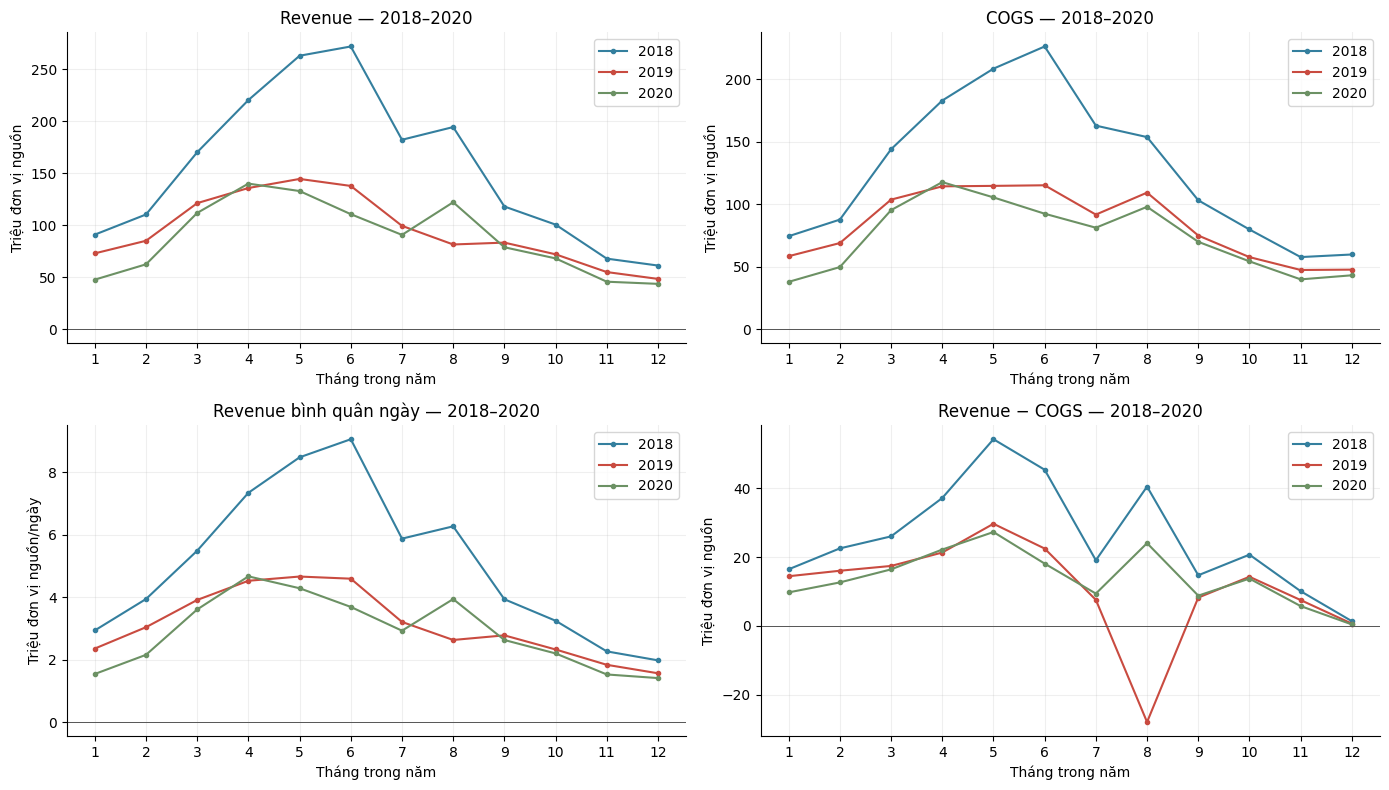

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for year, color in [(2018, '#347f9e'), (2019, '#c94b40'), (2020, '#6c9164')]:
    frame = focus.loc[focus.index.year == year]
    for ax, metric in zip(axes.flat, ['revenue', 'cogs', 'revenue_daily', 'difference']):
        ax.plot(frame.index.month, frame[metric].map(lambda x: float(x / MILLION)),
                marker='o', markersize=3, label=str(year), color=color)
for ax, title, unit in zip(axes.flat, ['Revenue', 'COGS', 'Revenue bình quân ngày', 'Revenue − COGS'],
                           ['Triệu đơn vị nguồn'] * 2 + ['Triệu đơn vị nguồn/ngày', 'Triệu đơn vị nguồn']):
    ax.set(title=title + ' — 2018–2020', xlabel='Tháng trong năm', ylabel=unit, xticks=range(1, 13))
    ax.axhline(0, color='#555555', linewidth=.7); ax.grid(alpha=.2); ax.legend()
fig.tight_layout(); display(fig); plt.close(fig)

In [20]:
from itertools import groupby
negative_2019 = focus_2019.loc[focus_2019.revenue_yoy_delta.map(lambda x: x < ZERO)]
longest_decline_2019 = max((sum(1 for _ in g) if falling else 0
                           for falling, g in groupby(focus_2019.revenue_yoy_pct.map(lambda x: x < ZERO))), default=0)
worst_three_2019 = focus_2019.sort_values('revenue_yoy_delta', kind='stable').head(3)
worst_yoy_2019 = focus_2019.revenue_yoy_pct.idxmin()
share_three_2019 = safe_percent(-sum(worst_three_2019.revenue_yoy_delta, ZERO), decline_2019)
focus_2020 = focus.loc['2020-01':'2020-12']
negative_2020 = focus_2020.loc[focus_2020.revenue_yoy_pct.map(lambda x: x < ZERO)]
positive_2020 = focus_2020.loc[focus_2020.revenue_yoy_pct.map(lambda x: x > ZERO)]
late_2018 = focus.loc['2018-09':'2018-12']
display(Markdown(f'''
**Số liệu đã quan sát:**

- Revenue 2019 giảm **{fmt_vi(decline_2019)}** đơn vị nguồn so với 2018
  (**{fmt_pct(focus_years.at[2019, 'revenue_yoy_pct'])}**); COGS giảm **{fmt_pct(focus_years.at[2019, 'cogs_yoy_pct'])}**.
- **{len(negative_2019)}/12 tháng năm 2019** có Revenue thấp hơn cùng tháng 2018;
  chuỗi giảm YoY dài nhất trong năm là **{longest_decline_2019} tháng liên tiếp**.
- Ba tháng đóng góp tiền giảm lớn nhất: **{', '.join(str(m) for m in worst_three_2019.index)}**,
  chiếm **{fmt_pct(share_three_2019)}** tổng mức giảm năm.
  Giảm YoY theo tỷ lệ mạnh nhất là **{worst_yoy_2019}: {fmt_pct(focus_2019.at[worst_yoy_2019, 'revenue_yoy_pct'])}**.
- **{int(late_2018.revenue_yoy_pct.map(lambda x: x < ZERO).sum())}/4 tháng 09–12/2018** đã có Revenue thấp hơn cùng kỳ 2017.
- Sang 2020, **{len(negative_2020)}/12 tháng** tiếp tục thấp hơn cùng kỳ 2019; các tháng tăng YoY là
  **{', '.join(str(m) for m in positive_2020.index)}**. Cả năm 2020 Revenue
  **{fmt_pct(focus_years.at[2020, 'revenue_yoy_pct'])}** so với 2019.
- 02/2020: YoY tổng Revenue **{fmt_pct(monthly.at[pd.Period('2020-02'), 'revenue_yoy_pct'])}**,
  YoY bình quân ngày **{fmt_pct(monthly.at[pd.Period('2020-02'), 'revenue_daily_yoy_pct'])}**;
  khác biệt do 29 so với 28 ngày, chưa phản ánh thay đổi giá hoặc cơ cấu.

**Nhận xét được số liệu hỗ trợ:** suy giảm 2019 kéo dài qua cả 12 tháng trên thước đo YoY, đồng thời một vài tháng
đóng góp lớn hơn vào tổng tiền giảm. Ba tháng chiếm khoảng một nửa mức giảm không có nghĩa các tháng khác không giảm.
Dấu hiệu giảm YoY đã xuất hiện ở cuối 2018 và phần lớn tháng 2020 tiếp tục dưới nền 2019;
chưa có cơ sở mô tả đây là sụt giảm ngắn trong một tháng hoặc đã phục hồi toàn diện vào 2020.
MoM dương ở một số tháng 2019 vẫn có thể đi cùng YoY âm vì hai thước đo dùng nền khác nhau.

**Giả thuyết chưa xác minh:** thay đổi số lượng, giá, cơ cấu hàng hoặc phạm vi ghi nhận cần được đối soát.
Bảng tháng không xác định nguyên nhân, không gán suy giảm cho sự kiện bên ngoài, chiến dịch hay hiệu quả vận hành.
'''))


**Số liệu đã quan sát:**

- Revenue 2019 giảm **713.321.014,57** đơn vị nguồn so với 2018
  (**-38,56%**); COGS giảm **-34,82%**.
- **12/12 tháng năm 2019** có Revenue thấp hơn cùng tháng 2018;
  chuỗi giảm YoY dài nhất trong năm là **12 tháng liên tiếp**.
- Ba tháng đóng góp tiền giảm lớn nhất: **2019-06, 2019-05, 2019-08**,
  chiếm **51,18%** tổng mức giảm năm.
  Giảm YoY theo tỷ lệ mạnh nhất là **2019-08: -58,05%**.
- **4/4 tháng 09–12/2018** đã có Revenue thấp hơn cùng kỳ 2017.
- Sang 2020, **10/12 tháng** tiếp tục thấp hơn cùng kỳ 2019; các tháng tăng YoY là
  **2020-04, 2020-08**. Cả năm 2020 Revenue
  **-7,24%** so với 2019.
- 02/2020: YoY tổng Revenue **-26,58%**,
  YoY bình quân ngày **-29,11%**;
  khác biệt do 29 so với 28 ngày, chưa phản ánh thay đổi giá hoặc cơ cấu.

**Nhận xét được số liệu hỗ trợ:** suy giảm 2019 kéo dài qua cả 12 tháng trên thước đo YoY, đồng thời một vài tháng
đóng góp lớn hơn vào tổng tiền giảm. Ba tháng chiếm khoảng một nửa mức giảm không có nghĩa các tháng khác không giảm.
Dấu hiệu giảm YoY đã xuất hiện ở cuối 2018 và phần lớn tháng 2020 tiếp tục dưới nền 2019;
chưa có cơ sở mô tả đây là sụt giảm ngắn trong một tháng hoặc đã phục hồi toàn diện vào 2020.
MoM dương ở một số tháng 2019 vẫn có thể đi cùng YoY âm vì hai thước đo dùng nền khác nhau.

**Giả thuyết chưa xác minh:** thay đổi số lượng, giá, cơ cấu hàng hoặc phạm vi ghi nhận cần được đối soát.
Bảng tháng không xác định nguyên nhân, không gán suy giảm cho sự kiện bên ngoài, chiến dịch hay hiệu quả vận hành.


### 6. Chênh lệch Revenue − COGS và dấu hiệu theo tháng trong năm

Xem đồng thời **chênh lệch tiền** và **tỷ lệ trên Revenue**, không suy từ doanh thu sang lợi nhuận.

Để mô tả dấu hiệu trong năm, chỉ lấy **10 năm đầy đủ 2013–2022** để mỗi tháng lịch có cùng số năm quan sát. Chỉ số tháng = Revenue bình quân ngày của tháng / Revenue bình quân ngày của năm × 100; mức 100 là nền bình quân ngày của chính năm đó. Cách này giảm ảnh hưởng quy mô năm và số ngày, chưa kiểm soát xu hướng trong năm, cơ cấu thứ trong tuần hay giá. Đây là mô tả sơ bộ NV01.2, **chưa kiểm chứng tính thời vụ ổn định**; phần chuyên sâu thuộc NV01.4.

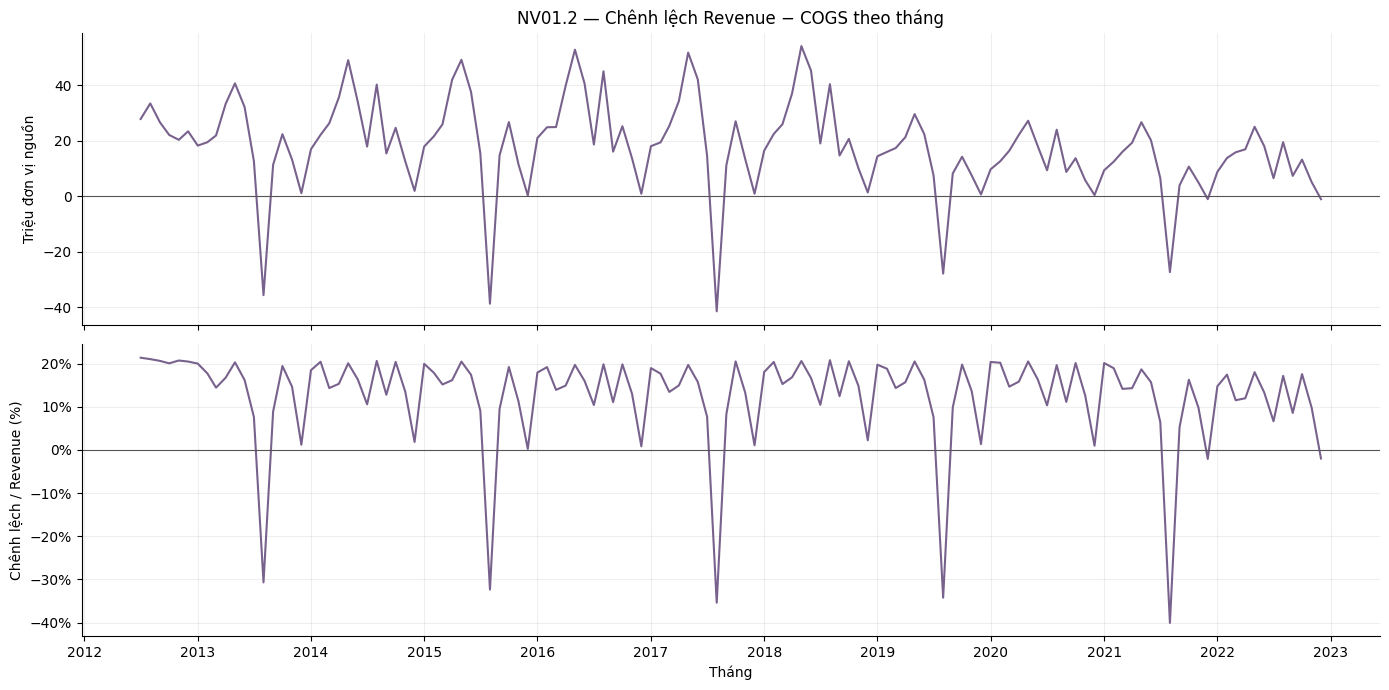

**7 tháng đủ lịch có Revenue < COGS — triệu đơn vị nguồn:**

,Ngày QS/lịch,Revenue,COGS,R − C,R/ngày,C/ngày,(R − C)/R
Tháng,,,,,,,
2013-08,31/31,"116,27","151,95","-35,68","3,75","4,90","-30,68%"
2015-08,31/31,"119,85","158,63","-38,77","3,87","5,12","-32,35%"
2017-08,31/31,"117,30","158,81","-41,51","3,78","5,12","-35,39%"
2019-08,31/31,"81,50","109,40","-27,90","2,63","3,53","-34,24%"
2021-08,31/31,"68,28","95,65","-27,37","2,20","3,09","-40,09%"
2021-12,31/31,"50,40","51,45","-1,04","1,63","1,66","-2,07%"
2022-12,31/31,"52,45","53,49","-1,03","1,69","1,73","-1,97%"



**Quan sát:** chênh lệch thấp nhất **2017-08: -41.512.111,25**,
cao nhất **2018-05: 54.184.728,46** đơn vị nguồn.
Tỷ lệ thấp nhất **2021-08: -40,09%**,
cao nhất **2012-08: 21,06%**.
Trong giai đoạn trọng tâm, **08/2019** có chênh lệch **-27.900.349,02**,
tỷ lệ **-34,24%**.
Tỷ lệ cả năm 2019 thay đổi **-5,07 điểm phần trăm** so với 2018.

**Nhận xét có căn cứ:** COGS vượt Revenue ở các tháng được liệt kê là tín hiệu cần đối soát phạm vi và cách ghi nhận;
không tự gọi đây là lỗ thực tế. Chênh lệch tiền và tỷ lệ thay đổi đáng kể nên đánh giá chỉ từ doanh thu sẽ bỏ sót thông tin.
**Chưa xác minh:** nguyên nhân chênh lệch âm, giá vốn lịch sử và tác động giảm giá/hoàn tiền/chi phí khác.


In [21]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(month_dates, monthly.difference.map(lambda x: float(x / MILLION)), color='#78628d')
axes[1].plot(month_dates, monthly.difference_pct.map(lambda x: float(x) if x is not None else float('nan')), color='#78628d')
axes[0].set(title='NV01.2 — Chênh lệch Revenue − COGS theo tháng', ylabel='Triệu đơn vị nguồn')
axes[1].set(ylabel='Chênh lệch / Revenue (%)', xlabel='Tháng')
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
for ax in axes:
    ax.axhline(0, color='#555555', linewidth=.8); ax.grid(alpha=.2)
fig.tight_layout(); display(fig); plt.close(fig)
negative_spread = complete_months.loc[complete_months.difference.map(lambda x: x < ZERO)]
display(Markdown(f'**{len(negative_spread)} tháng đủ lịch có Revenue < COGS — triệu đơn vị nguồn:**'))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(month_table(negative_spread, growth=False))
spread_min, spread_max = complete_months.difference.idxmin(), complete_months.difference.idxmax()
ratio_min, ratio_max = complete_months.difference_pct.idxmin(), complete_months.difference_pct.idxmax()
ratio_2019_pp = annual.at[2019, 'difference_pct'] - annual.at[2018, 'difference_pct']
display(Markdown(f'''
**Quan sát:** chênh lệch thấp nhất **{spread_min}: {fmt_vi(monthly.at[spread_min, 'difference'])}**,
cao nhất **{spread_max}: {fmt_vi(monthly.at[spread_max, 'difference'])}** đơn vị nguồn.
Tỷ lệ thấp nhất **{ratio_min}: {fmt_pct(monthly.at[ratio_min, 'difference_pct'])}**,
cao nhất **{ratio_max}: {fmt_pct(monthly.at[ratio_max, 'difference_pct'])}**.
Trong giai đoạn trọng tâm, **08/2019** có chênh lệch **{fmt_vi(monthly.at[pd.Period('2019-08'), 'difference'])}**,
tỷ lệ **{fmt_pct(monthly.at[pd.Period('2019-08'), 'difference_pct'])}**.
Tỷ lệ cả năm 2019 thay đổi **{fmt_vi(ratio_2019_pp)} điểm phần trăm** so với 2018.

**Nhận xét có căn cứ:** COGS vượt Revenue ở các tháng được liệt kê là tín hiệu cần đối soát phạm vi và cách ghi nhận;
không tự gọi đây là lỗ thực tế. Chênh lệch tiền và tỷ lệ thay đổi đáng kể nên đánh giá chỉ từ doanh thu sẽ bỏ sót thông tin.
**Chưa xác minh:** nguyên nhân chênh lệch âm, giá vốn lịch sử và tác động giảm giá/hoàn tiền/chi phí khác.
'''))

,Số năm,R/ngày TB (triệu),Chỉ số trung vị,Chỉ số nhỏ nhất,Chỉ số lớn nhất
Tháng lịch,,,,,
1,10,"2,59","58,29","52,46","75,57"
2,10,"3,48","80,18","74,74","97,54"
3,10,"4,93","115,75","100,50","138,44"
4,10,"6,53","149,07","144,82","167,18"
5,10,"6,58","150,09","139,94","167,23"
6,10,"6,43","146,47","127,96","178,66"
7,10,"4,66","106,23","98,79","117,76"
8,10,"4,37","99,35","72,26","136,67"
9,10,"3,75","88,22","77,58","99,80"


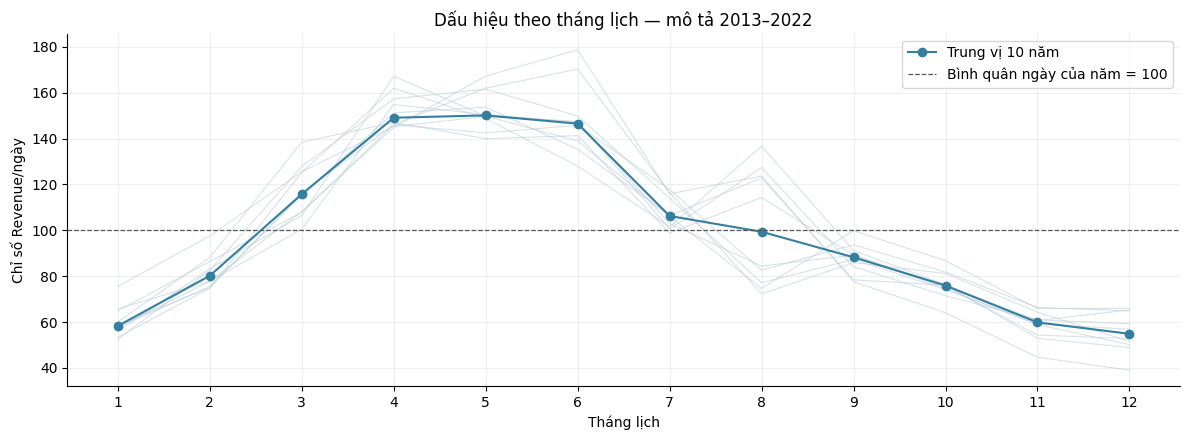


**Quan sát:** trong 10 năm đầy đủ, tháng lịch **05** có chỉ số Revenue/ngày trung vị
cao nhất (**150,09**), tháng **12** thấp nhất
(**54,85**).
Có **10/10 năm** đạt Revenue/ngày cao nhất trong nhóm tháng 04–06.

**Nhận xét có căn cứ:** dữ liệu có dấu hiệu khác biệt theo tháng lịch, nhóm 04–06 thường cao hơn nền bình quân ngày của năm.
Bảng min–max và các đường từng năm giúp đọc độ phân tán, không chỉ một tháng cao nhất.
**Giới hạn/giả thuyết:** chưa kết luận tính thời vụ ổn định hay khả năng dự báo; chưa tách xu hướng và yếu tố lịch.
Kiểm chứng thời vụ chuyên sâu được giữ cho NV01.4, chưa triển khai ở đây.


In [22]:
profile_years = annual.index[annual.full_year]
month_profile_source = monthly.loc[monthly.index.year.isin(profile_years)].copy()
month_profile_source['calendar_month'] = month_profile_source.index.month
month_profile_source['daily_index'] = pd.Series([
    r.revenue_daily / (annual.at[m.year, 'revenue'] / Decimal(int(annual.at[m.year, 'days']))) * HUNDRED
    if annual.at[m.year, 'revenue'] != ZERO else None
    for m, r in month_profile_source.iterrows()], index=month_profile_source.index, dtype=object)
# Thống kê mô tả dùng Decimal, không chuyển float trước tổng hợp.
profile_records = []
for k, frame in month_profile_source.groupby('calendar_month', sort=True):
    indices = sorted(v for v in frame.daily_index if v is not None)
    count = len(indices)
    median = (indices[(count - 1) // 2] + indices[count // 2]) / Decimal(2) if count else None
    profile_records.append({'calendar_month': k, 'years': count,
        'mean_daily': sum(frame.revenue_daily, ZERO) / Decimal(len(frame)),
        'median_index': median, 'min_index': min(indices) if count else None, 'max_index': max(indices) if count else None})
month_profile = pd.DataFrame(profile_records).set_index('calendar_month')
profile_display = pd.DataFrame(index=month_profile.index)
profile_display.index.name = 'Tháng lịch'
profile_display['Số năm'] = month_profile.years
profile_display['R/ngày TB (triệu)'] = month_profile.mean_daily.map(fmt_million)
for field, title in [('median_index', 'Chỉ số trung vị'), ('min_index', 'Chỉ số nhỏ nhất'), ('max_index', 'Chỉ số lớn nhất')]:
    profile_display[title] = month_profile[field].map(fmt_vi)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(profile_display)
fig, ax = plt.subplots(figsize=(12, 4.5))
for year in profile_years:
    frame = month_profile_source.loc[month_profile_source.index.year == year]
    ax.plot(frame.index.month, frame.daily_index.map(float), color='#b8cbd4', alpha=.55, linewidth=.8)
ax.plot(month_profile.index, month_profile.median_index.map(float), color='#347f9e', marker='o', label='Trung vị 10 năm')
ax.axhline(100, color='#555555', linestyle='--', linewidth=.9, label='Bình quân ngày của năm = 100')
ax.set(title='Dấu hiệu theo tháng lịch — mô tả 2013–2022', xlabel='Tháng lịch', ylabel='Chỉ số Revenue/ngày', xticks=range(1, 13))
ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
profile_peak = int(month_profile.median_index.idxmax())
profile_low = int(month_profile.median_index.idxmin())
peak_year_months = month_profile_source.loc[month_profile_source.groupby(month_profile_source.index.year).revenue_daily.idxmax()]
peak_456 = int(peak_year_months.index.month.isin([4, 5, 6]).sum())
display(Markdown(f'''
**Quan sát:** trong {len(profile_years)} năm đầy đủ, tháng lịch **{profile_peak:02d}** có chỉ số Revenue/ngày trung vị
cao nhất (**{fmt_vi(month_profile.at[profile_peak, 'median_index'])}**), tháng **{profile_low:02d}** thấp nhất
(**{fmt_vi(month_profile.at[profile_low, 'median_index'])}**).
Có **{peak_456}/{len(profile_years)} năm** đạt Revenue/ngày cao nhất trong nhóm tháng 04–06.

**Nhận xét có căn cứ:** dữ liệu có dấu hiệu khác biệt theo tháng lịch, nhóm 04–06 thường cao hơn nền bình quân ngày của năm.
Bảng min–max và các đường từng năm giúp đọc độ phân tán, không chỉ một tháng cao nhất.
**Giới hạn/giả thuyết:** chưa kết luận tính thời vụ ổn định hay khả năng dự báo; chưa tách xu hướng và yếu tố lịch.
Kiểm chứng thời vụ chuyên sâu được giữ cho NV01.4, chưa triển khai ở đây.
'''))

### 7. Kiểm chứng NV01.2 và bảo toàn NV01.1

Đọc CSV độc lập bằng `csv.DictReader`, kiểm tra ngày bằng `datetime.date`/`calendar`, cộng Decimal theo khóa `YYYY-MM`. Đối chiếu mọi tháng, số ngày, tổng tiền, chênh lệch, tỷ lệ và bình quân ngày; cộng tháng về từng năm và V02 với sai lệch **chính xác bằng 0**.

Tái tính toàn bộ MoM/YoY cho tổng và bình quân ngày theo kỳ lịch; kiểm tra biên 2012/2013, tháng 02 năm nhuận và các ca giả lập thiếu kỳ, mẫu số 0/NULL. Ca giả lập chỉ ở bộ nhớ. NV01.1 vẫn phải đạt 16/16; kiểm tra lại SHA-256 các file bảo toàn.

In [23]:
monthly_verification = []
def month_check(name, condition):
    condition = bool(condition)
    monthly_verification.append({'Kiểm tra NV01.2': name, 'Đạt': condition})
    assert condition, name

monthly_oracle = defaultdict(lambda: {'dates': set(), 'revenue': ZERO, 'cogs': ZERO})
with SALES_PATH.open(encoding='utf-8-sig', newline='') as stream:
    for record in csv.DictReader(stream, strict=True):
        day = date.fromisoformat(record['Date'])
        item = monthly_oracle[record['Date'][:7]]
        item['dates'].add(day)
        item['revenue'] += Decimal(record['Revenue'])
        item['cogs'] += Decimal(record['COGS'])
expected_months = pd.period_range(sales.Date.min(), sales.Date.max(), freq='M')
month_check('126 tháng đúng lịch min–max, không trùng/thiếu',
            len(monthly) == 126 and monthly.index.is_unique and monthly.index.equals(expected_months)
            and set(monthly.index.astype(str)) == set(monthly_oracle))
values_ok = coverage_ok = formulas_ok = growth_ok = reasons_ok = True
for month, row in monthly.iterrows():
    independent = monthly_oracle[str(month)]
    y, k = map(int, str(month).split('-'))
    expected_calendar = {date(y, k, d) for d in range(1, calendar.monthrange(y, k)[1] + 1)}
    full_current = independent['dates'] == expected_calendar
    count = len(independent['dates'])
    rev, cog = independent['revenue'], independent['cogs']
    values_ok &= row.revenue == rev and row.cogs == cog
    coverage_ok &= (row.days == count and row.calendar_days == len(expected_calendar)
                    and bool(row.full_month) == full_current
                    and row.first_date.date() == min(independent['dates'])
                    and row.last_date.date() == max(independent['dates']))
    expected_ratio = (rev - cog) / rev * HUNDRED if rev != ZERO else None
    formulas_ok &= (row.difference == rev - cog and row.difference_pct == expected_ratio
                    and row.revenue_daily == rev / Decimal(count)
                    and row.cogs_daily == cog / Decimal(count))
    for label, lag in [('mom', 1), ('yoy', 12)]:
        # Khóa đối chiếu dùng chỉ số tháng nguyên, độc lập Period arithmetic.
        ordinal = y * 12 + k - 1 - lag
        py, pk0 = divmod(ordinal, 12)
        prev = monthly_oracle.get(f'{py:04d}-{pk0+1:02d}')
        prev_calendar = {date(py, pk0+1, d) for d in range(1, calendar.monthrange(py, pk0+1)[1] + 1)}
        valid = full_current and prev is not None and prev['dates'] == prev_calendar
        for metric in ['revenue', 'cogs']:
            for daily in [False, True]:
                field = metric + ('_daily' if daily else '')
                expected = None
                if valid:
                    current = independent[metric] / Decimal(count) if daily else independent[metric]
                    base = prev[metric] / Decimal(len(prev['dates'])) if daily else prev[metric]
                    if base != ZERO:
                        expected = (current - base) / base * HUNDRED
                actual = row[f'{field}_{label}_pct']
                growth_ok &= actual == expected
                reason = row[f'{field}_{label}_reason']
                reasons_ok &= ((actual is None and reason != 'Hai tháng đủ lịch')
                               or (actual is not None and reason == 'Hai tháng đủ lịch'))
month_check('Mọi tổng Revenue/COGS tháng khớp CSV độc lập', values_ok)
month_check('Mọi tháng đúng số ngày, ngày đầu/cuối và cờ đủ lịch', coverage_ok)
month_check('Mọi chênh lệch, tỷ lệ và bình quân ngày đúng Decimal', formulas_ok)
month_check('Toàn bộ MoM/YoY tổng và bình quân ngày khớp công thức độc lập', growth_ok)
month_check('Lý do để trống và điều kiện so sánh nhất quán', reasons_ok)
month_check('Chỉ 07/2012 chưa đủ: 04–31/07, 28/31 ngày',
            list(partial_months.index.astype(str)) == ['2012-07']
            and monthly.at[pd.Period('2012-07'), 'days'] == 28
            and monthly.at[pd.Period('2012-07'), 'first_date'].date() == date(2012, 7, 4))
month_check('02/2016, 02/2020 đủ 29 ngày; tháng 02 khác đủ 28',
            all(monthly.at[pd.Period(year=y, month=2, freq='M'), 'days'] == (29 if calendar.isleap(y) else 28)
                for y in range(2013, 2023)))
by_year_month = monthly.groupby(monthly.index.year).agg(days=('days', 'sum'), revenue=('revenue', 'sum'),
                                                       cogs=('cogs', 'sum'), difference=('difference', 'sum'))
month_check('Cộng tháng về từng năm khớp NV01.1: ngày, Revenue, COGS, chênh lệch',
            all(by_year_month.at[y, f] == annual.at[y, f] for y in annual.index
                for f in ['days', 'revenue', 'cogs', 'difference']))
month_check('Tổng tháng khớp V02 Revenue/COGS chính xác; sai lệch 0',
            sum(monthly.revenue, ZERO) == v02['metrics']['sales_revenue']
            and sum(monthly.cogs, ZERO) == v02['metrics']['sales_cogs'])
month_check('Ngày tháng khớp ngày nguồn và V02', int(monthly.days.sum()) == len(sales) == v02['metrics']['sales_days'])
month_check('MoM 07/2012, 08/2012 và YoY 07/2013 trống cho mọi chỉ tiêu',
            all(monthly.at[pd.Period(m), f'{metric}{suffix}_{label}_pct'] is None
                for m, label in [('2012-07', 'mom'), ('2012-08', 'mom'), ('2013-07', 'yoy')]
                for metric in ['revenue', 'cogs'] for suffix in ['', '_daily']))
month_check('124 kỳ MoM, 113 kỳ YoY hợp lệ cho tổng và bình quân ngày',
            all(monthly[f'{metric}{suffix}_{label}_pct'].notna().sum() == count
                for label, count in [('mom', 124), ('yoy', 113)]
                for metric in ['revenue', 'cogs'] for suffix in ['', '_daily']))
month_check('Không có giá trị vô hạn trong tỷ lệ/tăng trưởng',
            all(value is None or (isinstance(value, Decimal) and value.is_finite())
                for field in monthly.columns if field.endswith('_pct') for value in monthly[field]))

In [24]:
# Ca biên của chính hàm so sánh; không chỉnh nguồn.
fixture = pd.DataFrame({'full_month': [True, True], 'revenue': [Decimal(100), Decimal(125)]},
                       index=pd.PeriodIndex(['2020-01', '2020-02'], freq='M'))
fixture_current = pd.Period('2020-02')
month_check('Ca hợp lệ tăng 25%; tử số 0 cho tăng trưởng 0%',
            monthly_comparison(fixture, fixture_current, 1, 'revenue')[0] == Decimal(25)
            and safe_percent(ZERO, Decimal(100)) == ZERO)
fixture.at[pd.Period('2020-01'), 'revenue'] = ZERO
month_check('Ca mẫu số 0: MoM không xác định, không vô hạn',
            monthly_comparison(fixture, fixture_current, 1, 'revenue')[0] is None)
fixture.at[pd.Period('2020-01'), 'revenue'] = None
month_check('Ca NULL: để trống; hàm phần trăm bảo vệ NULL/0',
            monthly_comparison(fixture, fixture_current, 1, 'revenue')[0] is None
            and safe_percent(Decimal(1), ZERO) is None and safe_percent(None, Decimal(1)) is None)
month_check('Ca mất kỳ: không lùi sang tháng gần nhất; YoY thiếu cũng trống',
            monthly_comparison(fixture.drop(index=pd.Period('2020-01')), fixture_current, 1, 'revenue')[0] is None
            and monthly_comparison(fixture, fixture_current, 12, 'revenue')[0] is None)
fixture.at[pd.Period('2020-01'), 'revenue'] = Decimal(100)
fixture.at[pd.Period('2020-01'), 'full_month'] = False
month_check('Ca kỳ gốc chưa đủ lịch: để trống',
            monthly_comparison(fixture, fixture_current, 1, 'revenue')[0] is None)
fixture.at[pd.Period('2020-01'), 'full_month'] = True
fixture.at[fixture_current, 'full_month'] = False
month_check('Ca kỳ hiện tại chưa đủ lịch: để trống',
            monthly_comparison(fixture, fixture_current, 1, 'revenue')[0] is None)
yoy_fixture = pd.DataFrame({'full_month': [True, True], 'revenue': [ZERO, Decimal(125)]},
                          index=pd.PeriodIndex(['2019-02', '2020-02'], freq='M'))
yoy_zero = monthly_comparison(yoy_fixture, pd.Period('2020-02'), 12, 'revenue')[0]
yoy_fixture.at[pd.Period('2019-02'), 'revenue'] = Decimal(100)
yoy_fixture.at[pd.Period('2019-02'), 'full_month'] = False
month_check('Ca YoY mẫu số 0 hoặc kỳ gốc chưa đủ đều trống',
            yoy_zero is None and monthly_comparison(yoy_fixture, pd.Period('2020-02'), 12, 'revenue')[0] is None)
month_check('Phân rã 12 tháng 2019 khớp đúng mức giảm Revenue năm',
            -sum(focus_2019.revenue_yoy_delta, ZERO) == decline_2019)
month_check('Bảng 2018–2020 và chỉ số tháng lịch đúng phạm vi',
            len(focus) == 36 and focus.full_month.all()
            and all(focus_years.at[y, f] == annual.at[y, f] for y in [2018, 2019, 2020]
                    for f in ['revenue', 'cogs', 'difference', 'difference_pct'])
            and len(month_profile_source) == 120 and month_profile.years.eq(10).all())
month_check('16/16 kiểm chứng NV01.1 vẫn đạt', len(verification) == 16 and all(item['Đạt'] for item in verification))
monthly_protected_after = protected_snapshot()
month_check('SHA-256 raw, src, tests, reports, docs và notebook khác giữ nguyên',
            monthly_protected_after == protected_before)
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(pd.DataFrame(monthly_verification))
monthly_reconciliation = pd.DataFrame([
    {'Chỉ tiêu': 'Revenue', 'Cộng tháng': fmt_vi(sum(monthly.revenue, ZERO)), 'Cộng năm NV01.1': fmt_vi(sum(annual.revenue, ZERO)),
     'V02 sales': fmt_vi(v02['metrics']['sales_revenue']),
     'Sai lệch tháng − V02': fmt_vi(sum(monthly.revenue, ZERO) - v02['metrics']['sales_revenue'])},
    {'Chỉ tiêu': 'COGS', 'Cộng tháng': fmt_vi(sum(monthly.cogs, ZERO)), 'Cộng năm NV01.1': fmt_vi(sum(annual.cogs, ZERO)),
     'V02 sales': fmt_vi(v02['metrics']['sales_cogs']),
     'Sai lệch tháng − V02': fmt_vi(sum(monthly.cogs, ZERO) - v02['metrics']['sales_cogs'])}])
with pd.option_context('display.max_columns', None):
    display(monthly_reconciliation)

,Kiểm tra NV01.2,Đạt
0,"126 tháng đúng lịch min–max, không trùng/thiếu",True
1,Mọi tổng Revenue/COGS tháng khớp CSV độc lập,True
2,"Mọi tháng đúng số ngày, ngày đầu/cuối và cờ đủ lịch",True
3,"Mọi chênh lệch, tỷ lệ và bình quân ngày đúng Decimal",True
4,Toàn bộ MoM/YoY tổng và bình quân ngày khớp công thức độc lập,True
5,Lý do để trống và điều kiện so sánh nhất quán,True
6,"Chỉ 07/2012 chưa đủ: 04–31/07, 28/31 ngày",True
7,"02/2016, 02/2020 đủ 29 ngày; tháng 02 khác đủ 28",True
8,"Cộng tháng về từng năm khớp NV01.1: ngày, Revenue, COGS, chênh lệch",True
9,Tổng tháng khớp V02 Revenue/COGS chính xác; sai lệch 0,True


,Chỉ tiêu,Cộng tháng,Cộng năm NV01.1,V02 sales,Sai lệch tháng − V02
0,Revenue,"16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","0,00"
1,COGS,"14.163.450.519,17","14.163.450.519,17","14.163.450.519,17","0,00"


In [25]:
assert all(item['Đạt'] for item in monthly_verification)
display(Markdown(f'''
**Kết quả NV01.2 sau khi chạy các ô theo thứ tự:** **{len(monthly)} tháng**, **{int(monthly.full_month.sum())} tháng đủ lịch**,
**{int(monthly.days.sum()):,} ngày**; **{len(monthly_verification)}/{len(monthly_verification)} nhóm kiểm chứng NV01.2 đạt**,
NV01.1 vẫn **{len(verification)}/{len(verification)}**. Tổng tháng khớp từng năm và V02, sai lệch Revenue/COGS **0,00**.
Có **124 kỳ MoM**, **113 kỳ YoY** hợp lệ cho mỗi chỉ tiêu (cả tổng và bình quân ngày).
SHA-256 **{len(monthly_protected_after)} file bảo toàn** không đổi.

**Bàn giao:** bảng tháng đầy đủ, biểu đồ Revenue/COGS, tăng trưởng, chênh lệch, xếp hạng và phân tích 2018–2020 ở trong notebook này.
Nhận xét phân biệt quan sát, diễn giải có căn cứ và giả thuyết; chưa kết luận nguyên nhân hay tính thời vụ ổn định.
Chỉ bổ sung **NV01.2**, chưa triển khai NV01.3–NV01.5; không ghi báo cáo phụ, không commit/push.
Dùng **Restart Kernel → Run All** để tái lập; notebook dừng khi kiểm chứng không đạt.
Bằng chứng lần chạy lưu trong output và metadata execution_validation.
'''))


**Kết quả NV01.2 sau khi chạy các ô theo thứ tự:** **126 tháng**, **125 tháng đủ lịch**,
**3,833 ngày**; **25/25 nhóm kiểm chứng NV01.2 đạt**,
NV01.1 vẫn **16/16**. Tổng tháng khớp từng năm và V02, sai lệch Revenue/COGS **0,00**.
Có **124 kỳ MoM**, **113 kỳ YoY** hợp lệ cho mỗi chỉ tiêu (cả tổng và bình quân ngày).
SHA-256 **32 file bảo toàn** không đổi.

**Bàn giao:** bảng tháng đầy đủ, biểu đồ Revenue/COGS, tăng trưởng, chênh lệch, xếp hạng và phân tích 2018–2020 ở trong notebook này.
Nhận xét phân biệt quan sát, diễn giải có căn cứ và giả thuyết; chưa kết luận nguyên nhân hay tính thời vụ ổn định.
Chỉ bổ sung **NV01.2**, chưa triển khai NV01.3–NV01.5; không ghi báo cáo phụ, không commit/push.
Dùng **Restart Kernel → Run All** để tái lập; notebook dừng khi kiểm chứng không đạt.
Bằng chứng lần chạy lưu trong output và metadata execution_validation.


## NV01.3 — Phân tích biến động doanh thu và giá vốn theo ngày

**Phạm vi:** chỉ NV01.3, tiếp tục từ `sales.csv` và các định nghĩa đã kiểm chứng. Toàn bộ NV01.1–NV01.2 phía trên được giữ nguyên; các trạng thái “chưa triển khai NV01.3” ở đó là ghi nhận của lần bàn giao trước. Chưa thực hiện NV01.4–NV01.5.

**Câu hỏi:** Revenue/COGS dao động ra sao, ngày cực trị nào đáng chú ý, biến động mạnh riêng lẻ hay tập trung, những ngày COGS vượt Revenue có đặc điểm gì, và mức suy giảm 2019 thể hiện thế nào trong phân bố ngày?

Tiền theo **đơn vị nguồn chưa xác minh loại tiền**, bảng/biểu đồ ghi **triệu đơn vị nguồn** trừ khi có chú thích khác. Dấu `.` tách nghìn, `,` tách thập phân; `—` là chưa xác định. Chênh lệch Revenue − COGS **chưa phải lợi nhuận thực tế**. Chỉ hiển thị bảng thống kê và các ngày được chọn, không in toàn bộ 3.833 dòng.

### 1. Định nghĩa, thống kê và chất lượng dữ liệu ngày

Với ngày lịch $t$: $S_t=R_t-C_t$, $s_t=100S_t/R_t$ (trống nếu $R_t=0$). Biến động so với **đúng ngày lịch trước**:

$$\Delta R_t=R_t-R_{t-1},\qquad g_t^R=100(R_t-R_{t-1})/R_{t-1}.$$

Áp dụng tương tự cho COGS. $\Delta$ là thay đổi có dấu theo **số tiền**, $|\Delta|$ là độ lớn không xét hướng, $g$ là thay đổi **phần trăm**. Ngày đầu hoặc thiếu ngày lịch trước: cả hai để trống; mẫu số 0: chỉ phần trăm để trống. Không coi trống là 0.

Mean là trung bình số học ngày; std là **độ lệch chuẩn mẫu (ddof=1)**. Phân vị dùng nội suy tuyến tính trên vị trí $(n-1)p$ trong dãy tăng dần (P50 = median). Tính tiền, phân vị và trung bình trượt bằng **Decimal**; chỉ đổi float lúc vẽ. Mean của tỷ lệ ngày là trung bình không trọng số, **khác** tỷ lệ toàn kỳ tính từ tổng tiền.

**Thận trọng nền nhỏ:** đánh dấu nền ngày trước ≤ P1 của các giá trị dương của chính chỉ tiêu trong toàn kỳ. Ngưỡng này chỉ là quy ước mô tả hồi cứu, không phải ngưỡng kinh doanh. Vẫn tính phần trăm nếu mẫu số khác 0, hiển thị cảnh báo nền nhỏ/không dương, **không xếp hạng ngày theo phần trăm**. Các bảng tăng/giảm chính xếp theo $\Delta R$.

In [26]:
from collections import deque
from decimal import ROUND_FLOOR

def decimal_quantile(values, p):
    ordered = sorted(v for v in values if v is not None)
    if not ordered:
        return None
    position = Decimal(len(ordered) - 1) * Decimal(str(p))
    lower = int(position.to_integral_value(rounding=ROUND_FLOOR))
    weight = position - Decimal(lower)
    return ordered[lower] + (ordered[min(lower + 1, len(ordered) - 1)] - ordered[lower]) * weight

def decimal_stats(values):
    values = [v for v in values if v is not None]
    count = len(values)
    mean = sum(values, ZERO) / Decimal(count) if count else None
    std = (sum(((v - mean) ** 2 for v in values), ZERO) / Decimal(count - 1)).sqrt() if count > 1 else None
    result = {'n': count, 'min': min(values) if count else None, 'max': max(values) if count else None,
              'mean': mean, 'median': decimal_quantile(values, '.5'), 'std': std}
    result.update({f'p{int(p * 100):02d}': decimal_quantile(values, p)
                   for p in [Decimal('.01'), Decimal('.05'), Decimal('.25'), Decimal('.75'), Decimal('.95'), Decimal('.99')]})
    return result

def day_change(current, previous, adjacent=True):
    if not adjacent or current is None or previous is None:
        return None, None
    return current - previous, safe_percent(current - previous, previous)

daily_detail = sales[['Date', 'Revenue', 'COGS']].copy().set_index('Date').sort_index()
daily_detail = daily_detail.rename(columns={'Revenue': 'revenue', 'COGS': 'cogs'})
daily_detail['difference'] = daily_detail.revenue - daily_detail.cogs
daily_detail['difference_pct'] = pd.Series(
    [safe_percent(r.difference, r.revenue) for r in daily_detail.itertuples()], index=daily_detail.index, dtype=object)
daily_detail['negative_difference'] = daily_detail.difference.map(lambda v: v < ZERO)
daily_small_base = {}
for metric in ['revenue', 'cogs']:
    values = daily_detail[metric].to_list()
    daily_small_base[metric] = decimal_quantile([v for v in values if v > ZERO], '.01')
    changes, rates, previous_values, cautions = [], [], [], []
    for i, current in enumerate(values):
        previous = values[i-1] if i else None
        adjacent = i > 0 and daily_detail.index[i] - daily_detail.index[i-1] == pd.Timedelta(days=1)
        delta, rate = day_change(current, previous, adjacent)
        if not adjacent:
            caution = 'Không có ngày lịch trước'
        elif previous == ZERO:
            caution = 'Nền bằng 0: % trống'
        elif previous < ZERO:
            caution = 'Nền âm: cần đọc số tiền'
        elif daily_small_base[metric] is not None and previous <= daily_small_base[metric]:
            caution = 'Nền nhỏ (≤P1 dương)'
        else:
            caution = ''
        changes.append(delta); rates.append(rate); previous_values.append(previous if adjacent else None); cautions.append(caution)
    for field, vals in [('previous', previous_values), ('delta', changes), ('change_pct', rates)]:
        daily_detail[f'{metric}_{field}'] = pd.Series(vals, index=daily_detail.index, dtype=object)
    daily_detail[f'{metric}_base_note'] = cautions

daily_quality = numeric_quality[['Cột', 'Hữu hạn', 'NULL/rỗng', 'Không phải số', 'Không hữu hạn', 'Giá trị âm', 'Giá trị 0']].copy()
display(Markdown(f'**{fmt_vi(Decimal(len(daily_detail)), 0)} ngày**, từ '
                 f'**{daily_detail.index.min():%d/%m/%Y}** đến **{daily_detail.index.max():%d/%m/%Y}**. '
                 'Không loại hay tự điền dòng nguồn; các kiểm tra bắt buộc ở NV01.1 vẫn áp dụng.'))
with pd.option_context('display.max_columns', None):
    display(daily_quality)
display(pd.DataFrame([
    {'Chỉ tiêu': title, 'Ngưỡng nền nhỏ P1 dương (đơn vị nguồn)': fmt_vi(daily_small_base[metric]),
     'Số kỳ so sánh có nền dương ≤ ngưỡng': int(daily_detail[f'{metric}_base_note'].eq('Nền nhỏ (≤P1 dương)').sum())}
    for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]]))

**3.833 ngày**, từ **04/07/2012** đến **31/12/2022**. Không loại hay tự điền dòng nguồn; các kiểm tra bắt buộc ở NV01.1 vẫn áp dụng.

,Cột,Hữu hạn,NULL/rỗng,Không phải số,Không hữu hạn,Giá trị âm,Giá trị 0
0,Revenue,3833,0,0,0,0,0
1,COGS,3833,0,0,0,0,0


,Chỉ tiêu,Ngưỡng nền nhỏ P1 dương (đơn vị nguồn),Số kỳ so sánh có nền dương ≤ ngưỡng
0,Revenue,"845.078,75",39
1,COGS,"738.138,76",39


In [27]:
daily_statistics = {field: decimal_stats(daily_detail[field]) for field in ['revenue', 'cogs', 'difference', 'difference_pct']}
stat_labels = {'n': 'Số quan sát', 'min': 'Min', 'max': 'Max', 'mean': 'Mean', 'median': 'Median', 'std': 'Std mẫu (ddof=1)',
               'p01': 'P1', 'p05': 'P5', 'p25': 'P25', 'p75': 'P75', 'p95': 'P95', 'p99': 'P99'}
daily_stats_display = pd.DataFrame(index=stat_labels.values())
for field, title in [('revenue', 'Revenue (triệu)'), ('cogs', 'COGS (triệu)'),
                     ('difference', 'R − C (triệu)'), ('difference_pct', '(R − C)/R (%)')]:
    daily_stats_display[title] = [str(daily_statistics[field][key]) if key == 'n' else
                                (fmt_pct(daily_statistics[field][key]) if field == 'difference_pct'
                                 else fmt_million(daily_statistics[field][key])) for key in stat_labels]
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(daily_stats_display)

daily_change_statistics = {}
change_display = pd.DataFrame(index=stat_labels.values())
for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]:
    for suffix, label, formatter in [('delta', 'Δ tiền (triệu)', fmt_million), ('change_pct', 'Δ (%)', fmt_pct)]:
        field = metric + '_' + suffix
        daily_change_statistics[field] = decimal_stats(daily_detail[field])
        change_display[title + ' ' + label] = [
            str(daily_change_statistics[field][key]) if key == 'n' else formatter(daily_change_statistics[field][key])
            for key in stat_labels]
display(Markdown('**Phân bố thay đổi ngày: Δ tiền có dấu, phần trăm dùng nền từng ngày trước.**'))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(change_display)
daily_abs_changes = {}
for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]:
    absolute = [abs(v) for v in daily_detail[metric + '_delta'] if v is not None]
    daily_abs_changes[metric] = decimal_stats(absolute)
display(pd.DataFrame([
    {'Chỉ tiêu': title, 'Mean |Δ| (triệu)': fmt_million(daily_abs_changes[metric]['mean']),
     'Median |Δ| (triệu)': fmt_million(daily_abs_changes[metric]['median']),
     'P95 |Δ| (triệu)': fmt_million(daily_abs_changes[metric]['p95']),
     'CV mức ngày (std/mean)': fmt_pct(safe_percent(daily_statistics[metric]['std'], daily_statistics[metric]['mean']))}
    for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]]))

,Revenue (triệu),COGS (triệu),R − C (triệu),(R − C)/R (%)
Số quan sát,3833,3833,3833,3833
Min,"0,28","0,24","-2,57","-57,46%"
Max,"20,91","16,54","4,37","28,69%"
Mean,"4,29","3,70","0,59","12,54%"
Median,"3,65","3,16","0,54","17,83%"
Std mẫu (ddof=1),"2,62","2,22","0,67","12,74%"
P1,"0,85","0,74","-1,30","-41,16%"
P5,"1,35","1,18","-0,09","-4,45%"
P25,"2,47","2,15","0,23","8,26%"
P75,"5,35","4,64","0,88","20,29%"


**Phân bố thay đổi ngày: Δ tiền có dấu, phần trăm dùng nền từng ngày trước.**

,Revenue Δ tiền (triệu),Revenue Δ (%),COGS Δ tiền (triệu),COGS Δ (%)
Số quan sát,3832,3832,3832,3832
Min,"-11,36","-89,61%","-9,25","-89,52%"
Max,"10,64","600,28%","8,63","536,49%"
Mean,"-0,00","4,69%","-0,00","4,81%"
Median,"0,06","1,71%","0,05","1,97%"
Std mẫu (ddof=1),"1,36","32,20%","1,19","32,34%"
P1,"-4,09","-68,09%","-3,54","-69,36%"
P5,"-1,97","-37,03%","-1,72","-37,82%"
P25,"-0,59","-14,57%","-0,52","-14,85%"
P75,"0,64","20,51%","0,55","20,66%"


,Chỉ tiêu,Mean |Δ| (triệu),Median |Δ| (triệu),P95 |Δ| (triệu),CV mức ngày (std/mean)
0,Revenue,"0,89","0,61","2,59","61,23%"
1,COGS,"0,78","0,54","2,24","60,07%"


In [28]:
display(Markdown(f'''
**Quan sát:** Revenue/ngày có mean **{fmt_vi(daily_statistics['revenue']['mean'])}**, median
**{fmt_vi(daily_statistics['revenue']['median'])}**, std mẫu **{fmt_vi(daily_statistics['revenue']['std'])}** đơn vị nguồn.
COGS có mean **{fmt_vi(daily_statistics['cogs']['mean'])}**, median **{fmt_vi(daily_statistics['cogs']['median'])}**,
std mẫu **{fmt_vi(daily_statistics['cogs']['std'])}**.
Mean độ lớn thay đổi Revenue ngày là **{fmt_vi(daily_abs_changes['revenue']['mean'])}**;
P95 độ lớn thay đổi là **{fmt_vi(daily_abs_changes['revenue']['p95'])}** đơn vị nguồn.

**Nhận xét có căn cứ:** mean cao hơn median ở cả hai chỉ tiêu cho thấy các ngày giá trị lớn kéo trung bình lên.
Độ phân tán toàn kỳ gồm cả dao động ngắn hạn lẫn chênh lệch quy mô giữa các giai đoạn; std toàn kỳ chưa phải thước đo riêng của rủi ro dự báo.
Mean phần trăm tăng trưởng ngày không bằng tăng trưởng toàn kỳ và không chứng minh xu hướng tăng:
các tỷ lệ có nền khác nhau, nhạy với nền nhỏ. Cần đọc Δ tiền và chuỗi trung bình trượt.
'''))


**Quan sát:** Revenue/ngày có mean **4.286.584,03**, median
**3.647.303,90**, std mẫu **2.624.840,20** đơn vị nguồn.
COGS có mean **3.695.134,49**, median **3.161.112,99**,
std mẫu **2.219.788,77**.
Mean độ lớn thay đổi Revenue ngày là **892.861,55**;
P95 độ lớn thay đổi là **2.586.998,30** đơn vị nguồn.

**Nhận xét có căn cứ:** mean cao hơn median ở cả hai chỉ tiêu cho thấy các ngày giá trị lớn kéo trung bình lên.
Độ phân tán toàn kỳ gồm cả dao động ngắn hạn lẫn chênh lệch quy mô giữa các giai đoạn; std toàn kỳ chưa phải thước đo riêng của rủi ro dự báo.
Mean phần trăm tăng trưởng ngày không bằng tăng trưởng toàn kỳ và không chứng minh xu hướng tăng:
các tỷ lệ có nền khác nhau, nhạy với nền nhỏ. Cần đọc Δ tiền và chuỗi trung bình trượt.


### 2. Các ngày cực trị và tăng/giảm mạnh nhất

Các bảng lấy **đúng 10 ngày** theo tiêu chí ghi ở tiêu đề: tổng Revenue giảm/tăng dần, tổng COGS giảm dần, hoặc $\Delta R$ giảm/tăng dần. Khi bằng nhau, **ngày sớm hơn đứng trước**; tại ngưỡng thứ 10, chỉ lấy đủ 10, không tự đưa thêm mọi ngày đồng hạng. Bảng kiểm tra ngưỡng cho biết có đồng hạng bị cắt hay không.

Tăng/giảm xếp theo **số tiền có dấu**, không theo %. Hiển thị Revenue ngày trước, Δ tiền, % và cảnh báo nền nhỏ. Các giá trị cực trị chỉ là mô tả, chưa được coi là dữ liệu sai.

In [29]:
def daily_selected_table(frame):
    out = pd.DataFrame({'Ngày': frame.index.strftime('%d/%m/%Y')})
    for field, title in [('revenue', 'Revenue'), ('cogs', 'COGS'), ('difference', 'R − C'),
                         ('revenue_previous', 'Revenue ngày trước'), ('revenue_delta', 'Δ Revenue')]:
        out[title] = frame[field].map(fmt_million).to_list()
    out['(R − C)/R'] = frame.difference_pct.map(fmt_pct).to_list()
    out['Δ Revenue (%)'] = frame.revenue_change_pct.map(fmt_pct).to_list()
    out['Lưu ý nền Revenue'] = frame.revenue_base_note.to_list()
    out.index = range(1, len(out) + 1)
    out.index.name = 'STT'
    return out

daily_rankings, daily_rank_ties = {}, []
ranking_specs = [
    ('revenue_high', '10 ngày Revenue cao nhất', 'revenue', False),
    ('revenue_low', '10 ngày Revenue thấp nhất', 'revenue', True),
    ('cogs_high', '10 ngày COGS cao nhất', 'cogs', False),
    ('revenue_increase', '10 ngày tăng Revenue lớn nhất theo Δ tiền', 'revenue_delta', False),
    ('revenue_decrease', '10 ngày giảm Revenue lớn nhất theo Δ tiền', 'revenue_delta', True)]
for key, title, field, ascending in ranking_specs:
    eligible = daily_detail.loc[daily_detail[field].notna()].sort_index()
    if key == 'revenue_increase':
        eligible = eligible.loc[eligible[field].map(lambda x: x > ZERO)]
    elif key == 'revenue_decrease':
        eligible = eligible.loc[eligible[field].map(lambda x: x < ZERO)]
    selected = eligible.sort_values(field, ascending=ascending, kind='stable').head(10)
    daily_rankings[key] = selected
    cutoff = selected.iloc[-1][field]
    total_tied = int(eligible[field].eq(cutoff).sum())
    shown_tied = int(selected[field].eq(cutoff).sum())
    daily_rank_ties.append({'Bảng': title, 'Giá trị ngưỡng thứ 10 (triệu)': fmt_million(cutoff),
                           'Ngày cùng giá trị ngưỡng': total_tied, 'Ngày đồng hạng trong bảng': shown_tied,
                           'Ngày đồng hạng ngoài bảng': total_tied - shown_tied})
    display(Markdown('**' + title + ' — triệu đơn vị nguồn**'))
    with pd.option_context('display.max_columns', None):
        display(daily_selected_table(selected))
display(Markdown('**Kiểm tra đồng hạng tại ngưỡng xếp hạng:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(daily_rank_ties))

**10 ngày Revenue cao nhất — triệu đơn vị nguồn**

,Ngày,Revenue,COGS,R − C,Revenue ngày trước,Δ Revenue,(R − C)/R,Δ Revenue (%),Lưu ý nền Revenue
STT,,,,,,,,,
1,30/05/2018,"20,91","16,54","4,37","10,26","10,64","20,90%","103,70%",
2,31/05/2018,"19,29","15,56","3,73","20,91","-1,62","19,33%","-7,73%",
3,01/06/2018,"19,25","15,29","3,96","19,29","-0,04","20,56%","-0,23%",
4,01/06/2017,"17,64","14,10","3,54","17,31","0,32","20,05%","1,87%",
5,02/06/2018,"17,53","13,71","3,82","19,25","-1,72","21,80%","-8,92%",
6,02/06/2017,"17,53","14,15","3,37","17,64","-0,11","19,25%","-0,63%",
7,30/03/2017,"17,52","16,22","1,29","8,84","8,68","7,37%","98,15%",
8,28/04/2016,"17,39","13,98","3,41","16,38","1,01","19,61%","6,16%",
9,29/04/2014,"17,35","13,75","3,60","11,81","5,53","20,73%","46,83%",


**10 ngày Revenue thấp nhất — triệu đơn vị nguồn**

,Ngày,Revenue,COGS,R − C,Revenue ngày trước,Δ Revenue,(R − C)/R,Δ Revenue (%),Lưu ý nền Revenue
STT,,,,,,,,,
1,02/03/2013,"0,28","0,24","0,04","2,69","-2,41","15,45%","-89,61%",
2,02/01/2020,"0,31","0,27","0,03","1,87","-1,57","10,84%","-83,62%",
3,02/12/2020,"0,37","0,37","0,00","1,16","-0,79","1,18%","-68,05%",
4,02/01/2021,"0,38","0,31","0,07","1,55","-1,18","17,75%","-75,64%",
5,29/02/2020,"0,44","0,39","0,05","1,65","-1,21","11,55%","-73,33%",
6,03/12/2020,"0,53","0,51","0,02","0,37","0,16","3,58%","42,62%",Nền nhỏ (≤P1 dương)
7,03/01/2022,"0,55","0,48","0,07","2,36","-1,82","12,66%","-76,90%",
8,01/03/2020,"0,57","0,44","0,14","0,44","0,13","24,01%","30,35%",Nền nhỏ (≤P1 dương)
9,05/12/2019,"0,58","0,55","0,04","0,81","-0,22","6,00%","-27,70%",Nền nhỏ (≤P1 dương)


**10 ngày COGS cao nhất — triệu đơn vị nguồn**

,Ngày,Revenue,COGS,R − C,Revenue ngày trước,Δ Revenue,(R − C)/R,Δ Revenue (%),Lưu ý nền Revenue
STT,,,,,,,,,
1,30/05/2018,"20,91","16,54","4,37","10,26","10,64","20,90%","103,70%",
2,30/03/2017,"17,52","16,22","1,29","8,84","8,68","7,37%","98,15%",
3,31/05/2018,"19,29","15,56","3,73","20,91","-1,62","19,33%","-7,73%",
4,01/06/2018,"19,25","15,29","3,96","19,29","-0,04","20,56%","-0,23%",
5,31/03/2017,"16,56","15,21","1,35","17,52","-0,96","8,13%","-5,48%",
6,01/04/2017,"15,81","14,65","1,16","16,56","-0,75","7,36%","-4,52%",
7,29/06/2017,"14,58","14,16","0,41","11,07","3,51","2,83%","31,70%",
8,02/06/2017,"17,53","14,15","3,37","17,64","-0,11","19,25%","-0,63%",
9,01/06/2017,"17,64","14,10","3,54","17,31","0,32","20,05%","1,87%",


... (2 outputs left out)

**10 ngày giảm Revenue lớn nhất theo Δ tiền — triệu đơn vị nguồn**

,Ngày,Revenue,COGS,R − C,Revenue ngày trước,Δ Revenue,(R − C)/R,Δ Revenue (%),Lưu ý nền Revenue
STT,,,,,,,,,
1,04/06/2016,"3,54","2,85","0,69","14,91","-11,36","19,50%","-76,22%",
2,04/06/2017,"4,98","4,02","0,97","15,31","-10,33","19,40%","-67,45%",
3,02/09/2016,"2,36","2,20","0,17","12,40","-10,04","7,02%","-80,95%",
4,04/06/2018,"4,37","3,46","0,91","13,78","-9,41","20,91%","-68,26%",
5,04/06/2015,"4,39","3,61","0,78","12,92","-8,53","17,71%","-66,02%",
6,02/09/2014,"1,98","1,70","0,28","10,31","-8,33","14,23%","-80,78%",
7,04/04/2017,"3,82","3,44","0,38","11,99","-8,16","10,05%","-68,11%",
8,04/07/2018,"2,10","2,03","0,07","9,03","-6,94","3,28%","-76,79%",
9,04/04/2014,"3,03","2,76","0,26","9,64","-6,62","8,75%","-68,61%",


**Kiểm tra đồng hạng tại ngưỡng xếp hạng:**

,Bảng,Giá trị ngưỡng thứ 10 (triệu),Ngày cùng giá trị ngưỡng,Ngày đồng hạng trong bảng,Ngày đồng hạng ngoài bảng
0,10 ngày Revenue cao nhất,"17,31",1,1,0
1,10 ngày Revenue thấp nhất,"0,59",1,1,0
2,10 ngày COGS cao nhất,"13,98",1,1,0
3,10 ngày tăng Revenue lớn nhất theo Δ tiền,"6,71",1,1,0
4,10 ngày giảm Revenue lớn nhất theo Δ tiền,"-6,40",1,1,0


In [30]:
daily_peak_r = daily_detail.revenue.idxmax()
daily_low_r = daily_detail.revenue.idxmin()
daily_peak_c = daily_detail.cogs.idxmax()
daily_low_c = daily_detail.cogs.idxmin()
daily_max_up = daily_detail.revenue_delta.dropna().idxmax()
daily_max_down = daily_detail.revenue_delta.dropna().idxmin()
daily_max_pct = daily_detail.revenue_change_pct.dropna().idxmax()
display(Markdown(f'''
**Quan sát:** Revenue cao nhất **{daily_peak_r:%d/%m/%Y}: {fmt_vi(daily_detail.at[daily_peak_r, 'revenue'])}**,
thấp nhất **{daily_low_r:%d/%m/%Y}: {fmt_vi(daily_detail.at[daily_low_r, 'revenue'])}** đơn vị nguồn.
COGS cao nhất **{daily_peak_c:%d/%m/%Y}: {fmt_vi(daily_detail.at[daily_peak_c, 'cogs'])}**,
thấp nhất **{daily_low_c:%d/%m/%Y}: {fmt_vi(daily_detail.at[daily_low_c, 'cogs'])}**.

Δ Revenue tăng lớn nhất **{daily_max_up:%d/%m/%Y}: {fmt_vi(daily_detail.at[daily_max_up, 'revenue_delta'])}**
(**{fmt_pct(daily_detail.at[daily_max_up, 'revenue_change_pct'])}**);
giảm lớn nhất **{daily_max_down:%d/%m/%Y}: {fmt_vi(daily_detail.at[daily_max_down, 'revenue_delta'])}**
(**{fmt_pct(daily_detail.at[daily_max_down, 'revenue_change_pct'])}**).

**Minh họa nền nhỏ (không phải bảng xếp hạng %):** **{daily_max_pct:%d/%m/%Y}** có thay đổi
**{fmt_pct(daily_detail.at[daily_max_pct, 'revenue_change_pct'])}** trên nền ngày trước
**{fmt_vi(daily_detail.at[daily_max_pct, 'revenue_previous'])}**; Δ tiền là
**{fmt_vi(daily_detail.at[daily_max_pct, 'revenue_delta'])}** đơn vị nguồn.
Nền này **{daily_detail.at[daily_max_pct, 'revenue_base_note'] or 'không thuộc nhóm nền nhỏ theo quy ước P1'}**.

**Nhận xét có căn cứ:** ngày tăng mạnh theo % có thể khác ngày tăng mạnh theo tiền.
Một đỉnh ngày chưa đại diện xu hướng cả giai đoạn; cần xem đường trượt và số ngày liên tiếp.
Không quy các mốc này cho chiến dịch, nhu cầu, thao tác ghi nhận hoặc sự kiện bên ngoài khi chưa có bằng chứng.
'''))


**Quan sát:** Revenue cao nhất **30/05/2018: 20.905.271,35**,
thấp nhất **02/03/2013: 279.813,94** đơn vị nguồn.
COGS cao nhất **30/05/2018: 16.535.857,67**,
thấp nhất **02/03/2013: 236.576,31**.

Δ Revenue tăng lớn nhất **30/05/2018: 10.642.453,03**
(**103,70%**);
giảm lớn nhất **04/06/2016: -11.361.301,29**
(**-76,22%**).

**Minh họa nền nhỏ (không phải bảng xếp hạng %):** **03/03/2013** có thay đổi
**600,28%** trên nền ngày trước
**279.813,94**; Δ tiền là
**1.679.670,14** đơn vị nguồn.
Nền này **Nền nhỏ (≤P1 dương)**.

**Nhận xét có căn cứ:** ngày tăng mạnh theo % có thể khác ngày tăng mạnh theo tiền.
Một đỉnh ngày chưa đại diện xu hướng cả giai đoạn; cần xem đường trượt và số ngày liên tiếp.
Không quy các mốc này cho chiến dịch, nhu cầu, thao tác ghi nhận hoặc sự kiện bên ngoài khi chưa có bằng chứng.


### 3. Diễn biến ngày và trung bình trượt 7/30 ngày

$$MA_w(t)=\frac{1}{w}\sum_{i=0}^{w-1}X_{t-i},\qquad w\in\{7,30\}.$$

Chỉ dùng **ngày hiện tại và $w-1$ ngày quá khứ**, không căn giữa, không dùng tương lai. Vì dữ liệu đã đủ lịch, $w$ quan sát liên tiếp cũng là $w$ ngày lịch. Yêu cầu **đủ cửa sổ**: 6 ngày đầu của MA7 và 29 ngày đầu của MA30 để trống; không dùng cửa sổ ngắn hơn để gắn cùng nhãn. Khi phóng to 2018–2020, giữ MA đã tính trên toàn chuỗi, nên đầu năm 2018 vẫn sử dụng các ngày cuối 2017.

Đường ngày mảnh và nhạt để đọc dao động; MA7 cho nhịp ngắn hơn, MA30 làm mượt hơn và có độ trễ. Đây là công cụ quan sát, chưa phải dự báo.

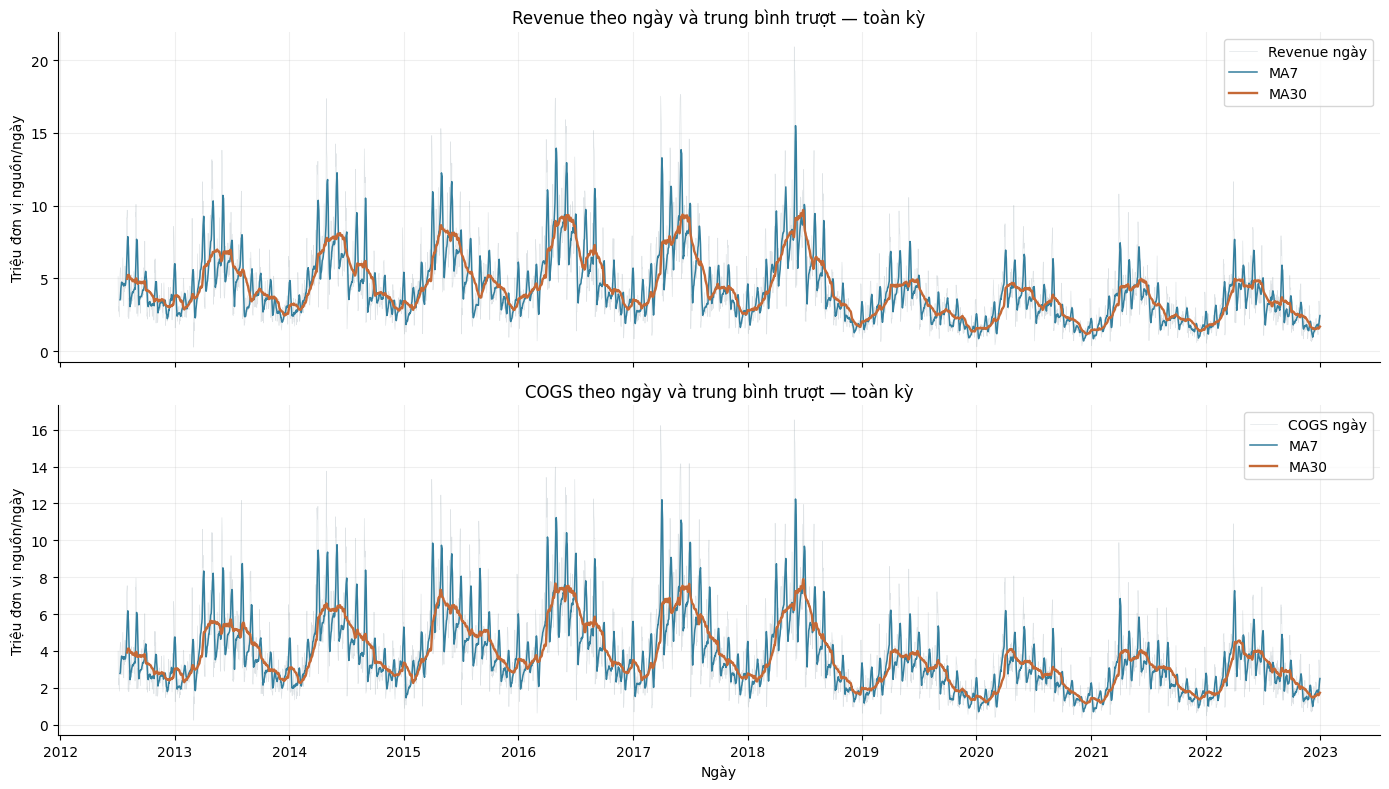

In [31]:
def trailing_decimal(values, window):
    if not isinstance(window, int) or window < 1:
        raise ValueError('Cửa sổ phải là số nguyên dương.')
    queue_values, running, result = deque(), ZERO, []
    for value in values:
        queue_values.append(value)
        running += value
        if len(queue_values) > window:
            running -= queue_values.popleft()
        result.append(running / Decimal(window) if len(queue_values) == window else None)
    return result

for metric in ['revenue', 'cogs']:
    for window in [7, 30]:
        daily_detail[f'{metric}_ma{window}'] = pd.Series(
            trailing_decimal(daily_detail[metric].to_list(), window), index=daily_detail.index, dtype=object)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, metric, title in zip(axes, ['revenue', 'cogs'], ['Revenue', 'COGS']):
    ax.plot(daily_detail.index, daily_detail[metric].map(lambda x: float(x / MILLION)),
            color='#8c9da6', alpha=.28, linewidth=.45, label=title + ' ngày')
    for window, color in [(7, '#347f9e'), (30, '#c56936')]:
        ax.plot(daily_detail.index, daily_detail[f'{metric}_ma{window}'].map(
            lambda x: float(x / MILLION) if x is not None else float('nan')),
            color=color, linewidth=1.1 if window == 7 else 1.7, label=f'MA{window}')
    ax.set(title=title + ' theo ngày và trung bình trượt — toàn kỳ', ylabel='Triệu đơn vị nguồn/ngày')
    ax.grid(alpha=.2); ax.legend(loc='upper right')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].set_xlabel('Ngày')
fig.tight_layout(); display(fig); plt.close(fig)

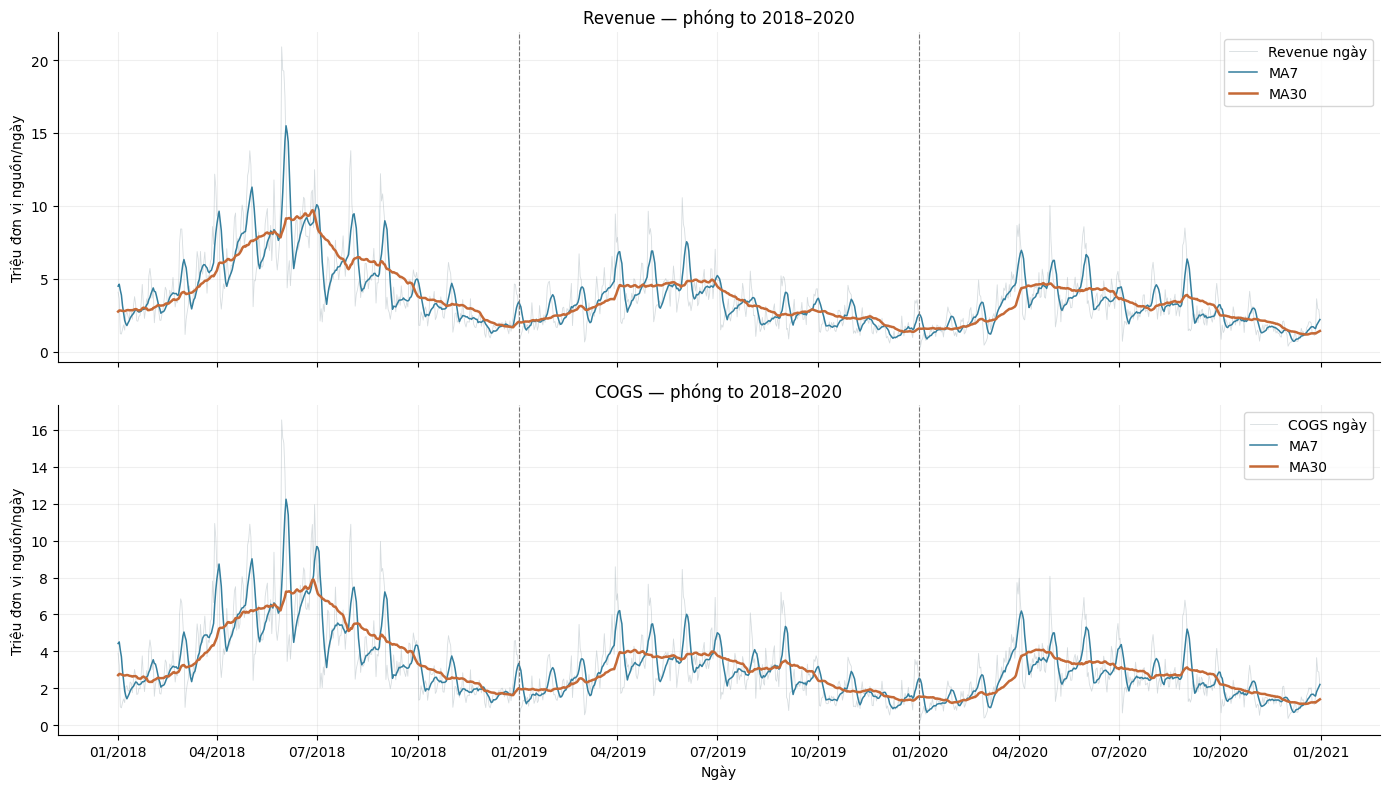

**Phân bố ngày 2018–2020 — std mẫu, CV = std/mean. Ngưỡng median 2018 dùng cố định để mô tả thay đổi quy mô.**

,Ngày,R mean (triệu),R median (triệu),R std (triệu),R CV,C mean (triệu),C median (triệu),C std (triệu),C CV,MA30 R nhỏ nhất (triệu),MA30 R lớn nhất (triệu),Ngày R < median 2018,Ngày C > R
Năm,,,,,,,,,,,,,
2018,365,"5,07","4,32","3,17","62,51%","4,23","3,60","2,59","61,41%","1,67","9,70",182,9
2019,365,"3,11","2,81","1,64","52,74%","2,75","2,46","1,44","52,32%","1,35","4,94",291,46
2020,366,"2,88","2,60","1,64","56,83%","2,42","2,14","1,37","56,46%","1,17","4,70",309,23


In [32]:
daily_focus = daily_detail.loc['2018-01-01':'2020-12-31'].copy()
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, metric, title in zip(axes, ['revenue', 'cogs'], ['Revenue', 'COGS']):
    ax.plot(daily_focus.index, daily_focus[metric].map(lambda x: float(x / MILLION)),
            color='#8c9da6', alpha=.35, linewidth=.6, label=title + ' ngày')
    for window, color in [(7, '#347f9e'), (30, '#c56936')]:
        ax.plot(daily_focus.index, daily_focus[f'{metric}_ma{window}'].map(
            lambda x: float(x / MILLION) if x is not None else float('nan')),
            color=color, linewidth=1.1 if window == 7 else 1.8, label=f'MA{window}')
    for boundary in ['2019-01-01', '2020-01-01']:
        ax.axvline(pd.Timestamp(boundary), color='#777777', linestyle='--', linewidth=.8)
    ax.set(title=title + ' — phóng to 2018–2020', ylabel='Triệu đơn vị nguồn/ngày')
    ax.grid(alpha=.2); ax.legend(loc='upper right')
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
axes[1].set_xlabel('Ngày')
fig.tight_layout(); display(fig); plt.close(fig)

daily_focus_stats, focus_day_rows = {}, []
baseline_2018_median = decimal_quantile(daily_focus.loc['2018', 'revenue'], '.5')
for year in [2018, 2019, 2020]:
    frame = daily_focus.loc[str(year)]
    record = {'Năm': year, 'Ngày': len(frame)}
    for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
        stats = decimal_stats(frame[metric])
        daily_focus_stats[(year, metric)] = stats
        for field, label in [('mean', 'mean'), ('median', 'median'), ('std', 'std')]:
            record[f'{title} {label} (triệu)'] = fmt_million(stats[field])
        record[f'{title} CV'] = fmt_pct(safe_percent(stats['std'], stats['mean']))
    record['MA30 R nhỏ nhất (triệu)'] = fmt_million(min(frame.revenue_ma30))
    record['MA30 R lớn nhất (triệu)'] = fmt_million(max(frame.revenue_ma30))
    record['Ngày R < median 2018'] = int(frame.revenue.map(lambda x: x < baseline_2018_median).sum())
    record['Ngày C > R'] = int(frame.negative_difference.sum())
    focus_day_rows.append(record)
display(Markdown('**Phân bố ngày 2018–2020 — std mẫu, CV = std/mean. Ngưỡng median 2018 dùng cố định để mô tả thay đổi quy mô.**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(focus_day_rows).set_index('Năm'))

In [33]:
# Ghép cùng ngày-tháng chỉ để mô tả; hai năm 2018/2019 đều 365 ngày.
paired_2018 = {stamp.strftime('%m-%d'): value for stamp, value in daily_detail.loc['2018', 'revenue'].items()}
paired_2019 = [(stamp, value, paired_2018[stamp.strftime('%m-%d')]) for stamp, value in daily_detail.loc['2019', 'revenue'].items()]
paired_lower_2019 = sum(current < base for _, current, base in paired_2019)
paired_rates_2019 = [(current - base) / base * HUNDRED for _, current, base in paired_2019 if base != ZERO]
display(Markdown(f'''
**Quan sát:** Revenue/ngày bình quân giảm từ **{fmt_vi(daily_focus_stats[(2018, 'revenue')]['mean'])}**
năm 2018 xuống **{fmt_vi(daily_focus_stats[(2019, 'revenue')]['mean'])}** năm 2019,
rồi **{fmt_vi(daily_focus_stats[(2020, 'revenue')]['mean'])}** năm 2020.
Median tương ứng **{fmt_vi(daily_focus_stats[(2018, 'revenue')]['median'])}**,
**{fmt_vi(daily_focus_stats[(2019, 'revenue')]['median'])}** và
**{fmt_vi(daily_focus_stats[(2020, 'revenue')]['median'])}** đơn vị nguồn.
Có **{paired_lower_2019}/{len(paired_2019)} ngày năm 2019** thấp hơn cùng ngày-tháng 2018;
median thay đổi của các cặp là **{fmt_pct(decimal_quantile(paired_rates_2019, '.5'))}**.

**Nhận xét có căn cứ:** suy giảm 2019 hiện diện trong cả mean, median và đa số ngày ghép cặp,
phù hợp với kết quả 12/12 tháng giảm YoY ở NV01.2; chưa thể quy toàn bộ mức giảm cho vài ngày riêng lẻ.
MA7 giữ nhiều dao động ngắn hơn, MA30 làm mượt các đỉnh/đáy; các đỉnh ngày cao ở 2018 không duy trì tương đương trong 2019–2020.
Std theo tiền thấp hơn ở giai đoạn có quy mô thấp chưa đủ để kết luận biến động tương đối nhỏ hơn; cần đọc cả CV.

**Giới hạn:** ghép cùng ngày-tháng không kiểm soát thứ trong tuần, giá hoặc cơ cấu; không phải ước lượng tác động nhân quả.
Năm 2020 có 366 ngày, các bình quân dùng đúng số ngày quan sát. Chưa giải thích nguyên nhân suy giảm.
'''))


**Quan sát:** Revenue/ngày bình quân giảm từ **5.068.828,65**
năm 2018 xuống **3.114.524,50** năm 2019,
rồi **2.881.180,76** năm 2020.
Median tương ứng **4.317.415,31**,
**2.811.323,63** và
**2.596.347,15** đơn vị nguồn.
Có **328/365 ngày năm 2019** thấp hơn cùng ngày-tháng 2018;
median thay đổi của các cặp là **-36,82%**.

**Nhận xét có căn cứ:** suy giảm 2019 hiện diện trong cả mean, median và đa số ngày ghép cặp,
phù hợp với kết quả 12/12 tháng giảm YoY ở NV01.2; chưa thể quy toàn bộ mức giảm cho vài ngày riêng lẻ.
MA7 giữ nhiều dao động ngắn hơn, MA30 làm mượt các đỉnh/đáy; các đỉnh ngày cao ở 2018 không duy trì tương đương trong 2019–2020.
Std theo tiền thấp hơn ở giai đoạn có quy mô thấp chưa đủ để kết luận biến động tương đối nhỏ hơn; cần đọc cả CV.

**Giới hạn:** ghép cùng ngày-tháng không kiểm soát thứ trong tuần, giá hoặc cơ cấu; không phải ước lượng tác động nhân quả.
Năm 2020 có 366 ngày, các bình quân dùng đúng số ngày quan sát. Chưa giải thích nguyên nhân suy giảm.


### 4. Những ngày COGS vượt Revenue và đối chiếu bảy tháng

Ngày âm khi $S_t<0$; tỷ lệ = số ngày âm / số ngày quan sát trong phạm vi. “Âm lớn nhất” ở đây là **chênh lệch nhỏ nhất (âm sâu nhất)**, không phải giá trị âm gần 0 nhất. Liệt kê mọi ngày đồng mức âm sâu nhất, cùng 10 ngày âm sâu nhất (đồng hạng theo ngày tăng dần).

Cộng **tất cả** chênh lệch ngày (âm, dương, 0) để ra chênh lệch tháng. Một tháng có ngày âm vẫn có thể có tổng dương; không suy số tháng âm từ số tháng chứa ngày âm. Bảng năm dùng số ngày thực quan sát; 2012 chưa đủ năm. Bảng ma trận tháng là `YYYY-MM` qua từng hàng năm, không phải kiểm chứng tính thời vụ.

Không gọi các ngày hoặc tháng này là số ngày/tháng lỗ thực tế: Revenue chưa phải doanh thu thuần, chưa xét đầy đủ chi phí và cách ghi nhận.

In [34]:
daily_negative = daily_detail.loc[daily_detail.negative_difference].copy()
daily_min_difference = daily_negative.difference.min()
daily_worst_negative = daily_negative.loc[daily_negative.difference.eq(daily_min_difference)]
daily_negative_rate = safe_percent(Decimal(len(daily_negative)), Decimal(len(daily_detail)))
display(Markdown(f'**{len(daily_negative)} ngày COGS > Revenue / {len(daily_detail)} ngày '
                 f'({fmt_pct(daily_negative_rate)}). Chênh lệch âm sâu nhất: {fmt_vi(daily_min_difference)} đơn vị nguồn.**'))
display(Markdown('**Mọi ngày cùng mức âm sâu nhất — triệu đơn vị nguồn:**'))
with pd.option_context('display.max_columns', None):
    display(daily_selected_table(daily_worst_negative))
    display(Markdown('**10 ngày chênh lệch âm sâu nhất — triệu đơn vị nguồn:**'))
    display(daily_selected_table(daily_negative.sort_values('difference', kind='stable').head(10)))

negative_by_year = daily_detail.groupby(daily_detail.index.year).agg(
    days=('revenue', 'size'), negative_days=('negative_difference', 'sum'),
    difference=('difference', 'sum'))
negative_year_display = pd.DataFrame(index=negative_by_year.index)
negative_year_display.index.name = 'Năm'
negative_year_display['Ngày quan sát'] = negative_by_year.days
negative_year_display['Ngày C > R'] = negative_by_year.negative_days
negative_year_display['Tỷ lệ ngày C > R'] = [
    fmt_pct(safe_percent(Decimal(int(r.negative_days)), Decimal(int(r.days)))) for r in negative_by_year.itertuples()]
negative_year_display['Tổng R − C (triệu)'] = negative_by_year.difference.map(fmt_million)
display(negative_year_display)

negative_by_month = daily_detail.groupby(daily_detail.index.to_period('M')).agg(
    days=('revenue', 'size'), negative_days=('negative_difference', 'sum'),
    revenue=('revenue', 'sum'), cogs=('cogs', 'sum'), difference=('difference', 'sum'))
negative_by_month['negative_sum'] = daily_negative.groupby(daily_negative.index.to_period('M')).difference.sum().reindex(
    negative_by_month.index, fill_value=ZERO)
negative_by_month['nonnegative_sum'] = negative_by_month.difference - negative_by_month.negative_sum
negative_month_matrix = pd.DataFrame(index=sorted(set(daily_detail.index.year)), columns=range(1, 13), dtype=object)
for m, r in negative_by_month.iterrows():
    negative_month_matrix.at[m.year, m.month] = int(r.negative_days)
negative_month_matrix = negative_month_matrix.map(lambda x: '—' if pd.isna(x) else str(x))
negative_month_matrix.index.name = 'Năm'
negative_month_matrix.columns = [f'T{k:02d}' for k in range(1, 13)]
display(Markdown('**Số ngày C > R theo từng tháng: 0 = có quan sát nhưng không có ngày âm; — = ngoài lịch sử nguồn.**'))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(negative_month_matrix)

negative_total_months = negative_by_month.loc[negative_by_month.difference.map(lambda x: x < ZERO)].copy()
negative_days_in_seven = int(daily_negative.index.to_period('M').isin(negative_total_months.index).sum())
negative_days_outside_seven = len(daily_negative) - negative_days_in_seven
negative_month_display = pd.DataFrame(index=negative_total_months.index.astype(str))
negative_month_display.index.name = 'Tháng tổng C > R'
negative_month_display['Ngày quan sát'] = negative_total_months.days.to_list()
negative_month_display['Ngày C > R'] = negative_total_months.negative_days.to_list()
negative_month_display['Tỷ lệ ngày C > R'] = [
    fmt_pct(safe_percent(Decimal(int(r.negative_days)), Decimal(int(r.days)))) for r in negative_total_months.itertuples()]
for field, title in [('revenue', 'Revenue'), ('cogs', 'COGS'), ('negative_sum', 'Cộng ngày âm'),
                     ('nonnegative_sum', 'Cộng ngày không âm'), ('difference', 'Tổng R − C')]:
    negative_month_display[title] = negative_total_months[field].map(fmt_million).to_list()
display(Markdown('**Đối chiếu bảy tháng có tổng chênh lệch âm — triệu đơn vị nguồn:**'))
with pd.option_context('display.max_columns', None):
    display(negative_month_display)
display(pd.DataFrame([
    {'Phạm vi ngày âm': 'Thuộc 7 tháng tổng chênh lệch âm', 'Số ngày': negative_days_in_seven},
    {'Phạm vi ngày âm': 'Ngoài 7 tháng đó', 'Số ngày': negative_days_outside_seven},
    {'Phạm vi ngày âm': 'Toàn kỳ', 'Số ngày': len(daily_negative)}]))

**382 ngày COGS > Revenue / 3833 ngày (9,97%). Chênh lệch âm sâu nhất: -2.567.311,72 đơn vị nguồn.**

**Mọi ngày cùng mức âm sâu nhất — triệu đơn vị nguồn:**

,Ngày,Revenue,COGS,R − C,Revenue ngày trước,Δ Revenue,(R − C)/R,Δ Revenue (%),Lưu ý nền Revenue
STT,,,,,,,,,
1,29/08/2015,"7,79","10,36","-2,57","8,51","-0,71","-32,94%","-8,38%",


**10 ngày chênh lệch âm sâu nhất — triệu đơn vị nguồn:**

,Ngày,Revenue,COGS,R − C,Revenue ngày trước,Δ Revenue,(R − C)/R,Δ Revenue (%),Lưu ý nền Revenue
STT,,,,,,,,,
1,29/08/2015,"7,79","10,36","-2,57","8,51","-0,71","-32,94%","-8,38%",
2,28/08/2015,"8,51","11,04","-2,54","3,56","4,94","-29,83%","138,69%",
3,30/08/2017,"6,95","9,40","-2,45","7,31","-0,36","-35,26%","-4,93%",
4,03/08/2017,"6,56","9,00","-2,44","6,24","0,32","-37,15%","5,10%",
5,02/08/2017,"6,24","8,56","-2,31","7,10","-0,86","-37,07%","-12,12%",
6,29/08/2017,"7,31","9,55","-2,25","3,64","3,67","-30,77%","101,00%",
7,31/08/2015,"7,85","10,07","-2,22","7,34","0,51","-28,22%","6,95%",
8,03/08/2013,"5,60","7,79","-2,19","7,42","-1,82","-39,06%","-24,56%",
9,02/08/2013,"7,42","9,60","-2,18","11,00","-3,58","-29,36%","-32,51%",


,Ngày quan sát,Ngày C > R,Tỷ lệ ngày C > R,Tổng R − C (triệu)
Năm,,,,
2012,181,0,"0,00%","154,04"
2013,365,45,"12,33%","191,19"
2014,365,13,"3,56%","297,24"
2015,365,55,"15,07%","224,49"
2016,366,19,"5,19%","324,08"
2017,365,47,"12,88%","216,78"
2018,365,9,"2,47%","307,95"
2019,365,46,"12,60%","131,60"
2020,366,23,"6,28%","168,43"


**Số ngày C > R theo từng tháng: 0 = có quan sát nhưng không có ngày âm; — = ngoài lịch sử nguồn.**

,T01,T02,T03,T04,T05,T06,T07,T08,T09,T10,T11,T12
Năm,,,,,,,,,,,,
2012,—,—,—,—,—,—,0,0,0,0,0,0
2013,0,0,0,0,0,0,1,31,2,0,2,9
2014,0,0,0,0,0,0,1,0,0,0,5,7
2015,0,0,0,0,0,0,0,31,1,0,8,15
2016,0,0,0,0,0,0,2,0,0,0,5,12
2017,0,0,0,0,0,0,3,31,2,0,3,8
2018,0,0,0,0,0,0,1,0,0,0,2,6
2019,0,0,0,0,0,0,2,31,2,0,5,6
2020,0,0,0,0,0,2,3,0,0,0,7,11


**Đối chiếu bảy tháng có tổng chênh lệch âm — triệu đơn vị nguồn:**

,Ngày quan sát,Ngày C > R,Tỷ lệ ngày C > R,Revenue,COGS,Cộng ngày âm,Cộng ngày không âm,Tổng R − C
Tháng tổng C > R,,,,,,,,
2013-08,31,31,"100,00%","116,27","151,95","-35,68","0,00","-35,68"
2015-08,31,31,"100,00%","119,85","158,63","-38,77","0,00","-38,77"
2017-08,31,31,"100,00%","117,30","158,81","-41,51","0,00","-41,51"
2019-08,31,31,"100,00%","81,50","109,40","-27,90","0,00","-27,90"
2021-08,31,31,"100,00%","68,28","95,65","-27,37","0,00","-27,37"
2021-12,31,23,"74,19%","50,40","51,45","-1,29","0,25","-1,04"
2022-12,31,25,"80,65%","52,45","53,49","-1,19","0,16","-1,03"


,Phạm vi ngày âm,Số ngày
0,Thuộc 7 tháng tổng chênh lệch âm,203
1,Ngoài 7 tháng đó,179
2,Toàn kỳ,382


In [35]:
def calendar_flag_runs(mask):
    mask = mask.astype(bool).sort_index()
    boundaries = mask.ne(mask.shift(fill_value=False)) | mask.index.to_series().diff().ne(pd.Timedelta(days=1))
    groups = boundaries.cumsum()
    run_frame = pd.DataFrame({'day': mask.index}, index=mask.index).loc[mask]
    return run_frame.groupby(groups.loc[mask]).agg(
        start=('day', 'min'), end=('day', 'max'), days=('day', 'size')).reset_index(drop=True)

negative_runs = calendar_flag_runs(daily_detail.negative_difference)
negative_months_with_days = int(negative_by_month.negative_days.gt(0).sum())
august_odd_months = negative_total_months.loc[
    (negative_total_months.index.month == 8) & (negative_total_months.index.year % 2 == 1)]
display(Markdown('**10 chuỗi ngày C > R liên tiếp dài nhất** (nếu cùng độ dài, ngày bắt đầu sớm hơn trước):'))
run_display = negative_runs.sort_values(['days', 'start'], ascending=[False, True]).head(10).copy()
run_display['start'] = run_display.start.dt.strftime('%d/%m/%Y')
run_display['end'] = run_display.end.dt.strftime('%d/%m/%Y')
display(run_display.rename(columns={'start': 'Ngày bắt đầu', 'end': 'Ngày kết thúc', 'days': 'Số ngày'}))
display(Markdown(f'''
**Đã quan sát và đối chiếu:** có **{len(daily_negative)} ngày âm ({fmt_pct(daily_negative_rate)})**
trong **{negative_months_with_days} tháng có ít nhất một ngày âm**, nhưng chỉ **{len(negative_total_months)} tháng có tổng âm**.
**{negative_days_in_seven} ngày âm** thuộc bảy tháng đó; **{negative_days_outside_seven} ngày âm** nằm ở các tháng tổng không âm.
Trong **{len(august_odd_months)} tháng 08 có tổng âm ở các năm lẻ 2013–2021**, cả **31/31 ngày mỗi tháng** đều âm.
Hai tháng tổng âm còn lại là **12/2021 và 12/2022**.
Chuỗi âm liên tiếp dài nhất có **{int(negative_runs.days.max())} ngày**.

**Nhận xét có căn cứ:** chênh lệch âm vừa xuất hiện ở các ngày riêng lẻ/chuỗi ngắn, vừa tồn tại suốt tháng ở một số giai đoạn.
Cộng gộp tháng có thể che các ngày âm vì ngày dương bù lại; ngược lại không được cộng riêng ngày âm để gọi là tổng chênh lệch tháng.
Bảng này chưa xác nhận lỗ thực tế.

**Giả thuyết/câu hỏi tiếp theo:** cần đối soát cơ cấu hàng, giá vốn cung cấp, ngày ghi nhận và chính sách giảm giá/hoàn tiền
ở những chuỗi kéo dài; chưa có bằng chứng xác định yếu tố nào là nguyên nhân.
'''))

**10 chuỗi ngày C > R liên tiếp dài nhất** (nếu cùng độ dài, ngày bắt đầu sớm hơn trước):

,Ngày bắt đầu,Ngày kết thúc,Số ngày
0,31/07/2013,02/09/2013,34
41,31/07/2017,02/09/2017,34
59,31/07/2019,02/09/2019,34
88,31/07/2021,02/09/2021,34
21,01/08/2015,01/09/2015,32
91,07/12/2021,18/12/2021,12
102,22/11/2022,02/12/2022,11
104,08/12/2022,18/12/2022,11
89,21/11/2021,27/11/2021,7
106,24/12/2022,30/12/2022,7



**Đã quan sát và đối chiếu:** có **382 ngày âm (9,97%)**
trong **43 tháng có ít nhất một ngày âm**, nhưng chỉ **7 tháng có tổng âm**.
**203 ngày âm** thuộc bảy tháng đó; **179 ngày âm** nằm ở các tháng tổng không âm.
Trong **5 tháng 08 có tổng âm ở các năm lẻ 2013–2021**, cả **31/31 ngày mỗi tháng** đều âm.
Hai tháng tổng âm còn lại là **12/2021 và 12/2022**.
Chuỗi âm liên tiếp dài nhất có **34 ngày**.

**Nhận xét có căn cứ:** chênh lệch âm vừa xuất hiện ở các ngày riêng lẻ/chuỗi ngắn, vừa tồn tại suốt tháng ở một số giai đoạn.
Cộng gộp tháng có thể che các ngày âm vì ngày dương bù lại; ngược lại không được cộng riêng ngày âm để gọi là tổng chênh lệch tháng.
Bảng này chưa xác nhận lỗ thực tế.

**Giả thuyết/câu hỏi tiếp theo:** cần đối soát cơ cấu hàng, giá vốn cung cấp, ngày ghi nhận và chính sách giảm giá/hoàn tiền
ở những chuỗi kéo dài; chưa có bằng chứng xác định yếu tố nào là nguyên nhân.


### 5. Các giá trị đặc biệt: IQR hồi cứu và mức tập trung theo giai đoạn

Với từng chuỗi **Revenue, COGS, ΔRevenue và ΔCOGS** riêng biệt:

$$IQR=Q_{75}-Q_{25},\qquad L=Q_{25}-1{,}5IQR,\qquad U=Q_{75}+1{,}5IQR.$$

Gắn cờ khi **nhỏ hơn $L$ hoặc lớn hơn $U$** (đúng ngưỡng không gắn cờ). Mức tiền và thay đổi ngày dùng hai phân bố khác nhau; ngày đầu không có Δ bị loại khỏi **mẫu tính phân vị Δ**, không loại khỏi dữ liệu gốc. Ngày thay đổi mạnh = ΔRevenue **hoặc** ΔCOGS vượt ngưỡng tương ứng. Chuỗi ngày mạnh là các ngày gắn cờ **liền nhau theo lịch**; chuỗi dài ≥2 là nhóm liền ngày, chuỗi dài 1 là riêng lẻ theo định nghĩa này. Đây chưa phải kiểm định cụm thống kê.

**Giới hạn:** ngưỡng dùng toàn bộ lịch sử, chỉ phục vụ **phân tích mô tả hồi cứu**; chưa hiệu chỉnh xu hướng, quy mô giai đoạn, yếu tố lịch hoặc phân bố lệch. Ngưỡng toàn kỳ có thể bỏ sót suy giảm kéo dài ở nền thấp; IQR thấp hơn 0 còn có thể không đánh dấu bất kỳ giá trị thấp dương nào. Không coi cờ là lỗi dữ liệu, không tự loại/cắt giá trị. **Không đưa các ngưỡng học từ toàn chuỗi tương lai vào quy trình dự báo**; một quy trình như vậy phải tính lại ngưỡng chỉ trên dữ liệu quá khứ tại thời điểm sử dụng và được kiểm chứng riêng.

**Ngưỡng IQR: tính chính xác Decimal, chỉ làm tròn khi hiển thị.**

,Chuỗi,Số quan sát,Q25 (triệu),Q75 (triệu),IQR (triệu),Ngưỡng dưới (triệu),Ngưỡng trên (triệu),Dưới ngưỡng,Trên ngưỡng,Tổng cờ
0,Revenue,3833,"2,47","5,35","2,88","-1,85","9,67",0,169,169
1,COGS,3833,"2,15","4,64","2,49","-1,58","8,37",0,165,165
2,ΔRevenue,3832,"-0,59","0,64","1,23","-2,43","2,49",120,95,215
3,ΔCOGS,3832,"-0,52","0,55","1,07","-2,13","2,16",120,91,211


,Ngày quan sát,Ngày có đối chiếu,Ngày mức tiền đặc biệt (R hoặc C),Ngày Δ đặc biệt (R hoặc C),Tỷ lệ ngày Δ đặc biệt
Năm,,,,,
2012,181,180,2,10,"5,56%"
2013,365,365,15,27,"7,40%"
2014,365,365,29,23,"6,30%"
2015,365,365,30,32,"8,77%"
2016,366,366,45,35,"9,56%"
2017,365,365,38,34,"9,32%"
2018,365,365,33,30,"8,22%"
2019,365,365,2,14,"3,84%"
2020,366,366,1,10,"2,73%"


**10 tháng có nhiều ngày Δ đặc biệt nhất**; cùng số ngày thì tháng sớm hơn trước:

,Ngày có đối chiếu,Ngày Δ đặc biệt,Ngày mức tiền đặc biệt,Tỷ lệ ngày Δ đặc biệt
Date,,,,
2015-05,31,8,6,"25,81%"
2018-05,31,8,7,"25,81%"
2016-04,30,7,11,"23,33%"
2016-05,31,7,10,"22,58%"
2017-05,31,7,10,"22,58%"
2014-05,31,6,6,"19,35%"
2016-08,31,6,7,"19,35%"
2018-06,30,6,9,"20,00%"
2014-04,30,5,7,"16,67%"


**10 chuỗi ngày Δ đặc biệt liên tiếp dài nhất:**

,Ngày bắt đầu,Ngày kết thúc,Số ngày
35,28/04/2014,30/04/2014,3
146,23/05/2018,25/05/2018,3
150,28/06/2018,30/06/2018,3
1,04/08/2012,05/08/2012,2
4,27/09/2012,28/09/2012,2
14,28/04/2013,29/04/2013,2
15,03/05/2013,04/05/2013,2
18,03/06/2013,04/06/2013,2
34,03/04/2014,04/04/2014,2
40,27/05/2014,28/05/2014,2


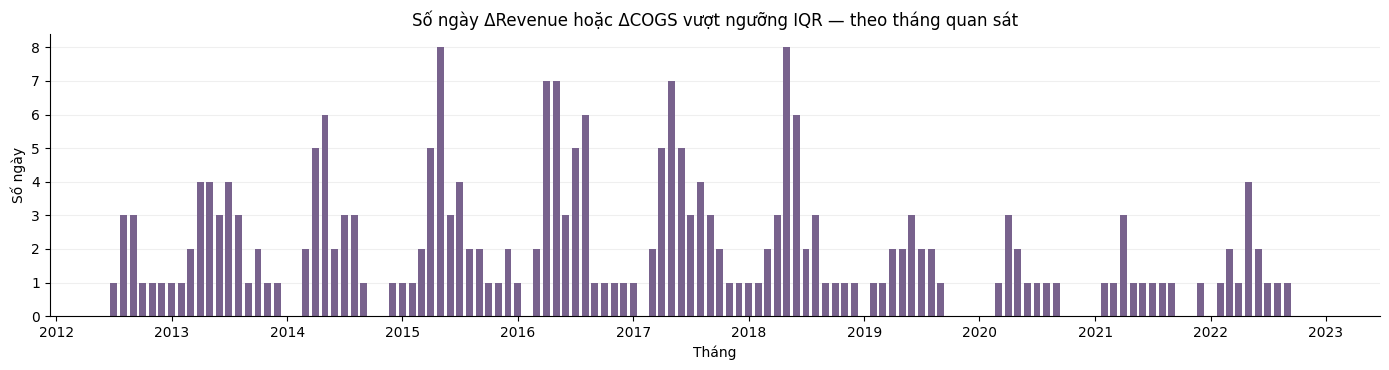

In [36]:
daily_iqr = {}
iqr_rows = []
for field, title in [('revenue', 'Revenue'), ('cogs', 'COGS'), ('revenue_delta', 'ΔRevenue'), ('cogs_delta', 'ΔCOGS')]:
    stats = daily_statistics[field] if field in daily_statistics else daily_change_statistics[field]
    q1, q3 = stats['p25'], stats['p75']
    iqr = q3 - q1
    lower, upper = q1 - Decimal('1.5') * iqr, q3 + Decimal('1.5') * iqr
    daily_iqr[field] = {'q1': q1, 'q3': q3, 'iqr': iqr, 'lower': lower, 'upper': upper}
    low = daily_detail[field].map(lambda v: v is not None and v < lower)
    high = daily_detail[field].map(lambda v: v is not None and v > upper)
    daily_detail[field + '_iqr_flag'] = low | high
    iqr_rows.append({'Chuỗi': title, 'Số quan sát': stats['n'], 'Q25 (triệu)': fmt_million(q1),
                     'Q75 (triệu)': fmt_million(q3), 'IQR (triệu)': fmt_million(iqr),
                     'Ngưỡng dưới (triệu)': fmt_million(lower), 'Ngưỡng trên (triệu)': fmt_million(upper),
                     'Dưới ngưỡng': int(low.sum()), 'Trên ngưỡng': int(high.sum()),
                     'Tổng cờ': int((low | high).sum())})
display(Markdown('**Ngưỡng IQR: tính chính xác Decimal, chỉ làm tròn khi hiển thị.**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(iqr_rows))
daily_detail['level_flag'] = daily_detail.revenue_iqr_flag | daily_detail.cogs_iqr_flag
daily_detail['change_flag'] = daily_detail.revenue_delta_iqr_flag | daily_detail.cogs_delta_iqr_flag

iqr_by_year = daily_detail.groupby(daily_detail.index.year).agg(
    days=('revenue', 'size'), comparison_days=('revenue_delta', 'count'),
    level_days=('level_flag', 'sum'), change_days=('change_flag', 'sum'))
iqr_year_display = iqr_by_year.rename(columns={
    'days': 'Ngày quan sát', 'comparison_days': 'Ngày có đối chiếu',
    'level_days': 'Ngày mức tiền đặc biệt (R hoặc C)', 'change_days': 'Ngày Δ đặc biệt (R hoặc C)'}).copy()
iqr_year_display.index.name = 'Năm'
iqr_year_display['Tỷ lệ ngày Δ đặc biệt'] = [
    fmt_pct(safe_percent(Decimal(int(r.change_days)), Decimal(int(r.comparison_days)))) for r in iqr_by_year.itertuples()]
with pd.option_context('display.max_columns', None):
    display(iqr_year_display)

iqr_by_month = daily_detail.groupby(daily_detail.index.to_period('M')).agg(
    comparison_days=('revenue_delta', 'count'), change_days=('change_flag', 'sum'), level_days=('level_flag', 'sum'))
iqr_month_display = iqr_by_month.sort_values('change_days', ascending=False, kind='stable').head(10).copy()
iqr_month_display['change_rate'] = [
    fmt_pct(safe_percent(Decimal(int(r.change_days)), Decimal(int(r.comparison_days)))) for r in iqr_month_display.itertuples()]
display(Markdown('**10 tháng có nhiều ngày Δ đặc biệt nhất**; cùng số ngày thì tháng sớm hơn trước:'))
display(iqr_month_display.rename(columns={'comparison_days': 'Ngày có đối chiếu', 'change_days': 'Ngày Δ đặc biệt',
                                          'level_days': 'Ngày mức tiền đặc biệt', 'change_rate': 'Tỷ lệ ngày Δ đặc biệt'}))

daily_change_runs = calendar_flag_runs(daily_detail.change_flag)
isolated_change_days = int(daily_change_runs.loc[daily_change_runs.days.eq(1), 'days'].sum())
cluster_change_days = int(daily_change_runs.loc[daily_change_runs.days.ge(2), 'days'].sum())
longest_change_runs = daily_change_runs.sort_values(['days', 'start'], ascending=[False, True]).head(10).copy()
display(Markdown('**10 chuỗi ngày Δ đặc biệt liên tiếp dài nhất:**'))
run_table = longest_change_runs.copy()
run_table['start'] = run_table.start.dt.strftime('%d/%m/%Y')
run_table['end'] = run_table.end.dt.strftime('%d/%m/%Y')
display(run_table.rename(columns={'start': 'Ngày bắt đầu', 'end': 'Ngày kết thúc', 'days': 'Số ngày'}))
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.bar(iqr_by_month.index.to_timestamp(), iqr_by_month.change_days, width=22, color='#78628d')
ax.set(title='Số ngày ΔRevenue hoặc ΔCOGS vượt ngưỡng IQR — theo tháng quan sát',
       xlabel='Tháng', ylabel='Số ngày')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); display(fig); plt.close(fig)

In [37]:
strong_before_2019 = int(daily_detail.loc[:'2018-12-31', 'level_flag'].sum())
strong_total = int(daily_detail.level_flag.sum())
display(Markdown(f'''
**Quan sát:** IQR đánh dấu **{int(daily_detail.revenue_iqr_flag.sum())} ngày Revenue** và
**{int(daily_detail.cogs_iqr_flag.sum())} ngày COGS** có mức tiền đặc biệt;
ngưỡng dưới của cả hai âm nên không gắn cờ thấp cho các giá trị dương trong nguồn này.
Có **{int(daily_detail.change_flag.sum())} ngày** ΔRevenue hoặc ΔCOGS đặc biệt, gồm
**{isolated_change_days} ngày riêng lẻ** và **{cluster_change_days} ngày thuộc chuỗi ≥2 ngày**.
Chuỗi Δ đặc biệt liên tiếp dài nhất **{int(daily_change_runs.days.max())} ngày**.
**{strong_before_2019}/{strong_total} ngày mức tiền đặc biệt** nằm trước 2019.

**Nhận xét có căn cứ:** ngày biến động mạnh vừa có các trường hợp riêng lẻ vừa có các chuỗi liền nhau;
mức tập trung khác nhau giữa các giai đoạn được thể hiện bằng số ngày, tỷ lệ theo năm và bảng tháng.
Cờ mức tiền tập trung nhiều trước 2019 phản ánh cả khác biệt quy mô; ít cờ sau đó không có nghĩa suy giảm 2019 là không đáng chú ý.
Mức giảm kéo dài được hỗ trợ bởi phân bố mean/median và MA30, trong khi IQR toàn kỳ chủ yếu làm nổi bật phần đuôi cao.

**Chưa xác minh:** nguyên nhân các cụm ngày mạnh, việc ghi nhận dồn ngày, cơ cấu sản phẩm hoặc thay đổi giá vốn.
Cần đối soát nguồn nghiệp vụ và chính sách ghi nhận trước khi diễn giải; không sửa hay loại các ngày được gắn cờ.
'''))


**Quan sát:** IQR đánh dấu **169 ngày Revenue** và
**165 ngày COGS** có mức tiền đặc biệt;
ngưỡng dưới của cả hai âm nên không gắn cờ thấp cho các giá trị dương trong nguồn này.
Có **239 ngày** ΔRevenue hoặc ΔCOGS đặc biệt, gồm
**174 ngày riêng lẻ** và **65 ngày thuộc chuỗi ≥2 ngày**.
Chuỗi Δ đặc biệt liên tiếp dài nhất **3 ngày**.
**192/199 ngày mức tiền đặc biệt** nằm trước 2019.

**Nhận xét có căn cứ:** ngày biến động mạnh vừa có các trường hợp riêng lẻ vừa có các chuỗi liền nhau;
mức tập trung khác nhau giữa các giai đoạn được thể hiện bằng số ngày, tỷ lệ theo năm và bảng tháng.
Cờ mức tiền tập trung nhiều trước 2019 phản ánh cả khác biệt quy mô; ít cờ sau đó không có nghĩa suy giảm 2019 là không đáng chú ý.
Mức giảm kéo dài được hỗ trợ bởi phân bố mean/median và MA30, trong khi IQR toàn kỳ chủ yếu làm nổi bật phần đuôi cao.

**Chưa xác minh:** nguyên nhân các cụm ngày mạnh, việc ghi nhận dồn ngày, cơ cấu sản phẩm hoặc thay đổi giá vốn.
Cần đối soát nguồn nghiệp vụ và chính sách ghi nhận trước khi diễn giải; không sửa hay loại các ngày được gắn cờ.


### 6. Tổng hợp nghiệp vụ và giới hạn

- **Đã xác minh bằng dữ liệu:** số ngày, phân bố Revenue/COGS, cực trị, Δ ngày, chuỗi MA7/MA30 và phân rã chênh lệch ngày/tháng được trình bày ở trên; kiểm chứng tái lập nằm ngay sau đây.
- **Diễn giải có căn cứ:** dao động ngày lớn có thể tồn tại cùng mức nền giảm kéo dài. Năm 2019 thấp hơn 2018 trên nhiều thước đo phân bố, không chỉ ở một đỉnh/đáy. Ngày âm và tháng tổng âm là hai cấp tổng hợp khác nhau.
- **Câu hỏi cần kiểm tra:** các đỉnh/đáy liên tiếp có liên quan phạm vi ngày ghi nhận hay cơ cấu hàng không? Chênh lệch âm kéo dài có còn tồn tại khi đối soát giá vốn lịch sử, trạng thái đơn và giảm giá/hoàn tiền không? Những thay đổi số lượng/giá/cơ cấu nào đi cùng giảm quy mô?
- **Chưa chứng minh:** mọi giả thuyết nguyên nhân nêu trên. Revenue chưa phải doanh thu thuần; chênh lệch chưa xác nhận lợi nhuận/lỗ thực tế. Chưa kiểm chứng tính thời vụ hoặc xây dựng mô hình, chưa thực hiện NV01.4–NV01.5.

### 7. Kiểm chứng độc lập NV01.3

Đọc lại `sales.csv` bằng `csv.DictReader`, đối chiếu toàn bộ **3.833 ngày liên tục**, ngày nhuận và số tiền Decimal, rồi cộng về **từng tháng/từng năm/V02** với sai lệch 0. Kiểm tra từng công thức chênh lệch, tỷ lệ và thay đổi ngày, các ca biên mẫu số 0/NULL/mất ngày; xác minh bảy tháng tổng âm và phân bố ngày âm.

Thống kê kiểm tra lại bằng `statistics` (phân vị `inclusive`, std mẫu). MA7/MA30 được đối chiếu từng cửa sổ với phép cộng trực tiếp từ lượt đọc CSV độc lập; kiểm thử **chạy trên tiền tố** và **thay đổi dữ liệu tương lai** để xác nhận kết quả quá khứ không đổi. Kiểm tra thứ hạng/đồng hạng, ngưỡng IQR và phân hoạch các chuỗi ngày. Tất cả ca thử chỉ ở bộ nhớ; không tạo file dữ liệu/kiểm thử phụ.

In [38]:
import statistics
from datetime import timedelta

daily_verification = []
def day_check(name, condition):
    condition = bool(condition)
    daily_verification.append({'Kiểm tra NV01.3': name, 'Đạt': condition})
    assert condition, name

daily_oracle = []
with SALES_PATH.open(encoding='utf-8-sig', newline='') as stream:
    for record in csv.DictReader(stream, strict=True):
        daily_oracle.append((date.fromisoformat(record['Date']), Decimal(record['Revenue']), Decimal(record['COGS'])))
daily_oracle.sort(key=lambda row: row[0])
oracle_days = [r[0] for r in daily_oracle]
day_check('Đủ 3.833 ngày duy nhất, liên tục 04/07/2012–31/12/2022',
          len(daily_oracle) == 3833 and len(set(oracle_days)) == 3833
          and oracle_days[0] == date(2012, 7, 4) and oracle_days[-1] == date(2022, 12, 31)
          and oracle_days == [oracle_days[0] + timedelta(days=i) for i in range(3833)]
          and list(daily_detail.index.date) == oracle_days)
day_check('Có đúng ngày 29/02/2016 và 29/02/2020',
          [d for d in oracle_days if d.month == 2 and d.day == 29] == [date(2016, 2, 29), date(2020, 2, 29)])
day_check('Mọi Revenue/COGS ngày khớp CSV độc lập, hữu hạn',
          all(daily_detail.at[pd.Timestamp(d), 'revenue'] == r and daily_detail.at[pd.Timestamp(d), 'cogs'] == c
              and r.is_finite() and c.is_finite() for d, r, c in daily_oracle))
day_check('Thống kê 0/âm/không hợp lệ khớp CSV độc lập',
          all(int(daily_quality.iloc[j]['Giá trị 0']) == sum(row[j+1] == ZERO for row in daily_oracle)
              and int(daily_quality.iloc[j]['Giá trị âm']) == sum(row[j+1] < ZERO for row in daily_oracle)
              and int(daily_quality.iloc[j]['Hữu hạn']) == len(daily_oracle)
              and all(int(daily_quality.iloc[j][field]) == 0 for field in ['NULL/rỗng', 'Không phải số', 'Không hữu hạn'])
              for j in [0, 1]))

daily_oracle_months = defaultdict(lambda: {'days': 0, 'revenue': ZERO, 'cogs': ZERO, 'difference': ZERO,
                                          'negative_days': 0, 'negative_sum': ZERO})
daily_oracle_years = defaultdict(lambda: {'days': 0, 'revenue': ZERO, 'cogs': ZERO, 'difference': ZERO})
oracle_derived = {'difference': [], 'difference_pct': [], 'revenue_delta': [], 'cogs_delta': [],
                  'revenue_change_pct': [], 'cogs_change_pct': []}
for i, (d, r, c) in enumerate(daily_oracle):
    spread = r - c
    oracle_derived['difference'].append(spread)
    oracle_derived['difference_pct'].append(spread / r * HUNDRED if r != ZERO else None)
    for j, metric in [(1, 'revenue'), (2, 'cogs')]:
        current = daily_oracle[i][j]
        previous = daily_oracle[i-1][j] if i > 0 and d - daily_oracle[i-1][0] == timedelta(days=1) else None
        delta = current - previous if previous is not None else None
        rate = delta / previous * HUNDRED if previous is not None and previous != ZERO else None
        oracle_derived[metric + '_delta'].append(delta)
        oracle_derived[metric + '_change_pct'].append(rate)
    for target in [daily_oracle_months[d.strftime('%Y-%m')], daily_oracle_years[d.year]]:
        target['days'] += 1
        target['revenue'] += r; target['cogs'] += c; target['difference'] += spread
    if spread < ZERO:
        daily_oracle_months[d.strftime('%Y-%m')]['negative_days'] += 1
        daily_oracle_months[d.strftime('%Y-%m')]['negative_sum'] += spread
day_check('Toàn bộ công thức chênh lệch/tỷ lệ/Δ tiền/% ngày đúng Decimal',
          all(daily_detail[field].to_list() == values for field, values in oracle_derived.items()))
day_check('Ngày đầu trống; 3.832 thay đổi hợp lệ, không điền trống thành 0',
          all(daily_detail.iloc[0][metric + '_' + suffix] is None
              and daily_detail[metric + '_' + suffix].notna().sum() == 3832
              for metric in ['revenue', 'cogs'] for suffix in ['delta', 'change_pct']))
day_check('Tổng mọi tháng từ ngày khớp NV01.2: ngày, Revenue, COGS, chênh lệch',
          all(daily_oracle_months[str(m)][field] == monthly.at[m, field]
              for m in monthly.index for field in ['days', 'revenue', 'cogs', 'difference']))
day_check('Tổng mọi năm từ ngày khớp NV01.1: ngày, Revenue, COGS, chênh lệch',
          all(daily_oracle_years[y][field] == annual.at[y, field]
              for y in annual.index for field in ['days', 'revenue', 'cogs', 'difference']))
day_check('Revenue/COGS toàn kỳ khớp V02 chính xác và số ngày khớp V02',
          sum((r[1] for r in daily_oracle), ZERO) == sum(daily_detail.revenue, ZERO) == v02['metrics']['sales_revenue']
          and sum((r[2] for r in daily_oracle), ZERO) == sum(daily_detail.cogs, ZERO) == v02['metrics']['sales_cogs']
          and len(daily_oracle) == v02['metrics']['sales_days'])
day_check('Ca mẫu số 0: Δ tiền vẫn tính, % trống; NULL/mất ngày trống',
          day_change(Decimal(100), ZERO) == (Decimal(100), None)
          and day_change(Decimal(100), None) == (None, None)
          and day_change(None, Decimal(100)) == (None, None)
          and day_change(Decimal(100), Decimal(50), adjacent=False) == (None, None))
day_check('Ca tử số 0, giảm về 0 và nền âm tính đúng công thức',
          day_change(Decimal(100), Decimal(100)) == (ZERO, ZERO)
          and day_change(ZERO, Decimal(100)) == (Decimal(-100), Decimal(-100))
          and day_change(Decimal(100), Decimal(-100)) == (Decimal(200), Decimal(-200)))

oracle_stat_values = {'revenue': [r[1] for r in daily_oracle], 'cogs': [r[2] for r in daily_oracle], **oracle_derived}
stat_ok = True
for field, calculated in {**daily_statistics, **daily_change_statistics}.items():
    vals = [v for v in oracle_stat_values[field] if v is not None]
    quantiles = statistics.quantiles(vals, n=100, method='inclusive')
    stat_ok &= (calculated['n'] == len(vals) and calculated['min'] == min(vals) and calculated['max'] == max(vals)
                and abs(calculated['mean'] - statistics.mean(vals)) <= Decimal('1e-18')
                and calculated['median'] == statistics.median(vals)
                and abs(calculated['std'] - statistics.stdev(vals)) <= Decimal('1e-18'))
    stat_ok &= all(abs(calculated[f'p{p:02d}'] - quantiles[p-1]) <= Decimal('1e-18') for p in [1, 5, 25, 75, 95, 99])
day_check('Mean/median/std mẫu/min/max/phân vị tái lập bằng statistics', stat_ok)
day_check('Cảnh báo nền nhỏ đúng P1 dương và đúng ngày trước',
          all(daily_small_base[metric] == statistics.quantiles([v for v in oracle_stat_values[metric] if v > ZERO],
                                                              n=100, method='inclusive')[0]
              and all((daily_detail.iloc[i][metric + '_base_note'] == 'Nền nhỏ (≤P1 dương)') ==
                      (i > 0 and ZERO < oracle_stat_values[metric][i-1] <= daily_small_base[metric])
                      for i in range(len(daily_oracle))) for metric in ['revenue', 'cogs']))
day_check('Không có NaN/vô hạn giả trong các chỉ tiêu Decimal',
          all(v is None or (isinstance(v, Decimal) and v.is_finite())
              for field in oracle_stat_values for v in daily_detail[field]))

In [39]:
ranking_ok = True
for key, title, field, ascending in ranking_specs:
    reference = [(row[0], row[1] if field == 'revenue' else row[2] if field == 'cogs'
                  else oracle_derived['revenue_delta'][i]) for i, row in enumerate(daily_oracle)]
    reference = [(d, v) for d, v in reference if v is not None
                 and (key != 'revenue_increase' or v > ZERO) and (key != 'revenue_decrease' or v < ZERO)]
    expected = sorted(reference, key=lambda pair: (pair[1] if ascending else -pair[1], pair[0]))[:10]
    ranking_ok &= list(daily_rankings[key].index.date) == [d for d, _ in expected]
day_check('Cả 5 bảng đúng top 10 theo tiền và đồng hạng theo ngày sớm', ranking_ok)
tie_fixture = pd.DataFrame({'value': [Decimal(100), Decimal(90), Decimal(100)]},
                           index=pd.to_datetime(['2020-01-03', '2020-01-01', '2020-01-02']))
day_check('Ca đồng hạng: sắp ngày trước, stable sort cắt đúng số hàng',
          tie_fixture.sort_index().sort_values('value', ascending=False, kind='stable').head(1).index[0] == pd.Timestamp('2020-01-02'))
oracle_negative_dates = [d for d, r, c in daily_oracle if r < c]
expected_negative_months = ['2013-08', '2015-08', '2017-08', '2019-08', '2021-08', '2021-12', '2022-12']
day_check('Đúng 382 ngày COGS > Revenue; tỷ lệ và ngày âm khớp CSV',
          len(oracle_negative_dates) == len(daily_negative) == 382
          and list(daily_negative.index.date) == oracle_negative_dates
          and daily_negative_rate == Decimal(382) / Decimal(3833) * HUNDRED)
day_check('Phân bố âm theo từng năm/tháng và tổng ngày âm chính xác',
          all(negative_by_month.at[pd.Period(m), 'negative_days'] == ref['negative_days']
              and negative_by_month.at[pd.Period(m), 'negative_sum'] == ref['negative_sum']
              for m, ref in daily_oracle_months.items())
          and all(negative_by_year.at[y, 'negative_days'] == sum(d.year == y for d in oracle_negative_dates)
                  for y in negative_by_year.index))
day_check('Xác minh đúng bảy tháng tổng âm, khớp NV01.2',
          [m for m, ref in sorted(daily_oracle_months.items()) if ref['difference'] < ZERO] == expected_negative_months
          and list(negative_total_months.index.astype(str)) == expected_negative_months
          and list(negative_spread.index.astype(str)) == expected_negative_months)
day_check('203 ngày âm thuộc bảy tháng; 179 ngày âm ở ngoài; không đánh đồng cấp ngày/tháng',
          negative_days_in_seven == sum(d.strftime('%Y-%m') in expected_negative_months for d in oracle_negative_dates) == 203
          and negative_days_outside_seven == 179
          and all(r.difference == r.negative_sum + r.nonnegative_sum for r in negative_by_month.itertuples()))
oracle_min_difference = min(r-c for _, r, c in daily_oracle)
day_check('Mức âm sâu nhất và mọi ngày đồng mức đúng CSV',
          daily_min_difference == oracle_min_difference
          and list(daily_worst_negative.index.date) == [d for d, r, c in daily_oracle if r-c == oracle_min_difference])

rolling_values_ok = rolling_boundary_ok = rolling_prefix_ok = rolling_future_ok = True
for metric in ['revenue', 'cogs']:
    vals = oracle_stat_values[metric]
    for window in [7, 30]:
        expected = [sum(vals[i-window+1:i+1], ZERO) / Decimal(window) if i >= window-1 else None for i in range(len(vals))]
        actual = daily_detail[f'{metric}_ma{window}'].to_list()
        rolling_values_ok &= actual == expected
        rolling_boundary_ok &= all(v is None for v in actual[:window-1]) and actual[window-1] == sum(vals[:window], ZERO) / Decimal(window)
        for cut in [100, 365, 1000]:
            rolling_prefix_ok &= trailing_decimal(vals[:cut], window) == actual[:cut]
            changed_future = vals[:cut] + [v + Decimal('1000000000') for v in vals[cut:]]
            rolling_future_ok &= trailing_decimal(changed_future, window)[:cut] == actual[:cut]
day_check('Mọi MA7/MA30 khớp cộng cửa sổ ngày quá khứ độc lập', rolling_values_ok)
day_check('MA yêu cầu đủ cửa sổ: 6/29 ngày đầu trống, mốc đầu đúng', rolling_boundary_ok)
day_check('Tính trên tiền tố cho kết quả quá khứ giống toàn chuỗi', rolling_prefix_ok)
day_check('Thay đổi toàn bộ tương lai không làm đổi MA quá khứ', rolling_future_ok)
day_check('Ca MA cửa sổ 1 và chuỗi chưa đủ cửa sổ đúng',
          trailing_decimal([Decimal(1), Decimal(3)], 1) == [Decimal(1), Decimal(3)]
          and trailing_decimal([Decimal(1), Decimal(3)], 3) == [None, None])
day_check('MA phóng to 2018 dùng quá khứ cuối 2017, không reset đầu năm',
          daily_focus.at[pd.Timestamp('2018-01-01'), 'revenue_ma30'] ==
          sum(daily_detail.loc['2017-12-03':'2018-01-01', 'revenue'], ZERO) / Decimal(30))

iqr_ok = True
for field, bounds in daily_iqr.items():
    vals = [v for v in oracle_stat_values[field] if v is not None]
    q = statistics.quantiles(vals, n=4, method='inclusive')
    lower, upper = q[0] - Decimal('1.5') * (q[2] - q[0]), q[2] + Decimal('1.5') * (q[2] - q[0])
    expected_flags = [v is not None and (v < lower or v > upper) for v in oracle_stat_values[field]]
    iqr_ok &= bounds['lower'] == lower and bounds['upper'] == upper and daily_detail[field + '_iqr_flag'].to_list() == expected_flags
day_check('Ngưỡng IQR và mọi cờ mức tiền/Δ khớp phân vị độc lập', iqr_ok)

def independent_runs(flags):
    runs, first, last, count = [], None, None, 0
    for d, flagged in zip(oracle_days, flags):
        if flagged:
            if first is None:
                first, count = d, 0
            elif d - last != timedelta(days=1):
                runs.append((first, last, count)); first, count = d, 0
            last, count = d, count + 1
        elif first is not None:
            runs.append((first, last, count)); first, last, count = None, None, 0
    if first is not None:
        runs.append((first, last, count))
    return runs

run_checks = True
for flag_field, runs in [('negative_difference', negative_runs), ('change_flag', daily_change_runs)]:
    expected = independent_runs(daily_detail[flag_field].to_list())
    actual = [(r.start.date(), r.end.date(), int(r.days)) for r in runs.itertuples()]
    run_checks &= expected == actual and int(runs.days.sum()) == int(daily_detail[flag_field].sum())
day_check('Chuỗi ngày âm/ngày Δ mạnh phân hoạch đúng lịch độc lập', run_checks)
day_check('Ngày mạnh riêng lẻ + thuộc chuỗi bằng tổng cờ, không đếm trùng',
          isolated_change_days + cluster_change_days == int(daily_detail.change_flag.sum())
          and iqr_by_year.change_days.sum() == iqr_by_month.change_days.sum() == int(daily_detail.change_flag.sum()))
day_check('Phân tích 2018–2020 đủ 1.096 ngày; ghép 2018/2019 đúng 365 cặp',
          len(daily_focus) == 1096 and len(paired_2019) == 365 and paired_lower_2019 == 328
          and all(daily_focus_stats[(y, metric)]['n'] == 365 + int(calendar.isleap(y))
                  for y in [2018, 2019, 2020] for metric in ['revenue', 'cogs']))
day_check('NV01.1 16/16 và NV01.2 25/25 vẫn đạt',
          len(verification) == 16 and all(r['Đạt'] for r in verification)
          and len(monthly_verification) == 25 and all(r['Đạt'] for r in monthly_verification))
daily_protected_after = protected_snapshot()
day_check('SHA-256 mọi nguồn, module V01–V09, báo cáo và notebook khác giữ nguyên',
          daily_protected_after == protected_before)
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(pd.DataFrame(daily_verification))

,Kiểm tra NV01.3,Đạt
0,"Đủ 3.833 ngày duy nhất, liên tục 04/07/2012–31/12/2022",True
1,Có đúng ngày 29/02/2016 và 29/02/2020,True
2,"Mọi Revenue/COGS ngày khớp CSV độc lập, hữu hạn",True
3,Thống kê 0/âm/không hợp lệ khớp CSV độc lập,True
4,Toàn bộ công thức chênh lệch/tỷ lệ/Δ tiền/% ngày đúng Decimal,True
5,"Ngày đầu trống; 3.832 thay đổi hợp lệ, không điền trống thành 0",True
6,"Tổng mọi tháng từ ngày khớp NV01.2: ngày, Revenue, COGS, chênh lệch",True
7,"Tổng mọi năm từ ngày khớp NV01.1: ngày, Revenue, COGS, chênh lệch",True
8,Revenue/COGS toàn kỳ khớp V02 chính xác và số ngày khớp V02,True
9,"Ca mẫu số 0: Δ tiền vẫn tính, % trống; NULL/mất ngày trống",True


In [40]:
day_reconciliation_rows = []
for metric, title, v02_field in [('revenue', 'Revenue', 'sales_revenue'), ('cogs', 'COGS', 'sales_cogs')]:
    total_day = sum(daily_detail[metric], ZERO)
    day_reconciliation_rows.append({
        'Chỉ tiêu': title, 'Cộng ngày': fmt_vi(total_day), 'NV01.2 cộng tháng': fmt_vi(sum(monthly[metric], ZERO)),
        'NV01.1 cộng năm': fmt_vi(sum(annual[metric], ZERO)), 'V02': fmt_vi(v02['metrics'][v02_field]),
        'Sai lệch ngày − V02': fmt_vi(total_day - v02['metrics'][v02_field])})
display(Markdown('**Đối chiếu toàn kỳ — đơn vị tiền nguồn, không chia triệu:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(day_reconciliation_rows))
assert all(item['Đạt'] for item in daily_verification)
display(Markdown(f'''
**Kết quả NV01.3:** **{fmt_vi(Decimal(len(daily_detail)), 0)} ngày**, **{len(daily_verification)}/{len(daily_verification)}
nhóm kiểm chứng đạt**; NV01.1 **16/16**, NV01.2 **25/25** vẫn đạt. Tổng ngày khớp từng tháng, từng năm và V02 với sai lệch **0,00**.
MA7/MA30 đã được đối chiếu mọi cửa sổ và thử nghiệm không dùng tương lai. Có **{len(daily_negative)} ngày âm**,
**{len(negative_total_months)} tháng tổng âm**; **{negative_days_in_seven} ngày âm** thuộc bảy tháng đó.
SHA-256 **{len(daily_protected_after)} file được bảo toàn** không đổi.

Bảng, biểu đồ và nhận xét NV01.3 được nhúng tại đây. Kết quả lần Run All bằng kernel mới được ghi trong metadata
execution_validation và output; để tái lập, chọn **Restart Kernel → Run All**. Chỉ bổ sung NV01.3,
chưa thực hiện NV01.4–NV01.5; không ghi báo cáo phụ, không sửa nguồn/module V01–V09, không commit/push.
'''))

**Đối chiếu toàn kỳ — đơn vị tiền nguồn, không chia triệu:**

,Chỉ tiêu,Cộng ngày,NV01.2 cộng tháng,NV01.1 cộng năm,V02,Sai lệch ngày − V02
0,Revenue,"16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","0,00"
1,COGS,"14.163.450.519,17","14.163.450.519,17","14.163.450.519,17","14.163.450.519,17","0,00"



**Kết quả NV01.3:** **3.833 ngày**, **33/33
nhóm kiểm chứng đạt**; NV01.1 **16/16**, NV01.2 **25/25** vẫn đạt. Tổng ngày khớp từng tháng, từng năm và V02 với sai lệch **0,00**.
MA7/MA30 đã được đối chiếu mọi cửa sổ và thử nghiệm không dùng tương lai. Có **382 ngày âm**,
**7 tháng tổng âm**; **203 ngày âm** thuộc bảy tháng đó.
SHA-256 **32 file được bảo toàn** không đổi.

Bảng, biểu đồ và nhận xét NV01.3 được nhúng tại đây. Kết quả lần Run All bằng kernel mới được ghi trong metadata
execution_validation và output; để tái lập, chọn **Restart Kernel → Run All**. Chỉ bổ sung NV01.3,
chưa thực hiện NV01.4–NV01.5; không ghi báo cáo phụ, không sửa nguồn/module V01–V09, không commit/push.


## NV01.4 — Phân tích xu hướng và tính thời vụ của Revenue và COGS

**Phạm vi:** chỉ NV01.4, dùng `data/raw/sales.csv`, kế thừa định nghĩa và kiểm chứng của NV01.1–NV01.3. Toàn bộ phần trước giữ nguyên; các ghi chú “chưa triển khai NV01.4” ở đó mô tả lần bàn giao trước. **Chưa triển khai NV01.5**, chưa xây dựng mô hình hoặc đặc trưng dự báo.

**Câu hỏi:** xu hướng dài hạn và các giai đoạn thay đổi có gì đáng chú ý? Tháng 04–06 có lặp lại ở nhiều năm không? Các thứ trong tuần có khác nhau? Mẫu hình có tương tự giữa 2013–2018 và 2019–2022 không?

Phân biệt **xu hướng quy mô dài hạn**, **mẫu hình theo lịch lặp lại**, và **dao động ngắn hạn**. Không mặc định có thời vụ. Kết quả là mô tả hồi cứu của lịch sử quan sát, chưa chứng minh nguyên nhân hay bảo đảm mẫu hình tiếp tục trong tương lai.

Đơn vị tiền nguồn **chưa xác minh loại tiền**; bảng/biểu đồ thường dùng **triệu đơn vị nguồn/ngày**. Chỉ số tương đối lấy nền năm = 100, không phải phần trăm tăng trưởng; chênh chỉ số dùng **điểm chỉ số**. `—` là chưa xác định, không phải 0.

### NV01.4.1 — Xu hướng dài hạn và các giai đoạn thay đổi

$$MA_w(t)=\frac{1}{w}\sum_{i=0}^{w-1}X_{t-i},\quad w\in\{30,90\}.$$

Chỉ dùng **ngày hiện tại và quá khứ**, yêu cầu đủ cửa sổ; 29/89 ngày đầu trống. Dữ liệu đủ lịch nên số quan sát cũng là số ngày lịch. MA90 làm mượt hơn MA30 nhưng **vẫn có thể giữ biến động theo năm và có độ trễ**; không tự coi MA90 là thành phần xu hướng đã tách sạch thời vụ.

Để hạn chế nhầm nhịp trong năm với xu hướng dài hạn, so MA90 tại **cùng ngày-tháng năm trước**, và đặt hai mốc cố định **30/06, 31/12** cạnh nhau qua các năm. Riêng 29/02 dùng 28/02 năm trước. Nếu kỳ gốc chưa có MA90 đủ cửa sổ hoặc bằng 0, tỷ lệ để trống.

Giai đoạn được liệt kê khi **cả MA90 Revenue và MA90 COGS cùng cao hơn hoặc cùng thấp hơn nền năm trước ít nhất 90 ngày lịch liên tiếp**. Ngưỡng 90 ngày là quy ước mô tả để bỏ các chuỗi ngắn, không phải kiểm định điểm gãy. “Thấp hơn cùng kỳ liên tiếp” **không đồng nghĩa giảm mỗi ngày**. Các MA và khoảng giai đoạn đều chưa phải dự báo.

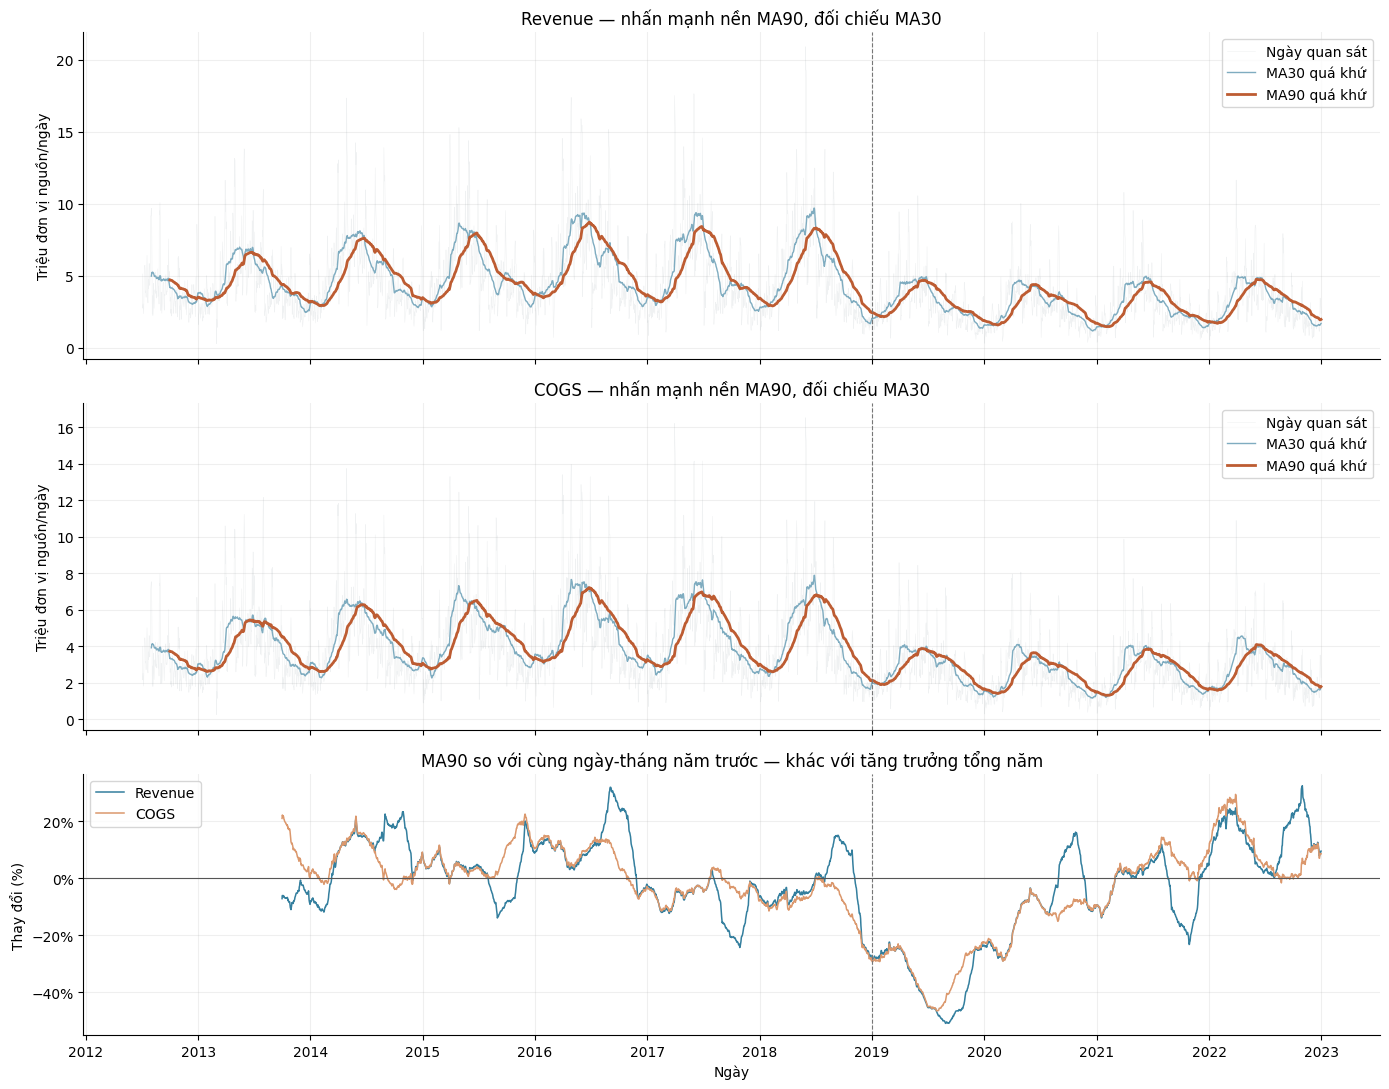

In [41]:
# Bảng riêng, không sửa daily_detail hoặc các bảng NV01.1–NV01.3.
trend_daily = daily_detail[['revenue', 'cogs']].copy()
for metric in ['revenue', 'cogs']:
    for window in [30, 90]:
        trend_daily[f'{metric}_ma{window}'] = pd.Series(
            trailing_decimal(trend_daily[metric].to_list(), window), index=trend_daily.index, dtype=object)
    rates = []
    for stamp in trend_daily.index:
        previous = stamp - pd.DateOffset(years=1)
        current = trend_daily.at[stamp, metric + '_ma90']
        base = trend_daily.at[previous, metric + '_ma90'] if previous in trend_daily.index else None
        rates.append(safe_percent(current - base, base) if current is not None and base is not None else None)
    trend_daily[metric + '_ma90_yoy'] = pd.Series(rates, index=trend_daily.index, dtype=object)

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True, gridspec_kw={'height_ratios': [1, 1, .8]})
for ax, metric, title in zip(axes[:2], ['revenue', 'cogs'], ['Revenue', 'COGS']):
    ax.plot(trend_daily.index, trend_daily[metric].map(lambda v: float(v / MILLION)),
            color='#87949b', alpha=.13, linewidth=.4, label='Ngày quan sát')
    for window, color, width in [(30, '#7facc0', 1), (90, '#bd5c32', 2)]:
        ax.plot(trend_daily.index, trend_daily[f'{metric}_ma{window}'].map(
            lambda v: float(v / MILLION) if v is not None else float('nan')),
            label=f'MA{window} quá khứ', color=color, linewidth=width)
    ax.set(title=title + ' — nhấn mạnh nền MA90, đối chiếu MA30',
           ylabel='Triệu đơn vị nguồn/ngày')
    ax.legend(loc='upper right')
for metric, title, color in [('revenue', 'Revenue', '#347f9e'), ('cogs', 'COGS', '#db986d')]:
    axes[2].plot(trend_daily.index, trend_daily[metric + '_ma90_yoy'].map(
        lambda v: float(v) if v is not None else float('nan')), label=title, color=color, linewidth=1.1)
axes[2].axhline(0, color='#555555', linewidth=.8)
axes[2].set(title='MA90 so với cùng ngày-tháng năm trước — khác với tăng trưởng tổng năm',
            ylabel='Thay đổi (%)', xlabel='Ngày')
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=100)); axes[2].legend()
for ax in axes:
    ax.axvline(pd.Timestamp('2019-01-01'), color='#777777', linestyle='--', linewidth=.8)
    ax.grid(alpha=.2)
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout(); display(fig); plt.close(fig)

In [42]:
trend_anchor_rows = []
for year in annual.index:
    row = {'Năm': int(year)}
    for suffix, month, day in [('30/06', 6, 30), ('31/12', 12, 31)]:
        stamp = pd.Timestamp(year=int(year), month=month, day=day)
        for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
            value = trend_daily.at[stamp, metric + '_ma90'] if stamp in trend_daily.index else None
            rate = trend_daily.at[stamp, metric + '_ma90_yoy'] if stamp in trend_daily.index else None
            row[f'{title} MA90 {suffix} (triệu)'] = fmt_million(value)
            if metric == 'revenue':
                row[f'{title} MA90 {suffix} cùng kỳ'] = fmt_pct(rate)
    trend_anchor_rows.append(row)
display(Markdown('**Hai mốc MA90 cố định mỗi năm — không so trực tiếp tháng 06 với tháng 12 để gọi là xu hướng năm.**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(trend_anchor_rows).set_index('Năm'))

trend_phases = {}
phase_rows = []
for direction, title in [(1, 'Cùng cao hơn nền năm trước'), (-1, 'Cùng thấp hơn nền năm trước')]:
    mask = trend_daily.revenue_ma90_yoy.map(lambda v: v is not None and v * direction > ZERO)
    mask &= trend_daily.cogs_ma90_yoy.map(lambda v: v is not None and v * direction > ZERO)
    runs = calendar_flag_runs(mask)
    selected = runs.loc[runs.days.ge(90)].copy()
    trend_phases[direction] = selected
    for r in selected.itertuples():
        phase_rows.append({'So sánh MA90': title, 'Từ ngày': r.start.strftime('%d/%m/%Y'),
            'Đến ngày': r.end.strftime('%d/%m/%Y'), 'Số ngày': int(r.days),
            'R MA90 đầu (triệu)': fmt_million(trend_daily.at[r.start, 'revenue_ma90']),
            'R MA90 cuối (triệu)': fmt_million(trend_daily.at[r.end, 'revenue_ma90'])})
display(Markdown('**Các chuỗi cùng hướng so với nền năm trước dài ít nhất 90 ngày:**'))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(pd.DataFrame(phase_rows))
trend_peak90 = trend_daily.revenue_ma90.dropna().idxmax()
trend_low90 = trend_daily.revenue_ma90.dropna().idxmin()
trend_longest_down = trend_phases[-1].sort_values(['days', 'start'], ascending=[False, True]).iloc[0]
trend_2019_june_change = trend_daily.at[pd.Timestamp('2019-06-30'), 'revenue_ma90_yoy']
trend_2022_vs2018 = safe_percent(
    trend_daily.at[pd.Timestamp('2022-06-30'), 'revenue_ma90'] - trend_daily.at[pd.Timestamp('2018-06-30'), 'revenue_ma90'],
    trend_daily.at[pd.Timestamp('2018-06-30'), 'revenue_ma90'])
display(Markdown(f'''
**Quan sát:** MA90 Revenue cao nhất **{trend_peak90:%d/%m/%Y}: {fmt_vi(trend_daily.at[trend_peak90, 'revenue_ma90'])}**,
thấp nhất **{trend_low90:%d/%m/%Y}: {fmt_vi(trend_daily.at[trend_low90, 'revenue_ma90'])}** đơn vị nguồn/ngày.
Chuỗi cả hai MA90 thấp hơn nền năm trước dài nhất: **{trend_longest_down.start:%d/%m/%Y}–{trend_longest_down.end:%d/%m/%Y}**
(**{int(trend_longest_down.days)} ngày**). MA90 Revenue tại 30/06/2019 chênh **{fmt_pct(trend_2019_june_change)}** so cùng mốc 2018.
Tại 30/06/2022, MA90 Revenue vẫn chênh **{fmt_pct(trend_2022_vs2018)}** so cùng mốc 2018.

**Nhận xét có căn cứ:** các mốc giữa năm tăng qua 2013–2016, sau đó dao động; mức nền hạ rõ ở 2019–2020,
rồi có các đoạn phục hồi tương đối trong 2021–2022 nhưng chưa trở lại nền cao trước đó tại mốc giữa năm.
Điều này phù hợp tổng năm ở NV01.1, 12/12 tháng giảm YoY năm 2019 ở NV01.2 và mean/median ngày giảm ở NV01.3.
Đỉnh MA90 có thể khác năm có tổng Revenue cao nhất vì tổng năm và cực trị cửa sổ 90 ngày đo phạm vi khác nhau.

**Giới hạn:** đường đứng 01/01/2019 chỉ đánh dấu ranh giới so sánh được yêu cầu; chưa chứng minh điểm gãy cấu trúc hoặc nguyên nhân kinh tế.
MA90 vẫn chứa nhịp trong năm, có độ trễ và không thay thế mô hình tách xu hướng/thời vụ.
'''))

**Hai mốc MA90 cố định mỗi năm — không so trực tiếp tháng 06 với tháng 12 để gọi là xu hướng năm.**

,R MA90 30/06 (triệu),R MA90 30/06 cùng kỳ,C MA90 30/06 (triệu),R MA90 31/12 (triệu),R MA90 31/12 cùng kỳ,C MA90 31/12 (triệu)
Năm,,,,,,
2012,—,—,—,"3,50",—,"2,78"
2013,"6,53",—,"5,36","3,18","-9,13%","2,79"
2014,"7,48","14,50%","6,17","3,46","9,01%","3,04"
2015,"7,80","4,37%","6,39","3,78","9,03%","3,36"
2016,"8,63","10,63%","7,16","3,68","-2,58%","3,25"
2017,"8,27","-4,23%","6,85","3,44","-6,53%","2,99"
2018,"8,28","0,17%","6,77","2,48","-27,88%","2,13"
2019,"4,56","-44,98%","3,75","1,90","-23,55%","1,66"
2020,"4,16","-8,64%","3,42","1,72","-9,38%","1,50"


**Các chuỗi cùng hướng so với nền năm trước dài ít nhất 90 ngày:**

,So sánh MA90,Từ ngày,Đến ngày,Số ngày,R MA90 đầu (triệu),R MA90 cuối (triệu)
0,Cùng cao hơn nền năm trước,12/03/2014,25/08/2014,167,"3,57","6,25"
1,Cùng cao hơn nền năm trước,02/12/2014,26/03/2015,115,"3,62","4,07"
2,Cùng cao hơn nền năm trước,01/04/2015,01/08/2015,123,"4,34","6,73"
3,Cùng cao hơn nền năm trước,05/11/2015,25/10/2016,356,"4,46","5,57"
4,Cùng cao hơn nền năm trước,01/03/2021,20/08/2021,173,"1,74","3,60"
5,Cùng cao hơn nền năm trước,02/12/2021,16/08/2022,258,"2,07","3,91"
6,Cùng cao hơn nền năm trước,03/10/2022,31/12/2022,90,"3,19","1,97"
7,Cùng thấp hơn nền năm trước,26/11/2016,20/07/2017,237,"4,43","8,02"
8,Cùng thấp hơn nền năm trước,03/09/2017,29/06/2018,300,"5,84","8,27"
9,Cùng thấp hơn nền năm trước,07/11/2018,29/08/2020,662,"4,10","3,42"



**Quan sát:** MA90 Revenue cao nhất **26/06/2016: 8.724.401,60**,
thấp nhất **03/02/2021: 1.465.741,71** đơn vị nguồn/ngày.
Chuỗi cả hai MA90 thấp hơn nền năm trước dài nhất: **07/11/2018–29/08/2020**
(**662 ngày**). MA90 Revenue tại 30/06/2019 chênh **-44,98%** so cùng mốc 2018.
Tại 30/06/2022, MA90 Revenue vẫn chênh **-45,28%** so cùng mốc 2018.

**Nhận xét có căn cứ:** các mốc giữa năm tăng qua 2013–2016, sau đó dao động; mức nền hạ rõ ở 2019–2020,
rồi có các đoạn phục hồi tương đối trong 2021–2022 nhưng chưa trở lại nền cao trước đó tại mốc giữa năm.
Điều này phù hợp tổng năm ở NV01.1, 12/12 tháng giảm YoY năm 2019 ở NV01.2 và mean/median ngày giảm ở NV01.3.
Đỉnh MA90 có thể khác năm có tổng Revenue cao nhất vì tổng năm và cực trị cửa sổ 90 ngày đo phạm vi khác nhau.

**Giới hạn:** đường đứng 01/01/2019 chỉ đánh dấu ranh giới so sánh được yêu cầu; chưa chứng minh điểm gãy cấu trúc hoặc nguyên nhân kinh tế.
MA90 vẫn chứa nhịp trong năm, có độ trễ và không thay thế mô hình tách xu hướng/thời vụ.


### NV01.4.2 — Mẫu hình tháng trong năm trên 10 năm đầy đủ

Chỉ dùng **2013–2022**, mỗi năm đủ 01/01–31/12; không đưa năm 2012 vào so sánh thời vụ.

$$\bar R_{y,m}=\frac{\sum_{d\in(y,m)}R_d}{N_{y,m}},\quad
\bar R_y=\frac{\sum_{d\in y}R_d}{N_y},\quad I^R_{y,m}=100\frac{\bar R_{y,m}}{\bar R_y}.$$

Tính tương tự cho COGS. $I>100$ = tháng có bình quân ngày cao hơn bình quân ngày **của chính năm đó**; 150 = cao hơn nền năm 50%, không phải tăng trưởng 50% so với tháng trước. Mẫu số 0 để trống.

Trung bình/trung vị theo tháng được lấy trên **10 giá trị năm-tháng**, mỗi năm có trọng số như nhau. Báo cáo std mẫu, Q25/Q75, min/max giữa các năm để đọc độ phân tán. Bình quân ngày loại ảnh hưởng trực tiếp của 28/29/30/31 ngày; bình quân năm phải lấy tổng tiền / tổng ngày, **không lấy trung bình đều của 12 bình quân tháng**.

**Giới hạn:** chuẩn hóa giảm chênh lệch quy mô năm nhưng chưa tách xu hướng trong năm, giá, cơ cấu hoặc lịch ngày lễ. Chỉ số dùng bình quân cả năm nên **chỉ dùng hồi cứu**, không dùng làm đặc trưng dự báo trước khi năm kết thúc.

In [43]:
season_years = [int(y) for y in coverage.index[coverage.full_year]]
season_months = monthly.loc[monthly.index.year.isin(season_years),
    ['days', 'calendar_days', 'full_month', 'revenue', 'cogs']].copy()
season_months['year'] = season_months.index.year
season_months['calendar_month'] = season_months.index.month
for metric in ['revenue', 'cogs']:
    season_months[metric + '_daily'] = pd.Series(
        [r[metric] / Decimal(int(r.days)) for _, r in season_months.iterrows()], index=season_months.index, dtype=object)
    season_months[metric + '_index'] = pd.Series([
        safe_percent(r[metric + '_daily'], annual.at[int(r.year), metric] / Decimal(int(annual.at[int(r.year), 'days'])))
        for _, r in season_months.iterrows()], index=season_months.index, dtype=object)

def month_profile_summary(frame, metric):
    records = []
    for k, group in frame.groupby('calendar_month', sort=True):
        amount = decimal_stats(group[metric + '_daily'])
        indices = decimal_stats(group[metric + '_index'])
        records.append({'month': int(k), 'years': len(group),
            'daily_mean': amount['mean'], 'daily_median': amount['median'], 'daily_std': amount['std'],
            'index_mean': indices['mean'], 'index_median': indices['median'], 'index_std': indices['std'],
            'index_q25': indices['p25'], 'index_q75': indices['p75'],
            'index_min': indices['min'], 'index_max': indices['max'],
            'above100': sum(v is not None and v > HUNDRED for v in group[metric + '_index'])})
    return pd.DataFrame(records).set_index('month')

season_profiles = {metric: month_profile_summary(season_months, metric) for metric in ['revenue', 'cogs']}
for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]:
    profile = season_profiles[metric]
    table = pd.DataFrame(index=profile.index)
    table.index.name = 'Tháng lịch'
    table['Số năm'] = profile.years
    for field, label in [('daily_mean', 'Mean/ngày (triệu)'), ('daily_median', 'Median/ngày (triệu)'), ('daily_std', 'Std giữa năm (triệu)')]:
        table[label] = profile[field].map(fmt_million)
    for field, label in [('index_mean', 'Chỉ số mean'), ('index_median', 'Chỉ số median'),
                         ('index_q25', 'Chỉ số Q25'), ('index_q75', 'Chỉ số Q75'),
                         ('index_min', 'Chỉ số min'), ('index_max', 'Chỉ số max')]:
        table[label] = profile[field].map(fmt_vi)
    table['Năm chỉ số >100'] = [f'{int(r.above100)}/{int(r.years)}' for r in profile.itertuples()]
    display(Markdown('**' + title + ' theo tháng — mỗi năm một quan sát:**'))
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(table)

**Revenue theo tháng — mỗi năm một quan sát:**

,Số năm,Mean/ngày (triệu),Median/ngày (triệu),Std giữa năm (triệu),Chỉ số mean,Chỉ số median,Chỉ số Q25,Chỉ số Q75,Chỉ số min,Chỉ số max,Năm chỉ số >100
Tháng lịch,,,,,,,,,,,
1,10,"2,59","2,92","0,74","60,25","58,29","56,43","63,67","52,46","75,57",0/10
2,10,"3,48","3,90","0,82","81,86","80,18","76,07","85,58","74,74","97,54",0/10
3,10,"4,93","5,19","0,96","117,16","115,75","107,97","125,45","100,50","138,44",10/10
4,10,"6,53","6,99","1,78","152,16","149,07","146,07","156,67","144,82","167,18",10/10
5,10,"6,58","7,11","1,88","152,53","150,09","148,93","159,55","139,94","167,23",10/10
6,10,"6,43","6,78","2,03","148,25","146,47","139,53","149,23","127,96","178,66",10/10
7,10,"4,66","5,40","1,33","108,03","106,23","101,90","115,41","98,79","117,76",9/10
8,10,"4,37","3,83","1,68","101,58","99,35","78,46","123,43","72,26","136,67",5/10
9,10,"3,75","3,98","0,98","87,63","88,22","84,58","90,70","77,58","99,80",0/10


**COGS theo tháng — mỗi năm một quan sát:**

,Số năm,Mean/ngày (triệu),Median/ngày (triệu),Std giữa năm (triệu),Chỉ số mean,Chỉ số median,Chỉ số Q25,Chỉ số Q75,Chỉ số min,Chỉ số max,Năm chỉ số >100
Tháng lịch,,,,,,,,,,,
1,10,"2,10","2,34","0,61","56,40","56,42","51,55","58,67","46,42","68,56",0/10
2,10,"2,83","3,11","0,67","76,55","74,25","72,11","79,60","69,65","89,54",0/10
3,10,"4,23","4,42","0,82","116,06","115,41","105,75","121,62","102,23","140,39",10/10
4,10,"5,53","5,81","1,48","148,72","148,81","141,23","154,81","137,42","162,18",10/10
5,10,"5,26","5,66","1,49","141,02","141,70","134,63","145,86","128,31","159,26",10/10
6,10,"5,39","5,67","1,69","143,64","139,74","135,40","144,69","127,38","178,57",10/10
7,10,"4,25","4,91","1,18","113,73","111,25","107,74","120,44","105,70","124,45",10/10
8,10,"4,38","4,93","1,05","118,54","118,56","113,08","121,68","108,50","130,63",10/10
9,10,"3,37","3,47","0,87","91,13","91,25","88,55","95,67","81,26","102,46",1/10


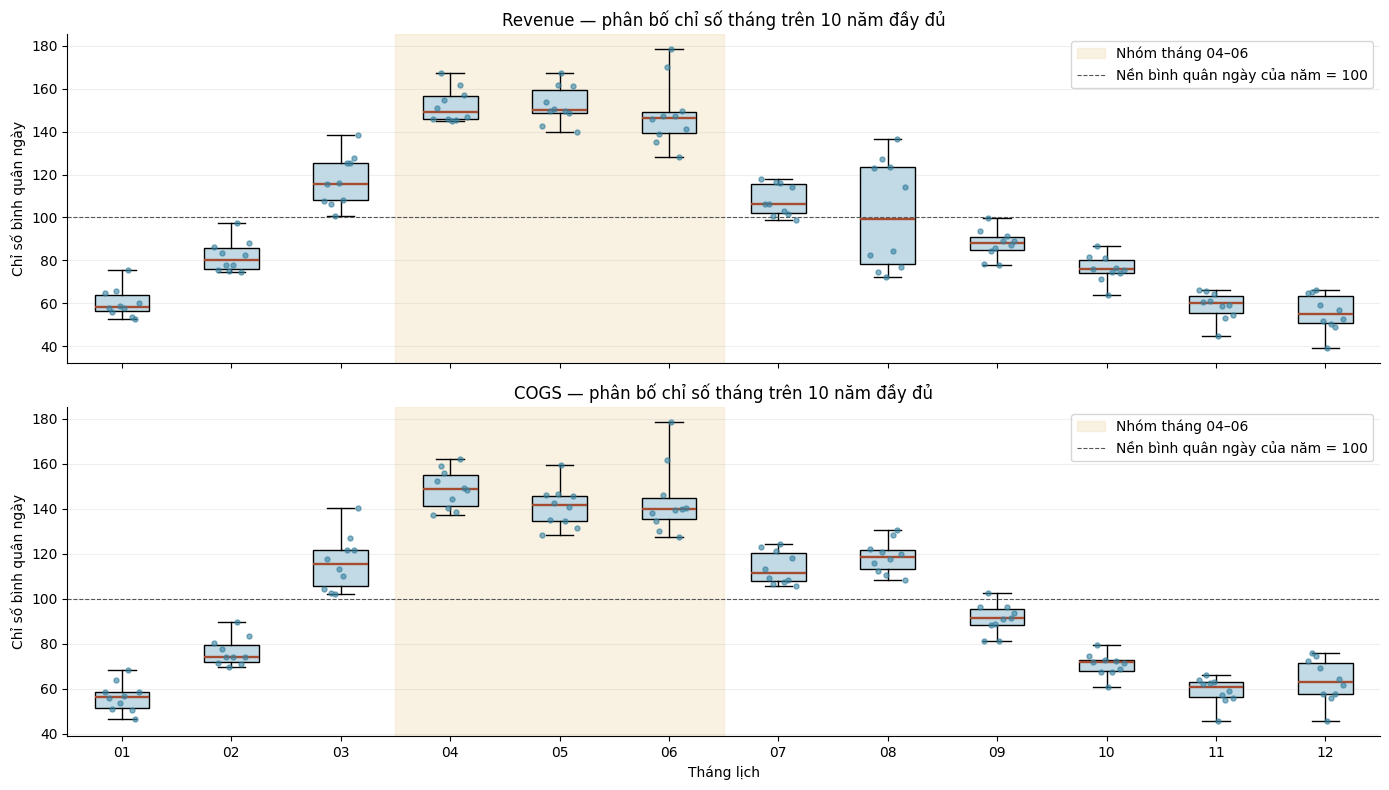

Hộp = Q25–Q75, vạch giữa = median, râu = **min–max** (không phải râu 1,5 IQR); chấm = từng năm, dịch ngang nhẹ theo năm để tránh chồng điểm. Không loại điểm ngoài hộp.

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, metric, title in zip(axes, ['revenue', 'cogs'], ['Revenue', 'COGS']):
    profile = season_profiles[metric]
    boxes = [{'label': f'{k:02d}', 'med': float(r.index_median),
              'q1': float(r.index_q25), 'q3': float(r.index_q75),
              'whislo': float(r.index_min), 'whishi': float(r.index_max), 'fliers': []}
             for k, r in profile.iterrows()]
    ax.axvspan(3.5, 6.5, color='#f0dab0', alpha=.35, label='Nhóm tháng 04–06')
    ax.bxp(boxes, positions=list(range(1, 13)), showfliers=False, patch_artist=True,
           boxprops={'facecolor': '#c2dae5'}, medianprops={'color': '#a54c30', 'linewidth': 1.7})
    for year in season_years:
        frame = season_months.loc[season_months.year.eq(year)]
        positions = frame.calendar_month.to_numpy() + (year - 2017.5) * .035
        ax.scatter(positions, frame[metric + '_index'].map(float), color='#347f9e', s=13, alpha=.6, zorder=3)
    ax.axhline(100, color='#555555', linestyle='--', linewidth=.8, label='Nền bình quân ngày của năm = 100')
    ax.set(title=title + ' — phân bố chỉ số tháng trên 10 năm đầy đủ',
           ylabel='Chỉ số bình quân ngày', xticks=range(1, 13))
    ax.grid(axis='y', alpha=.2); ax.legend(loc='upper right')
axes[1].set_xlabel('Tháng lịch')
fig.tight_layout(); display(fig); plt.close(fig)
display(Markdown('Hộp = Q25–Q75, vạch giữa = median, râu = **min–max** (không phải râu 1,5 IQR); '
                 'chấm = từng năm, dịch ngang nhẹ theo năm để tránh chồng điểm. Không loại điểm ngoài hộp.'))

In [45]:
quarter_check_rows = []
quarter_all_above = {}
peak_month_years = {}
for year in season_years:
    frame = season_months.loc[season_months.year.eq(year)]
    row = {'Năm': year}
    for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
        for k in [4, 5, 6]:
            row[f'{title} chỉ số T{k:02d}'] = fmt_vi(frame.loc[frame.calendar_month.eq(k), metric + '_index'].iloc[0])
        peak = frame[metric + '_daily'].idxmax()
        peak_month_years[(year, metric)] = int(peak.month)
        row[f'Tháng {title}/ngày cao nhất'] = int(peak.month)
    quarter_check_rows.append(row)
for metric in ['revenue', 'cogs']:
    quarter_all_above[metric] = sum(
        season_months.loc[(season_months.year.eq(y)) & season_months.calendar_month.isin([4, 5, 6]), metric + '_index'].map(
            lambda v: v is not None and v > HUNDRED).all() for y in season_years)
display(Markdown('**Kiểm tra riêng 04–06 theo từng năm — chỉ số nền năm = 100:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(quarter_check_rows).set_index('Năm'))
season_r_peak = int(season_profiles['revenue'].index_median.idxmax())
season_r_low = int(season_profiles['revenue'].index_median.idxmin())
display(Markdown(f'''
**Quan sát:** chỉ số Revenue/ngày median cao nhất ở tháng **{season_r_peak:02d}**
(**{fmt_vi(season_profiles['revenue'].at[season_r_peak, 'index_median'])}**), thấp nhất ở tháng **{season_r_low:02d}**
(**{fmt_vi(season_profiles['revenue'].at[season_r_low, 'index_median'])}**).
Cả ba tháng **04, 05, 06** đều có Revenue/ngày trên nền năm trong **{quarter_all_above['revenue']}/10 năm**;
COGS tương ứng **{quarter_all_above['cogs']}/10 năm**.
Tháng Revenue/ngày cao nhất thuộc nhóm 04–06 ở **{sum(peak_month_years[(y, 'revenue')] in [4, 5, 6] for y in season_years)}/10 năm**.

**Nhận xét có căn cứ:** đây là sự lặp lại trên nhiều năm sau chuẩn hóa số ngày và quy mô, mạnh hơn bằng chứng một tháng có tổng cao.
Tuy vậy, tháng đứng đầu có thể đổi giữa 04, 05 và 06; cường độ chỉ số cũng dao động giữa năm.
COGS có dạng tháng khác Revenue ở một số vị trí (ví dụ tháng 08), nên không suy hai mẫu hình hoàn toàn giống nhau.
Cần đọc tiếp hai giai đoạn riêng trước khi đánh giá mức độ ổn định.
'''))

**Kiểm tra riêng 04–06 theo từng năm — chỉ số nền năm = 100:**

,R chỉ số T04,R chỉ số T05,R chỉ số T06,Tháng R/ngày cao nhất,C chỉ số T04,C chỉ số T05,C chỉ số T06,Tháng C/ngày cao nhất
Năm,,,,,,,,
2013,"146,05","142,46","145,75",4,"137,42","128,31","138,02",6
2014,"151,16","153,67","135,28",5,"152,13","145,96","134,53",4
2015,"167,18","149,76","138,95",4,"159,01","135,13","130,18",4
2016,"154,84","150,41","147,20",4,"155,71","142,73","146,14",4
2017,"146,12","161,97","170,25",6,"140,16","146,67","161,75",6
2018,"144,82","167,23","178,66",6,"144,45","159,26","178,57",6
2019,"145,27","149,60","147,41",5,"138,50","134,46","139,52",6
2020,"161,93","148,71","127,96",4,"162,18","140,66","127,38",4
2021,"157,28","161,50","149,83",5,"149,34","145,55","139,96",4



**Quan sát:** chỉ số Revenue/ngày median cao nhất ở tháng **05**
(**150,09**), thấp nhất ở tháng **12**
(**54,85**).
Cả ba tháng **04, 05, 06** đều có Revenue/ngày trên nền năm trong **10/10 năm**;
COGS tương ứng **10/10 năm**.
Tháng Revenue/ngày cao nhất thuộc nhóm 04–06 ở **10/10 năm**.

**Nhận xét có căn cứ:** đây là sự lặp lại trên nhiều năm sau chuẩn hóa số ngày và quy mô, mạnh hơn bằng chứng một tháng có tổng cao.
Tuy vậy, tháng đứng đầu có thể đổi giữa 04, 05 và 06; cường độ chỉ số cũng dao động giữa năm.
COGS có dạng tháng khác Revenue ở một số vị trí (ví dụ tháng 08), nên không suy hai mẫu hình hoàn toàn giống nhau.
Cần đọc tiếp hai giai đoạn riêng trước khi đánh giá mức độ ổn định.


### NV01.4.3 — Khác biệt theo thứ trong tuần

Sắp xếp **thứ Hai → Chủ nhật**, lấy thứ trực tiếp từ ngày lịch. Mỗi nhóm tính số ngày quan sát, Revenue/ngày mean/median và COGS/ngày mean. Các chênh lệch giữa thứ được so với **thứ Hai** của cùng phạm vi để có mốc rõ ràng.

**Cuối tuần** = thứ Bảy, Chủ nhật; **ngày trong tuần** = thứ Hai–Sáu, không loại ngày lễ hoặc xác minh lịch làm việc thực tế. Bình quân mỗi nhóm = tổng tiền nhóm / số ngày nhóm, không lấy trung bình không trọng số của các thứ có số ngày khác nhau.

$$g_{CW/TT}=100\frac{\bar X_{\text{cuối tuần}}-\bar X_{\text{Hai–Sáu}}}{\bar X_{\text{Hai–Sáu}}}.$$

Ngoài toàn kỳ (bao gồm phần năm 2012), kiểm tra riêng 2013–2018 và 2019–2022. Để hạn chế khác biệt quy mô năm, tính thêm chỉ số từng thứ trong từng năm $J^X_{y,w}=100\bar X_{y,w}/\bar X_y$, rồi tổng hợp median **đều trọng số giữa các năm**. Giống chỉ số tháng, chuẩn hóa cả năm này chỉ dùng hồi cứu. Chưa điều chỉnh tháng, ngày lễ, giá hoặc cơ cấu hàng; không coi thứ trong tuần là nguyên nhân.

In [46]:
weekday_names = ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu', 'Thứ Bảy', 'Chủ nhật']
season_daily = trend_daily.loc[trend_daily.index.year.isin(season_years), ['revenue', 'cogs']].copy()
stage_years = {'2013–2018': list(range(2013, 2019)), '2019–2022': list(range(2019, 2023))}
weekday_scopes = {'Toàn kỳ 2012–2022': trend_daily[['revenue', 'cogs']]}
weekday_scopes.update({label: season_daily.loc[season_daily.index.year.isin(years)] for label, years in stage_years.items()})

def weekday_summary(frame):
    records = []
    for w in range(7):
        group = frame.loc[frame.index.dayofweek == w]
        r_stats = decimal_stats(group.revenue)
        c_stats = decimal_stats(group.cogs)
        records.append({'weekday': w, 'days': len(group), 'revenue_mean': r_stats['mean'],
                        'revenue_median': r_stats['median'], 'cogs_mean': c_stats['mean']})
    return pd.DataFrame(records).set_index('weekday')

def weekend_summary(frame):
    work = frame.loc[frame.index.dayofweek < 5]
    weekend = frame.loc[frame.index.dayofweek >= 5]
    result = {'workdays': len(work), 'weekend_days': len(weekend)}
    for metric in ['revenue', 'cogs']:
        work_mean = sum(work[metric], ZERO) / Decimal(len(work)) if len(work) else None
        weekend_mean = sum(weekend[metric], ZERO) / Decimal(len(weekend)) if len(weekend) else None
        result[metric + '_work'] = work_mean
        result[metric + '_weekend'] = weekend_mean
        result[metric + '_gap'] = safe_percent(weekend_mean - work_mean, work_mean) if work_mean is not None and weekend_mean is not None else None
    return result

weekday_profiles_raw, weekend_scopes = {}, {}
for label, frame in weekday_scopes.items():
    profile = weekday_summary(frame)
    weekday_profiles_raw[label] = profile
    weekend_scopes[label] = weekend_summary(frame)
    table = pd.DataFrame(index=weekday_names)
    table.index.name = 'Thứ'
    table['Ngày quan sát'] = profile.days.to_list()
    for field, title in [('revenue_mean', 'Revenue mean (triệu)'), ('revenue_median', 'Revenue median (triệu)'),
                         ('cogs_mean', 'COGS mean (triệu)')]:
        table[title] = profile[field].map(fmt_million).to_list()
    monday = profile.at[0, 'revenue_mean']
    table['Δ R mean so thứ Hai (triệu)'] = [fmt_million(v - monday) for v in profile.revenue_mean]
    table['Δ R mean so thứ Hai (%)'] = [fmt_pct(safe_percent(v - monday, monday)) for v in profile.revenue_mean]
    display(Markdown('**' + label + ' — số tiền/ngày theo thứ:**'))
    with pd.option_context('display.max_columns', None):
        display(table)
weekend_scope_rows = []
for label, record in weekend_scopes.items():
    weekend_scope_rows.append({'Phạm vi': label, 'Ngày Hai–Sáu': record['workdays'], 'Ngày cuối tuần': record['weekend_days'],
        'R/ngày Hai–Sáu (triệu)': fmt_million(record['revenue_work']),
        'R/ngày cuối tuần (triệu)': fmt_million(record['revenue_weekend']), 'Δ Revenue CW/TT': fmt_pct(record['revenue_gap']),
        'C/ngày Hai–Sáu (triệu)': fmt_million(record['cogs_work']),
        'C/ngày cuối tuần (triệu)': fmt_million(record['cogs_weekend']), 'Δ COGS CW/TT': fmt_pct(record['cogs_gap'])})
display(Markdown('**Cuối tuần so với thứ Hai–Sáu — bình quân có trọng số số ngày thực tế:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(weekend_scope_rows).set_index('Phạm vi'))

**Toàn kỳ 2012–2022 — số tiền/ngày theo thứ:**

,Ngày quan sát,Revenue mean (triệu),Revenue median (triệu),COGS mean (triệu),Δ R mean so thứ Hai (triệu),Δ R mean so thứ Hai (%)
Thứ,,,,,,
Thứ Hai,547,"4,31","3,85","3,71","0,00","0,00%"
Thứ Ba,547,"4,47","3,93","3,84","0,15","3,57%"
Thứ Tư,548,"4,68","3,93","4,03","0,37","8,56%"
Thứ Năm,548,"4,52","3,63","3,91","0,21","4,92%"
Thứ Sáu,548,"4,05","3,36","3,49","-0,26","-6,14%"
Thứ Bảy,548,"3,91","3,38","3,37","-0,40","-9,38%"
Chủ nhật,547,"4,07","3,60","3,51","-0,24","-5,50%"


**2013–2018 — số tiền/ngày theo thứ:**

,Ngày quan sát,Revenue mean (triệu),Revenue median (triệu),COGS mean (triệu),Δ R mean so thứ Hai (triệu),Δ R mean so thứ Hai (%)
Thứ,,,,,,
Thứ Hai,313,"5,14","4,59","4,43","0,00","0,00%"
Thứ Ba,313,"5,40","4,95","4,64","0,26","5,04%"
Thứ Tư,313,"5,66","4,80","4,86","0,52","10,09%"
Thứ Năm,313,"5,43","4,48","4,69","0,29","5,62%"
Thứ Sáu,313,"4,84","4,05","4,19","-0,30","-5,89%"
Thứ Bảy,313,"4,69","4,07","4,05","-0,45","-8,80%"
Chủ nhật,313,"4,88","4,43","4,20","-0,26","-5,03%"


**2019–2022 — số tiền/ngày theo thứ:**

,Ngày quan sát,Revenue mean (triệu),Revenue median (triệu),COGS mean (triệu),Δ R mean so thứ Hai (triệu),Δ R mean so thứ Hai (%)
Thứ,,,,,,
Thứ Hai,208,"3,09","2,92","2,69","0,00","0,00%"
Thứ Ba,209,"3,05","2,91","2,67","-0,04","-1,19%"
Thứ Tư,209,"3,26","2,93","2,86","0,18","5,69%"
Thứ Năm,209,"3,17","2,91","2,78","0,09","2,79%"
Thứ Sáu,209,"2,85","2,51","2,49","-0,24","-7,75%"
Thứ Bảy,209,"2,75","2,41","2,41","-0,34","-10,93%"
Chủ nhật,208,"2,92","2,66","2,55","-0,17","-5,46%"


**Cuối tuần so với thứ Hai–Sáu — bình quân có trọng số số ngày thực tế:**

,Ngày Hai–Sáu,Ngày cuối tuần,R/ngày Hai–Sáu (triệu),R/ngày cuối tuần (triệu),Δ Revenue CW/TT,C/ngày Hai–Sáu (triệu),C/ngày cuối tuần (triệu),Δ COGS CW/TT
Phạm vi,,,,,,,,
Toàn kỳ 2012–2022,2738,1095,"4,41","3,99","-9,42%","3,80","3,44","-9,34%"
2013–2018,1565,626,"5,30","4,79","-9,60%","4,56","4,13","-9,58%"
2019–2022,1044,417,"3,09","2,84","-8,12%","2,70","2,48","-7,99%"


**Kiểm tra từng năm đầy đủ — tránh chỉ dựa vào bình quân toàn kỳ:**

,Ngày Hai–Sáu,Ngày cuối tuần,R/ngày Hai–Sáu (triệu),R/ngày cuối tuần (triệu),Δ R cuối tuần,Δ C cuối tuần,Thứ R mean cao nhất,Thứ R mean thấp nhất
Năm,,,,,,,,
2013,261,104,"4,70","4,13","-12,22%","-11,22%",Thứ Tư,Thứ Bảy
2014,261,104,"5,24","4,85","-7,46%","-7,31%",Thứ Tư,Thứ Sáu
2015,261,104,"5,29","4,91","-7,12%","-6,96%",Thứ Tư,Thứ Bảy
2016,261,105,"5,94","5,28","-11,18%","-11,38%",Thứ Năm,Thứ Bảy
2017,260,105,"5,41","4,81","-11,06%","-12,02%",Thứ Năm,Chủ nhật
2018,261,104,"5,20","4,75","-8,71%","-8,48%",Thứ Tư,Chủ nhật
2019,261,104,"3,15","3,02","-4,36%","-3,62%",Thứ Tư,Thứ Sáu
2020,262,104,"2,95","2,71","-8,08%","-8,33%",Thứ Tư,Thứ Bảy
2021,261,104,"2,99","2,52","-15,56%","-15,56%",Thứ Năm,Thứ Bảy


**Chỉ số thứ / nền bình quân ngày của chính năm = 100; mỗi năm một trọng số:**

,R median 2013–2018,R median 2019–2022,Δ chỉ số R sau − trước,C median 2013–2018,C median 2019–2022,Δ chỉ số C sau − trước
Thứ,,,,,,
Thứ Hai,"98,72","102,94","4,22","98,74","102,74","4,00"
Thứ Ba,"104,55","102,51","-2,04","103,78","101,96","-1,82"
Thứ Tư,"109,69","108,52","-1,17","109,54","108,25","-1,29"
Thứ Năm,"105,07","103,28","-1,79","105,18","103,38","-1,80"
Thứ Sáu,"93,58","94,61","1,03","94,31","94,90","0,59"
Thứ Bảy,"90,22","91,69","1,47","90,89","91,86","0,98"
Chủ nhật,"93,52","98,74","5,22","93,41","98,52","5,12"


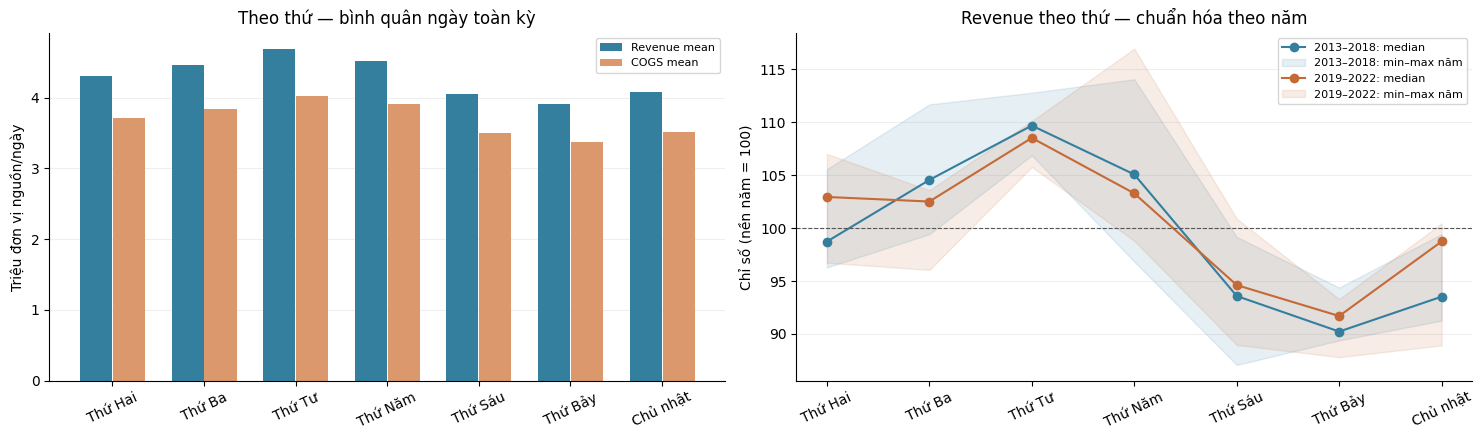

In [47]:
weekday_year_records, weekend_year_rows = [], []
weekend_by_year = {}
for year in season_years:
    frame = season_daily.loc[season_daily.index.year == year]
    profile = weekday_summary(frame)
    for w, record in profile.iterrows():
        result = {'year': year, 'weekday': int(w), 'days': int(record.days)}
        for metric in ['revenue', 'cogs']:
            result[metric + '_index'] = safe_percent(
                record[metric + '_mean'], annual.at[year, metric] / Decimal(int(annual.at[year, 'days'])))
        weekday_year_records.append(result)
    weekend = weekend_summary(frame)
    weekend_by_year[year] = weekend
    weekend_year_rows.append({'Năm': year, 'Ngày Hai–Sáu': weekend['workdays'], 'Ngày cuối tuần': weekend['weekend_days'],
        'R/ngày Hai–Sáu (triệu)': fmt_million(weekend['revenue_work']),
        'R/ngày cuối tuần (triệu)': fmt_million(weekend['revenue_weekend']),
        'Δ R cuối tuần': fmt_pct(weekend['revenue_gap']), 'Δ C cuối tuần': fmt_pct(weekend['cogs_gap']),
        'Thứ R mean cao nhất': weekday_names[int(profile.revenue_mean.idxmax())],
        'Thứ R mean thấp nhất': weekday_names[int(profile.revenue_mean.idxmin())]})
weekday_year_indices = pd.DataFrame(weekday_year_records)
display(Markdown('**Kiểm tra từng năm đầy đủ — tránh chỉ dựa vào bình quân toàn kỳ:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(weekend_year_rows).set_index('Năm'))

weekday_relative_profiles = {}
for label, years in stage_years.items():
    frame = weekday_year_indices.loc[weekday_year_indices.year.isin(years)]
    for metric in ['revenue', 'cogs']:
        records = []
        for w, group in frame.groupby('weekday', sort=True):
            stats = decimal_stats(group[metric + '_index'])
            records.append({'weekday': int(w), 'median': stats['median'], 'min': stats['min'], 'max': stats['max'], 'years': len(group)})
        weekday_relative_profiles[(label, metric)] = pd.DataFrame(records).set_index('weekday')
weekday_relative_display = pd.DataFrame(index=weekday_names)
weekday_relative_display.index.name = 'Thứ'
for metric, title in [('revenue', 'R'), ('cogs', 'C')]:
    pre = weekday_relative_profiles[('2013–2018', metric)]
    post = weekday_relative_profiles[('2019–2022', metric)]
    weekday_relative_display[f'{title} median 2013–2018'] = pre['median'].map(fmt_vi).to_list()
    weekday_relative_display[f'{title} median 2019–2022'] = post['median'].map(fmt_vi).to_list()
    weekday_relative_display[f'Δ chỉ số {title} sau − trước'] = [fmt_vi(post.at[w, 'median'] - pre.at[w, 'median']) for w in range(7)]
display(Markdown('**Chỉ số thứ / nền bình quân ngày của chính năm = 100; mỗi năm một trọng số:**'))
with pd.option_context('display.max_columns', None):
    display(weekday_relative_display)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
all_weekdays = weekday_profiles_raw['Toàn kỳ 2012–2022']
for metric, title, color, offset in [('revenue', 'Revenue mean', '#347f9e', -.18), ('cogs', 'COGS mean', '#db986d', .18)]:
    axes[0].bar([w + offset for w in range(7)], all_weekdays[metric + '_mean'].map(lambda v: float(v / MILLION)),
                width=.35, color=color, label=title)
axes[0].set(title='Theo thứ — bình quân ngày toàn kỳ', ylabel='Triệu đơn vị nguồn/ngày', xticks=range(7), xticklabels=weekday_names)
for label, color in [('2013–2018', '#347f9e'), ('2019–2022', '#c56936')]:
    profile = weekday_relative_profiles[(label, 'revenue')]
    axes[1].plot(range(7), profile['median'].map(float), marker='o', label=label + ': median', color=color)
    axes[1].fill_between(range(7), profile['min'].map(float).to_numpy(), profile['max'].map(float).to_numpy(),
                         alpha=.12, color=color, label=label + ': min–max năm')
axes[1].axhline(100, color='#555555', linestyle='--', linewidth=.8)
axes[1].set(title='Revenue theo thứ — chuẩn hóa theo năm', ylabel='Chỉ số (nền năm = 100)', xticks=range(7), xticklabels=weekday_names)
for ax in axes:
    ax.tick_params(axis='x', labelrotation=25)
    ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True); ax.legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)

In [48]:
weekend_lower_years = sum(r['revenue_gap'] is not None and r['revenue_gap'] < ZERO for r in weekend_by_year.values())
weekend_min_gap = min(r['revenue_gap'] for r in weekend_by_year.values())
weekend_max_gap = max(r['revenue_gap'] for r in weekend_by_year.values())
weekday_full_high = int(all_weekdays.revenue_mean.idxmax())
weekday_full_low = int(all_weekdays.revenue_mean.idxmin())
weekday_full_range = all_weekdays.revenue_mean.max() - all_weekdays.revenue_mean.min()
display(Markdown(f'''
**Quan sát:** toàn kỳ, Revenue/ngày mean cao nhất ở **{weekday_names[weekday_full_high]}**,
thấp nhất ở **{weekday_names[weekday_full_low]}**; chênh tiền giữa hai thứ là **{fmt_vi(weekday_full_range)}** đơn vị nguồn/ngày.
Cuối tuần so với thứ Hai–Sáu chênh **{fmt_pct(weekend_scopes['Toàn kỳ 2012–2022']['revenue_gap'])}** về Revenue/ngày.
Dấu chênh cuối tuần âm ở **{weekend_lower_years}/10 năm đầy đủ**, với khoảng chênh
**{fmt_pct(weekend_min_gap)} đến {fmt_pct(weekend_max_gap)}**.
Theo giai đoạn, Revenue/ngày cuối tuần chênh **{fmt_pct(weekend_scopes['2013–2018']['revenue_gap'])}**
ở 2013–2018 và **{fmt_pct(weekend_scopes['2019–2022']['revenue_gap'])}** ở 2019–2022.

**Nhận xét có căn cứ:** dấu cuối tuần thấp hơn lặp lại qua các năm và cả hai giai đoạn,
nhưng cường độ dao động; thứ có mean cao/thấp nhất cũng thay đổi ở từng năm.
Chuẩn hóa theo năm giúp giảm khác biệt quy mô, chưa kiểm soát đồng thời tháng, ngày lễ và xu hướng trong năm.
**Chưa chứng minh:** tác động nhân quả của thứ trong tuần hoặc nguyên nhân khác biệt; dữ liệu không xác nhận lịch làm việc/ngày lễ.
'''))


**Quan sát:** toàn kỳ, Revenue/ngày mean cao nhất ở **Thứ Tư**,
thấp nhất ở **Thứ Bảy**; chênh tiền giữa hai thứ là **773.484,00** đơn vị nguồn/ngày.
Cuối tuần so với thứ Hai–Sáu chênh **-9,42%** về Revenue/ngày.
Dấu chênh cuối tuần âm ở **10/10 năm đầy đủ**, với khoảng chênh
**-15,56% đến -4,36%**.
Theo giai đoạn, Revenue/ngày cuối tuần chênh **-9,60%**
ở 2013–2018 và **-8,12%** ở 2019–2022.

**Nhận xét có căn cứ:** dấu cuối tuần thấp hơn lặp lại qua các năm và cả hai giai đoạn,
nhưng cường độ dao động; thứ có mean cao/thấp nhất cũng thay đổi ở từng năm.
Chuẩn hóa theo năm giúp giảm khác biệt quy mô, chưa kiểm soát đồng thời tháng, ngày lễ và xu hướng trong năm.
**Chưa chứng minh:** tác động nhân quả của thứ trong tuần hoặc nguyên nhân khác biệt; dữ liệu không xác nhận lịch làm việc/ngày lễ.


### NV01.4.4 — Tính ổn định giữa 2013–2018 và 2019–2022

Hai nhóm có **6 năm và 4 năm đầy đủ**, không chồng lặp, bao phủ toàn bộ 2013–2022. So **median chỉ số tháng qua các năm**, mỗi năm cùng trọng số; thứ hạng giảm dần, **hạng 1 cao nhất**, đồng hạng dùng hạng trung bình. Chênh median ghi **điểm chỉ số**, không phải % tăng trưởng.

Bổ sung **tương quan thứ hạng Spearman** giữa hai bộ 12 median tháng: tương quan Pearson của hai vector hạng trung bình. Giá trị gần 1 biểu thị thứ tự cao/thấp tương tự; **không đo sự bằng nhau của mức tiền hoặc cường độ**, không phải kiểm định nhân quả/điểm gãy. Chỉ có 12 vị trí tháng và 6/4 năm, không coi đây là 12 quan sát độc lập để suy ra ý nghĩa thống kê. Không báo p-value.

In [49]:
stage_month_profiles, stage_rank_rho = {}, {}
def rank_correlation(left, right):
    pairs = [(a, b) for a, b in zip(left, right) if a is not None and b is not None]
    if len(pairs) < 2:
        return None
    xs, ys = zip(*pairs)
    mx, my = sum(xs, ZERO) / Decimal(len(xs)), sum(ys, ZERO) / Decimal(len(ys))
    cross = sum(((x-mx) * (y-my) for x, y in pairs), ZERO)
    denom = (sum(((x-mx)**2 for x in xs), ZERO) * sum(((y-my)**2 for y in ys), ZERO)).sqrt()
    return cross / denom if denom != ZERO else None

for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]:
    for label, years in stage_years.items():
        profile = month_profile_summary(season_months.loc[season_months.year.isin(years)], metric)
        profile['rank'] = profile.index_median.rank(method='average', ascending=False).map(lambda v: Decimal(str(v)))
        stage_month_profiles[(label, metric)] = profile
    pre, post = stage_month_profiles[('2013–2018', metric)], stage_month_profiles[('2019–2022', metric)]
    stage_rank_rho[metric] = rank_correlation(pre['rank'], post['rank'])
    table = pd.DataFrame(index=range(1, 13))
    table.index.name = 'Tháng lịch'
    for label, profile in [('2013–2018', pre), ('2019–2022', post)]:
        table['Median ' + label] = profile.index_median.map(fmt_vi)
        table['Hạng ' + label] = profile['rank'].map(lambda v: fmt_vi(v, 1))
        table['Trên nền ' + label] = [f'{int(r.above100)}/{int(r.years)}' for r in profile.itertuples()]
    table['Δ median sau − trước (điểm)'] = [fmt_vi(post.at[k, 'index_median'] - pre.at[k, 'index_median']) for k in range(1, 13)]
    display(Markdown('**' + title + ' — so sánh chỉ số tương đối và thứ hạng:**'))
    with pd.option_context('display.max_rows', None, 'display.max_columns', None):
        display(table)
display(pd.DataFrame([{'Chỉ tiêu': title, 'Spearman thứ hạng tháng': fmt_vi(stage_rank_rho[metric], 4)}
                      for metric, title in [('revenue', 'Revenue'), ('cogs', 'COGS')]]))

stage_overview_rows = []
for label, years in stage_years.items():
    frame = season_daily.loc[season_daily.index.year.isin(years)]
    months = season_months.loc[season_months.year.isin(years)]
    quarter = months.loc[months.calendar_month.isin([4, 5, 6])]
    stage_overview_rows.append({'Giai đoạn': label, 'Số năm': len(years), 'Số ngày': len(frame),
        'R mean/ngày (triệu)': fmt_million(sum(frame.revenue, ZERO) / Decimal(len(frame))),
        'C mean/ngày (triệu)': fmt_million(sum(frame.cogs, ZERO) / Decimal(len(frame))),
        'T04–06 R trên nền năm': f'{int(quarter.revenue_index.map(lambda v: v > HUNDRED).sum())}/{len(quarter)}',
        'T04–06 C trên nền năm': f'{int(quarter.cogs_index.map(lambda v: v > HUNDRED).sum())}/{len(quarter)}',
        'R cuối tuần so Hai–Sáu': fmt_pct(weekend_scopes[label]['revenue_gap']),
        'C cuối tuần so Hai–Sáu': fmt_pct(weekend_scopes[label]['cogs_gap'])})
display(Markdown('**Quy mô tiền và mẫu hình tương đối — hai khía cạnh cần đọc riêng:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(stage_overview_rows).set_index('Giai đoạn'))

**Revenue — so sánh chỉ số tương đối và thứ hạng:**

,Median 2013–2018,Hạng 2013–2018,Trên nền 2013–2018,Median 2019–2022,Hạng 2019–2022,Trên nền 2019–2022,Δ median sau − trước (điểm)
Tháng lịch,,,,,,,
1,"58,29","12,0",0/6,"56,75","10,0",0/4,"-1,55"
2,"77,75","9,0",0/6,"85,37","8,0",0/4,"7,62"
3,"108,06","5,0",6/6,"126,70","4,0",4/4,"18,64"
4,"148,64","2,0",6/6,"152,13","1,0",4/4,"3,49"
5,"152,04","1,0",6/6,"149,16","2,0",4/4,"-2,89"
6,"146,47","3,0",6/6,"144,33","3,0",4/4,"-2,14"
7,"111,14","4,0",6/6,"102,24","5,0",3/4,"-8,89"
8,"102,72","6,0",3/6,"99,35","6,0",2/4,"-3,37"
9,"85,02","7,0",0/6,"89,17","7,0",0/4,"4,15"


**COGS — so sánh chỉ số tương đối và thứ hạng:**

,Median 2013–2018,Hạng 2013–2018,Trên nền 2013–2018,Median 2019–2022,Hạng 2019–2022,Trên nền 2019–2022,Δ median sau − trước (điểm)
Tháng lịch,,,,,,,
1,"56,42","12,0",0/6,"54,65","12,0",0/4,"-1,77"
2,"74,25","8,0",0/6,"78,79","8,0",0/4,"4,55"
3,"107,17","6,0",6/6,"124,37","4,0",4/4,"17,19"
4,"148,29","1,0",6/6,"148,81","1,0",4/4,"0,52"
5,"144,34","2,0",6/6,"137,56","3,0",4/4,"-6,78"
6,"142,08","3,0",6/6,"139,74","2,0",4/4,"-2,34"
7,"117,15","4,0",6/6,"107,94","6,0",4/4,"-9,20"
8,"116,66","5,0",6/6,"123,90","5,0",4/4,"7,24"
9,"88,67","7,0",1/6,"92,56","7,0",0/4,"3,90"


,Chỉ tiêu,Spearman thứ hạng tháng
0,Revenue,"0,9580"
1,COGS,"0,9650"


**Quy mô tiền và mẫu hình tương đối — hai khía cạnh cần đọc riêng:**

,Số năm,Số ngày,R mean/ngày (triệu),C mean/ngày (triệu),T04–06 R trên nền năm,T04–06 C trên nền năm,R cuối tuần so Hai–Sáu,C cuối tuần so Hai–Sáu
Giai đoạn,,,,,,,,
2013–2018,6,2191,"5,15","4,44",18/18,18/18,"-9,60%","-9,58%"
2019–2022,4,1461,"3,01","2,64",12/12,12/12,"-8,12%","-7,99%"


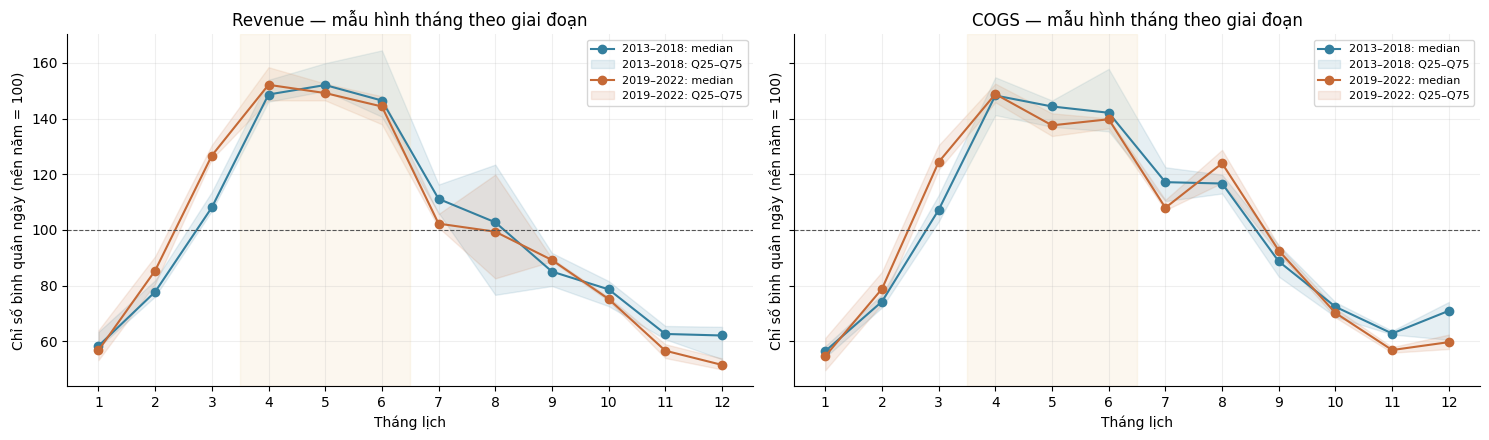

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, metric, title in zip(axes, ['revenue', 'cogs'], ['Revenue', 'COGS']):
    for label, color in [('2013–2018', '#347f9e'), ('2019–2022', '#c56936')]:
        profile = stage_month_profiles[(label, metric)]
        ax.plot(profile.index, profile.index_median.map(float), color=color, marker='o', label=label + ': median')
        ax.fill_between(profile.index, profile.index_q25.map(float).to_numpy(), profile.index_q75.map(float).to_numpy(),
                         color=color, alpha=.12, label=label + ': Q25–Q75')
    ax.axhline(100, color='#555555', linestyle='--', linewidth=.8)
    ax.axvspan(3.5, 6.5, color='#f0dab0', alpha=.2)
    ax.set(title=title + ' — mẫu hình tháng theo giai đoạn', xlabel='Tháng lịch',
           ylabel='Chỉ số bình quân ngày (nền năm = 100)', xticks=range(1, 13))
    ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)

### NV01.4.5 — Đánh giá mức độ bằng chứng

Ba cách diễn giải được cân nhắc: (1) có biến động theo lịch nhưng bằng chứng ổn định còn hạn chế; (2) mẫu hình lặp lại tương đối nhất quán; (3) chưa tìm thấy mẫu hình rõ hoặc khác nhiều giữa các giai đoạn. Đánh giá riêng cho từng khía cạnh, không dùng một đỉnh đơn lẻ hay một hệ số để quyết định.

Những thước đo dưới đây mô tả độ lặp lại trong dữ liệu đã có; chưa phải kiểm định tính dừng, mô hình tách thành phần hay đánh giá dự báo ngoài mẫu.

In [51]:
pre_ranks = stage_month_profiles[('2013–2018', 'revenue')]['rank']
post_ranks = stage_month_profiles[('2019–2022', 'revenue')]['rank']
same_ranks = int(pre_ranks.eq(post_ranks).sum())
weekday_peak_counts = pd.Series([row['Thứ R mean cao nhất'] for row in weekend_year_rows]).value_counts()
weekday_peak_text = ', '.join(f'{name}: {int(count)} năm' for name, count in weekday_peak_counts.items())
display(Markdown(f'''
**Kết quả đã xác minh trong lịch sử quan sát:**

- Nhóm 04–06: cả ba tháng trên nền Revenue/ngày của năm ở **{quarter_all_above['revenue']}/10 năm**,
  xuất hiện ở cả nhóm 6 năm trước và 4 năm sau. Tháng Revenue/ngày cao nhất thuộc 04–06 ở cả 10 năm.
- Tương quan hạng tháng giữa hai giai đoạn: Revenue **{fmt_vi(stage_rank_rho['revenue'], 4)}**,
  COGS **{fmt_vi(stage_rank_rho['cogs'], 4)}**; Revenue có **{same_ranks}/12 tháng giữ đúng cùng hạng**.
  Thứ tự gần nhau không có nghĩa mọi tháng giữ nguyên vị trí hay mức tiền.
- Cuối tuần Revenue/ngày thấp hơn thứ Hai–Sáu ở **{weekend_lower_years}/10 năm** và cả hai giai đoạn;
  ngày đứng đầu theo mean Revenue từng năm: **{weekday_peak_text}**.

**Diễn giải phù hợp:** đối với **mẫu hình tháng, đặc biệt 04–06**, bằng chứng phù hợp **trường hợp (2):
mẫu hình lặp lại tương đối nhất quán qua các năm** trong bộ dữ liệu này.
Đối với **cuối tuần so thứ Hai–Sáu**, dấu chênh cũng lặp lại tương đối nhất quán, nhưng biên độ thay đổi;
chưa coi một thứ cố định luôn đứng đầu. Với khẳng định **cường độ thời vụ không đổi** hoặc **mẫu hình sẽ tiếp tục trong tương lai**,
bằng chứng hiện tại còn hạn chế như trường hợp (1).

**Ý nghĩa nghiệp vụ có căn cứ:** nền doanh thu có thể hạ trong 2019–2020 trong khi các tháng tương đối cao vẫn lặp lại.
So sánh chỉ số đã chuẩn hóa không thay thế việc theo dõi doanh thu tuyệt đối; thay đổi cả năm cũng có thể làm một chỉ số tháng tăng dù tiền tháng không tăng.

**Giả thuyết chưa chứng minh/cần kiểm tra:** xu hướng trong năm, lịch ngày lễ, thời điểm ghi nhận, sản lượng/giá và cơ cấu hàng
có thể cần được đối soát để hiểu cơ chế. Chưa quy mẫu hình cho chiến dịch, nhu cầu hay sự kiện bên ngoài;
chưa chứng minh 2019 là điểm gãy cấu trúc hoặc xác nhận quan hệ nhân quả. Chưa triển khai NV01.5 hay mô hình dự báo.
'''))


**Kết quả đã xác minh trong lịch sử quan sát:**

- Nhóm 04–06: cả ba tháng trên nền Revenue/ngày của năm ở **10/10 năm**,
  xuất hiện ở cả nhóm 6 năm trước và 4 năm sau. Tháng Revenue/ngày cao nhất thuộc 04–06 ở cả 10 năm.
- Tương quan hạng tháng giữa hai giai đoạn: Revenue **0,9580**,
  COGS **0,9650**; Revenue có **3/12 tháng giữ đúng cùng hạng**.
  Thứ tự gần nhau không có nghĩa mọi tháng giữ nguyên vị trí hay mức tiền.
- Cuối tuần Revenue/ngày thấp hơn thứ Hai–Sáu ở **10/10 năm** và cả hai giai đoạn;
  ngày đứng đầu theo mean Revenue từng năm: **Thứ Tư: 7 năm, Thứ Năm: 3 năm**.

**Diễn giải phù hợp:** đối với **mẫu hình tháng, đặc biệt 04–06**, bằng chứng phù hợp **trường hợp (2):
mẫu hình lặp lại tương đối nhất quán qua các năm** trong bộ dữ liệu này.
Đối với **cuối tuần so thứ Hai–Sáu**, dấu chênh cũng lặp lại tương đối nhất quán, nhưng biên độ thay đổi;
chưa coi một thứ cố định luôn đứng đầu. Với khẳng định **cường độ thời vụ không đổi** hoặc **mẫu hình sẽ tiếp tục trong tương lai**,
bằng chứng hiện tại còn hạn chế như trường hợp (1).

**Ý nghĩa nghiệp vụ có căn cứ:** nền doanh thu có thể hạ trong 2019–2020 trong khi các tháng tương đối cao vẫn lặp lại.
So sánh chỉ số đã chuẩn hóa không thay thế việc theo dõi doanh thu tuyệt đối; thay đổi cả năm cũng có thể làm một chỉ số tháng tăng dù tiền tháng không tăng.

**Giả thuyết chưa chứng minh/cần kiểm tra:** xu hướng trong năm, lịch ngày lễ, thời điểm ghi nhận, sản lượng/giá và cơ cấu hàng
có thể cần được đối soát để hiểu cơ chế. Chưa quy mẫu hình cho chiến dịch, nhu cầu hay sự kiện bên ngoài;
chưa chứng minh 2019 là điểm gãy cấu trúc hoặc xác nhận quan hệ nhân quả. Chưa triển khai NV01.5 hay mô hình dự báo.


### Kiểm chứng NV01.4 — đối chiếu độc lập và bảo toàn các phần trước

Đọc lại CSV bằng `csv.DictReader`/Decimal; dùng `datetime.date.weekday()` và `calendar.monthrange` làm đối chiếu độc lập cho lịch. Kiểm tra tổng toàn kỳ với **V02, NV01.1, NV01.2, NV01.3**, mọi tháng, ngày nhuận, số ngày theo thứ, đúng 10 năm đủ lịch và 120 cặp năm-tháng.

Đối chiếu các công thức mean/ngày, chỉ số chuẩn hóa, số năm vượt nền, phân vị/median/std giữa năm, bình quân cuối tuần có trọng số, thứ hạng và phân nhóm giai đoạn. Tính lại từng MA30/MA90 bằng cửa sổ trực tiếp; kiểm thử tiền tố và thay đổi tương lai. Kiểm tra riêng cách đối chiếu 29/02, các giai đoạn cùng hướng và chia cho 0.

Các kiểm tra cũ phải tiếp tục đạt **16/16, 25/25, 33/33**. Không cài thư viện mới; không ghi CSV/JSON/báo cáo phụ hoặc sửa dữ liệu/module V01–V09.

Tổng tiền đối chiếu chính xác Decimal (sai lệch 0). Riêng các phép thống kê trên số thập phân lặp cho phép sai số số học tối đa 1e-18 đơn vị nguồn hoặc 1e-20 điểm chỉ số; đối chiếu tương quan với số float cho phép 1e-12. Đây không phải dung sai bỏ qua sai lệch tổng tiền.


In [52]:
season_verification = []
def season_check(name, condition):
    condition = bool(condition)
    season_verification.append({'Kiểm tra NV01.4': name, 'Đạt': condition})
    assert condition, name

season_audit_days = []
season_audit_years = defaultdict(lambda: {'dates': set(), 'revenue': ZERO, 'cogs': ZERO})
season_audit_months = defaultdict(lambda: {'dates': set(), 'revenue': ZERO, 'cogs': ZERO})
season_audit_weekdays = defaultdict(lambda: {'dates': set(), 'revenue': [], 'cogs': []})
with SALES_PATH.open(encoding='utf-8-sig', newline='') as stream:
    for row in csv.DictReader(stream, strict=True):
        d, rev, cog = date.fromisoformat(row['Date']), Decimal(row['Revenue']), Decimal(row['COGS'])
        season_audit_days.append((d, rev, cog))
        for target in [season_audit_years[d.year], season_audit_months[(d.year, d.month)]]:
            target['dates'].add(d); target['revenue'] += rev; target['cogs'] += cog
        wd = season_audit_weekdays[(d.year, d.weekday())]
        wd['dates'].add(d); wd['revenue'].append(rev); wd['cogs'].append(cog)
season_audit_days.sort()
season_check('Toàn kỳ đúng 3.833 ngày liên tục, không sửa/lọc nguồn',
             len(season_audit_days) == 3833 and list(trend_daily.index.date) == [r[0] for r in season_audit_days]
             and all(season_audit_days[i][0] - season_audit_days[i-1][0] == timedelta(days=1)
                     for i in range(1, len(season_audit_days))))
season_check('Tổng Revenue/COGS khớp V02 và NV01.1–NV01.3 chính xác',
             all(sum((r[j] for r in season_audit_days), ZERO) == sum(trend_daily[metric], ZERO)
                 == sum(daily_detail[metric], ZERO) == sum(monthly[metric], ZERO) == sum(annual[metric], ZERO)
                 == v02['metrics'][v02_field]
                 for j, metric, v02_field in [(1, 'revenue', 'sales_revenue'), (2, 'cogs', 'sales_cogs')]))
independent_complete_years = [y for y, r in sorted(season_audit_years.items())
    if r['dates'] == {date(y, 1, 1) + timedelta(days=i) for i in range(365 + int(calendar.isleap(y)))}]
season_check('Đúng 10 năm đầy đủ 2013–2022; loại năm thiếu 2012 khỏi thời vụ',
             season_years == independent_complete_years == list(range(2013, 2023))
             and 2012 not in season_months.year.to_list() and len(season_months) == 120)
season_check('Mỗi năm đủ 12 tháng, đúng thứ tự và không trùng năm-tháng',
             season_months.index.is_unique
             and all(season_months.loc[season_months.year.eq(y), 'calendar_month'].to_list() == list(range(1, 13)) for y in season_years))
season_check('Số ngày từng tháng, tháng 02 nhuận và đủ lịch khớp calendar',
             all(season_audit_months[(m.year, m.month)]['dates'] ==
                 {date(m.year, m.month, d) for d in range(1, calendar.monthrange(m.year, m.month)[1] + 1)}
                 and r.days == r.calendar_days == calendar.monthrange(m.year, m.month)[1] and r.full_month
                 for m, r in season_months.iterrows())
             and season_months.at[pd.Period('2016-02'), 'days'] == 29
             and season_months.at[pd.Period('2020-02'), 'days'] == 29)
season_check('Tổng mọi tháng và mọi năm từ CSV vẫn khớp bảng gốc',
             all(ref[metric] == monthly.at[pd.Period(year=y, month=k, freq='M'), metric]
                 for (y, k), ref in season_audit_months.items() for metric in ['revenue', 'cogs'])
             and all(ref[metric] == annual.at[y, metric] for y, ref in season_audit_years.items() for metric in ['revenue', 'cogs']))

normalization_ok = weighted_month_ok = profile_ok = True
season_audit_indices = {}
for m, r in season_months.iterrows():
    ref, year_ref = season_audit_months[(m.year, m.month)], season_audit_years[m.year]
    for metric in ['revenue', 'cogs']:
        daily_mean = ref[metric] / Decimal(len(ref['dates']))
        yearly_mean = year_ref[metric] / Decimal(len(year_ref['dates']))
        expected_index = daily_mean / yearly_mean * HUNDRED if yearly_mean != ZERO else None
        season_audit_indices[(m.year, m.month, metric)] = expected_index
        normalization_ok &= r[metric] == ref[metric] and r[metric + '_daily'] == daily_mean and r[metric + '_index'] == expected_index
for y in season_years:
    frame = season_months.loc[season_months.year.eq(y)]
    for metric in ['revenue', 'cogs']:
        weighted = sum((r[metric + '_index'] * Decimal(int(r.days)) for _, r in frame.iterrows()), ZERO) / Decimal(int(annual.at[y, 'days']))
        weighted_month_ok &= abs(weighted - HUNDRED) <= Decimal('1e-20')
for metric in ['revenue', 'cogs']:
    for k in range(1, 13):
        indices = [season_audit_indices[(y, k, metric)] for y in season_years]
        means = [season_audit_months[(y, k)][metric] / Decimal(len(season_audit_months[(y, k)]['dates'])) for y in season_years]
        r = season_profiles[metric].loc[k]
        q = statistics.quantiles(indices, n=4, method='inclusive')
        profile_ok &= (r.years == 10 and r.above100 == sum(v > HUNDRED for v in indices)
            and abs(r.daily_mean - statistics.mean(means)) <= Decimal('1e-18')
            and abs(r.daily_median - statistics.median(means)) <= Decimal('1e-18')
            and abs(r.daily_std - statistics.stdev(means)) <= Decimal('1e-18')
            and abs(r.index_mean - statistics.mean(indices)) <= Decimal('1e-20')
            and abs(r.index_median - statistics.median(indices)) <= Decimal('1e-20')
            and abs(r.index_std - statistics.stdev(indices)) <= Decimal('1e-20')
            and abs(r.index_q25 - q[0]) <= Decimal('1e-20') and abs(r.index_q75 - q[2]) <= Decimal('1e-20')
            and r.index_min == min(indices) and r.index_max == max(indices))
season_check('Mọi Revenue/COGS/ngày và 240 chỉ số tháng đúng công thức độc lập', normalization_ok)
season_check('Chỉ số tháng bình quân có trọng số ngày của mỗi năm = 100', weighted_month_ok)
season_check('Mean/median/std/Q25/Q75/min/max và số năm trên nền đúng statistics', profile_ok)
season_check('Kết quả Revenue chuẩn hóa khớp mô tả tháng NV01.2',
             all(abs(season_profiles['revenue'].at[k, 'index_median'] - month_profile.at[k, 'median_index']) <= Decimal('1e-20') for k in range(1, 13)))
season_check('04–06 đủ 30/30 chỉ số >100 ở cả R và C; đỉnh thuộc nhóm qua 10 năm',
             all(all(season_audit_indices[(y, k, metric)] > HUNDRED for y in season_years for k in [4, 5, 6])
                 and quarter_all_above[metric] == 10
                 and all(peak_month_years[(y, metric)] in [4, 5, 6] for y in season_years)
                 for metric in ['revenue', 'cogs']))
season_check('Chia cho 0/NULL của chỉ số trả về trống, không vô hạn',
             safe_percent(Decimal(1), ZERO) is None and safe_percent(Decimal(1), None) is None
             and safe_percent(None, Decimal(1)) is None)

In [53]:
ma_values_ok = ma_warmup_ok = ma_prefix_ok = ma_future_ok = ma_yoy_ok = True
season_audit_ma = {}
for j, metric in [(1, 'revenue'), (2, 'cogs')]:
    vals = [r[j] for r in season_audit_days]
    for window in [30, 90]:
        expected = [sum(vals[i-window+1:i+1], ZERO) / Decimal(window) if i >= window-1 else None for i in range(len(vals))]
        actual = trend_daily[f'{metric}_ma{window}'].to_list()
        season_audit_ma[(metric, window)] = dict(zip([r[0] for r in season_audit_days], expected))
        ma_values_ok &= actual == expected
        ma_warmup_ok &= all(v is None for v in actual[:window-1]) and actual[window-1] is not None
        for cut in [100, 365, 1000]:
            ma_prefix_ok &= trailing_decimal(vals[:cut], window) == actual[:cut]
            future_changed = vals[:cut] + [v + Decimal('1000000000') for v in vals[cut:]]
            ma_future_ok &= trailing_decimal(future_changed, window)[:cut] == actual[:cut]
    for d, _, _ in season_audit_days:
        try:
            prev_day = d.replace(year=d.year-1)
        except ValueError:
            prev_day = date(d.year-1, 2, 28)
        current = season_audit_ma[(metric, 90)][d]
        base = season_audit_ma[(metric, 90)].get(prev_day)
        expected_yoy = (current-base)/base*HUNDRED if current is not None and base is not None and base != ZERO else None
        ma_yoy_ok &= trend_daily.at[pd.Timestamp(d), metric + '_ma90_yoy'] == expected_yoy
season_check('Mọi cửa sổ MA30/MA90 khớp cộng trực tiếp từ CSV', ma_values_ok)
season_check('MA30/MA90 yêu cầu đủ cửa sổ, 29/89 ngày đầu trống', ma_warmup_ok)
season_check('MA tính trên tiền tố giống phần quá khứ của toàn chuỗi', ma_prefix_ok)
season_check('Thay đổi tương lai không làm đổi MA30/MA90 quá khứ', ma_future_ok)
season_check('MA30 mới khớp MA30 NV01.3, không sửa bảng ngày cũ',
             all(trend_daily[metric + '_ma30'].to_list() == daily_detail[metric + '_ma30'].to_list() for metric in ['revenue', 'cogs']))
season_check('MA90 so cùng ngày-tháng đúng mọi ngày, gồm quy tắc 29/02', ma_yoy_ok)
phase_ok = True
for direction in [1, -1]:
    flags = [(trend_daily.iloc[i].revenue_ma90_yoy is not None and trend_daily.iloc[i].cogs_ma90_yoy is not None
              and trend_daily.iloc[i].revenue_ma90_yoy * direction > ZERO
              and trend_daily.iloc[i].cogs_ma90_yoy * direction > ZERO) for i in range(len(trend_daily))]
    independent = [(start, end, n) for start, end, n in independent_runs(flags) if n >= 90]
    actual = [(r.start.date(), r.end.date(), int(r.days)) for r in trend_phases[direction].itertuples()]
    phase_ok &= independent == actual
season_check('Các giai đoạn cùng hướng >=90 ngày đúng lịch, đúng dấu', phase_ok)

weekday_ok = weekend_ok = weekday_norm_ok = True
for label, frame in weekday_scopes.items():
    selected_dates = set(frame.index.date)
    source_rows = [r for r in season_audit_days if r[0] in selected_dates]
    profile = weekday_profiles_raw[label]
    weekday_ok &= profile.index.to_list() == list(range(7)) and int(profile.days.sum()) == len(source_rows)
    for w in range(7):
        rows = [r for r in source_rows if r[0].weekday() == w]
        revs, cogs = [r[1] for r in rows], [r[2] for r in rows]
        weekday_ok &= (profile.at[w, 'days'] == len(rows)
            and profile.at[w, 'revenue_mean'] == sum(revs, ZERO) / Decimal(len(rows))
            and profile.at[w, 'revenue_median'] == statistics.median(revs)
            and profile.at[w, 'cogs_mean'] == sum(cogs, ZERO) / Decimal(len(rows)))
    weekdays = [r for r in source_rows if r[0].weekday() < 5]
    weekends = [r for r in source_rows if r[0].weekday() >= 5]
    report = weekend_scopes[label]
    weekend_ok &= report['workdays'] == len(weekdays) and report['weekend_days'] == len(weekends)
    for j, metric in [(1, 'revenue'), (2, 'cogs')]:
        a = sum((r[j] for r in weekdays), ZERO) / Decimal(len(weekdays))
        b = sum((r[j] for r in weekends), ZERO) / Decimal(len(weekends))
        weekend_ok &= report[metric + '_work'] == a and report[metric + '_weekend'] == b and report[metric + '_gap'] == (b-a)/a*HUNDRED
season_check('Thứ từ datetime.weekday khớp Pandas, đúng mean/median/số ngày từng phạm vi', weekday_ok)
season_check('Số ngày theo thứ toàn kỳ đúng 547/548, tổng 3.833',
             weekday_profiles_raw['Toàn kỳ 2012–2022'].days.to_list() == [547, 547, 548, 548, 548, 548, 547])
season_check('Cuối tuần/Hai–Sáu đúng trọng số ngày và công thức chênh %', weekend_ok)
for r in weekday_year_indices.itertuples(index=False):
    ref = season_audit_weekdays[(r.year, r.weekday)]
    yref = season_audit_years[r.year]
    weekday_norm_ok &= r.days == len(ref['dates'])
    for metric in ['revenue', 'cogs']:
        mean_weekday = sum(ref[metric], ZERO) / Decimal(len(ref['dates']))
        mean_year = yref[metric] / Decimal(len(yref['dates']))
        weekday_norm_ok &= abs(getattr(r, metric + '_index') - mean_weekday/mean_year*HUNDRED) <= Decimal('1e-20')
season_check('70 nhóm năm-thứ và 140 chỉ số tương đối đúng CSV độc lập', weekday_norm_ok)
weekday_weighted_ok = True
for y in season_years:
    frame = weekday_year_indices.loc[weekday_year_indices.year.eq(y)]
    for metric in ['revenue', 'cogs']:
        index_mean = sum((getattr(r, metric + '_index') * Decimal(int(r.days)) for r in frame.itertuples()), ZERO) / Decimal(int(annual.at[y, 'days']))
        weekday_weighted_ok &= abs(index_mean - HUNDRED) <= Decimal('1e-20')
season_check('Chỉ số thứ bình quân có trọng số số ngày của năm = 100', weekday_weighted_ok)
weekday_stage_ok = True
for label, years in stage_years.items():
    for metric in ['revenue', 'cogs']:
        profile = weekday_relative_profiles[(label, metric)]
        for w in range(7):
            values = []
            for y in years:
                ref, year_ref = season_audit_weekdays[(y, w)], season_audit_years[y]
                values.append((sum(ref[metric], ZERO)/Decimal(len(ref['dates']))) /
                              (year_ref[metric]/Decimal(len(year_ref['dates']))) * HUNDRED)
            weekday_stage_ok &= abs(profile.at[w, 'median'] - statistics.median(values)) <= Decimal('1e-20') and profile.at[w, 'min'] == min(values) and profile.at[w, 'max'] == max(values)
season_check('Median/min/max chỉ số thứ theo từng giai đoạn đúng độc lập', weekday_stage_ok)
season_check('Thứ tự hiển thị Hai→Chủ nhật, tháng 01→12 đúng',
             weekday_names == ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu', 'Thứ Bảy', 'Chủ nhật']
             and list(weekday_relative_display.index) == weekday_names
             and all(p.index.to_list() == list(range(1, 13)) for p in season_profiles.values()))

In [54]:
pre_years, post_years = set(stage_years['2013–2018']), set(stage_years['2019–2022'])
season_check('Hai nhóm 6/4 năm không giao nhau, bao phủ đúng 2013–2022',
             len(pre_years) == 6 and len(post_years) == 4 and not pre_years.intersection(post_years)
             and pre_years.union(post_years) == set(season_years))
pre_dates = set(weekday_scopes['2013–2018'].index.date)
post_dates = set(weekday_scopes['2019–2022'].index.date)
season_check('Hai giai đoạn ngày không chồng lặp: 2.191 + 1.461 = 3.652 ngày',
             len(pre_dates) == 2191 and len(post_dates) == 1461 and not pre_dates.intersection(post_dates)
             and pre_dates.union(post_dates) == set(season_daily.index.date) and len(season_daily) == 3652)
stage_profiles_ok = True
def independent_average_ranks(values):
    ordered = sorted(values, reverse=True)
    return [sum((Decimal(i+1) for i, v in enumerate(ordered) if v == value), ZERO) /
            Decimal(sum(v == value for v in ordered)) for value in values]
for metric in ['revenue', 'cogs']:
    for label, years in stage_years.items():
        profile = stage_month_profiles[(label, metric)]
        medians = []
        for k in range(1, 13):
            vals = [season_audit_indices[(y, k, metric)] for y in years]
            median = statistics.median(vals)
            medians.append(median)
            stage_profiles_ok &= (profile.at[k, 'years'] == len(years) and abs(profile.at[k, 'index_median'] - median) <= Decimal('1e-20')
                and profile.at[k, 'above100'] == sum(v > HUNDRED for v in vals))
        stage_profiles_ok &= profile['rank'].to_list() == independent_average_ranks(medians)
season_check('Median/hạng/số năm vượt nền tháng của từng nhóm đúng độc lập', stage_profiles_ok)
correlations_ok = True
for metric in ['revenue', 'cogs']:
    pre = stage_month_profiles[('2013–2018', metric)]['rank'].to_list()
    post = stage_month_profiles[('2019–2022', metric)]['rank'].to_list()
    ref = statistics.correlation([float(v) for v in pre], [float(v) for v in post])
    correlations_ok &= abs(stage_rank_rho[metric] - Decimal(str(ref))) <= Decimal('1e-12')
season_check('Tương quan hạng khớp statistics.correlation, sai số ≤1e-12', correlations_ok)
season_check('Ca hạng bằng nhau dùng hạng trung bình; mẫu hằng không xác định tương quan',
             independent_average_ranks([Decimal(5), Decimal(5), Decimal(1)]) == [Decimal('1.5'), Decimal('1.5'), Decimal(3)]
             and rank_correlation([Decimal(1), Decimal(1)], [Decimal(2), Decimal(3)]) is None
             and rank_correlation([Decimal(1), Decimal(2), Decimal(3)], [Decimal(3), Decimal(2), Decimal(1)]) == Decimal(-1))
season_check('Dấu cuối tuần thấp hơn được tái lập trong cả 10 năm',
             weekend_lower_years == 10 and all(
                 sum((r[1] for r in season_audit_days if r[0].year == y and r[0].weekday() >= 5), ZERO) /
                 Decimal(sum(r[0].year == y and r[0].weekday() >= 5 for r in season_audit_days)) <
                 sum((r[1] for r in season_audit_days if r[0].year == y and r[0].weekday() < 5), ZERO) /
                 Decimal(sum(r[0].year == y and r[0].weekday() < 5 for r in season_audit_days))
                 for y in season_years))
season_check('Mọi chỉ số và tỷ lệ dùng Decimal hữu hạn hoặc trống',
             all(v is None or (isinstance(v, Decimal) and v.is_finite())
                 for metric in ['revenue', 'cogs']
                 for values in [season_months[metric + '_index'], weekday_year_indices[metric + '_index'],
                                trend_daily[metric + '_ma90_yoy']] for v in values))
season_check('NV01.1 16/16, NV01.2 25/25, NV01.3 33/33 tiếp tục đạt',
             len(verification) == 16 and all(r['Đạt'] for r in verification)
             and len(monthly_verification) == 25 and all(r['Đạt'] for r in monthly_verification)
             and len(daily_verification) == 33 and all(r['Đạt'] for r in daily_verification))
season_protected_after = protected_snapshot()
season_check('SHA-256 dữ liệu, module V01–V09, báo cáo và notebook khác giữ nguyên',
             season_protected_after == protected_before)
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(pd.DataFrame(season_verification))

,Kiểm tra NV01.4,Đạt
0,"Toàn kỳ đúng 3.833 ngày liên tục, không sửa/lọc nguồn",True
1,Tổng Revenue/COGS khớp V02 và NV01.1–NV01.3 chính xác,True
2,Đúng 10 năm đầy đủ 2013–2022; loại năm thiếu 2012 khỏi thời vụ,True
3,"Mỗi năm đủ 12 tháng, đúng thứ tự và không trùng năm-tháng",True
4,"Số ngày từng tháng, tháng 02 nhuận và đủ lịch khớp calendar",True
5,Tổng mọi tháng và mọi năm từ CSV vẫn khớp bảng gốc,True
6,Mọi Revenue/COGS/ngày và 240 chỉ số tháng đúng công thức độc lập,True
7,Chỉ số tháng bình quân có trọng số ngày của mỗi năm = 100,True
8,Mean/median/std/Q25/Q75/min/max và số năm trên nền đúng statistics,True
9,Kết quả Revenue chuẩn hóa khớp mô tả tháng NV01.2,True


In [55]:
season_reconciliation = []
for metric, title, v02_field in [('revenue', 'Revenue', 'sales_revenue'), ('cogs', 'COGS', 'sales_cogs')]:
    total = sum(trend_daily[metric], ZERO)
    season_reconciliation.append({'Chỉ tiêu': title, 'NV01.4 toàn kỳ': fmt_vi(total),
        'NV01.3 theo ngày': fmt_vi(sum(daily_detail[metric], ZERO)),
        'NV01.2 theo tháng': fmt_vi(sum(monthly[metric], ZERO)),
        'NV01.1 theo năm': fmt_vi(sum(annual[metric], ZERO)), 'V02 sales': fmt_vi(v02['metrics'][v02_field]),
        'Sai lệch với V02': fmt_vi(total - v02['metrics'][v02_field])})
display(Markdown('**Đối chiếu toàn bộ lịch sử — đơn vị tiền nguồn, không chia triệu:**'))
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(season_reconciliation))
assert all(r['Đạt'] for r in season_verification)
display(Markdown(f'''
**Kết quả NV01.4:** **{len(season_verification)}/{len(season_verification)} nhóm kiểm chứng đạt**;
NV01.1 **16/16**, NV01.2 **25/25**, NV01.3 **33/33** tiếp tục đạt.
Xu hướng dùng **3.833 ngày**; khảo sát thời vụ dùng **10 năm đầy đủ / 120 cặp năm-tháng / 3.652 ngày**.
MA30/MA90 đã kiểm tra mọi cửa sổ, tiền tố và thay đổi tương lai.
Tổng Revenue/COGS toàn kỳ khớp các phần trước và V02 với sai lệch **0,00**.
SHA-256 **{len(season_protected_after)} file bảo toàn** không đổi.

Phần bổ sung có biểu đồ xu hướng, bảng/phân bố chỉ số tháng, kiểm tra 04–06, thống kê thứ trong tuần và so sánh hai giai đoạn.
Bằng chứng phù hợp mẫu hình tháng lặp lại tương đối nhất quán trong lịch sử, chưa xác nhận nguyên nhân, cường độ không đổi
hoặc khả năng dự báo. Chuẩn hóa theo cả năm chỉ dùng hồi cứu.
Chỉ hoàn thành **NV01.4**; chưa thực hiện NV01.5, không tạo dữ liệu đặc trưng/mô hình/báo cáo phụ, không commit/push.
Dùng **Restart Kernel → Run All** để tái lập; bằng chứng lần chạy kernel mới lưu trong output và metadata execution_validation.
'''))

**Đối chiếu toàn bộ lịch sử — đơn vị tiền nguồn, không chia triệu:**

,Chỉ tiêu,NV01.4 toàn kỳ,NV01.3 theo ngày,NV01.2 theo tháng,NV01.1 theo năm,V02 sales,Sai lệch với V02
0,Revenue,"16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","0,00"
1,COGS,"14.163.450.519,17","14.163.450.519,17","14.163.450.519,17","14.163.450.519,17","14.163.450.519,17","0,00"



**Kết quả NV01.4:** **35/35 nhóm kiểm chứng đạt**;
NV01.1 **16/16**, NV01.2 **25/25**, NV01.3 **33/33** tiếp tục đạt.
Xu hướng dùng **3.833 ngày**; khảo sát thời vụ dùng **10 năm đầy đủ / 120 cặp năm-tháng / 3.652 ngày**.
MA30/MA90 đã kiểm tra mọi cửa sổ, tiền tố và thay đổi tương lai.
Tổng Revenue/COGS toàn kỳ khớp các phần trước và V02 với sai lệch **0,00**.
SHA-256 **32 file bảo toàn** không đổi.

Phần bổ sung có biểu đồ xu hướng, bảng/phân bố chỉ số tháng, kiểm tra 04–06, thống kê thứ trong tuần và so sánh hai giai đoạn.
Bằng chứng phù hợp mẫu hình tháng lặp lại tương đối nhất quán trong lịch sử, chưa xác nhận nguyên nhân, cường độ không đổi
hoặc khả năng dự báo. Chuẩn hóa theo cả năm chỉ dùng hồi cứu.
Chỉ hoàn thành **NV01.4**; chưa thực hiện NV01.5, không tạo dữ liệu đặc trưng/mô hình/báo cáo phụ, không commit/push.
Dùng **Restart Kernel → Run All** để tái lập; bằng chứng lần chạy kernel mới lưu trong output và metadata execution_validation.


## NV01.5 — Tổng hợp phát hiện và kết luận nghiệp vụ của NV01

**Phạm vi:** tổng kết NV01.1–NV01.4; không thực hiện vòng thống kê mới, không lặp biểu đồ, không triển khai NV02–NV06/Giai đoạn tiếp theo hoặc mô hình học máy. Toàn bộ các ô phía trên giữ nguyên; các trạng thái “chưa triển khai NV01.5” ở đó thuộc lần bàn giao trước.

### NV01.5.1 — Chỉ tiêu chính và cách đọc

Bảng dưới truy xuất **các biến đã tính và kiểm chứng**, chỉ thực hiện phép ghép/định dạng hoặc số học trực tiếp cần cho tổng kết. Tiền theo **đơn vị nguồn chưa xác minh loại tiền**; `.` tách nghìn, `,` tách thập phân. Chênh lệch toàn kỳ = tổng Revenue − tổng COGS; tỷ lệ = chênh lệch / tổng Revenue, không lấy trung bình các tỷ lệ ngày/tháng.

Xếp hạng năm chỉ dùng **năm đủ lịch**; tăng trưởng chỉ dùng các cặp đủ điều kiện đã xác định ở NV01.1. Xếp hạng tháng chỉ dùng **tháng đủ lịch**. Ngày âm là ngày COGS > Revenue; tháng âm là tháng **tổng** COGS > **tổng** Revenue. Hai cấp này không đồng nhất và chưa xác nhận ngày/tháng lỗ thực tế.

Mỗi chỉ tiêu có địa chỉ biến nguồn. Các năm, giá trị, tỷ lệ và số đếm trong kết quả được chèn từ biến, không gõ lại như một kết quả tính mới.

In [56]:
import string
from IPython.display import HTML

# Mỗi khóa giữ getter để cuối phần đối chiếu lại nguồn, không đọc/tổng hợp CSV mới.
summary_bindings = {
    'start': (lambda: sales.Date.min().date(), 'NV01.1: sales.Date.min()', 'date'),
    'end': (lambda: sales.Date.max().date(), 'NV01.1: sales.Date.max()', 'date'),
    'days': (lambda: len(daily_detail), 'NV01.3: len(daily_detail)', 'int'),
    'first_full': (lambda: first_year, 'NV01.1: first_year', 'year'),
    'last_full': (lambda: last_year, 'NV01.1: last_year', 'year'),
    'revenue_total': (lambda: total_revenue, 'NV01.1: total_revenue', 'money'),
    'cogs_total': (lambda: total_cogs, 'NV01.1: total_cogs', 'money'),
    'spread_total': (lambda: total_revenue - total_cogs, 'NV01.1: total_revenue − total_cogs', 'money'),
    'spread_ratio': (lambda: safe_percent(total_revenue - total_cogs, total_revenue), 'NV01.1: chênh lệch / total_revenue', 'pct'),
    'peak_year': (lambda: peak_rev_year, 'NV01.1: peak_rev_year', 'year'),
    'peak_revenue': (lambda: full.at[peak_rev_year, 'revenue'], 'NV01.1: full.loc[peak_rev_year, revenue]', 'money'),
    'decline_years': (lambda: tuple(int(y) for y in declining_revenue.index), 'NV01.1: declining_revenue.index', 'years'),
    'worst_year': (lambda: worst_rev_year, 'NV01.1: worst_rev_year', 'year'),
    'worst_r_growth': (lambda: growth.at[worst_rev_year, 'revenue_growth_pct'], 'NV01.1: growth.loc[worst_rev_year, revenue_growth_pct]', 'pct'),
    'worst_c_growth': (lambda: growth.at[worst_rev_year, 'cogs_growth_pct'], 'NV01.1: growth.loc[worst_rev_year, cogs_growth_pct]', 'pct'),
    'down_months': (lambda: len(negative_2019), 'NV01.2: len(negative_2019)', 'int'),
    'comparison_months': (lambda: len(focus_2019), 'NV01.2: len(focus_2019)', 'int'),
    'paired_lower': (lambda: paired_lower_2019, 'NV01.3: paired_lower_2019', 'int'),
    'paired_days': (lambda: len(paired_2019), 'NV01.3: len(paired_2019)', 'int'),
    'tight_year': (lambda: min_ratio_year, 'NV01.1: min_ratio_year', 'year'),
    'tight_ratio': (lambda: full.at[min_ratio_year, 'difference_pct'], 'NV01.1: full.loc[min_ratio_year, difference_pct]', 'pct'),
    'tight_r_growth': (lambda: growth.at[min_ratio_year, 'revenue_growth_pct'], 'NV01.1: growth.loc[min_ratio_year, revenue_growth_pct]', 'pct'),
    'tight_c_growth': (lambda: growth.at[min_ratio_year, 'cogs_growth_pct'], 'NV01.1: growth.loc[min_ratio_year, cogs_growth_pct]', 'pct'),
    'tight_pp': (lambda: ratio_change_pp[min_ratio_year], 'NV01.1: ratio_change_pp[min_ratio_year]', 'number'),
    'month_high': (lambda: rev_peak, 'NV01.2: rev_peak', 'month'),
    'month_high_r': (lambda: monthly.at[rev_peak, 'revenue'], 'NV01.2: monthly.loc[rev_peak, revenue]', 'money'),
    'month_low': (lambda: rev_low, 'NV01.2: rev_low', 'month'),
    'month_low_r': (lambda: monthly.at[rev_low, 'revenue'], 'NV01.2: monthly.loc[rev_low, revenue]', 'money'),
    'negative_days': (lambda: len(daily_negative), 'NV01.3: len(daily_negative)', 'int'),
    'negative_rate': (lambda: daily_negative_rate, 'NV01.3: daily_negative_rate', 'pct'),
    'negative_months': (lambda: len(negative_total_months), 'NV01.3: len(negative_total_months)', 'int'),
    'negative_month_keys': (lambda: tuple(str(m) for m in negative_total_months.index), 'NV01.3: negative_total_months.index', 'list'),
    'months_with_negative_days': (lambda: negative_months_with_days, 'NV01.3: negative_months_with_days', 'int'),
    'negative_days_in_months': (lambda: negative_days_in_seven, 'NV01.3: negative_days_in_seven', 'int'),
    'negative_days_outside': (lambda: negative_days_outside_seven, 'NV01.3: negative_days_outside_seven', 'int'),
    'quarter': (lambda: tuple(k for k in season_profiles['revenue'].index if k in [4, 5, 6]), 'NV01.4: nhóm tháng 04, 05, 06 đã kiểm chứng', 'month_group'),
    'quarter_r_years': (lambda: int(quarter_all_above['revenue']), 'NV01.4: quarter_all_above[revenue]', 'int'),
    'quarter_c_years': (lambda: int(quarter_all_above['cogs']), 'NV01.4: quarter_all_above[cogs]', 'int'),
    'season_years': (lambda: len(season_years), 'NV01.4: len(season_years)', 'int'),
    'weekend_gap': (lambda: weekend_scopes['Toàn kỳ 2012–2022']['revenue_gap'], 'NV01.4: weekend_scopes[toàn kỳ][revenue_gap]', 'pct'),
    'weekend_lower_years': (lambda: weekend_lower_years, 'NV01.4: weekend_lower_years', 'int'),
    'weekday_high': (lambda: weekday_names[weekday_full_high], 'NV01.4: weekday_names[weekday_full_high]', 'text'),
    'weekday_low': (lambda: weekday_names[weekday_full_low], 'NV01.4: weekday_names[weekday_full_low]', 'text'),
    'last_year': (lambda: last_year, 'NV01.1: last_year', 'year'),
    'last_revenue': (lambda: full.at[last_year, 'revenue'], 'NV01.1: full.loc[last_year, revenue]', 'money'),
    'last_r_growth': (lambda: growth.at[last_year, 'revenue_growth_pct'], 'NV01.1: growth.loc[last_year, revenue_growth_pct]', 'pct'),
    'last_c_growth': (lambda: growth.at[last_year, 'cogs_growth_pct'], 'NV01.1: growth.loc[last_year, cogs_growth_pct]', 'pct'),
    'last_ratio': (lambda: full.at[last_year, 'difference_pct'], 'NV01.1: full.loc[last_year, difference_pct]', 'pct'),
    'last_vs_peak': (lambda: last_vs_peak, 'NV01.1: last_vs_peak', 'pct'),
    'statuses': (lambda: tuple(sorted(r['order_status'] for r in v02['reports']['statuses']['records'])), 'V02: reports.statuses.records', 'list'),
    'status_count': (lambda: len(v02['reports']['statuses']['records']), 'V02: len(reports.statuses.records)', 'int'),
    'partial_year': (lambda: int(partial_years.index[0]), 'NV01.1: partial_years.index[0]', 'year'),
    'partial_days': (lambda: int(partial_years.iloc[0].days), 'NV01.1: partial_years.iloc[0].days', 'int'),
}
summary_values = {key: getter() for key, (getter, _, _) in summary_bindings.items()}
summary_formatter = string.Formatter()
summary_render_audit = []

def summary_format(key):
    value = summary_values[key]
    kind = summary_bindings[key][2]
    if value is None:
        return '—'
    if kind == 'year':
        return str(int(value))
    if kind == 'int':
        return fmt_vi(Decimal(int(value)), 0)
    if kind in ['money', 'number']:
        return fmt_vi(value)
    if kind == 'pct':
        return fmt_pct(value)
    if kind == 'date':
        return value.strftime('%d/%m/%Y')
    if kind == 'years':
        return ', '.join(str(y) for y in value)
    if kind == 'month_group':
        return f'{value[0]:02d}–{value[-1]:02d}'
    if kind == 'list':
        return ', '.join(value)
    return str(value)

def render_summary(template, location):
    parsed = list(summary_formatter.parse(template))
    keys = tuple(dict.fromkeys(field for _, field, _, _ in parsed if field is not None))
    assert all(key in summary_bindings for key in keys)
    assert all(not spec and not conversion for _, field, spec, conversion in parsed if field is not None)
    text = template.format_map({key: summary_format(key) for key in keys})
    summary_render_audit.append({'location': location, 'template': template, 'keys': keys, 'rendered': text})
    return text

def display_summary_table(frame):
    # CSS chỉ áp dụng cho bảng NV01.5, để câu dài xuống dòng và không bị cắt.
    css = '<style>table.nv015-table {width:100%;table-layout:fixed;} table.nv015-table th,table.nv015-table td {white-space:normal;overflow-wrap:anywhere;vertical-align:top;text-align:left;padding:7px;}</style>'
    display(HTML(css + frame.to_html(index=False, classes='nv015-table', escape=True, border=0)))

summary_kpi_specs = [
    ('Tổng Revenue toàn kỳ', '{revenue_total}', 'NV01.1: total_revenue; đối chiếu V02'),
    ('Tổng COGS toàn kỳ', '{cogs_total}', 'NV01.1: total_cogs; đối chiếu V02.sales_cogs'),
    ('Chênh lệch toàn kỳ / Revenue', '{spread_total} / {spread_ratio}', 'NV01.1: tổng chênh lệch / tổng Revenue'),
    ('Năm Revenue cao nhất, đủ lịch', '{peak_year}: {peak_revenue}', 'NV01.1: full, peak_rev_year'),
    ('Năm giảm Revenue mạnh nhất', '{worst_year}: {worst_r_growth}', 'NV01.1: growth, worst_rev_year; cặp đủ lịch'),
    ('Năm tỷ lệ chênh lệch thấp nhất', '{tight_year}: {tight_ratio}', 'NV01.1: full, min_ratio_year'),
    ('Tháng Revenue cao nhất, đủ lịch', '{month_high}: {month_high_r}', 'NV01.2: complete_months, rev_peak'),
    ('Tháng Revenue thấp nhất, đủ lịch', '{month_low}: {month_low_r}', 'NV01.2: complete_months, rev_low'),
    ('Ngày chênh lệch âm', '{negative_days} ngày / {negative_rate}', 'NV01.3: daily_negative, daily_negative_rate'),
    ('Tháng có tổng chênh lệch âm', '{negative_months} tháng', 'NV01.2–NV01.3: negative_spread, negative_total_months'),
    ('Nhóm tháng tương đối cao', '{quarter}: Revenue và COGS đều trên nền năm trong {quarter_r_years}/{season_years} năm', 'NV01.4: season_profiles, quarter_all_above'),
    ('Revenue/ngày cuối tuần so Hai–Sáu', '{weekend_gap}; dấu âm ở {weekend_lower_years}/{season_years} năm', 'NV01.4: weekend_scopes, weekend_lower_years'),
]
summary_kpis = pd.DataFrame([
    {'Chỉ tiêu': label, 'Kết quả (đơn vị tiền nguồn / % / kỳ)': render_summary(template, f'KPI-{i}'), 'Nguồn và phạm vi': source}
    for i, (label, template, source) in enumerate(summary_kpi_specs, 1)])
display(Markdown(render_summary('**Phạm vi quan sát: {start}–{end}, {days} ngày; xếp hạng năm đủ lịch: {first_full}–{last_full}.**', 'KPI-pham-vi')))
display_summary_table(summary_kpis)

**Phạm vi quan sát: 04/07/2012–31/12/2022, 3.833 ngày; xếp hạng năm đủ lịch: 2013–2022.**

Chỉ tiêu,Kết quả (đơn vị tiền nguồn / % / kỳ),Nguồn và phạm vi
Tổng Revenue toàn kỳ,"16.430.476.585,53",NV01.1: total_revenue; đối chiếu V02
Tổng COGS toàn kỳ,"14.163.450.519,17",NV01.1: total_cogs; đối chiếu V02.sales_cogs
Chênh lệch toàn kỳ / Revenue,"2.267.026.066,36 / 13,80%",NV01.1: tổng chênh lệch / tổng Revenue
"Năm Revenue cao nhất, đủ lịch","2016: 2.104.640.677,54","NV01.1: full, peak_rev_year"
Năm giảm Revenue mạnh nhất,"2019: -38,56%","NV01.1: growth, worst_rev_year; cặp đủ lịch"
Năm tỷ lệ chênh lệch thấp nhất,"2021: 9,77%","NV01.1: full, min_ratio_year"
"Tháng Revenue cao nhất, đủ lịch","2018-06: 271.674.172,09","NV01.2: complete_months, rev_peak"
"Tháng Revenue thấp nhất, đủ lịch","2020-12: 43.671.563,77","NV01.2: complete_months, rev_low"
Ngày chênh lệch âm,"382 ngày / 9,97%","NV01.3: daily_negative, daily_negative_rate"
Tháng có tổng chênh lệch âm,7 tháng,"NV01.2–NV01.3: negative_spread, negative_total_months"


### NV01.5.2 — Bảy phát hiện nghiệp vụ trọng tâm

Mỗi hàng tách **hiện tượng có bằng chứng**, **ý nghĩa mô tả** và **điều chưa thể kết luận**. Số liệu được truy xuất từ cùng bộ biến nguồn ở bảng tổng hợp; bảng này không xác định nguyên nhân hoặc đề xuất biện pháp quản trị.

`Δ tỷ lệ` tính bằng **điểm phần trăm**; tăng trưởng năm là % so với năm trước đủ lịch. So cùng ngày-tháng chỉ là bằng chứng bổ sung, chưa điều chỉnh thứ trong tuần.

In [57]:
summary_finding_specs = [
    ('F01', 'Revenue đạt đỉnh trong nhóm năm đầy đủ.',
     'Đỉnh năm {peak_year}: {peak_revenue}; các năm giảm Revenue sau đó: {decline_years}.',
     'NV01.1: full, peak_rev_year, declining_revenue',
     'Quy mô bán hàng quan sát không tăng đều; đỉnh lịch sử là mốc đối chiếu mức phục hồi.',
     'Giá trị danh nghĩa trước giảm giá; không suy ra sản lượng hay hiệu quả hoạt động.',
     'Thay đổi quy mô đến từ số lượng, mức giá, cơ cấu sản phẩm hay phạm vi ghi nhận?'),
    ('F02', 'Suy giảm kéo dài, đặc biệt mạnh trong năm giảm lớn nhất.',
     'Năm {worst_year}: Revenue {worst_r_growth}, COGS {worst_c_growth}; {down_months}/{comparison_months} tháng giảm YoY; {paired_lower}/{paired_days} ngày thấp hơn cùng ngày-tháng năm trước.',
     'NV01.1: growth; NV01.2: negative_2019; NV01.3: paired_2019; đối chiếu xu hướng NV01.4',
     'Mức giảm có độ lan tỏa theo thời gian, không thể mô tả chỉ bằng một ngày hoặc tháng bất thường.',
     'Ghép ngày chưa điều chỉnh thứ trong tuần; chưa chứng minh nguyên nhân hoặc điểm gãy cấu trúc.',
     'Sản lượng, giá và cơ cấu hàng thay đổi ra sao; mức giảm có khác theo trạng thái đơn và kênh?'),
    ('F03', 'Revenue và COGS biến động trái hướng khi tỷ lệ chênh lệch thấp nhất.',
     'Năm {tight_year}: Revenue {tight_r_growth}, COGS {tight_c_growth}; tỷ lệ chênh lệch {tight_ratio}; Δ tỷ lệ {tight_pp} điểm phần trăm.',
     'NV01.1: opposite, full, ratio_change_pp',
     'Theo dõi Revenue riêng lẻ bỏ sót sự thu hẹp khoảng cách với COGS.',
     'Chênh lệch chưa phải lợi nhuận; giá vốn lịch sử và các khoản điều chỉnh chưa xác minh.',
     'Giá vốn được cung cấp, cơ cấu hàng, trạng thái đơn và cách ghi nhận có giải thích được sự trái hướng không?'),
    ('F04', 'Ngày chênh lệch âm và tháng tổng âm là hai hiện tượng ở cấp tổng hợp khác nhau.',
     '{negative_days} ngày âm ({negative_rate}), thuộc {months_with_negative_days} tháng có ngày âm; chỉ {negative_months} tháng tổng âm. {negative_days_in_months} ngày âm nằm trong các tháng tổng âm, {negative_days_outside} ngày ở ngoài.',
     'NV01.2: negative_spread; NV01.3: daily_negative, negative_total_months',
     'Tổng tháng có thể che ngày âm vì được bù bởi các ngày dương; cần đối soát theo đúng cấp tổng hợp.',
     'Không gọi là số ngày/tháng lỗ; không tự loại các giá trị này khỏi dữ liệu.',
     'Những mặt hàng hoặc đơn hàng nào đóng góp vào chênh lệch âm; kết quả thay đổi thế nào khi đối soát giảm giá và hoàn trả?'),
    ('F05', 'Mẫu hình nhóm tháng cao lặp lại tương đối nhất quán.',
     'Nhóm tháng {quarter}: cả Revenue/ngày và COGS/ngày trên bình quân của chính năm trong {quarter_r_years}/{season_years} năm; COGS xác nhận {quarter_c_years}/{season_years} năm.',
     'NV01.4: season_months, quarter_all_above, stage_month_profiles',
     'Mẫu hình tương đối vẫn hiện diện qua các năm có quy mô khác nhau; không chỉ do tháng có nhiều ngày hơn.',
     'Chuẩn hóa cả năm chỉ dùng hồi cứu; cường độ không cố định và chưa bảo đảm lặp lại trong tương lai.',
     'Mẫu hình có còn rõ sau khi kiểm soát xu hướng trong năm, cơ cấu hàng và yếu tố lịch không?'),
    ('F06', 'Revenue/ngày cuối tuần thấp hơn thứ Hai–Sáu.',
     'Toàn kỳ: cuối tuần so Hai–Sáu {weekend_gap}; dấu chênh âm ở {weekend_lower_years}/{season_years} năm đầy đủ. Mean cao nhất: {weekday_high}; thấp nhất: {weekday_low}.',
     'NV01.4: weekend_scopes, weekend_by_year, weekday_profiles_raw',
     'Khác biệt lịch có tính lặp lại về dấu, nhưng không suy một thứ cố định luôn đứng đầu mọi năm.',
     'Hai–Sáu là quy ước ngày trong tuần, chưa loại ngày lễ; chưa chứng minh quan hệ nhân quả.',
     'Chênh lệch cuối tuần có giữ nguyên khi so cùng tháng, kênh bán và nhóm sản phẩm không?'),
    ('F07', 'Năm cuối có dấu hiệu phục hồi một phần.',
     'Năm {last_year}: Revenue {last_revenue}, tăng trưởng {last_r_growth}; COGS {last_c_growth}; tỷ lệ chênh lệch {last_ratio}. Revenue so đỉnh {peak_year}: {last_vs_peak}.',
     'NV01.1: full, growth, last_vs_peak; đối chiếu MA90 NV01.4',
     'Tăng so năm trước chưa đồng nghĩa quay về quy mô đỉnh; mức tiền và tỷ lệ chênh lệch cần được đọc đồng thời.',
     'Đây là phục hồi danh nghĩa trong dữ liệu quan sát, chưa xác nhận phục hồi hiệu quả hay nguyên nhân.',
     'Thành phần nào đóng góp vào mức tăng và sự cải thiện chênh lệch; mức phục hồi phân bố ra sao giữa các nhóm hàng/kênh?'),
]
summary_findings = pd.DataFrame([
    {'Mã': key, 'Phát hiện chính': title, 'Số liệu / bằng chứng': render_summary(evidence, key),
     'Nguồn': source, 'Ý nghĩa nghiệp vụ': meaning, 'Giới hạn kết luận': limit, 'Câu hỏi kiểm tra tiếp': question}
    for key, title, evidence, source, meaning, limit, question in summary_finding_specs])
display_summary_table(summary_findings)

Mã,Phát hiện chính,Số liệu / bằng chứng,Nguồn,Ý nghĩa nghiệp vụ,Giới hạn kết luận,Câu hỏi kiểm tra tiếp
F01,Revenue đạt đỉnh trong nhóm năm đầy đủ.,"Đỉnh năm 2016: 2.104.640.677,54; các năm giảm Revenue sau đó: 2017, 2018, 2019, 2020, 2021.","NV01.1: full, peak_rev_year, declining_revenue",Quy mô bán hàng quan sát không tăng đều; đỉnh lịch sử là mốc đối chiếu mức phục hồi.,Giá trị danh nghĩa trước giảm giá; không suy ra sản lượng hay hiệu quả hoạt động.,"Thay đổi quy mô đến từ số lượng, mức giá, cơ cấu sản phẩm hay phạm vi ghi nhận?"
F02,"Suy giảm kéo dài, đặc biệt mạnh trong năm giảm lớn nhất.","Năm 2019: Revenue -38,56%, COGS -34,82%; 12/12 tháng giảm YoY; 328/365 ngày thấp hơn cùng ngày-tháng năm trước.",NV01.1: growth; NV01.2: negative_2019; NV01.3: paired_2019; đối chiếu xu hướng NV01.4,"Mức giảm có độ lan tỏa theo thời gian, không thể mô tả chỉ bằng một ngày hoặc tháng bất thường.",Ghép ngày chưa điều chỉnh thứ trong tuần; chưa chứng minh nguyên nhân hoặc điểm gãy cấu trúc.,"Sản lượng, giá và cơ cấu hàng thay đổi ra sao; mức giảm có khác theo trạng thái đơn và kênh?"
F03,Revenue và COGS biến động trái hướng khi tỷ lệ chênh lệch thấp nhất.,"Năm 2021: Revenue -1,09%, COGS 6,21%; tỷ lệ chênh lệch 9,77%; Δ tỷ lệ -6,20 điểm phần trăm.","NV01.1: opposite, full, ratio_change_pp",Theo dõi Revenue riêng lẻ bỏ sót sự thu hẹp khoảng cách với COGS.,Chênh lệch chưa phải lợi nhuận; giá vốn lịch sử và các khoản điều chỉnh chưa xác minh.,"Giá vốn được cung cấp, cơ cấu hàng, trạng thái đơn và cách ghi nhận có giải thích được sự trái hướng không?"
F04,Ngày chênh lệch âm và tháng tổng âm là hai hiện tượng ở cấp tổng hợp khác nhau.,"382 ngày âm (9,97%), thuộc 43 tháng có ngày âm; chỉ 7 tháng tổng âm. 203 ngày âm nằm trong các tháng tổng âm, 179 ngày ở ngoài.","NV01.2: negative_spread; NV01.3: daily_negative, negative_total_months",Tổng tháng có thể che ngày âm vì được bù bởi các ngày dương; cần đối soát theo đúng cấp tổng hợp.,Không gọi là số ngày/tháng lỗ; không tự loại các giá trị này khỏi dữ liệu.,Những mặt hàng hoặc đơn hàng nào đóng góp vào chênh lệch âm; kết quả thay đổi thế nào khi đối soát giảm giá và hoàn trả?
F05,Mẫu hình nhóm tháng cao lặp lại tương đối nhất quán.,Nhóm tháng 04–06: cả Revenue/ngày và COGS/ngày trên bình quân của chính năm trong 10/10 năm; COGS xác nhận 10/10 năm.,"NV01.4: season_months, quarter_all_above, stage_month_profiles",Mẫu hình tương đối vẫn hiện diện qua các năm có quy mô khác nhau; không chỉ do tháng có nhiều ngày hơn.,Chuẩn hóa cả năm chỉ dùng hồi cứu; cường độ không cố định và chưa bảo đảm lặp lại trong tương lai.,"Mẫu hình có còn rõ sau khi kiểm soát xu hướng trong năm, cơ cấu hàng và yếu tố lịch không?"
F06,Revenue/ngày cuối tuần thấp hơn thứ Hai–Sáu.,"Toàn kỳ: cuối tuần so Hai–Sáu -9,42%; dấu chênh âm ở 10/10 năm đầy đủ. Mean cao nhất: Thứ Tư; thấp nhất: Thứ Bảy.","NV01.4: weekend_scopes, weekend_by_year, weekday_profiles_raw","Khác biệt lịch có tính lặp lại về dấu, nhưng không suy một thứ cố định luôn đứng đầu mọi năm.","Hai–Sáu là quy ước ngày trong tuần, chưa loại ngày lễ; chưa chứng minh quan hệ nhân quả.","Chênh lệch cuối tuần có giữ nguyên khi so cùng tháng, kênh bán và nhóm sản phẩm không?"
F07,Năm cuối có dấu hiệu phục hồi một phần.,"Năm 2022: Revenue 1.169.748.831,69, tăng trưởng 12,15%; COGS 8,42%; tỷ lệ chênh lệch 12,77%. Revenue so đỉnh 2016: -44,42%.","NV01.1: full, growth, last_vs_peak; đối chiếu MA90 NV01.4",Tăng so năm trước chưa đồng nghĩa quay về quy mô đỉnh; mức tiền và tỷ lệ chênh lệch cần được đọc đồng thời.,"Đây là phục hồi danh nghĩa trong dữ liệu quan sát, chưa xác nhận phục hồi hiệu quả hay nguyên nhân.",Thành phần nào đóng góp vào mức tăng và sự cải thiện chênh lệch; mức phục hồi phân bố ra sao giữa các nhóm hàng/kênh?


### NV01.5.3 — Vấn đề đã quan sát, giả thuyết và ưu tiên nghiên cứu tiếp

**A** là hiện tượng được số liệu hỗ trợ; **B** là giả thuyết chưa chứng minh; **C** là phép phân tích đề xuất để kiểm tra. Thứ tự ưu tiên dựa trên mức độ ảnh hưởng tới cách diễn giải và khả năng đối soát bằng bảng đang có, không phải khẳng định yếu tố nào đã gây ra biến động.

Các phép phân tích chỉ được **đề xuất**, chưa triển khai trong NV01.5. Không mặc định suy giảm do thị trường, dịch bệnh, khuyến mãi hoặc thay đổi khách hàng; không đề xuất tăng quảng cáo, đổi giá hay cắt chi phí khi chưa có căn cứ.

In [58]:
summary_priority_specs = [
    (1, 'F03, F04',
     'Tỷ lệ chênh lệch thấp nhất năm {tight_year}; {negative_days} ngày âm và {negative_months} tháng tổng âm.',
     'Khác biệt cơ cấu hàng, giá vốn được cung cấp hoặc phạm vi/ngày ghi nhận có thể đi cùng chênh lệch âm.',
     'Đối soát theo sản phẩm/đơn hàng/ngày; tách giá trị hàng gộp, giảm giá, thanh toán và hoàn trả; so các trạng thái. Giữ đúng cấp tổng hợp trước khi ghép để tránh nhân bản số tiền.',
     'orders, order_items, products, payments, returns; đối chiếu định nghĩa V02',
     'Ưu tiên cao nhất vì ảnh hưởng trực tiếp tới diễn giải chênh lệch. Có khóa đơn/sản phẩm và các khoản tiền để kiểm tra; thiếu giá vốn lịch sử và ngày giao dịch thanh toán nên chưa giải quyết toàn bộ chính sách ghi nhận.'),
    (2, 'F01, F02, F07',
     'Đỉnh năm {peak_year}; năm {worst_year} Revenue {worst_r_growth}; năm {last_year} tăng {last_r_growth} nhưng so đỉnh vẫn {last_vs_peak}.',
     'Thay đổi số lượng, mức giá quan sát hoặc cơ cấu sản phẩm có thể giải thích một phần thay đổi quy mô.',
     'Phân rã giá trị hàng theo quantity và unit_price, sản phẩm/category/segment, order_source và trạng thái; so phạm vi ngày tương ứng, tách nhóm hàng hiện diện ở cả hai kỳ và nhóm xuất hiện/mất đi.',
     'orders, order_items, products',
     'Mức biến động lớn và dữ liệu dòng hàng cho phép đối soát số học. Phân rã mô tả chưa chứng minh tác động nhân quả của giá, nhu cầu hay kênh bán.'),
    (3, 'F02, F07',
     'Suy giảm năm {worst_year} xuất hiện ở {down_months}/{comparison_months} tháng; phục hồi năm {last_year} chưa trở về đỉnh.',
     'Thành phần khách hàng mới/quay lại hoặc cơ cấu kênh có thể thay đổi cùng quy mô bán hàng.',
     'Tổng hợp đơn và giá trị hàng theo customer_id, lịch sử mua, nhóm khách và order_source; phân biệt biến động số người mua, số đơn/người và giá trị/đơn trước khi diễn giải.',
     'orders, customers, order_items',
     'Có khóa khách và ngày đặt đơn để kiểm tra, nhưng hành vi trước mốc bắt đầu quan sát bị thiếu; quan hệ theo nhóm chưa xác nhận nguyên nhân suy giảm.'),
    (4, 'F05, F06',
     'Nhóm tháng {quarter} và dấu cuối tuần thấp hơn lặp lại qua các năm đã quan sát.',
     'Xu hướng trong năm, cơ cấu hàng/kênh và yếu tố lịch có thể làm thay đổi cường độ mẫu hình.',
     'So các nhóm cùng tháng/thứ và giai đoạn; kiểm tra lại chỉ số sau khi tách khác biệt quy mô và cơ cấu sản phẩm/kênh. Nếu cần giải thích ngày lễ, phải bổ sung lịch được xác minh trước.',
     'sales.Date, orders.order_date/order_source, order_items, products; chưa có lịch ngày lễ được xác minh',
     'Mẫu hình đã lặp lại nhưng cơ chế còn mở. Chưa dùng chỉ số chuẩn hóa cả năm làm đặc trưng dự báo; chưa đánh giá ngoài mẫu.'),
]
summary_priorities = pd.DataFrame([
    {'Ưu tiên': priority, 'Liên hệ': finding_ids,
     'A. Vấn đề đã quan sát': render_summary(observed, f'P{priority}'),
     'B. Giả thuyết chưa chứng minh': hypothesis, 'C. Phân tích cần thực hiện': analysis,
     'Dữ liệu đang có': sources, 'Căn cứ ưu tiên / khả năng kiểm tra': rationale}
    for priority, finding_ids, observed, hypothesis, analysis, sources, rationale in summary_priority_specs])
display_summary_table(summary_priorities)
display(Markdown(render_summary(
    '**Phạm vi ghi nhận kế thừa V02:** {status_count} trạng thái: {statuses}. '
    'Nguồn: V02.reports.statuses.records; không đồng nhất toàn bộ phạm vi này với đơn hoàn tất hoặc doanh thu thực nhận.',
    'pham-vi-trang-thai')))

Ưu tiên,Liên hệ,A. Vấn đề đã quan sát,B. Giả thuyết chưa chứng minh,C. Phân tích cần thực hiện,Dữ liệu đang có,Căn cứ ưu tiên / khả năng kiểm tra
1,"F03, F04",Tỷ lệ chênh lệch thấp nhất năm 2021; 382 ngày âm và 7 tháng tổng âm.,"Khác biệt cơ cấu hàng, giá vốn được cung cấp hoặc phạm vi/ngày ghi nhận có thể đi cùng chênh lệch âm.","Đối soát theo sản phẩm/đơn hàng/ngày; tách giá trị hàng gộp, giảm giá, thanh toán và hoàn trả; so các trạng thái. Giữ đúng cấp tổng hợp trước khi ghép để tránh nhân bản số tiền.","orders, order_items, products, payments, returns; đối chiếu định nghĩa V02",Ưu tiên cao nhất vì ảnh hưởng trực tiếp tới diễn giải chênh lệch. Có khóa đơn/sản phẩm và các khoản tiền để kiểm tra; thiếu giá vốn lịch sử và ngày giao dịch thanh toán nên chưa giải quyết toàn bộ chính sách ghi nhận.
2,"F01, F02, F07","Đỉnh năm 2016; năm 2019 Revenue -38,56%; năm 2022 tăng 12,15% nhưng so đỉnh vẫn -44,42%.","Thay đổi số lượng, mức giá quan sát hoặc cơ cấu sản phẩm có thể giải thích một phần thay đổi quy mô.","Phân rã giá trị hàng theo quantity và unit_price, sản phẩm/category/segment, order_source và trạng thái; so phạm vi ngày tương ứng, tách nhóm hàng hiện diện ở cả hai kỳ và nhóm xuất hiện/mất đi.","orders, order_items, products","Mức biến động lớn và dữ liệu dòng hàng cho phép đối soát số học. Phân rã mô tả chưa chứng minh tác động nhân quả của giá, nhu cầu hay kênh bán."
3,"F02, F07",Suy giảm năm 2019 xuất hiện ở 12/12 tháng; phục hồi năm 2022 chưa trở về đỉnh.,Thành phần khách hàng mới/quay lại hoặc cơ cấu kênh có thể thay đổi cùng quy mô bán hàng.,"Tổng hợp đơn và giá trị hàng theo customer_id, lịch sử mua, nhóm khách và order_source; phân biệt biến động số người mua, số đơn/người và giá trị/đơn trước khi diễn giải.","orders, customers, order_items","Có khóa khách và ngày đặt đơn để kiểm tra, nhưng hành vi trước mốc bắt đầu quan sát bị thiếu; quan hệ theo nhóm chưa xác nhận nguyên nhân suy giảm."
4,"F05, F06",Nhóm tháng 04–06 và dấu cuối tuần thấp hơn lặp lại qua các năm đã quan sát.,"Xu hướng trong năm, cơ cấu hàng/kênh và yếu tố lịch có thể làm thay đổi cường độ mẫu hình.","So các nhóm cùng tháng/thứ và giai đoạn; kiểm tra lại chỉ số sau khi tách khác biệt quy mô và cơ cấu sản phẩm/kênh. Nếu cần giải thích ngày lễ, phải bổ sung lịch được xác minh trước.","sales.Date, orders.order_date/order_source, order_items, products; chưa có lịch ngày lễ được xác minh",Mẫu hình đã lặp lại nhưng cơ chế còn mở. Chưa dùng chỉ số chuẩn hóa cả năm làm đặc trưng dự báo; chưa đánh giá ngoài mẫu.


**Phạm vi ghi nhận kế thừa V02:** 6 trạng thái: cancelled, created, delivered, paid, returned, shipped. Nguồn: V02.reports.statuses.records; không đồng nhất toàn bộ phạm vi này với đơn hoàn tất hoặc doanh thu thực nhận.

### NV01.5.4 — Giới hạn và tác động tới diễn giải

| Giới hạn | Tác động đối với kết luận |
|---|---|
| Revenue là giá trị hàng trước giảm giá, không phải doanh thu thực nhận | Tổng Revenue mô tả quy mô giá trị hàng theo công thức V02; chưa phản ánh đầy đủ giảm giá, hoàn tiền hoặc dòng tiền thực thu. Payments không có ngày giao dịch; V02 gán về ngày đặt hàng. |
| Revenue − COGS chưa phải lợi nhuận thực tế/ròng đã xác minh | Không suy số ngày/tháng lỗ hay hiệu quả kinh doanh chỉ từ chênh lệch; chưa xét đầy đủ thuế, phí, hoàn trả và chi phí vận hành. |
| Toàn bộ sáu trạng thái đơn hàng của V02, kể cả cancelled/returned | Phạm vi tổng không chỉ gồm đơn đã hoàn tất. Danh sách trạng thái được truy xuất ngay trên; cần chính sách ghi nhận được xác nhận trước khi đổi phạm vi. |
| Giá vốn sản phẩm chưa tái lập lịch sử | Sự thay đổi COGS chưa tự chứng minh biến động chi phí thực tế tại thời điểm bán; bảng products hiện có chưa đủ để khẳng định nguyên nhân giá vốn theo thời gian. |
| Năm 2012 chỉ là phần năm quan sát | Không xếp hạng như năm đầy đủ, không tính tăng trưởng trên nền chưa tương thích hoặc ngoại suy thành cả năm. Tháng 07/2012 và các kỳ đối chiếu liên quan giữ quy tắc ở NV01.2. |
| Chưa xác minh loại tiền; các tổng là danh nghĩa | Gọi đúng “đơn vị tiền nguồn”, không tự gán VND hay điều chỉnh sức mua; khác biệt tiền chưa đồng nghĩa khác biệt sản lượng. |
| Chưa xác định nguyên nhân các biến động lớn | Các mô tả năm, tháng, ngày chưa phân rã giá, số lượng và cơ cấu; không quy suy giảm cho thị trường, dịch bệnh, khuyến mãi hoặc khách hàng. |
| Thời vụ được khảo sát hồi cứu | Mẫu hình lặp lại trong lịch sử chưa bảo đảm lặp lại tương lai; chuẩn hóa theo bình quân cả năm sẽ dùng thông tin chưa có nếu áp dụng trước khi năm kết thúc. |
| So cùng ngày-tháng chưa điều chỉnh thứ trong tuần | Các cặp ngày không phải so sánh đã kiểm soát đồng thời lịch, giá, cơ cấu và các yếu tố khác; không diễn giải thành ước lượng tác động. |
| Chưa xây dựng hoặc đánh giá mô hình dự báo | Không có bằng chứng trong NV01 để nhận định hiệu quả dự báo, chọn mô hình hoặc hứa hẹn độ chính xác. |

Những giới hạn này không phủ nhận tính khớp số học đã kiểm chứng; chúng xác định **phạm vi ý nghĩa** của các số liệu và những điều chưa thể suy ra từ chúng.

### NV01.5.5 — Kết luận nghiệp vụ của NV01

Các đoạn sau liên kết phát hiện về **quy mô, diễn biến chênh lệch, mẫu hình theo lịch và mức phục hồi**. Mọi con số, mốc năm và kỳ trong kết luận được chèn từ bộ biến nguồn ở NV01.5.1. Bảng dẫn nguồn theo từng đoạn được lưu ngay dưới kết luận để hỗ trợ sử dụng trong báo cáo học phần.

**Kiểm chứng tổng kết** nằm ở ô kế tiếp: đối chiếu các chỉ tiêu với biến gốc/V02, kiểm tra nguồn của từng giá trị trong kết luận, xác nhận trạng thái các phát hiện và các kiểm chứng cũ. Đây là kiểm chứng việc tổng hợp; không thêm kiểm định thống kê hoặc phân tích nguyên nhân mới.

In [59]:
summary_conclusion_specs = [
    ('KL01',
     'Trong giai đoạn {start}–{end}, hoạt động bán hàng quan sát qua Revenue và COGS không hình thành xu hướng tăng đều. '
     'Revenue đạt mức cao nhất trong các năm đầy đủ vào năm {peak_year}, sau đó trải qua giai đoạn suy giảm, '
     'đặc biệt năm {worst_year} với tăng trưởng {worst_r_growth}. Việc Revenue thấp hơn cùng kỳ ở '
     '{down_months}/{comparison_months} tháng trong năm này cho thấy mức giảm có tính lan tỏa theo thời gian, '
     'không thể chỉ mô tả bằng một vài giá trị cực đoan. Kết quả ở các cấp năm, tháng và ngày nhất quán về '
     'sự thay đổi quy mô, nhưng chưa xác định được cơ chế gây ra thay đổi đó.'),
    ('KL02',
     'Diễn biến Revenue và COGS đồng thời cho thấy quy mô giá trị hàng và mức chênh lệch cần được đánh giá riêng. '
     'Năm {tight_year}, tăng trưởng Revenue là {tight_r_growth} trong khi COGS là {tight_c_growth}, '
     'đưa tỷ lệ chênh lệch xuống {tight_ratio}, thấp nhất trong các năm đầy đủ. '
     'Bên cạnh đó, {negative_days} ngày có COGS vượt Revenue nhưng chỉ {negative_months} tháng có tổng chênh lệch âm. '
     'Sự khác biệt giữa hai cấp tổng hợp cho thấy tổng tháng có thể che những ngày âm được bù bởi các ngày dương. '
     'Đây là dấu hiệu cần đối soát phạm vi và cách ghi nhận, chưa phải bằng chứng về số ngày, tháng lỗ hoặc lợi nhuận thực tế.'),
    ('KL03',
     'Sau khi chuẩn hóa số ngày tháng và quy mô năm, nhóm tháng {quarter} có Revenue/ngày cao hơn bình quân của chính năm '
     'trong {quarter_r_years}/{season_years} năm đầy đủ. Revenue/ngày cuối tuần so với thứ Hai–Sáu có chênh lệch '
     '{weekend_gap}, với dấu thấp hơn lặp lại qua các năm được kiểm tra. Các kết quả này hỗ trợ nhận định về '
     'mẫu hình theo lịch tương đối nhất quán trong lịch sử, đồng thời tồn tại với sự thay đổi của mức nền doanh thu. '
     'Tuy nhiên, cường độ và thứ hạng cụ thể có thể thay đổi; chưa thể coi lịch là nguyên nhân hoặc bảo đảm mẫu hình tiếp tục trong tương lai.'),
    ('KL04',
     'Năm {last_year}, Revenue tăng {last_r_growth} so với năm trước nhưng vẫn chênh {last_vs_peak} so với đỉnh năm {peak_year}; '
     'vì vậy, dữ liệu mới hỗ trợ nhận định phục hồi một phần về quy mô danh nghĩa. '
     'Tổng thể, phân tích này cung cấp bức tranh mô tả có đối chiếu về biến động giá trị hàng, giá vốn và đặc điểm thời gian, '
     'đồng thời đặt ra yêu cầu nghiên cứu tiếp về số lượng bán, mức giá quan sát, cơ cấu sản phẩm/kênh, '
     'thành phần khách hàng và chính sách ghi nhận giảm giá, thanh toán, hoàn trả. '
     'Ưu tiên là xác minh các yếu tố có thể kiểm tra bằng dữ liệu đang có trước khi giải thích nguyên nhân, '
     'đánh giá hiệu quả kinh doanh hoặc đề xuất biện pháp quản trị.'),
]
summary_conclusion_rows = []
summary_conclusion_texts = []
for key, template in summary_conclusion_specs:
    text = render_summary(template, key)
    summary_conclusion_texts.append(text)
    display(Markdown(text))
    entry = summary_render_audit[-1]
    summary_conclusion_rows.append({
        'Đoạn': key, 'Khóa giá trị được chèn': ', '.join(entry['keys']),
        'Nguồn đối chiếu': '; '.join(dict.fromkeys(summary_bindings[k][1] for k in entry['keys']))})
summary_conclusion_lineage = pd.DataFrame(summary_conclusion_rows)
display(Markdown('**Dẫn nguồn các con số trong kết luận — địa chỉ biến đã tính, không phải số gõ lại:**'))
display_summary_table(summary_conclusion_lineage)

Trong giai đoạn 04/07/2012–31/12/2022, hoạt động bán hàng quan sát qua Revenue và COGS không hình thành xu hướng tăng đều. Revenue đạt mức cao nhất trong các năm đầy đủ vào năm 2016, sau đó trải qua giai đoạn suy giảm, đặc biệt năm 2019 với tăng trưởng -38,56%. Việc Revenue thấp hơn cùng kỳ ở 12/12 tháng trong năm này cho thấy mức giảm có tính lan tỏa theo thời gian, không thể chỉ mô tả bằng một vài giá trị cực đoan. Kết quả ở các cấp năm, tháng và ngày nhất quán về sự thay đổi quy mô, nhưng chưa xác định được cơ chế gây ra thay đổi đó.

Diễn biến Revenue và COGS đồng thời cho thấy quy mô giá trị hàng và mức chênh lệch cần được đánh giá riêng. Năm 2021, tăng trưởng Revenue là -1,09% trong khi COGS là 6,21%, đưa tỷ lệ chênh lệch xuống 9,77%, thấp nhất trong các năm đầy đủ. Bên cạnh đó, 382 ngày có COGS vượt Revenue nhưng chỉ 7 tháng có tổng chênh lệch âm. Sự khác biệt giữa hai cấp tổng hợp cho thấy tổng tháng có thể che những ngày âm được bù bởi các ngày dương. Đây là dấu hiệu cần đối soát phạm vi và cách ghi nhận, chưa phải bằng chứng về số ngày, tháng lỗ hoặc lợi nhuận thực tế.

Sau khi chuẩn hóa số ngày tháng và quy mô năm, nhóm tháng 04–06 có Revenue/ngày cao hơn bình quân của chính năm trong 10/10 năm đầy đủ. Revenue/ngày cuối tuần so với thứ Hai–Sáu có chênh lệch -9,42%, với dấu thấp hơn lặp lại qua các năm được kiểm tra. Các kết quả này hỗ trợ nhận định về mẫu hình theo lịch tương đối nhất quán trong lịch sử, đồng thời tồn tại với sự thay đổi của mức nền doanh thu. Tuy nhiên, cường độ và thứ hạng cụ thể có thể thay đổi; chưa thể coi lịch là nguyên nhân hoặc bảo đảm mẫu hình tiếp tục trong tương lai.

Năm 2022, Revenue tăng 12,15% so với năm trước nhưng vẫn chênh -44,42% so với đỉnh năm 2016; vì vậy, dữ liệu mới hỗ trợ nhận định phục hồi một phần về quy mô danh nghĩa. Tổng thể, phân tích này cung cấp bức tranh mô tả có đối chiếu về biến động giá trị hàng, giá vốn và đặc điểm thời gian, đồng thời đặt ra yêu cầu nghiên cứu tiếp về số lượng bán, mức giá quan sát, cơ cấu sản phẩm/kênh, thành phần khách hàng và chính sách ghi nhận giảm giá, thanh toán, hoàn trả. Ưu tiên là xác minh các yếu tố có thể kiểm tra bằng dữ liệu đang có trước khi giải thích nguyên nhân, đánh giá hiệu quả kinh doanh hoặc đề xuất biện pháp quản trị.

**Dẫn nguồn các con số trong kết luận — địa chỉ biến đã tính, không phải số gõ lại:**

Đoạn,Khóa giá trị được chèn,Nguồn đối chiếu
KL01,"start, end, peak_year, worst_year, worst_r_growth, down_months, comparison_months","NV01.1: sales.Date.min(); NV01.1: sales.Date.max(); NV01.1: peak_rev_year; NV01.1: worst_rev_year; NV01.1: growth.loc[worst_rev_year, revenue_growth_pct]; NV01.2: len(negative_2019); NV01.2: len(focus_2019)"
KL02,"tight_year, tight_r_growth, tight_c_growth, tight_ratio, negative_days, negative_months","NV01.1: min_ratio_year; NV01.1: growth.loc[min_ratio_year, revenue_growth_pct]; NV01.1: growth.loc[min_ratio_year, cogs_growth_pct]; NV01.1: full.loc[min_ratio_year, difference_pct]; NV01.3: len(daily_negative); NV01.3: len(negative_total_months)"
KL03,"quarter, quarter_r_years, season_years, weekend_gap","NV01.4: nhóm tháng 04, 05, 06 đã kiểm chứng; NV01.4: quarter_all_above[revenue]; NV01.4: len(season_years); NV01.4: weekend_scopes[toàn kỳ][revenue_gap]"
KL04,"last_year, last_r_growth, last_vs_peak, peak_year","NV01.1: last_year; NV01.1: growth.loc[last_year, revenue_growth_pct]; NV01.1: last_vs_peak; NV01.1: peak_rev_year"


In [60]:
display(Markdown('### Kiểm chứng và trạng thái hoàn thành NV01.1–NV01.5'))
summary_verification = []
def summary_check(name, condition):
    condition = bool(condition)
    summary_verification.append({'Kiểm tra NV01.5': name, 'Đạt': condition})
    assert condition, name

summary_check('Mọi giá trị tổng kết vẫn bằng getter của biến nguồn trước đó',
              all(summary_values[key] == getter() for key, (getter, _, _) in summary_bindings.items()))
summary_check('Tổng Revenue/COGS khớp V02, annual, monthly và daily_detail chính xác',
              all(summary_values[key] == v02['metrics'][v02_field] == sum(annual[metric], ZERO)
                  == sum(monthly[metric], ZERO) == sum(daily_detail[metric], ZERO)
                  for key, v02_field, metric in [('revenue_total', 'sales_revenue', 'revenue'),
                                                 ('cogs_total', 'sales_cogs', 'cogs')]))
summary_check('Chênh lệch và tỷ lệ toàn kỳ tính từ tổng, không trung bình tỷ lệ ngày',
              summary_values['spread_total'] == sum(annual.difference, ZERO)
              == summary_values['revenue_total'] - summary_values['cogs_total']
              and summary_values['spread_ratio'] ==
                  safe_percent(summary_values['spread_total'], summary_values['revenue_total']))
summary_check('Các hạng năm/tháng và tăng trưởng giữ đúng phạm vi đủ lịch',
              bool(full.at[summary_values['peak_year'], 'full_year'])
              and summary_values['peak_year'] == int(full.revenue.idxmax())
              and summary_values['worst_year'] == int(growth.revenue_growth_pct.idxmin())
              and summary_values['tight_year'] == int(full.difference_pct.idxmin())
              and monthly.at[summary_values['month_high'], 'full_month']
              and monthly.at[summary_values['month_low'], 'full_month']
              and summary_values['month_high'] == complete_months.revenue.idxmax()
              and summary_values['month_low'] == complete_months.revenue.idxmin())
summary_check('F01: chuỗi năm giảm nằm sau đỉnh và có tăng trưởng Revenue âm',
              all(y > summary_values['peak_year'] and growth.at[y, 'revenue_growth_pct'] < ZERO
                  for y in summary_values['decline_years'])
              and all(b-a == 1 for a, b in zip(summary_values['decline_years'], summary_values['decline_years'][1:])))
summary_check('F02: số tháng/ngày giảm và năm giảm mạnh nhất khớp cùng phạm vi',
              set(focus_2019.index.year) == {summary_values['worst_year']}
              and all(stamp.year == summary_values['worst_year'] for stamp, _, _ in paired_2019)
              and summary_values['down_months'] == summary_values['comparison_months']
              and summary_values['paired_lower'] == paired_lower_2019
              and summary_values['paired_days'] == len(paired_2019))
summary_check('F03: năm tỷ lệ thấp nhất có Revenue giảm, COGS tăng và tỷ lệ thu hẹp',
              summary_values['tight_r_growth'] < ZERO < summary_values['tight_c_growth']
              and summary_values['tight_pp'] < ZERO
              and summary_values['tight_ratio'] == full.difference_pct.min()
              and summary_values['tight_pp'] ==
                  annual.at[min_ratio_year, 'difference_pct'] - annual.at[min_ratio_year-1, 'difference_pct'])
summary_check('F04: số ngày/tháng âm, tỷ lệ và phân hoạch ngày khớp NV01.2–NV01.3',
              summary_values['negative_days'] == int(daily_detail.negative_difference.sum())
              and summary_values['negative_months'] == len(negative_spread)
              and summary_values['negative_month_keys'] == tuple(str(m) for m in negative_spread.index)
              and summary_values['negative_days_in_months'] + summary_values['negative_days_outside']
                  == summary_values['negative_days']
              and summary_values['negative_rate'] ==
                  safe_percent(Decimal(summary_values['negative_days']), Decimal(summary_values['days'])))
summary_check('F05–F06: bằng chứng tháng và cuối tuần khớp kết quả hồi cứu NV01.4',
              summary_values['quarter_r_years'] == summary_values['quarter_c_years'] == summary_values['season_years']
              and summary_values['quarter'] == (4, 5, 6)
              and summary_values['weekend_gap'] < ZERO
              and summary_values['weekend_lower_years'] == summary_values['season_years'])
summary_check('F07: năm cuối tăng so năm trước nhưng chưa về đỉnh, tỷ lệ chênh lệch cải thiện',
              summary_values['last_year'] == int(full.index.max())
              and summary_values['last_r_growth'] > ZERO and summary_values['last_vs_peak'] < ZERO
              and summary_values['last_ratio'] > full.at[last_year-1, 'difference_pct']
              and summary_values['last_vs_peak'] ==
                  safe_percent(summary_values['last_revenue'] - summary_values['peak_revenue'], summary_values['peak_revenue']))
summary_check('Bảng KPI đủ 12 chỉ tiêu; bảy phát hiện đủ các trường yêu cầu',
              len(summary_kpis) == 12 and list(summary_findings['Mã']) == [f'F{i:02d}' for i in range(1, 8)]
              and list(summary_findings.columns) == ['Mã', 'Phát hiện chính', 'Số liệu / bằng chứng', 'Nguồn',
                                                     'Ý nghĩa nghiệp vụ', 'Giới hạn kết luận', 'Câu hỏi kiểm tra tiếp']
              and summary_findings.notna().all().all())
summary_check('Ưu tiên đủ quan sát A, giả thuyết B, phân tích C và nguồn dữ liệu',
              summary_priorities['Ưu tiên'].to_list() == [1, 2, 3, 4]
              and summary_priorities.notna().all().all()
              and all(all(finding in set(summary_findings['Mã']) for finding in refs.split(', '))
                      for refs in summary_priorities['Liên hệ']))
summary_check('Mọi giá trị chèn ở bảng/kết luận có khóa và địa chỉ nguồn; không sửa sau render',
              all(entry['keys'] and all(key in summary_bindings and summary_bindings[key][1] for key in entry['keys'])
                  and entry['rendered'] == entry['template'].format_map({key: summary_format(key) for key in entry['keys']})
                  for entry in summary_render_audit))
conclusion_entries = [entry for entry in summary_render_audit if entry['location'].startswith('KL')]
summary_check('Mọi con số trong bốn đoạn kết luận xuất phát từ biến, không có số literal',
              len(conclusion_entries) == len(summary_conclusion_specs) == 4
              and all(not any(char.isdigit() for char in literal)
                      for entry in conclusion_entries
                      for literal, _, _, _ in summary_formatter.parse(entry['template']))
              and summary_conclusion_texts == [entry['rendered'] for entry in conclusion_entries])
summary_check('Giới hạn sáu trạng thái V02 và năm thiếu lịch có nguồn đối chiếu',
              summary_values['status_count'] == len(set(summary_values['statuses'])) == 6
              and set(summary_values['statuses']) == {'cancelled', 'created', 'delivered', 'paid', 'returned', 'shipped'}
              and summary_values['partial_year'] not in set(full.index)
              and summary_values['partial_days'] == int(coverage.at[summary_values['partial_year'], 'days'])
              and not coverage.at[summary_values['partial_year'], 'full_year'])
summary_prior_checks = [
    ('NV01.1', verification, 16), ('NV01.2', monthly_verification, 25),
    ('NV01.3', daily_verification, 33), ('NV01.4', season_verification, 35)]
summary_check('Các nhóm kiểm chứng NV01.1–NV01.4 giữ nguyên và đều đạt',
              all(len(checks) == expected and all(r['Đạt'] for r in checks)
                  for _, checks, expected in summary_prior_checks))
summary_protected_after = protected_snapshot()
summary_check('SHA-256 dữ liệu, module V01–V09, báo cáo và notebook khác giữ nguyên',
              summary_protected_after == protected_before)
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(pd.DataFrame(summary_verification))
summary_all_results = pd.DataFrame([
    {'Phần': name, 'Nhóm kiểm chứng': len(checks), 'Nhóm đạt': sum(r['Đạt'] for r in checks)}
    for name, checks, _ in summary_prior_checks] + [
    {'Phần': 'NV01.5', 'Nhóm kiểm chứng': len(summary_verification), 'Nhóm đạt': sum(r['Đạt'] for r in summary_verification)}])
display(Markdown('**Tổng hợp trạng thái kiểm chứng — mỗi nhóm là một điều kiện kiểm tra đã trình bày:**'))
display(summary_all_results)
assert all(r['Đạt'] for r in summary_verification)
display(Markdown(f'''
**Hoàn thành NV01.1–NV01.5:** NV01.5 tổng hợp **{len(summary_kpis)} chỉ tiêu**, **{len(summary_findings)} phát hiện**,
**{len(summary_priorities)} ưu tiên nghiên cứu tiếp**, và kết luận có nguồn cho mọi con số.
**{len(summary_verification)}/{len(summary_verification)} nhóm kiểm chứng tổng kết đạt**; tổng tiền khớp V02 và các phần trước với sai lệch **0,00**.
SHA-256 **{len(summary_protected_after)} file được bảo toàn** không đổi.

Kết luận là mô tả có căn cứ của dữ liệu quan sát; các nguyên nhân/cơ chế vẫn là câu hỏi nghiên cứu, không phải kết luận đã xác nhận.
Không thêm biểu đồ, mô hình hoặc đặc trưng dự báo; không triển khai NV02–NV06 hoặc Giai đoạn tiếp theo.
Không ghi báo cáo phụ, không sửa dữ liệu/module V01–V09, không commit/push.
Để tái lập, chọn **Restart Kernel → Run All**; bằng chứng lần chạy kernel mới ghi trong output và metadata execution_validation.
'''))

### Kiểm chứng và trạng thái hoàn thành NV01.1–NV01.5

,Kiểm tra NV01.5,Đạt
0,Mọi giá trị tổng kết vẫn bằng getter của biến nguồn trước đó,True
1,"Tổng Revenue/COGS khớp V02, annual, monthly và daily_detail chính xác",True
2,"Chênh lệch và tỷ lệ toàn kỳ tính từ tổng, không trung bình tỷ lệ ngày",True
3,Các hạng năm/tháng và tăng trưởng giữ đúng phạm vi đủ lịch,True
4,F01: chuỗi năm giảm nằm sau đỉnh và có tăng trưởng Revenue âm,True
5,F02: số tháng/ngày giảm và năm giảm mạnh nhất khớp cùng phạm vi,True
6,"F03: năm tỷ lệ thấp nhất có Revenue giảm, COGS tăng và tỷ lệ thu hẹp",True
7,"F04: số ngày/tháng âm, tỷ lệ và phân hoạch ngày khớp NV01.2–NV01.3",True
8,F05–F06: bằng chứng tháng và cuối tuần khớp kết quả hồi cứu NV01.4,True
9,"F07: năm cuối tăng so năm trước nhưng chưa về đỉnh, tỷ lệ chênh lệch cải thiện",True


**Tổng hợp trạng thái kiểm chứng — mỗi nhóm là một điều kiện kiểm tra đã trình bày:**

,Phần,Nhóm kiểm chứng,Nhóm đạt
0,NV01.1,16,16
1,NV01.2,25,25
2,NV01.3,33,33
3,NV01.4,35,35
4,NV01.5,17,17



**Hoàn thành NV01.1–NV01.5:** NV01.5 tổng hợp **12 chỉ tiêu**, **7 phát hiện**,
**4 ưu tiên nghiên cứu tiếp**, và kết luận có nguồn cho mọi con số.
**17/17 nhóm kiểm chứng tổng kết đạt**; tổng tiền khớp V02 và các phần trước với sai lệch **0,00**.
SHA-256 **32 file được bảo toàn** không đổi.

Kết luận là mô tả có căn cứ của dữ liệu quan sát; các nguyên nhân/cơ chế vẫn là câu hỏi nghiên cứu, không phải kết luận đã xác nhận.
Không thêm biểu đồ, mô hình hoặc đặc trưng dự báo; không triển khai NV02–NV06 hoặc Giai đoạn tiếp theo.
Không ghi báo cáo phụ, không sửa dữ liệu/module V01–V09, không commit/push.
Để tái lập, chọn **Restart Kernel → Run All**; bằng chứng lần chạy kernel mới ghi trong output và metadata execution_validation.


## NV01.6 — Sản phẩm, cơ cấu giá trị và mức tập trung lượng thuộc đơn delivered

**Bổ sung Bước 3 — 15/11/2026.** Giữ nguyên 98 cell và output NV01.1–NV01.5 như lịch sử đã nghiệm thu. Phần này có kết quả thực thi riêng bên dưới; không thay chỉ tiêu Revenue/COGS hoặc kết luận cũ.

**Câu hỏi:** mã nào có quantity lớn nhất? Thứ hạng theo Net khác ra sao? Category/segment đóng góp lượng và giá trị thế nào? Cần bao nhiêu mã để đạt 80% lượng delivered, và top 5 biến động theo năm đặt hàng ra sao?

**Nguồn đóng góp:** Thu Luyn, `EDA.ipynb` (nguồn lịch sử ngoài repo hiện tại), c57–75: top lượng, so mọi status/delivered, category, mean/SP có delivered, đường tích lũy và top 5 theo năm. Cell đếm từ 1. **Net theo sản phẩm và segment là phần nhóm phát triển thêm khi tích hợp**, không nhận là đã có trong EDA nguồn.

**Phương pháp/GD2:** đọc `order_items_common` bằng ITEMS_SCHEMA/read_processed và products bằng reader chung; không dựng lại JOIN items–orders–products hay tiền xử lý. Cấp đầu vào là item_row_id; giữ cặp đơn–sản phẩm lặp. Nhóm theo product_id, nối tên/nhóm danh mục hiện tại một–một. Đếm lượng và tiền dòng một lần; không JOIN Payment/Refund vào dòng. Phạm vi chính là **order_status == delivered tại snapshot**, ngày phân tích là order_date, chưa là ngày giao thực tế. Có bảng mọi trạng thái để đối chứng.

Gross = tổng line_gross; Discount = tổng line_discount; Net = Gross − Discount, chưa trừ Refund, chưa là thực thu/Revenue kế toán. Không tính lợi nhuận. Tiền được giữ chính xác bằng số nguyên cent sau kiểm không có phần lẻ cent; chỉ đổi float cho biểu đồ. Catalogue chưa ghi nhận giao dịch được đếm 0 trong ledger đầy đủ này, không suy đang mở bán, vòng đời hoặc hiệu quả kém. Thứ hạng hòa được phá bằng product_id dạng chuỗi.


In [61]:
from ham_dung_chung import business_metrics
load_product_summary = business_metrics().load_product_summary
p3_product = load_product_summary(ROOT)
p3_s = p3_product['summary']
p3_products = p3_product['products']
p3_ranked = p3_product['ranked']
assert p3_s['all_gross_cents'] == int(total_revenue*100)
assert p3_s['all_net_cents'] == p3_s['all_gross_cents']-p3_s['all_discount_cents']
assert p3_s['delivered_net_cents'] == p3_s['delivered_gross_cents']-p3_s['delivered_discount_cents']
def p3_money(cents):
    return f'{int(cents)//100:,}.{abs(int(cents))%100:02d}'
def p3_show(frame,title):
    display(Markdown('**'+title+'**'))
    with pd.option_context('display.max_rows',30,'display.max_columns',20,'display.max_colwidth',90):
        display(frame)
def p3_money_view(frame):
    f=frame.copy()
    for c in f:
        if c.endswith('_cents'):f[c]=f[c].map(p3_money)
    return f.rename(columns={c:c.replace('_cents',' (ĐVT)') for c in f if c.endswith('_cents')})
p3_coverage = pd.DataFrame([
    ['Mã trong catalogue hiện tại',p3_s['catalog_products']],
    ['Mã có quantity mọi status',p3_s['ordered_products']],
    ['Mã có quantity delivered',p3_s['delivered_products']],
    ['Mã chưa có order_items',p3_s['no_order_products']],
    ['Mã có đặt nhưng chưa có delivered',p3_s['ordered_without_delivered']],
    ['Mã chưa ghi nhận delivered',p3_s['without_delivered']]],columns=['Phạm vi mã sản phẩm','Số mã'])
p3_show(p3_coverage,'Độ phủ catalogue; không suy trạng thái kinh doanh của mã chưa ghi nhận')
p3_scope=pd.DataFrame([{'Phạm vi':label,'Dòng hàng':p3_s[scope+'_lines'],
    'Quantity':p3_s[scope+'_quantity'],'Gross (ĐVT)':p3_money(p3_s[scope+'_gross_cents']),
    'Discount (ĐVT)':p3_money(p3_s[scope+'_discount_cents']),'Net (ĐVT)':p3_money(p3_s[scope+'_net_cents'])}
    for scope,label in [('all','Mọi trạng thái'),('delivered','Nhãn delivered')]])
p3_show(p3_scope,'Hai phạm vi; tiền dòng ghi nhận, chưa là quyết toán')

**Độ phủ catalogue; không suy trạng thái kinh doanh của mã chưa ghi nhận**

,Phạm vi mã sản phẩm,Số mã
0,Mã trong catalogue hiện tại,2412
1,Mã có quantity mọi status,1598
2,Mã có quantity delivered,1575
3,Mã chưa có order_items,814
4,Mã có đặt nhưng chưa có delivered,23
5,Mã chưa ghi nhận delivered,837


**Hai phạm vi; tiền dòng ghi nhận, chưa là quyết toán**

,Phạm vi,Dòng hàng,Quantity,Gross (ĐVT),Discount (ĐVT),Net (ĐVT)
0,Mọi trạng thái,714669,3213143,"16,430,476,585.53","749,607,320.10","15,680,869,265.43"
1,Nhãn delivered,570887,2565930,"13,117,091,360.41","598,915,403.21","12,518,175,957.20"


### NV01.6.1 — Top sản phẩm theo lượng và theo Net

Kế thừa câu hỏi/top lượng từ EDA c59–63. Bảng Net là phần phát triển thêm. Giữ ID cạnh tên vì catalogue có tên trùng; không nhóm hoặc vẽ chỉ bằng tên. Mọi tỷ trọng Net dùng mẫu số tổng Net của cùng tập delivered.


**Top 10 theo quantity delivered; cột all_quantity là đối chứng mọi status**

,product_id,product_name,category,segment,all_quantity,delivered_quantity,delivered_gross (ĐVT),delivered_discount (ĐVT),delivered_net (ĐVT)
0,791,HanoiStreet RP-79,Outdoor,Activewear,45986,36517,"26,983,951.15","2,182,775.86","24,801,175.29"
1,792,HanoiStreet RP-80,Outdoor,Activewear,45726,35988,"26,593,392.93","2,144,223.86","24,449,169.07"
2,604,SaigonFlex UC-69,Streetwear,Everyday,36515,29368,"167,250,412.81","7,236,464.06","160,013,948.75"
3,2045,UrbanVN UE-05,Streetwear,Performance,35844,28866,"149,105,803.04","6,460,660.38","142,645,142.66"
4,487,SaigonFlex UM-92,Streetwear,Balanced,33277,26583,"317,580,580.74","14,347,895.72","303,232,685.02"
5,2332,VietMotion UE-06,Streetwear,Performance,32821,26184,"141,835,702.15","6,017,488.76","135,818,213.39"
6,1182,MekongFit UE-18,Streetwear,Performance,31896,25512,"52,717,706.73","2,256,436.28","50,461,270.45"
7,438,SaigonFlex UM-43,Streetwear,Balanced,31471,25183,"272,716,477.80","12,673,518.01","260,042,959.79"
8,927,HanoiStreet UE-36,Streetwear,Performance,31220,24911,"134,386,226.85","5,774,508.66","128,611,718.19"
9,826,HanoiStreet UM-10,Streetwear,Balanced,28993,23010,"271,739,447.23","11,794,574.17","259,944,873.06"


**Top 10 theo Net delivered, không phải xếp hạng lợi nhuận**

,product_id,product_name,category,segment,all_quantity,delivered_quantity,delivered_gross (ĐVT),delivered_discount (ĐVT),delivered_net (ĐVT),Net/tổng Net delivered (%)
1843,487,SaigonFlex UM-92,Streetwear,Balanced,33277,26583,"317,580,580.74","14,347,895.72","303,232,685.02",2.422339
1789,438,SaigonFlex UM-43,Streetwear,Balanced,31471,25183,"272,716,477.80","12,673,518.01","260,042,959.79",2.077323
2220,826,HanoiStreet UM-10,Streetwear,Balanced,28993,23010,"271,739,447.23","11,794,574.17","259,944,873.06",2.076540
1830,475,SaigonFlex UM-80,Streetwear,Balanced,22709,18278,"215,216,555.83","8,690,309.59","206,526,246.24",1.649811
1848,491,SaigonFlex UM-96,Streetwear,Balanced,24485,19767,"203,238,339.44","8,709,409.20","194,528,930.24",1.553972
1974,604,SaigonFlex UC-69,Streetwear,Everyday,36515,29368,"167,250,412.81","7,236,464.06","160,013,948.75",1.278253
1865,506,SaigonFlex UM-11,Streetwear,Balanced,14249,11024,"156,622,051.51","7,106,880.41","149,515,171.10",1.194385
1163,2045,UrbanVN UE-05,Streetwear,Performance,35844,28866,"149,105,803.04","6,460,660.38","142,645,142.66",1.139504
1742,396,SaigonFlex UM-01,Streetwear,Balanced,17339,14109,"145,159,068.20","5,739,207.74","139,419,860.46",1.113739
1482,2332,VietMotion UE-06,Streetwear,Performance,32821,26184,"141,835,702.15","6,017,488.76","135,818,213.39",1.084968


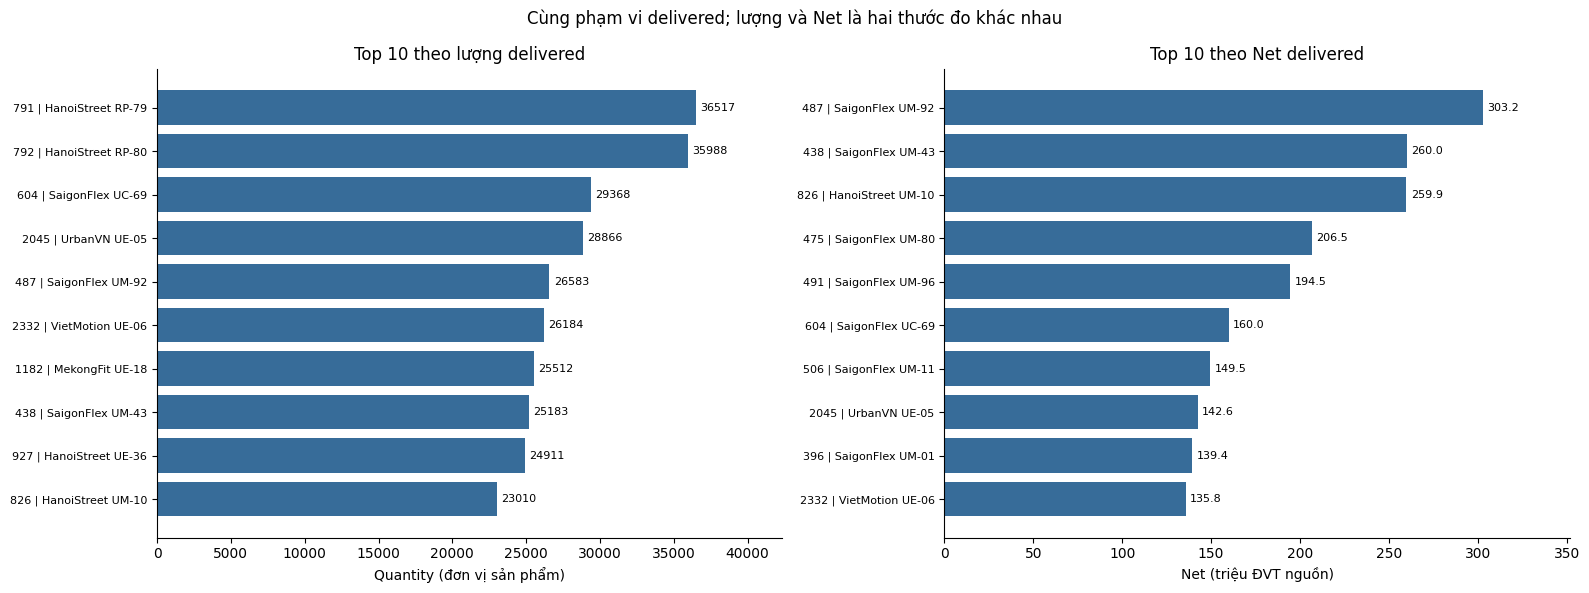

Mã đứng đầu theo lượng là **791**, 36,517 đơn vị; theo Net là **487**, 303,232,685.02 ĐVT. Hai thứ hạng có thể khác do giá/cơ cấu/giảm giá; chưa chứng minh hiệu quả hay lợi nhuận.

In [62]:
p3_cols=['product_id','product_name','category','segment','all_quantity','delivered_quantity',
         'delivered_gross_cents','delivered_discount_cents','delivered_net_cents']
p3_top_quantity=p3_ranked.loc[p3_ranked.delivered_quantity.gt(0),p3_cols].head(10).copy()
p3_top_net=p3_products.loc[p3_products.delivered_quantity.gt(0)].sort_values(
    ['delivered_net_cents','product_id'],ascending=[False,True]).head(10)[p3_cols].copy()
p3_top_net['Net/tổng Net delivered (%)']=100*p3_top_net.delivered_net_cents/p3_s['delivered_net_cents']
p3_show(p3_money_view(p3_top_quantity),'Top 10 theo quantity delivered; cột all_quantity là đối chứng mọi status')
p3_show(p3_money_view(p3_top_net),'Top 10 theo Net delivered, không phải xếp hạng lợi nhuận')
fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax,frame,metric,divisor,title,xlabel in [
    (axes[0],p3_top_quantity,'delivered_quantity',1,'Top 10 theo lượng delivered','Quantity (đơn vị sản phẩm)'),
    (axes[1],p3_top_net,'delivered_net_cents',100000000,'Top 10 theo Net delivered','Net (triệu ĐVT nguồn)')]:
    f=frame.iloc[::-1];labels=f.product_id+' | '+f.product_name
    bars=ax.barh(labels,f[metric]/divisor,color='#376c99')
    ax.bar_label(bars,fmt='%.1f' if divisor>1 else '%.0f',padding=3,fontsize=8)
    ax.set(title=title,xlabel=xlabel);ax.margins(x=.16);ax.tick_params(axis='y',labelsize=8)
fig.suptitle('Cùng phạm vi delivered; lượng và Net là hai thước đo khác nhau',fontsize=12)
fig.tight_layout();display(fig);plt.close(fig)
display(Markdown(f"Mã đứng đầu theo lượng là **{p3_top_quantity.iloc[0].product_id}**, {int(p3_top_quantity.iloc[0].delivered_quantity):,} đơn vị; theo Net là **{p3_top_net.iloc[0].product_id}**, {p3_money(p3_top_net.iloc[0].delivered_net_cents)} ĐVT. Hai thứ hạng có thể khác do giá/cơ cấu/giảm giá; chưa chứng minh hiệu quả hay lợi nhuận."))

### NV01.6.2 — Category/segment: quy mô, cơ cấu và mẫu số bình quân

Kế thừa category và mean/SP từ EDA c65–69; thêm segment và Net từ view GD2. Mean quantity/SP chỉ dùng **số mã có ghi nhận delivered** trong nhóm; hiển thị cả số mã catalogue để tránh hiểu mẫu số là toàn danh mục. Category/segment là thuộc tính catalogue hiện tại, chưa có hiệu lực lịch sử.


**Category: lượng, Gross/Discount/Net và số mã có delivered**

,category,catalog_products,products_with_delivered,delivered_quantity,quantity_share_pct,mean_quantity_per_active_product,all_gross (ĐVT),all_discount (ĐVT),all_net (ĐVT),delivered_gross (ĐVT),delivered_discount (ĐVT),delivered_net (ĐVT),Net/tổng Net delivered (%)
0,Streetwear,1320,867,1413433,55.084628,1630.257209,"13,131,346,352.62","572,869,253.45","12,558,477,099.17","10,488,250,976.54","458,201,496.65","10,030,049,479.89",80.123890
1,Outdoor,743,485,933785,36.391679,1925.329897,"2,494,882,754.20","141,485,957.34","2,353,396,796.86","1,988,549,909.16","112,721,022.45","1,875,828,886.71",14.984842
2,GenZ,148,111,133255,5.193244,1200.495495,"343,599,095.36","14,888,919.71","328,710,175.65","275,026,993.80","11,823,666.92","263,203,326.88",2.102569
3,Casual,201,112,85457,3.330449,763.008929,"460,648,383.35","20,363,189.60","440,285,193.75","365,263,480.91","16,169,217.19","349,094,263.72",2.788699


**Segment: lượng, Gross/Discount/Net và số mã có delivered**

,segment,catalog_products,products_with_delivered,delivered_quantity,quantity_share_pct,mean_quantity_per_active_product,all_gross (ĐVT),all_discount (ĐVT),all_net (ĐVT),delivered_gross (ĐVT),delivered_discount (ĐVT),delivered_net (ĐVT),Net/tổng Net delivered (%)
0,Activewear,598,420,828131,32.274107,1971.740476,"2,047,815,224.18","117,110,249.52","1,930,704,974.66","1,633,559,962.65","93,522,870.11","1,540,037,092.54",12.302408
1,Everyday,405,316,655451,25.544384,2074.212025,"5,376,848,662.27","229,393,745.66","5,147,454,916.61","4,303,947,687.19","183,883,607.17","4,120,064,080.02",32.912655
2,Balanced,306,198,370174,14.426504,1869.565657,"5,127,408,523.48","227,090,557.59","4,900,317,965.89","4,083,722,744.07","181,096,519.38","3,902,626,224.69",31.175678
3,Performance,347,241,348296,13.573870,1445.211618,"2,390,412,021.17","105,382,688.99","2,285,029,332.18","1,910,970,022.98","84,362,443.93","1,826,607,579.05",14.591643
4,Trendy,148,111,133255,5.193244,1200.495495,"343,599,095.36","14,888,919.71","328,710,175.65","275,026,993.80","11,823,666.92","263,203,326.88",2.102569
5,Premium,177,88,110549,4.308340,1256.238636,"480,131,388.39","25,919,487.85","454,211,900.54","380,432,565.20","20,433,651.93","359,998,913.27",2.875810
6,All-weather,169,89,80562,3.139680,905.191011,"427,584,524.98","18,819,409.57","408,765,115.41","339,820,862.22","14,933,717.60","324,887,144.62",2.595323
7,Standard,262,112,39512,1.539871,352.785714,"236,677,145.70","11,002,261.21","225,674,884.49","189,610,522.30","8,858,926.17","180,751,596.13",1.443913


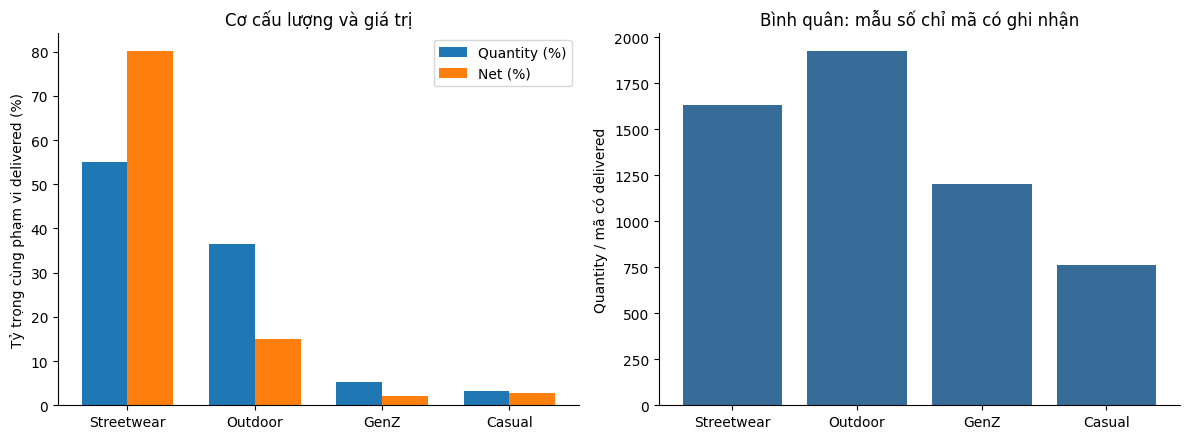

**Streetwear** đóng góp lượng lớn nhất (55.08%), còn **Outdoor** có bình quân lượng/mã có delivered cao nhất (1925.33). Khác mẫu số và cơ cấu không xác nhận năng suất, giá trị vòng đời hay hiệu quả kinh doanh.

In [63]:
for field,name in [('categories','Category'),('segments','Segment')]:
    frame=p3_product[field].copy()
    frame['Net/tổng Net delivered (%)']=100*frame.delivered_net_cents/p3_s['delivered_net_cents']
    p3_show(p3_money_view(frame),name+': lượng, Gross/Discount/Net và số mã có delivered')
    assert int(frame.delivered_quantity.sum())==p3_s['delivered_quantity']
    assert int(frame.delivered_net_cents.sum())==p3_s['delivered_net_cents']
p3_cat=p3_product['categories'].copy()
p3_cat['Net (%)']=100*p3_cat.delivered_net_cents/p3_s['delivered_net_cents']
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
x=range(len(p3_cat));width=.36
axes[0].bar([v-width/2 for v in x],p3_cat.quantity_share_pct,width,label='Quantity (%)')
axes[0].bar([v+width/2 for v in x],p3_cat['Net (%)'],width,label='Net (%)')
axes[0].set(xticks=list(x),xticklabels=p3_cat.category,ylabel='Tỷ trọng cùng phạm vi delivered (%)',title='Cơ cấu lượng và giá trị');axes[0].legend()
axes[1].bar(p3_cat.category,p3_cat.mean_quantity_per_active_product,color='#376c99')
axes[1].set(ylabel='Quantity / mã có delivered',title='Bình quân: mẫu số chỉ mã có ghi nhận')
fig.tight_layout();display(fig);plt.close(fig)
p3_cat_lead=p3_cat.iloc[0]
p3_cat_mean=p3_cat.sort_values('mean_quantity_per_active_product',ascending=False).iloc[0]
display(Markdown(f"**{p3_cat_lead.category}** đóng góp lượng lớn nhất ({p3_cat_lead.quantity_share_pct:.2f}%), còn **{p3_cat_mean.category}** có bình quân lượng/mã có delivered cao nhất ({p3_cat_mean.mean_quantity_per_active_product:.2f}). Khác mẫu số và cơ cấu không xác nhận năng suất, giá trị vòng đời hay hiệu quả kinh doanh."))

### NV01.6.3 — Tập trung 80% lượng: hai mẫu số sản phẩm

Kế thừa EDA c71–72. Sắp lượng giảm dần, giữ mã cắt qua ngưỡng: số mã nhỏ nhất k sao cho tổng quantity top k ≥ 0,8 × tổng quantity delivered. So ngưỡng bằng số nguyên; báo riêng k/catalogue và k/mã có delivered. Đường này mô tả lượng, không phải đường doanh thu hay quy tắc tối ưu danh mục.


**Ngưỡng 80% và hai mẫu số; giữ mã vượt ngưỡng**

,Số mã k,Quantity top k,Tỷ trọng quantity (%),k/catalogue (%),k/mã có delivered (%)
0,296,2052747,80.000117,12.271973,18.793651


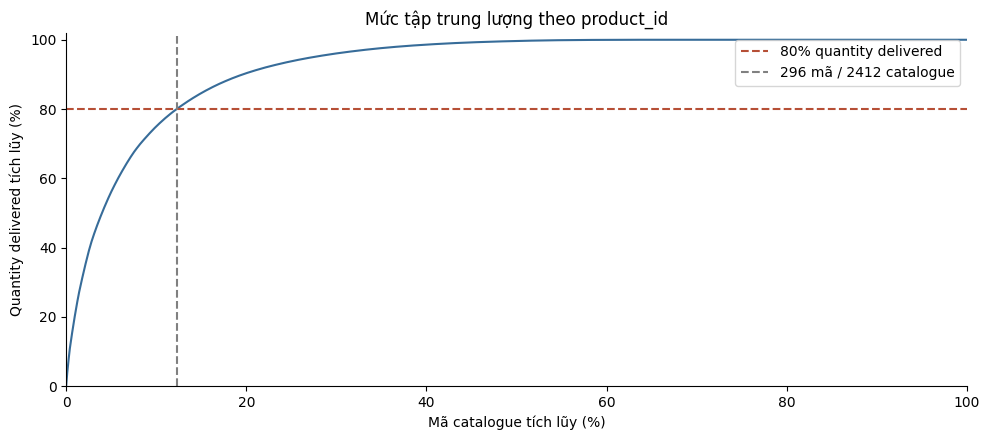

**296 mã** đạt ít nhất 80% lượng delivered: **12.27% catalogue** hoặc **18.79% mã có delivered**. Có **837** mã chưa ghi nhận delivered, gồm 814 mã chưa có dòng đặt và 23 mã có đặt nhưng chưa có delivered. Không suy các mã này kém hiệu quả khi thiếu vòng đời/khả dụng.

In [64]:
p3_k=p3_s['products_for_80']
assert p3_k is not None
p3_qty80=int(p3_ranked.iloc[:p3_k].delivered_quantity.sum())
assert p3_qty80*5>=p3_s['delivered_quantity']*4
assert int(p3_ranked.iloc[:p3_k-1].delivered_quantity.sum())*5<p3_s['delivered_quantity']*4
p3_show(pd.DataFrame([{'Số mã k':p3_k,'Quantity top k':p3_qty80,
 'Tỷ trọng quantity (%)':100*p3_qty80/p3_s['delivered_quantity'],
 'k/catalogue (%)':100*p3_k/p3_s['catalog_products'],
 'k/mã có delivered (%)':100*p3_k/p3_s['delivered_products']}]),'Ngưỡng 80% và hai mẫu số; giữ mã vượt ngưỡng')
fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot([0]+p3_ranked.catalog_pct.tolist(),[0]+p3_ranked.cumulative_quantity_pct.tolist(),color='#376c99')
ax.axhline(80,ls='--',color='#b64f36',label='80% quantity delivered')
ax.axvline(100*p3_k/p3_s['catalog_products'],ls='--',color='grey',label=f'{p3_k} mã / {p3_s["catalog_products"]} catalogue')
ax.set(xlim=(0,100),ylim=(0,102),xlabel='Mã catalogue tích lũy (%)',ylabel='Quantity delivered tích lũy (%)',title='Mức tập trung lượng theo product_id')
ax.legend();fig.tight_layout();display(fig);plt.close(fig)
display(Markdown(f"**{p3_k} mã** đạt ít nhất 80% lượng delivered: **{100*p3_k/p3_s['catalog_products']:.2f}% catalogue** hoặc **{100*p3_k/p3_s['delivered_products']:.2f}% mã có delivered**. Có **{p3_s['without_delivered']}** mã chưa ghi nhận delivered, gồm {p3_s['no_order_products']} mã chưa có dòng đặt và {p3_s['ordered_without_delivered']} mã có đặt nhưng chưa có delivered. Không suy các mã này kém hiệu quả khi thiếu vòng đời/khả dụng."))

### NV01.6.4 — Xu hướng top 5 theo năm đặt hàng

Kế thừa EDA c74–75. Chọn top 5 theo lượng delivered **toàn kỳ**, nên đây là lựa chọn hồi cứu, không là bằng chứng dự báo. Dựng đủ năm trong ledger; năm không có dòng delivered của mã được ghi 0 quantity quan sát, không suy vắng hàng. Đánh dấu **2012 chỉ 04/07–31/12**; không so tổng năm thiếu như tăng trưởng cùng độ phủ.


**Top 5 cố định toàn kỳ; 0 là không có quantity trong ledger quan sát**

product_id,791,792,604,2045,487
Năm order_date,,,,,
2012,0,0,960,554,0
2013,2896,2915,2391,2698,0
2014,9923,9541,5784,3686,0
2015,8632,8494,5921,3982,0
2016,4525,4580,4546,5407,3116
2017,3522,3572,3494,5380,7316
2018,2533,2486,2453,3974,6476
2019,1630,1537,1345,1439,5173
2020,784,770,770,724,3069


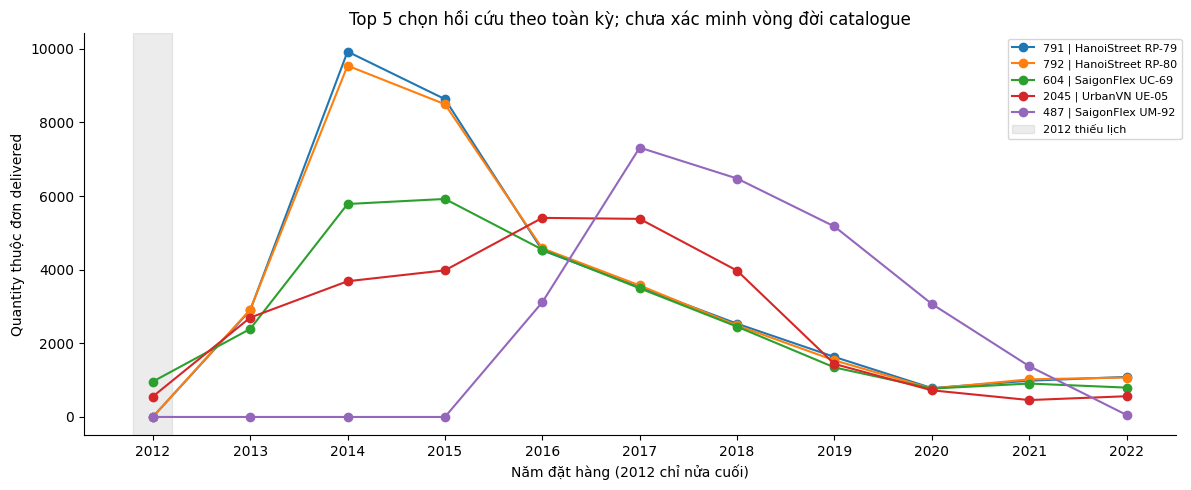

**Kết luận và giới hạn.** Danh mục có mức tập trung lượng cao, và vị trí theo lượng cần đọc cạnh Net cùng phạm vi. Có thể ưu tiên rà khả năng đáp ứng của nhóm đóng góp lớn, nhưng cần thêm độ phủ/vòng đời, giá và hồ sơ kho trước quyết định danh mục/nhập hàng. Không dùng quantity delivered thay inventory.units_sold, Net thay thực thu hoặc lịch sử hồi cứu thay tín hiệu dự báo. Phần này kế thừa ý tưởng sản phẩm của Thu Luyn; bảng tiền/segment và kiểm chứng GD2 do nhóm bổ sung.

STEP3_PRODUCT_SUMMARY {'catalog_products': 2412, 'ordered_products': 1598, 'delivered_products': 1575, 'no_order_products': 814, 'ordered_without_delivered': 23, 'without_delivered': 837, 'item_rows': 714669, 'orders': 646945, 'delivered_orders': 516716, 'products_for_80': 296, 'all_quantity': 3213143, 'all_lines': 714669, 'all_gross_cents': 1643047658553, 'all_discount_cents': 74960732010, 'all_net_cents': 1568086926543, 'delivered_quantity': 2565930, 'delivered_lines': 570887, 'delivered_gross_cents': 1311709136041, 'delivered_discount_cents': 59891540321, 'delivered_net_cents': 1251817595720, 'date_start': '2012-07-04 00:00:00', 'date_end': '2022-12-31 00:00:00'}


In [65]:
p3_top5=p3_top_quantity.head(5).product_id.tolist()
p3_years=list(range(2012,2023))
p3_trend=p3_product['trends'].loc[p3_product['trends'].product_id.isin(p3_top5)]
assert not p3_trend.duplicated(['product_id','year']).any()
p3_panel=p3_trend.pivot(index='year',columns='product_id',values='delivered_quantity').reindex(index=p3_years,columns=p3_top5).fillna(0).astype('int64')
assert all(int(p3_panel[p].sum())==int(p3_products.set_index('product_id').at[p,'delivered_quantity']) for p in p3_top5)
p3_show(p3_panel.rename_axis('Năm order_date'),'Top 5 cố định toàn kỳ; 0 là không có quantity trong ledger quan sát')
fig,ax=plt.subplots(figsize=(12,5))
names=p3_products.set_index('product_id').product_name
for p in p3_top5:ax.plot(p3_years,p3_panel[p],marker='o',label=p+' | '+names[p])
ax.axvspan(2011.8,2012.2,color='grey',alpha=.15,label='2012 thiếu lịch')
ax.set(xticks=p3_years,xlabel='Năm đặt hàng (2012 chỉ nửa cuối)',ylabel='Quantity thuộc đơn delivered',title='Top 5 chọn hồi cứu theo toàn kỳ; chưa xác minh vòng đời catalogue')
ax.legend(fontsize=8,bbox_to_anchor=(1.01,1));fig.tight_layout();display(fig);plt.close(fig)
display(Markdown('**Kết luận và giới hạn.** Danh mục có mức tập trung lượng cao, và vị trí theo lượng cần đọc cạnh Net cùng phạm vi. Có thể ưu tiên rà khả năng đáp ứng của nhóm đóng góp lớn, nhưng cần thêm độ phủ/vòng đời, giá và hồ sơ kho trước quyết định danh mục/nhập hàng. Không dùng quantity delivered thay inventory.units_sold, Net thay thực thu hoặc lịch sử hồi cứu thay tín hiệu dự báo. Phần này kế thừa ý tưởng sản phẩm của Thu Luyn; bảng tiền/segment và kiểm chứng GD2 do nhóm bổ sung.'))
print('STEP3_PRODUCT_SUMMARY '+repr(p3_s))